In [1]:
# %pip install -U numba llvmlite pysheds

## NASIA SUB-BASIN  |  GROUNDWATER POTENTIAL MAPPING

 Hybrid Frequency Ratio - Random Forest (FR-RF), with independent  
 hydraulic validation  
  
 Version 4.6  -  22 November 2026  (rare classes merged, FR smoothing, auto  
                                    lineament window, de-duplicated wells,  
                                    rivers and clear well symbols on maps)  
 Version 4.5  -  22 November 2026  (GIS-style maps, zoned potential map; Nasia_rivers.shp; DEM smoothing, rainfall gap filling,  
                                    pysheds install, clean re-runs)  
  
 WHAT CHANGED FROM VERSION 3  
 A. Boreholes now come from the CLEANED INVENTORY of 220 wells  
    (Nasia_borehole_inventory_clean.csv, built from Appendix 10 and  
    borehole.csv). Its 'Role' column fixes the design:  
       TRAINING   = the 159 wells not in borehole.csv  
       VALIDATION = the 61 fully parameterised (pumping-tested) wells  
    The productive threshold matches borehole.csv: discharge > 10 L/min.  
 B. BLOCK 11B (new): validation repeated on wells >= 1 km from any training  
    well (spatial independence), and at other yield thresholds.  
 C. BLOCK 12 now uses only the 61 validation wells and states that specific  
    capacity and transmissivity are derived from yield, so they are a  
    consistency check, not independent proof.  
 D. BLOCK 13 bootstraps the TRAINING wells and always validates on the same  
    61 wells, instead of redrawing the split.  
 E. BLOCK 14B (new): checks against data the model never used - CMB  
    recharge, regolith thickness, static water level, depth, first strike -  
    and formation in the inventory vs lithology on the map.  
  
 WHAT CHANGED FROM VERSION 2  
 1. The script now BUILDS the conditioning factors itself from your raw  
    data (new BLOCKS A0-A10, which run between BLOCK 1 and BLOCK 2):  
       - lineament density and distance to lineament, from Nasia_Lineaments.shp  
       - streams, drainage density and distance to stream, from the DEM  
       - TWI and TPI, from the DEM  
       - slope, from the DEM  
       - rainfall: every candidate source is tested and the best one chosen  
       - lithology, soil and land use, rasterised / resampled with legends  
 2. Everything is put into ONE coordinate system: WGS 84 / UTM Zone 30N  
    (EPSG:32630), on one 30 m grid. Each input's own CRS is detected and  
    reported; files with no CRS are identified from their coordinates.  
 3. Your actual file names are recognised, including the Google Drive copies  
    with "(2026_02_04 11_34_54 UTC)" in the name. Duplicate copies are  
    compared byte-for-byte and only one is used.  
 4. EVERY block now runs a sanity check on its inputs: is the file relevant  
    (does it cover the basin?) and is it sane (plausible units and values,  
    not flat, not empty, categorical layers really categorical)?  
 5. A picture of every input and every derived factor is written to a  
    final_maps folder that is created automatically.  
 6. BLOCK 19 lists everything that is missing or doubtful - for the  
    analysis AND for the manuscript draft - in one report.  
 7. Built for JupyterLab: maps display inline, and a block that cannot run  
    stops with a clear message instead of a crash or a traceback.  
  
 BLOCKS 2-18 are the version-2 modelling workflow, unchanged in method.  
  
 HOW TO USE THIS SCRIPT  
 1. Put this notebook in your Nasia data folder (or set DATA_DIR in BLOCK 1).  
 2. Run the cells top to bottom (JupyterLab: Run > Run All Cells), or one at  
    a time to read each block's checks as you go.  
 3. Read the ticks and warnings each block prints. BLOCK 19 collects them.  
  
 OUTPUT STRUCTURE  
 <OUTPUT_DIR>/  
     factors/     the 12 conditioning-factor GeoTIFFs (UTM 30N, 30 m)  
     vectors/     the stream network extracted from the DEM (shapefile)  
     final_maps/  
         01_inputs/    a picture of every raw input, in its own CRS  
         02_factors/   a map of every derived conditioning factor  
         03_results/   the model, final potential and uncertainty maps  
     rasters/     model GeoTIFFs (float32, LZW, nodata = -9999)  
     figures/     manuscript figures, PNG at 300 dpi  
     tables/      CSV, plus one combined .xlsx workbook  
     logs/        run_manifest.json and the missing-items report  

## BLOCK 0  |  HOUSEKEEPING

 INPUTS   : none (nothing is read from disk in this block)  
 OUTPUTS  : none yet - folders are created in BLOCK 1  
 RUNTIME  : a few seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Loads the Python libraries and checks none are missing. If one is, you get  
 the exact install command and nothing else runs.  
  
 One library is special: pysheds, which does the flow routing behind the  
 stream network and TWI. If it is missing the script still runs, but those  
 three factors cannot be built and BLOCK 19 will list them as missing.  
 Install it from a notebook cell (this also upgrades numba, which must be  
 0.62 or newer to work with NumPy 2.3):  
       %pip install -U numba llvmlite pysheds  
 then Kernel > Restart Kernel.  
  
 This block also defines the small helpers every later block uses: printing  
 tidy headings, the tick / warning / cross lines of the sanity checks, and  
 drawing a proper map (coordinates, basin outline, north arrow, scale bar).  

In [2]:
import os
import re
import sys
import json
import time
import zipfile
import hashlib
import warnings
import textwrap
import datetime
from pathlib import Path

warnings.filterwarnings("ignore")

_REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "scipy": "scipy", "sklearn": "scikit-learn", "rasterio": "rasterio",
    "geopandas": "geopandas", "shapely": "shapely", "pyproj": "pyproj",
}
_missing = []
for _mod, _pip in _REQUIRED.items():
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pip)

if _missing:
    print("\n" + "!" * 78)
    print("  CANNOT START - required Python libraries are not installed.")
    print("  Missing: " + ", ".join(_missing))
    print("  In the Anaconda Prompt run:")
    print("      conda install -c conda-forge " + " ".join(_missing))
    print("  then restart the kernel and run again.")
    print("!" * 78 + "\n")
    raise SystemExit(1)


def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None and "IPKernelApp" in get_ipython().config
    except Exception:
        return False


IN_NOTEBOOK = _in_notebook()

import numpy as np
import pandas as pd
import matplotlib
if not IN_NOTEBOOK:
    matplotlib.use("Agg")       # terminal run: write figures to file only
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

import rasterio
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.transform import rowcol, from_origin
from rasterio.features import rasterize, geometry_mask
from rasterio.windows import from_bounds as window_from_bounds, Window

import geopandas as gpd
import shapely
from shapely.geometry import Point
from pyproj import CRS

from scipy import stats, ndimage
from scipy.signal import fftconvolve
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV)
from sklearn.metrics import (roc_curve, roc_auc_score, cohen_kappa_score,
                             confusion_matrix, accuracy_score)
from sklearn.inspection import permutation_importance

try:
    import jenkspy
    HAVE_JENKS = True
except ImportError:
    HAVE_JENKS = False

try:
    import openpyxl                                     # noqa: F401
    HAVE_EXCEL = True
except ImportError:
    HAVE_EXCEL = False

if not hasattr(np, "in1d"):          # pysheds still calls np.in1d, removed
    np.in1d = lambda a, b, **k: np.isin(np.ravel(a), b, **k)   # in numpy 2.4
try:
    from pysheds.grid import Grid as _PyshedsGrid
    HAVE_PYSHEDS = True
except Exception:
    HAVE_PYSHEDS = False

_TRAPZ = getattr(np, "trapezoid", None) or np.trapz     # numpy 1.x / 2.x
_WRAP = textwrap.TextWrapper(width=76, initial_indent="  ", subsequent_indent="  ")


# ---- stopping cleanly -------------------------------------------------------
class BlockStopped(Exception):
    """Raised when a block cannot run. Prints a short note, never a traceback."""


def stop():
    raise BlockStopped("This block stopped - read the boxed note above, fix "
                       "it, then re-run from this block.")


if IN_NOTEBOOK:
    from IPython import get_ipython

    def _quiet_stop(shell, etype, evalue, tb, tb_offset=None):
        print(f"\n  >>> {evalue}")
    get_ipython().set_custom_exc((BlockStopped,), _quiet_stop)


# ---- printing ---------------------------------------------------------------
def banner(number, title):
    if "FLAGS" in globals():                 # a re-run replaces old messages
        FLAGS[:] = [f for f in FLAGS if f["Block"] != str(number)]
    print("\n" + "=" * 78)
    print(f"  BLOCK {number}  |  {title.upper()}")
    print("=" * 78)


def io_note(inputs, outputs):
    """Print, at run time, exactly what this block reads and writes."""
    print("  READS :")
    for line in inputs:
        print(f"      {line}")
    print("  WRITES:")
    for line in outputs:
        print(f"      {line}")
    print()


def say(text):
    for para in text.strip().split("\n\n"):
        print(_WRAP.fill(" ".join(para.split())))
        print()


def done(text):
    print("  " + "-" * 74)
    print(_WRAP.fill("DONE. " + " ".join(text.split())))
    print("  " + "-" * 74)


def missing_note(block, product, expected, action):
    """The standard 'I cannot run because something is missing' message."""
    print("\n" + "*" * 78)
    print(f"*  BLOCK {block} CANNOT RUN - A REQUIRED PRODUCT IS MISSING")
    print("*" + "-" * 77)
    print(f"*  Missing product : {product}")
    print(f"*  Expected at     : {expected}")
    print("*  What to do      :")
    for line in textwrap.wrap(action, 68):
        print(f"*      {line}")
    print("*" * 78 + "\n")
    flag(block, f"{product} - {action}", "MISSING")


def skip_note(block, product, expected, consequence):
    """A softer message: the block is optional, so we note it and carry on."""
    print("\n" + "~" * 78)
    print(f"~  BLOCK {block} SKIPPED - AN OPTIONAL PRODUCT WAS NOT SUPPLIED")
    print("~" + "-" * 77)
    print(f"~  Not supplied : {product}")
    print(f"~  Looked for   : {expected}")
    print("~  Consequence  :")
    for line in textwrap.wrap(consequence, 68):
        print(f"~      {line}")
    print("~" * 78 + "\n")
    flag(block, f"{product} not supplied - {consequence}", "MISSING")


def need_file(block, label, path, action):
    if path is not None and Path(path).exists():
        return True
    missing_note(block, label, str(path), action)
    return False


def need_state(block, keys, produced_by):
    absent = [k for k in keys if STATE.get(k) is None]
    if not absent:
        return True
    missing_note(
        block, "in-memory product(s): " + ", ".join(absent),
        f"produced by BLOCK {produced_by}",
        f"Run BLOCK {produced_by} first. If you are running straight through, "
        f"BLOCK {produced_by} stopped early - scroll up and fix the problem it "
        f"reported.")
    return False


# ---- the sanity-check vocabulary used by every block ------------------------
FLAGS = []          # (block, severity, message) - collected for BLOCK 19


def flag(block, message, severity="WARNING"):
    FLAGS.append(dict(Block=str(block), Severity=severity,
                      Message=" ".join(str(message).split())))


def ok(text):
    print(_WRAP.fill("[ OK ]   " + " ".join(text.split())))


def warn(block, text):
    print(_WRAP.fill("[WARN]   " + " ".join(text.split())))
    flag(block, text, "WARNING")


def bad(block, text):
    print(_WRAP.fill("[FAIL]   " + " ".join(text.split())))
    flag(block, text, "PROBLEM")


def note(text):
    print(_WRAP.fill("[note]   " + " ".join(text.split())))


def verdict(block):
    """One-line summary of this block's own checks."""
    mine = [f for f in FLAGS if f["Block"] == str(block)]
    n_p = sum(f["Severity"] == "PROBLEM" for f in mine)
    n_m = sum(f["Severity"] == "MISSING" for f in mine)
    n_w = sum(f["Severity"] == "WARNING" for f in mine)
    if n_p:
        print(f"\n  SANITY VERDICT, BLOCK {block}: {n_p} failed check(s) - see "
              f"the [FAIL] lines above. {n_m} missing item(s), {n_w} warning(s).")
    elif n_m:
        print(f"\n  SANITY VERDICT, BLOCK {block}: usable, but {n_m} item(s) are "
              f"missing (listed again in BLOCK 19); {n_w} warning(s).")
    elif n_w:
        print(f"\n  SANITY VERDICT, BLOCK {block}: usable, with {n_w} "
              f"warning(s) to read.")
    else:
        print(f"\n  SANITY VERDICT, BLOCK {block}: all checks passed.")


def sha1_of(path, nbytes=2_000_000):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        h.update(f.read(nbytes))
    return h.hexdigest()[:12]


def timestamp():
    return datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")


def show_fig(fig):
    """In JupyterLab show the figure under the cell; in a terminal just close."""
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def for_display(a, max_px=1600):
    """Every n-th pixel, for DISPLAY only: a 300 dpi map cannot show more
    detail than this, and plotting 12 million pixels exhausts memory."""
    f = int(np.ceil(max(a.shape) / max_px))
    return a[::f, ::f] if f > 1 else a


STATE = {}
LOG = {"started": timestamp(), "steps": []}


def log_step(name, **kw):
    LOG["steps"].append(dict(step=name, time=timestamp(), **kw))


banner(0, "housekeeping")
io_note(["nothing - this block reads no data"], ["nothing"])
say("""
Loading libraries. Nothing scientific happens here; this block only makes sure
everything the workflow needs is available before any data is touched.
""")
import sklearn
print(f"  Python {sys.version.split()[0]} | numpy {np.__version__} | "
      f"pandas {pd.__version__}")
print(f"  rasterio {rasterio.__version__} | geopandas {gpd.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print(f"  Running inside JupyterLab : {'yes - maps will show under each cell' if IN_NOTEBOOK else 'no - maps go to files only'}")
print(f"  Flow routing (pysheds)    : {'available' if HAVE_PYSHEDS else 'NOT INSTALLED - streams, drainage density, distance to stream and TWI cannot be built'}")
print(f"  Natural breaks (jenkspy)  : {'available' if HAVE_JENKS else 'not installed - quantile breaks will be used'}")
print(f"  Excel export (openpyxl)   : {'available' if HAVE_EXCEL else 'not installed - tables will be CSV only'}")
print()
if not HAVE_PYSHEDS:
    flag(0, "pysheds is not installed, so the stream network, drainage density, "
            "distance to stream and TWI cannot be derived from the DEM. In the "
            "notebook cell run: %pip install -U numba llvmlite pysheds, "
            "then restart the kernel",
         "MISSING")
done("Libraries checked and helper functions defined.")


  BLOCK 0  |  HOUSEKEEPING
  READS :
      nothing - this block reads no data
  WRITES:
      nothing

  Loading libraries. Nothing scientific happens here; this block only makes
  sure everything the workflow needs is available before any data is
  touched.

  Python 3.13.5 | numpy 2.3.5 | pandas 2.2.3
  rasterio 1.4.3 | geopandas 1.1.1 | scikit-learn 1.6.1
  Running inside JupyterLab : yes - maps will show under each cell
  Flow routing (pysheds)    : available
  Natural breaks (jenkspy)  : not installed - quantile breaks will be used
  Excel export (openpyxl)   : available

  --------------------------------------------------------------------------
  DONE. Libraries checked and helper functions defined.
  --------------------------------------------------------------------------


## BLOCK 1  |  YOUR INPUTS - THE ONLY BLOCK YOU EDIT

 INPUTS   : your typing. Nothing is read from disk yet.  
 OUTPUTS  : the output folders, created automatically  
 RUNTIME  : instant  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 This is the control panel. In most cases you change ONE line: DATA_DIR,  
 the folder holding your Nasia files. Everything else is already set to the  
 file names in your folder and the values in the manuscript.  
  
 File names are typed WITHOUT the Google Drive suffix: write "Soil.tif" and  
 the script will also find "Soil (2026_02_04 11_34_54 UTC).tif". Where a  
 line lists several files, they are CANDIDATES - the script tests each and  
 picks the best, telling you why.  
  
 The 12 conditioning factors keep the names used in the conditioning-factor  
 recommendation and in version 2 (Lithology, LineamentDens, DistLineament,  
 Elevation, Slope, TWI, TPI, DrainageDens, DistStream, Rainfall, SoilType,  
 LULC). BLOCKS A4-A10 write them into OUTPUT_DIR/factors under the file names  
 given in section (e); BLOCK 2 onward reads them from there.  

In [37]:
banner(1, "your inputs - the only block you edit")

# -----------------------------------------------------------------------------
# (a) FOLDERS
#     "." means "the folder this notebook is in". On Windows you can paste a
#     full path, e.g.  r"C:\Users\elikplim\Documents\Nasia"
# -----------------------------------------------------------------------------
DATA_DIR   = r"D:\Nasia_Manuscript\November_2026"
OUTPUT_DIR = r"D:\Nasia_Manuscript\November_2026/Nasia_outputs_v4"

# -----------------------------------------------------------------------------
# (b) RAW INPUT FILES IN DATA_DIR  (names as in your folder, without the
#     "(2026_02_04 ... UTC)" suffix - the script finds those copies itself)
# -----------------------------------------------------------------------------
RAW = dict(
    basin       = "Nas_ia.shp",                       # sub-basin outline
    dem         = ["Nasia_DEM.tif", "NasiaDEM_1.tif"],  # candidates; best chosen
    lineaments  = "Nasia_Lineaments.shp",
    streams     = "Nasia_rivers.shp",   # mapped river network (BLOCK A5)
    geology     = ["Nasia_Geology.shp", "Nasia_Geology.tif"],
    soil        = ["Soil.tif", "Nasia_soils_PolygonToRaster.tif"],
    lulc        = ["LULC.tif", "landuse.tif"],   # LULC.tif = a georeferenced
                                                 # Esri 10 m land cover, if added
    rainfall    = ["Annual_Rainfall.tif", "Nasia_annual_precipitation.tif",
                   "Rainfall.shp", "Meteo_Stations.shp",
                   "Nasia_annual_precipitation.shp"],
    old_slope   = "Nasia_Slope.tif",          # 2022 layers: compared, not used
    old_drainage_density = "Drainage_Density.tif",
    boreholes   = "Nasia_borehole_inventory_clean.csv",   # 220 wells, Role column
    hydraulics  = "Nasia_borehole_inventory_clean.csv",   # BLOCK 12 uses its 61
                                                           # validation wells
    recharge    = "Nasia_CMB_recharge.csv",               # BLOCK 14B
    manuscript  = "Manuscript_Draft_editing.docx",
)

# -----------------------------------------------------------------------------
# (c) HOW THE FACTORS ARE BUILT (BLOCKS A2-A9)
# -----------------------------------------------------------------------------
TARGET_CRS   = "EPSG:32630"   # WGS 84 / UTM Zone 30N - every layer ends here
PIXEL_M      = 30             # grid cell size, metres
GRID_BUFFER_M = 3000          # grid extends this far beyond the basin so that
                              # distances, densities and flow routing are not
                              # distorted at the basin edge

DEM_CHOICE   = "auto"         # "auto", or a file name from RAW["dem"]
DEM_SMOOTH_SIGMA_PX = "auto"  # Gaussian smoothing of the DEM before slope, TPI,
                              # TWI and streams. "auto" = 2.5 pixels (75 m) when
                              # heights are whole metres (SRTM-type int16), else 0.
                              # The Elevation factor itself is never smoothed.
RAINFALL_CHOICE = "auto"      # "auto", or a file name from RAW["rainfall"]
RAIN_MIN_RANGE_MM = 50        # a rainfall surface varying less than this
                              # across the basin is flagged as "flat"

STREAMS_SOURCE = "auto"       # which network gives drainage density and
                              # distance to stream:
                              #  "auto"      = DEM channels when pysheds works,
                              #                else Nasia_rivers.shp
                              #  "shapefile" = always Nasia_rivers.shp
                              #  "dem"       = always the DEM channels
STREAM_THRESHOLD_KM2 = 1.0    # upstream area that starts a stream channel
DRAINAGE_RADIUS_M    = 1000   # moving-window radius for drainage density
LINEAMENT_RADIUS_M   = "auto" # moving-window radius for lineament density.
                              # "auto" = the distance within which 70% of the
                              # basin lies from a lineament (rounded up to 250 m),
                              # so the density is not zero over most of the basin
TPI_RADIUS_M         = 300    # neighbourhood radius for TPI
CATEGORICAL_CHOICE = dict(soil="auto", lulc="auto")   # or a file name, e.g.
                              # dict(soil="Soil.tif", lulc="LULC.tif")

# The final potential map is also drawn as GENERALISED ZONES for reading:
ZONE_SMOOTH_M     = 500       # potential averaged over this radius first
ZONE_MIN_AREA_KM2 = 1.0       # patches smaller than this merge into neighbours
                              # (the analysis always uses the 30 m pixels)

# Class names for the categorical maps. The script reads them from the
# raster attribute tables (.vat.dbf) and the geology shapefile; anything typed
# here is added on top, or overrides. Use it when a table holds only codes.
CLASS_NAMES = dict(
    Lithology = {},   # e.g. {1: "Bimbilla", 2: "Panabako Sandstone"}
    SoilType  = {},   # e.g. {1: "Luvisols", 2: "Lixisols", 3: "Plinthosols"}
    LULC      = {},   # e.g. {1: "Savannah woodland", 2: "Grassland", 3: "Cropland"}
)

GEOLOGY_FIELD = "auto"        # attribute holding the formation name in
                              # Nasia_Geology.shp; "auto" picks the most likely
                              # text field and lists all fields so you can check
GEOLOGY_RENAME = {"Damongo Formation": "Poubogou Formation"}
                              # corrections to formation names in the geology
                              # map: there is no Damongo Formation in the Nasia
                              # sub-basin; that polygon is Poubogou
BASIN_AREA_KM2 = 5400         # stated area, used only as a sanity check

# Plausible values for the Nasia sub-basin - used by the sanity checks
EXPECT = dict(
    Elevation=(50, 800), Slope=(0, 60), TWI=(0, 30), TPI=(-150, 150),
    DrainageDens=(0, 6), DistStream=(0, 15000), LineamentDens=(0, 10),
    DistLineament=(0, 30000), Rainfall=(500, 2000),
    yield_m3h=(0, 60), borehole_count=220,
)

# -----------------------------------------------------------------------------
# (d) BOREHOLE INVENTORY  ("auto" = the script recognises the column)
# -----------------------------------------------------------------------------
COL_X      = "Easting"
COL_Y      = "Northing"
COL_YIELD  = "Discharge(l/min)"
COL_ID     = "BH ID"
COL_SUBSET = "Role"           # 'training' / 'validation', set in the clean
                              # inventory; None = draw a random split instead
YIELD_IS_LPM = True           # the inventory's yield is in litres/minute
BOREHOLE_CRS = "EPSG:32630"   # the inventory is in UTM 30N metres

# -----------------------------------------------------------------------------
# (e) CONDITIONING FACTORS - built by BLOCKS A4-A9 into OUTPUT_DIR/factors.
#     Set a file to None to drop that factor from the model (e.g. for the
#     robustness run without collinear terrain indices).
# -----------------------------------------------------------------------------
FACTORS = {
    # ---- GEOLOGICAL / STRUCTURAL --------------------------------------------
    "Lithology": dict(
        file="lithology.tif", kind="categorical", n_classes=None,
        units="integer class codes", valid=(0, 200),
        source="Nasia_Geology.shp rasterised at 30 m by formation (BLOCK A8)"),
    "LineamentDens": dict(
        file="lineament_density.tif", kind="continuous", n_classes=5,
        units="km per km2", valid=(0, 20),
        source="Nasia_Lineaments.shp; line density in a circular moving "
               "window (radius set in BLOCK A7)"),
    "DistLineament": dict(
        file="distance_to_lineament.tif", kind="continuous", n_classes=5,
        units="metres", valid=(0, 50000),
        source="Euclidean distance to the nearest lineament, no search-radius "
               "cap (BLOCK A6)"),
    # ---- TOPOGRAPHIC --------------------------------------------------------
    "Elevation": dict(
        file="elevation.tif", kind="continuous", n_classes=5,
        units="metres above sea level", valid=(0, 1000),
        source="DEM chosen in BLOCK A3"),
    "Slope": dict(
        file="slope.tif", kind="continuous", n_classes=5,
        units="DEGREES (not percent, not radians)", valid=(0, 90),
        source="Derived from the DEM (BLOCK A3)"),
    "TWI": dict(
        file="twi.tif", kind="continuous", n_classes=5,
        units="dimensionless, ln(a/tan B)", valid=(-5, 35),
        source="D8 flow accumulation on the filled DEM (BLOCK A4)"),
    "TPI": dict(
        file="tpi.tif", kind="continuous", n_classes=5,
        units="metres (cell elevation minus mean of neighbours)", valid=(-200, 200),
        source=f"DEM, {TPI_RADIUS_M} m radius neighbourhood (BLOCK A5)"),
    # ---- HYDROLOGICAL -------------------------------------------------------
    "DrainageDens": dict(          # OFF: r = -0.76 with DistStream at the wells
        file=None, kind="continuous", n_classes=5,   # "drainage_density.tif" to restore
        units="km per km2", valid=(0, 20),
        source=f"DEM-derived streams, {DRAINAGE_RADIUS_M} m radius window (BLOCK A4)"),
    "DistStream": dict(
        file="distance_to_stream.tif", kind="continuous", n_classes=5,
        units="metres", valid=(0, 50000),
        source="Euclidean distance to the nearest DEM-derived stream (BLOCK A4)"),
    # ---- CLIMATE ------------------------------------------------------------
    "Rainfall": dict(
        file="rainfall.tif", kind="continuous", n_classes=5,
        units="mm per year", valid=(200, 3000),
        source="Best of the rainfall candidates, chosen in BLOCK A7"),
    # ---- SOIL AND SURFACE ---------------------------------------------------
    "SoilType": dict(
        file="soil_type.tif", kind="categorical", n_classes=None,
        units="integer class codes", valid=(0, 200),
        source="Soil raster chosen in BLOCK A8"),
    "LULC": dict(
        file="lulc.tif", kind="categorical", n_classes=None,
        units="integer class codes", valid=(0, 200),
        source="landuse.tif (BLOCK A8). State acquisition date and accuracy."),
    # ---- SCREENED OUT (see the conditioning-factor recommendation) ----------
    "NDVI":   dict(file=None, kind="continuous", n_classes=5,
                   units="dimensionless, -1 to +1", valid=(-1, 1),
                   source="Not in the folder; duplicates LULC"),
    "Aspect": dict(file=None, kind="categorical", n_classes=None,
                   units="degrees", valid=(-1, 360), source="Screened out"),
    "TRI":    dict(file=None, kind="continuous", n_classes=5, units="metres",
                   valid=(0, 500), source="Screened out: collinear with slope"),
    "SPI":    dict(file=None, kind="continuous", n_classes=5,
                   units="dimensionless", valid=(0, 1e7),
                   source="Screened out: collinear with TWI"),
}
REFERENCE_FACTOR = "Elevation"

# -----------------------------------------------------------------------------
# (f) INDEPENDENT HYDRAULIC VALIDATION DATA (BLOCK 12)
# -----------------------------------------------------------------------------
HYD_COL_X = "Easting"
HYD_COL_Y = "Northing"
HYD_COL_T  = "T_formation_specific_m2d"   # m2/day (SC-derived)
HYD_COL_SC = "Specific Capacity (m3/d/m)"  # m2/day
HYD_COL_K  = None                         # not available
HYD_ROLE   = "validation"   # BLOCK 12 uses only these wells of the file
HYD_RASTER_T  = None
HYD_RASTER_SC = None
HYD_LOG_TRANSFORM = True

# -----------------------------------------------------------------------------
# ANALYSIS SETTINGS - manuscript values already entered
# -----------------------------------------------------------------------------
YIELD_THRESHOLD   = 0.6      # m3/h (= 10 L/min)
YIELD_STRICT      = True     # True: productive means ABOVE the threshold, as in
                             # borehole.csv (10 L/min is class 0)
THRESHOLD_SENSITIVITY_LPM = [13, 22]   # BLOCK 11B: hand-pump minimum, median
SPATIAL_BUFFER_M  = 1000     # BLOCK 11B: validation wells this far from training
N_TRAIN           = 159        # set by the Role column
N_VALID           = 61
RANDOM_SEED       = 42

RF_N_TREES        = 500
RF_TUNE           = True
RF_TUNE_ITER      = 40

N_BOOTSTRAP       = 50
N_AUC_BOOTSTRAP   = 2000

GPI_CLASSES       = 5
GPI_CLASS_METHOD  = "jenks"
CLASSIFY_METHOD   = "quantile"

VIF_WARNING_LEVEL = 5.0
MIN_CLASS_AREA_PCT = 1.0     # categorical classes smaller than this share of
                             # the basin are merged into one "Other" class
                             # before the Frequency Ratio (a class of 0.01% of
                             # the basin with one well gives an FR in the
                             # thousands and dominates the FR map)
FR_PRIOR_WELLS = 1.0         # Frequency Ratio smoothing: each class starts with
                             # this many "virtual" wells spread in proportion to
                             # its area, so an empty class gets a small FR
                             # rather than zero, and a tiny class cannot explode
DROP_OUTSIDE_BASIN = True    # wells outside the Nasia outline are not modelled
DEDUP_SAME_PIXEL   = True    # two wells on one 30 m pixel count once
RECHARGE_MAX_PCT   = 50      # BLOCK 14B: chloride recharge above this % of
                             # rainfall is treated as implausible and excluded
MAX_FACTORS_ADVICE = 12

FAST_MODE = False             # True = quick first pass (15 bootstrap reps).
                             # Set False for the run whose numbers go in the
                             # paper.

# -----------------------------------------------------------------------------
# Nothing below this line needs editing.
# -----------------------------------------------------------------------------

if FAST_MODE:
    N_BOOTSTRAP, RF_TUNE_ITER, N_AUC_BOOTSTRAP = 15, 12, 500

DATA_DIR   = Path(DATA_DIR).expanduser().resolve()
if not DATA_DIR.exists():
    missing_note(1, "the data folder", str(DATA_DIR),
                 "Set DATA_DIR at the top of this block to the folder that "
                 "holds Nas_ia.shp, Nasia_DEM.tif, borehole.csv and the rest.")
    stop()
OUTPUT_DIR = Path(OUTPUT_DIR).expanduser()
if not OUTPUT_DIR.is_absolute():          # relative = inside the data folder
    OUTPUT_DIR = DATA_DIR / OUTPUT_DIR
OUTPUT_DIR = OUTPUT_DIR.resolve()
DIR_RAS, DIR_FIG = OUTPUT_DIR / "rasters", OUTPUT_DIR / "figures"
DIR_TAB, DIR_LOG = OUTPUT_DIR / "tables", OUTPUT_DIR / "logs"
DIR_FAC, DIR_VEC = OUTPUT_DIR / "factors", OUTPUT_DIR / "vectors"
DIR_MAPS = OUTPUT_DIR / "final_maps"
DIR_MAP_IN, DIR_MAP_FAC, DIR_MAP_RES = (DIR_MAPS / "01_inputs",
                                        DIR_MAPS / "02_factors",
                                        DIR_MAPS / "03_results")
for d in (OUTPUT_DIR, DIR_RAS, DIR_FIG, DIR_TAB, DIR_LOG, DIR_FAC, DIR_VEC,
          DIR_MAPS, DIR_MAP_IN, DIR_MAP_FAC, DIR_MAP_RES):
    d.mkdir(parents=True, exist_ok=True)


def resolve_factor_paths():
    """Factors live in OUTPUT_DIR/factors unless a full path was typed."""
    global FACTORS, FACTOR_NAMES, _dropped
    for k, v in FACTORS.items():
        if v.get("file"):
            p = Path(v["file"])
            v["path"] = p if p.is_absolute() else DIR_FAC / v["file"]
    _dropped = [k for k, v in FACTORS.items() if not v.get("file")]
    FACTOR_NAMES = [k for k, v in FACTORS.items() if v.get("file")]


ALL_FACTORS = FACTORS                     # kept whole; switched-off ones too
resolve_factor_paths()
np.random.seed(RANDOM_SEED)

io_note(["your typing in this block"],
        [f"output folders under {OUTPUT_DIR}"])

say(f"""
Configuration read. {len(FACTOR_NAMES)} conditioning factors will be built and
modelled, on a {PIXEL_M} m grid in {CRS.from_user_input(TARGET_CRS).name}, with a
yield threshold of {YIELD_THRESHOLD} m3/h and a {N_TRAIN}/{N_VALID} split.

Data folder  : {DATA_DIR}
Output folder: {OUTPUT_DIR}
Final maps   : {DIR_MAPS}
""")
print("  Conditioning factors switched ON:")
for k in FACTOR_NAMES:
    v = FACTORS[k]
    print(f"    {k:<15s} {v['kind']:<12s} {v['units']:<42s} {v['file']}")
if _dropped:
    print("\n  Switched OFF: " + ", ".join(_dropped))
print()
if FAST_MODE:
    note("FAST_MODE is True: a quick first pass. Set it to False for the run "
         "whose numbers go into the manuscript.")

log_step("config", n_factors=len(FACTOR_NAMES), seed=RANDOM_SEED,
         threshold=YIELD_THRESHOLD, fast=FAST_MODE, crs=TARGET_CRS, pixel=PIXEL_M)
done("Settings loaded and output folders created. No data has been read yet.")


  BLOCK 1  |  YOUR INPUTS - THE ONLY BLOCK YOU EDIT
  READS :
      your typing in this block
  WRITES:
      output folders under D:\Nasia_Manuscript\November_2026\Nasia_outputs_v4

  Configuration read. 11 conditioning factors will be built and modelled, on
  a 30 m grid in WGS 84 / UTM zone 30N, with a yield threshold of 0.6 m3/h
  and a 159/61 split.

  Data folder : D:\Nasia_Manuscript\November_2026 Output folder:
  D:\Nasia_Manuscript\November_2026\Nasia_outputs_v4 Final maps :
  D:\Nasia_Manuscript\November_2026\Nasia_outputs_v4\final_maps

  Conditioning factors switched ON:
    Lithology       categorical  integer class codes                        lithology.tif
    LineamentDens   continuous   km per km2                                 lineament_density.tif
    DistLineament   continuous   metres                                     distance_to_lineament.tif
    Elevation       continuous   metres above sea level                     elevation.tif
    Slope           continuou

## BLOCK A0  |  TOOLBOX FOR BUILDING THE FACTORS

 INPUTS   : none  
 OUTPUTS  : none - this block only defines tools used by BLOCKS A1-A10  
 RUNTIME  : instant  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Defines the handful of operations every factor-building block relies on:  
  
  - FINDING a file even when Google Drive has added "(2026_02_04 ... UTC)"  
    to its name, and checking whether two such copies are really identical;  
  - WORKING OUT THE CRS of a file. If the file says what it is, that is  
    used. If it says nothing (common when the .prj or .aux.xml was renamed  
    separately), the CRS is inferred from the coordinates themselves:  
    numbers between -180 and 180 are longitude/latitude (WGS 84); numbers in  
    the hundreds of thousands and around a million are UTM metres. Any CRS  
    that had to be inferred is reported, so nothing is assumed silently;  
  - REPROJECTING any raster onto the one master grid (UTM 30N, 30 m),  
    reading only the part that covers the basin, so the 327 MB rainfall  
    file does not have to be loaded whole;  
  - MOVING-WINDOW sums and means (for densities and TPI);  
  - DRAWING a map with UTM coordinates in km, the basin outline, a north  
    arrow and a 10 km scale bar.  

In [4]:
banner("A0", "toolbox for building the factors")
io_note(["nothing"], ["nothing - tools only"])

_UTC = r"(?:\s*\(\d{4}_\d{2}_\d{2} \d{2}_\d{2}_\d{2} UTC\))?"
GHANA_LONLAT = (-3.4, 4.5, 1.3, 11.3)          # rough bounding box of Ghana
UNUSED_GHANA_GRIDS = {2136, 2137, 25000, 4168}  # Accra / Leigon datums


def find_copies(name):
    """Every file in DATA_DIR that is `name`, with or without the UTC suffix."""
    stem, ext = os.path.splitext(name)
    rx = re.compile(rf"^{re.escape(stem)}{_UTC}{re.escape(ext)}$", re.I)
    return sorted(p for p in DATA_DIR.iterdir() if p.is_file() and rx.match(p.name))


def _is_text(series):
    return pd.api.types.is_string_dtype(series) or series.dtype == object


def _fingerprint(p):
    parts = [p] + ([p.with_suffix(".dbf")] if p.suffix.lower() == ".shp" else [])
    return tuple((q.stat().st_size, sha1_of(q)) for q in parts if q.exists())


def locate(block, name, label=None):
    """Find one usable copy of `name`. Reports duplicates and broken shapefiles."""
    label = label or name
    copies = find_copies(name)
    if not copies:
        return None
    if Path(name).suffix.lower() == ".shp":
        whole = [p for p in copies
                 if all(Path(str(p.with_suffix("")) + s_).exists() for s_ in (".shx", ".dbf"))]
        if whole and len(whole) < len(copies):
            for p in copies:
                if p not in whole:
                    note(f"{label}: '{p.name}' lacks its .shx or .dbf and is ignored.")
            copies = whole
    chosen = copies[0]
    if len(copies) > 1:
        fps = {p: _fingerprint(p) for p in copies}
        if len(set(fps.values())) == 1:
            ok(f"{label}: {len(copies)} copies found, identical byte for byte - "
               f"using '{chosen.name}'.")
        else:
            chosen = max(copies, key=lambda p: p.stat().st_mtime)
            warn(block, f"{label}: {len(copies)} copies found and they DIFFER. "
                        f"Using the most recently modified, '{chosen.name}'. "
                        f"Check this is the version you intend.")
    if chosen.suffix.lower() == ".shp":
        base = chosen.with_suffix("")
        for side in (".shx", ".dbf"):
            if not Path(str(base) + side).exists():
                bad(block, f"{label}: the shapefile part '{base.name}{side}' is "
                           f"missing, so the shapefile cannot be read.")
                return None
        if not Path(str(base) + ".prj").exists():
            warn(block, f"{label}: no .prj file, so the shapefile does not state "
                        f"its CRS. It will be inferred from the coordinates.")
    return chosen


def guess_crs(bounds):
    xmin, ymin, xmax, ymax = bounds
    if -180 <= xmin <= xmax <= 180 and -90 <= ymin <= ymax <= 90:
        return CRS.from_epsg(4326)
    if 100_000 <= xmin <= xmax <= 900_000 and 0 <= ymin <= ymax <= 2_000_000:
        return CRS.from_epsg(32630)
    return None


def crs_label(crs):
    if crs is None:
        return "NONE"
    c = CRS.from_user_input(crs)
    epsg = c.to_epsg()
    return f"{c.name}" + (f" (EPSG:{epsg})" if epsg else "")


def check_crs(block, label, crs, assumed):
    if assumed:
        warn(block, f"{label}: the file carries no CRS. From its coordinates it "
                    f"was taken to be {crs_label(crs)}. Confirm this.")
        return
    c = CRS.from_user_input(crs)
    epsg = c.to_epsg()
    if epsg == 32630:
        ok(f"{label}: already in {crs_label(c)}.")
    elif epsg == 4326:
        ok(f"{label}: in {crs_label(c)} (geographic). It will be projected to "
           f"UTM 30N.")
    elif epsg in UNUSED_GHANA_GRIDS:
        warn(block, f"{label}: in a Ghana national grid / Accra datum "
                    f"({crs_label(c)}). Reprojection works, but the datum shift "
                    f"to WGS 84 depends on the transformation pyproj finds - "
                    f"check the layer lines up with the others in its map.")
    else:
        ok(f"{label}: in {crs_label(c)}; it will be reprojected to UTM 30N.")


def native_res_m(transform, crs):
    c = CRS.from_user_input(crs)
    if c.is_geographic:
        return abs(transform.a) * 111_320 * np.cos(np.radians(10.4))
    factor = getattr(c.axis_info[0], "unit_conversion_factor", 1.0) if c.axis_info else 1.0
    return abs(transform.a) * (factor or 1.0)


def read_vector(block, path, label):
    """Read a vector file, establish its CRS, return (in TARGET_CRS, info)."""
    g = gpd.read_file(path)
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    assumed = False
    if g.crs is None:
        crs = guess_crs(g.total_bounds) if len(g) else None
        if crs is None:
            bad(block, f"{label}: no CRS, and the coordinates "
                       f"{np.round(g.total_bounds, 1)} do not look like "
                       f"longitude/latitude or UTM. It cannot be placed on the map.")
            return None, None
        g = g.set_crs(crs)
        assumed = True
    native = g.crs
    check_crs(block, label, native, assumed)
    info = dict(crs=crs_label(native), assumed=assumed, n=len(g),
                types=sorted(g.geom_type.unique().tolist()))
    return g.to_crs(TARGET_CRS), info


_SENTINELS = (-9999.0, -32768.0, -32767.0, -99999.0)


def warp_to_grid(block, path, label, categorical=False):
    """
    Reproject one band onto the master grid. Returns (array, info) with NaN
    for no-data. Reads only the window that covers the basin grid.
    """
    with rasterio.open(path) as src:
        crs, assumed = src.crs, False
        if crs is None:
            crs = guess_crs(tuple(src.bounds))
            assumed = True
            if crs is None:
                bad(block, f"{label}: no CRS and coordinates "
                           f"{np.round(tuple(src.bounds), 1)} are not recognisable.")
                return None, None
        info = dict(file=Path(path).name, crs=crs_label(crs), assumed=assumed,
                    native_m=round(native_res_m(src.transform, crs), 1),
                    dtype=src.dtypes[0], nodata=src.nodata,
                    size=f"{src.width} x {src.height}",
                    modified=datetime.datetime.fromtimestamp(
                        Path(path).stat().st_mtime).strftime("%Y-%m-%d"))
        gb = transform_bounds(TARGET_CRS, crs, *GRID_BOUNDS, densify_pts=21)
        w = window_from_bounds(*gb, transform=src.transform)
        c0 = max(int(np.floor(w.col_off)) - 2, 0)
        r0 = max(int(np.floor(w.row_off)) - 2, 0)
        c1 = min(int(np.ceil(w.col_off + w.width)) + 2, src.width)
        r1 = min(int(np.ceil(w.row_off + w.height)) + 2, src.height)
        if c1 <= c0 or r1 <= r0:
            bad(block, f"{label}: the raster does not overlap the Nasia basin at "
                       f"all (after reading it as {crs_label(crs)}).")
            return None, info
        win = Window(c0, r0, c1 - c0, r1 - r0)
        a = src.read(1, window=win).astype("float64")
        tr = src.window_transform(win)
        if src.nodata is not None and np.isfinite(src.nodata):
            a[a == src.nodata] = np.nan
        elif src.nodata is not None:
            a[~np.isfinite(a)] = np.nan
        else:
            sent = np.isin(a, _SENTINELS) | (a < -1e30) | (a > 1e30)
            if sent.any():
                warn(block, f"{label}: no no-data value in the file header; "
                            f"{int(sent.sum()):,} pixels holding a typical "
                            f"no-data code were treated as no-data.")
                a[sent] = np.nan
    if assumed:
        check_crs(block, label, crs, True)
    out = np.full(GRID_SHAPE, np.nan, dtype="float32")
    reproject(a.astype("float32"), out, src_transform=tr, src_crs=crs,
              dst_transform=GRID_T, dst_crs=TARGET_CRS, src_nodata=np.nan,
              dst_nodata=np.nan,
              resampling=Resampling.nearest if categorical else Resampling.bilinear)
    return out, info


def disk(radius_cells, exclude_centre=False):
    r = int(max(1, round(radius_cells)))
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    k = (x * x + y * y <= r * r).astype("float64")
    if exclude_centre:
        k[r, r] = 0.0
    return k


def focal_sum(arr, radius_m):
    k = disk(radius_m / PIXEL_M)
    out = fftconvolve(np.nan_to_num(arr), k, mode="same")
    out[out < 1e-6] = 0.0                     # remove FFT round-off
    return out, k.sum()


def focal_mean(arr, radius_m, exclude_centre=False):
    k = disk(radius_m / PIXEL_M, exclude_centre)
    valid_ = np.isfinite(arr).astype("float64")
    num = fftconvolve(np.where(np.isfinite(arr), arr, 0.0), k, mode="same")
    den = fftconvolve(valid_, k, mode="same")
    out = np.where(den > 0.5, num / np.maximum(den, 1e-9), np.nan)
    out[~np.isfinite(arr)] = np.nan
    return out


def basin_values(arr):
    v = arr[BASIN_MASK]
    return v[np.isfinite(v)]


def check_layer(block, name, arr, units, expect=None, kind="continuous",
                min_cover=99.0):
    """
    The standard sanity check for a layer on the master grid. Tests coverage of
    the basin, plausible range, that a continuous layer is not flat, and that a
    categorical layer really holds a few integer codes. Returns a stats dict.
    """
    v = basin_values(arr)
    n_in = int(BASIN_MASK.sum())
    cover = 100.0 * v.size / max(n_in, 1)
    s = dict(Factor=name, Units=units, Coverage_pct=round(cover, 2))
    if v.size == 0:
        bad(block, f"{name}: no valid values inside the basin.")
        return s
    s.update(Min=float(v.min()), P5=float(np.percentile(v, 5)),
             Median=float(np.median(v)), P95=float(np.percentile(v, 95)),
             Max=float(v.max()), Distinct=int(np.unique(v[:2_000_000]).size))
    if cover < min_cover:
        (bad if cover < 90 else warn)(
            block, f"{name}: covers only {cover:.1f}% of the basin - the rest "
                   f"would be dropped from the whole analysis.")
    else:
        ok(f"{name}: covers {cover:.1f}% of the basin.")
    if kind == "categorical":
        nonint = np.mean(np.abs(v - np.round(v)) > 1e-6)
        if nonint > 0.001:
            bad(block, f"{name}: {100*nonint:.1f}% of pixels are not whole "
                       f"numbers - a categorical map has been smoothed "
                       f"(bilinear) somewhere upstream. Re-make it with nearest "
                       f"neighbour.")
        k = s["Distinct"]
        if k < 2:
            bad(block, f"{name}: only one class inside the basin - it carries "
                       f"no information.")
        elif k > 40:
            warn(block, f"{name}: {k} classes - too many for a Frequency Ratio "
                        f"with 61 boreholes; consider merging.")
        else:
            ok(f"{name}: {k} classes inside the basin.")
    else:
        lo, hi = expect if expect else (-np.inf, np.inf)
        if s["P5"] < lo or s["P95"] > hi:
            bad(block, f"{name}: values {s['P5']:.4g} to {s['P95']:.4g} "
                       f"{units} (5th-95th pct) fall outside the plausible "
                       f"{lo} to {hi} for the Nasia basin - check units.")
        else:
            ok(f"{name}: {s['P5']:.4g} to {s['P95']:.4g} {units} (5th-95th "
               f"percentile), within the plausible {lo} to {hi}.")
        if s["P95"] - s["P5"] <= 1e-9 or s["Distinct"] < 5:
            bad(block, f"{name}: effectively constant across the basin.")
    return s


def _km(v, _):
    return f"{v / 1000:.0f}"


# single-hue sequential ramps per factor; TPI is diverging around zero
MAP_STYLE = dict(Elevation="YlOrBr", Slope="Oranges", TWI="Blues",
                 TPI="RdBu_r", DrainageDens="Blues", DistStream="Purples",
                 LineamentDens="Reds", DistLineament="Purples",
                 Rainfall="Blues")
_QUAL = (list(plt.get_cmap("tab10").colors) + list(plt.get_cmap("Set3").colors)
         + list(plt.get_cmap("tab20b").colors))


def save_map(arr, title, path, units="", cmap="viridis", legend=None,
             diverging=False, points=None, lines=None, mask_basin=True,
             legend_colors=None):
    """
    Draw one layer on the master grid as a finished map and save it at 300 dpi.
    legend: dict {code: label} for categorical layers.
    points: list of (x, y, style-dict) in UTM metres.
    lines : GeoDataFrame (UTM) to draw on top, e.g. lineaments.
    """
    a = np.array(arr, dtype="float32", copy=True)
    if mask_basin:
        a[~BASIN_MASK] = np.nan
    ext = [GRID_T.c, GRID_T.c + GRID_W * PIXEL_M,
           GRID_T.f - GRID_H * PIXEL_M, GRID_T.f]
    if legend:
        fig, (ax, axl) = plt.subplots(1, 2, figsize=(10.4, 7.6),
                                      gridspec_kw=dict(width_ratios=[5, 1.6]))
        axl.axis("off")
    else:
        fig, ax = plt.subplots(figsize=(8.6, 7.6))
    if legend:
        codes = [c for c in sorted(legend) if np.any(a == c)]
        idx = np.full(a.shape, np.nan, dtype="float32")
        for i, c in enumerate(codes):
            idx[a == c] = i
        if legend_colors:
            cols = [legend_colors[sorted(legend).index(c)] for c in codes]
        else:
            cols = [_QUAL[i % len(_QUAL)] for i in range(len(codes))]
        ax.imshow(for_display(idx), extent=ext, cmap=ListedColormap(cols) if cols else "Greys",
                  vmin=-0.5, vmax=max(len(codes), 1) - 0.5,
                  interpolation="nearest")
        axl.legend(handles=[Patch(facecolor=cols[i], edgecolor="0.6",
                                  label=f"{legend[c]}")
                            for i, c in enumerate(codes)],
                   loc="upper left", fontsize=8, frameon=False,
                   title=units or None, title_fontsize=9)
    else:
        v = a[np.isfinite(a)]
        if v.size:
            if diverging:
                lim = float(np.percentile(np.abs(v), 98)) or 1.0
                vmin, vmax = -lim, lim
            else:
                vmin, vmax = np.percentile(v, [1, 99])
                if vmax <= vmin:
                    vmin, vmax = float(v.min()), float(v.max()) + 1e-6
        else:
            vmin, vmax = 0, 1
        im = ax.imshow(for_display(a), extent=ext, cmap=cmap, vmin=vmin, vmax=vmax,
                       interpolation="nearest")
        cb = fig.colorbar(im, ax=ax, shrink=0.72, pad=0.02)
        cb.set_label(units)
    BASIN_UTM.boundary.plot(ax=ax, color="0.15", lw=0.9)
    if lines is not None and len(lines):
        lines.plot(ax=ax, color="0.1", lw=0.6)
    for (x, y, sty) in (points or []):
        ax.scatter(x, y, **sty)
    if points and any("label" in s for _, _, s in points):
        ax.legend(loc="lower right", fontsize=8, framealpha=0.9)
    bx0, by0, bx1, by1 = BASIN_UTM.total_bounds
    pad = 0.04 * max(bx1 - bx0, by1 - by0)
    ax.set_xlim(bx0 - pad, bx1 + pad)
    ax.set_ylim(by0 - pad, by1 + pad)
    ax.xaxis.set_major_formatter(FuncFormatter(_km))
    ax.yaxis.set_major_formatter(FuncFormatter(_km))
    ax.set_xlabel("Easting (km, WGS 84 / UTM 30N)")
    ax.set_ylabel("Northing (km)")
    ax.tick_params(labelsize=8)
    # north arrow
    ax.annotate("N", xy=(0.95, 0.95), xytext=(0.95, 0.85),
                xycoords="axes fraction", ha="center", va="center",
                fontsize=11, fontweight="bold",
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
    # 10 km scale bar
    sx, sy = bx0, by0 - pad * 0.55
    ax.plot([sx, sx + 10_000], [sy, sy], color="k", lw=3, solid_capstyle="butt")
    ax.text(sx + 5_000, sy + pad * 0.12, "10 km", ha="center", va="bottom",
            fontsize=8)
    ax.set_title(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    show_fig(fig)
    return path


# ---- MAP DESIGN (v4.5) -------------------------------------------------------
# Every map is drawn the way a GIS layout is: in geographic coordinates with
# degree-minute-second labels on all four sides and a dotted graticule; a
# "Legend" box with the layer name and named classes (continuous layers are
# shown in classes, "114 - 139", not as a colour ramp); a chequered scale bar in
# kilometres; and a north arrow. Classes keep their published colours:
# Voltaian geology (Carney et al. 2010 map), FAO soil units (your soil map),
# land cover (Esri 10 m Land Cover palette). The analysis itself stays on the
# 30 m UTM 30N grid; only the picture is drawn in latitude/longitude.

GEO_COLOURS = {          # sampled from the Voltaian Basin geology map
    "tamale": "#d1c48d", "sang": "#c4876a", "densubon": "#f2e1cd",
    "dunkro": "#eeeed0", "obosum": "#dddfad", "undivided strata": "#bcac89",
    "bunya": "#a5ccbe", "chereponi": "#e0a768", "bimbil": "#ccda84",
    "tease": "#ddcab1", "ejura": "#b590b7", "afram": "#c6c6c6",
    "akroso": "#efe189", "darebe": "#dbc7df", "kodjari": "#dbc7df",
    "buipe": "#c4dbea", "anyaboni": "#d7a8ae", "obocha": "#dcc98d",
    "abetifi": "#cbacad", "mpraeso": "#e3e06d", "damongo": "#d1a66c",
    "yabraso": "#d8e168", "kwahu": "#c88cb4", "panabako": "#bcd4a4",
    "poubogou": "#e3eaa9", "poubugou": "#e3eaa9", "tossiegou": "#d8e166",
}
SOIL_COLOURS = {         # sampled from the Nasia soil map (FAO units)
    "eutric fluvisol": "#000000", "lithic leptosol": "#28fc3a",
    "dystric leptosol": "#f522f5", "ferric lixisol": "#e01f19",
    "dystric planosol": "#cdaa66", "plinthic lixisol": "#a89a16",
    "dystric plinthosol": "#1452cc", "gleyic lixisol": "#19bd86",
    "eutric plinthosol": "#db588f", "eutric leptosol": "#0f6585",
    "eutric gleysol": "#1216e6", "haplic lixisol": "#70281b",
    # soil groups, when only the group is named
    "fluvisol": "#000000", "leptosol": "#f522f5", "lixisol": "#e01f19",
    "planosol": "#cdaa66", "plinthosol": "#db588f", "gleysol": "#1216e6",
    "luvisol": "#e8a33d", "acrisol": "#c9b27c", "vertisol": "#6b4f2a",
    "cambisol": "#c7a57a", "regosol": "#d9d2b0", "arenosol": "#f2e6a0",
}
LULC_COLOURS = [         # (keyword, colour): Esri 10 m Land Cover palette, extended
    ("water", "#419bdf"), ("flooded", "#7a87c6"), ("wetland", "#7a87c6"),
    ("riverine", "#5fa77a"), ("closed", "#2f6b3b"), ("forest", "#397d49"),
    ("tree", "#397d49"), ("woodland", "#5c9a4f"), ("open savanna", "#a7c66b"),
    ("crop", "#e49635"), ("farm", "#e49635"), ("cultiv", "#e49635"),
    ("built", "#c4281b"), ("settle", "#c4281b"), ("urban", "#c4281b"),
    ("bare", "#a59b8f"), ("rock", "#a59b8f"), ("range", "#e3e2c3"),
    ("grass", "#e3e2c3"), ("herb", "#e3e2c3"), ("shrub", "#d6c98f"),
    ("savanna", "#c9d48a"), ("cloud", "#616161"),
]
ESRI_LULC_CODES = {1: "Water", 2: "Trees", 4: "Flooded vegetation", 5: "Crops",
                   7: "Built area", 8: "Bare ground", 9: "Snow/ice",
                   10: "Clouds", 11: "Rangeland"}
ELEV_COLOURS = ["#0000ff", "#0095ff", "#00ffd9", "#00ff48",
                "#4dff00", "#ddff00", "#ff9100", "#ff0000"]
# Potential zones: red (very low) to dark green (very high). No blue in the
# ramp, so the rivers can be drawn in blue on top and stay readable.
ZONE_COLOURS = {5: ["#d7191c", "#fdae61", "#ffffbf", "#a6d96a", "#1a9641"],
                4: ["#d7191c", "#fdae61", "#a6d96a", "#1a9641"],
                3: ["#d7191c", "#ffffbf", "#1a9641"]}
RIVER_COLOUR = "#0047ff"
# Borehole symbols: filled, black/white so they read on every zone colour.
# Shape = outcome (circle productive, triangle non-productive);
# fill = data set (black = training inventory, white = pumping-tested validation)
WELL_STYLE = dict(
    train_pos=dict(s=34, marker="o", c="black", edgecolors="white", linewidths=0.9),
    train_neg=dict(s=46, marker="^", c="black", edgecolors="white", linewidths=0.9),
    valid_pos=dict(s=34, marker="o", c="white", edgecolors="black", linewidths=1.1),
    valid_neg=dict(s=46, marker="^", c="white", edgecolors="black", linewidths=1.1))
SHORT_UNITS = {"m": "m", "metres": "m", "km": "km", "degrees": "°", "km/km²": "km/km²",
               "km / km2": "km/km²", "km/km2": "km/km²", "mm / year": "mm/yr",
               "mm/yr": "mm/yr", "m a.s.l.": "m"}


def _short_unit(units):
    u = str(units or "").strip()
    if u in SHORT_UNITS:
        return SHORT_UNITS[u]
    if u.startswith("m (") or u.startswith("m;"):
        return "m"
    return ""


def class_colour(layer, name, i):
    n = str(name).lower()
    ly = str(layer).lower()
    table = None
    if "litho" in ly or "geolog" in ly:
        table = sorted(GEO_COLOURS.items(), key=lambda kv: -len(kv[0]))
    elif "soil" in ly:
        table = sorted(SOIL_COLOURS.items(), key=lambda kv: -len(kv[0]))
    elif "land" in ly or "lulc" in ly:
        table = LULC_COLOURS
    for key, col in (table or []):
        if key in n:
            return col
    return matplotlib.colors.to_hex(_QUAL[i % len(_QUAL)])


def _dms(v, axis):
    hemi = ("E" if v >= 0 else "W") if axis == "x" else ("N" if v >= 0 else "S")
    v = abs(v) + 1e-9
    d = int(v); m = int((v - d) * 60); s = int(round(((v - d) * 60 - m) * 60))
    if s == 60:
        m, s = m + 1, 0
    return f"{d}°{m}'{s}\"{hemi}"


def _nice_step(span_deg):
    for st in (1/60, 2/60, 5/60, 10/60, 15/60, 0.5, 1.0):
        if span_deg / st <= 12:
            return st
    return 2.0


def _class_breaks(v, n):
    v = v[np.isfinite(v)]
    if v.size > 20000:
        v = np.random.default_rng(0).choice(v, 20000, replace=False)
    if HAVE_JENKS and np.unique(v).size > n:
        b = np.array(jenkspy.jenks_breaks(v, n_classes=n), dtype=float)
    else:
        b = np.unique(np.percentile(v, np.linspace(0, 100, n + 1)))
    span = b[-1] - b[0] if b[-1] > b[0] else 1.0
    dec = max(0, int(-np.floor(np.log10(span / 50))) if span < 50 else 0)
    return np.unique(np.round(b, dec)), dec


def _corner_scores(mask_ll):
    h, w = mask_ll.shape
    cs = {"upper left": mask_ll[:h*2//5, :w*3//10], "upper right": mask_ll[:h*2//5, -w*3//10:],
          "lower left": mask_ll[-h*2//5:, :w*3//10], "lower right": mask_ll[-h*2//5:, -w*3//10:]}
    return sorted(cs, key=lambda k: cs[k].mean())


import textwrap


def save_map(arr, title, path, units="", cmap="viridis", legend=None,
             diverging=False, points=None, lines=None, mask_basin=True,
             legend_colors=None, n_classes=None, layer=None, rivers=False):
    """Draw one layer on the master grid as a finished GIS-style map (300 dpi)."""
    layer = layer or title
    a = np.array(arr, dtype="float64", copy=True)
    if mask_basin:
        a[~BASIN_MASK] = np.nan
    # ---- classes ----------------------------------------------------------
    if legend:
        codes = [c for c in sorted(legend) if np.any(a == c)]
        labels = [str(legend[c]) for c in codes]
        if legend_colors:
            cols = [legend_colors[sorted(legend).index(c)] for c in codes]
        else:
            cols = [class_colour(layer, legend[c], i) for i, c in enumerate(codes)]
        idx = np.full(a.shape, np.nan)
        for i, c in enumerate(codes):
            idx[a == c] = i
    else:
        su = _short_unit(units)
        if su == "m" and "distance" in str(layer).lower() and np.nanmax(a) >= 5000:
            a = a / 1000.0                       # long distances read better in km
            su, units = "km", "km"
        v = a[np.isfinite(a)]
        n = n_classes or (8 if layer == "Elevation" else 6)
        if v.size == 0:
            v = np.array([0.0, 1.0])
        if diverging:
            lim = float(np.percentile(np.abs(v), 98)) or 1.0
            half = np.round(np.geomspace(max(lim / 20, 1e-3), lim, n // 2), 2)
            b = np.unique(np.concatenate([[-np.abs(v).max()], -half[::-1][:-1], [0],
                                          half[:-1], [np.abs(v).max()]]))
            dec = 2
        else:
            b, dec = _class_breaks(v, n)
        b[0], b[-1] = min(b[0], v.min()), max(b[-1], v.max())
        k = len(b) - 1
        idx = np.clip(np.digitize(a, b[1:-1]), 0, k - 1).astype("float64")
        idx[~np.isfinite(a)] = np.nan
        fmt = f"{{:,.{dec}f}}"
        labels = [f"{fmt.format(b[i])} – {fmt.format(b[i+1])}" + (f" {su}" if su else "")
                  for i in range(k)]
        if layer == "Elevation" and k <= len(ELEV_COLOURS):
            cols = ELEV_COLOURS[:k] if k == 8 else [
                ELEV_COLOURS[int(round(j))] for j in np.linspace(0, 7, k)]
        else:
            cm = plt.get_cmap(cmap)
            cols = [matplotlib.colors.to_hex(cm(x)) for x in np.linspace(0.12, 0.95, k)]
        codes = list(range(k))
    # ---- to geographic display grid --------------------------------------
    bas_ll = BASIN_UTM.to_crs(4326)
    lon0, lat0, lon1, lat1 = bas_ll.total_bounds
    pad_x, pad_y = 0.06 * (lon1 - lon0), 0.06 * (lat1 - lat0)
    L0, L1, B0, B1 = lon0 - pad_x, lon1 + pad_x, lat0 - pad_y, lat1 + pad_y
    res = (L1 - L0) / 1500
    W_, H_ = int(np.ceil((L1 - L0) / res)), int(np.ceil((B1 - B0) / res))
    T_ = from_origin(L0, B1, res, res)
    disp = np.full((H_, W_), np.nan, dtype="float32")
    reproject(np.where(np.isfinite(idx), idx, -1).astype("float32"), disp,
              src_transform=GRID_T, src_crs=TARGET_CRS, dst_transform=T_,
              dst_crs="EPSG:4326", src_nodata=-1, dst_nodata=np.nan,
              resampling=Resampling.nearest)
    latm = 0.5 * (lat0 + lat1)
    # ---- figure ---------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10.5, 8.2))
    ax.set_facecolor("white")
    ax.imshow(disp, extent=[L0, L0 + W_ * res, B1 - H_ * res, B1],
              cmap=ListedColormap(cols if cols else ["#cccccc"]),
              vmin=-0.5, vmax=max(len(cols), 1) - 0.5, interpolation="nearest",
              zorder=1)
    bas_ll.boundary.plot(ax=ax, color="black", lw=0.8, zorder=4)
    river_h = []
    if rivers and "RIVERS_LL" in globals() and RIVERS_LL is not None:
        RIVERS_LL.plot(ax=ax, color=RIVER_COLOUR, lw=1.0, zorder=3)
        river_h = [matplotlib.lines.Line2D([], [], color=RIVER_COLOUR, lw=1.4,
                                           label="River")]
    if lines is not None and len(lines):
        lines.to_crs(4326).plot(ax=ax, color="0.15", lw=0.5, zorder=3)
    leg_pts = []
    for (x, y, sty) in (points or []):
        if len(np.atleast_1d(x)) == 0:
            continue
        gx_, gy_ = rasterio.warp.transform(TARGET_CRS, "EPSG:4326",
                                           list(np.atleast_1d(x)), list(np.atleast_1d(y)))
        h_ = ax.scatter(gx_, gy_, zorder=5, **sty)
        if "label" in sty:
            leg_pts.append(h_)
    ax.set_xlim(L0, L1); ax.set_ylim(B0, B1)
    ax.set_aspect(1 / np.cos(np.radians(latm)))
    ax.grid(True, linestyle=(0, (1, 5)), color="0.45", lw=0.6, zorder=2)
    ax.set_xlabel(""); ax.set_ylabel("")
    for s_ in ax.spines.values():
        s_.set_linewidth(1.0)
    # where to put things: emptiest corners
    mll = np.isfinite(disp)
    order = _corner_scores(mll)
    leg_c = order[0]
    rest = [c for c in order[1:]]
    arrow_c = next((c for c in rest if "upper" in c), rest[0])
    bar_c = next((c for c in rest if "lower" in c and c != arrow_c), rest[-1])
    # legend - no background box, so it can never hide part of the map
    ttl = layer
    if units and not legend and units.lower() not in layer.lower():
        ttl = f"{layer} ({_short_unit(units) or units})"
    ttl = "\n".join(textwrap.wrap(ttl, 34))
    handles = [Patch(facecolor="none", edgecolor="none", label=ttl)]
    handles += [Patch(facecolor=cols[i], edgecolor="black", lw=0.4, label=labels[i])
                for i in range(len(cols))]
    leg = ax.legend(handles=handles + river_h + leg_pts, loc=leg_c, fontsize=7.5,
                    title="Legend", title_fontproperties=dict(weight="bold", size=10),
                    frameon=False, handlelength=2.4, handleheight=1.2,
                    borderaxespad=0.8, alignment="left")
    leg.set_zorder(10)
    t0 = leg.get_texts()[0]
    t0.set_fontweight("bold"); t0.set_fontsize(8.5)
    # if the legend sits over basin pixels, widen the frame on that side
    for _ in range(6):
        fig.canvas.draw()
        bb = leg.get_window_extent().transformed(ax.transData.inverted())
        c0 = int(np.clip((bb.x0 - L0) / res, 0, W_)); c1 = int(np.clip((bb.x1 - L0) / res, 0, W_))
        r0 = int(np.clip((B1 - bb.y1) / res, 0, H_)); r1 = int(np.clip((B1 - bb.y0) / res, 0, H_))
        sub = mll[r0:r1, c0:c1]
        if not sub.any():
            break
        rows_hit = np.flatnonzero(sub.any(axis=1))
        y0_, y1_ = ax.get_ylim()
        if "upper" in leg_c:     # basin top under the legend -> raise the frame top
            need = (B1 - (r0 + rows_hit.min()) * res) - bb.y0
            ax.set_ylim(y0_, y1_ + 1.15 * need + 0.01 * (y1_ - y0_))
        else:
            need = bb.y1 - (B1 - (r0 + rows_hit.max() + 1) * res)
            ax.set_ylim(y0_ - 1.15 * need - 0.01 * (y1_ - y0_), y1_)
    B0, B1v = ax.get_ylim()
    # graticule and DMS labels on four sides
    stx, sty_ = _nice_step(L1 - L0), _nice_step(B1v - B0)
    xt = np.arange(np.ceil(L0 / stx) * stx, L1, stx)
    yt = np.arange(np.ceil(B0 / sty_) * sty_, B1v, sty_)
    ax.set_xticks(xt); ax.set_yticks(yt)
    ax.set_xticklabels([_dms(t, "x") for t in xt], fontsize=7)
    ax.set_yticklabels([_dms(t, "y") for t in yt], fontsize=7, rotation=90, va="center")
    ax.tick_params(top=True, right=True, labeltop=True, labelright=True,
                   direction="out", length=4, width=0.8)
    sec = ax.secondary_yaxis("right")
    sec.set_yticks(yt); sec.set_yticklabels([_dms(t, "y") for t in yt], fontsize=7,
                                            rotation=90, va="center")
    ax.tick_params(labelright=False)
    B1 = B1v
    # north arrow (Ghana-map style: solid arrow, N above)
    ax_ = 0.93 if "right" in arrow_c else 0.07
    ay_ = 0.80 if "upper" in arrow_c else 0.10
    ax.annotate("", xy=(ax_, ay_ + 0.11), xytext=(ax_, ay_), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="simple,head_width=1.3,head_length=1.4,tail_width=0.45",
                                fc="black", ec="black"), zorder=11)
    ax.text(ax_, ay_ + 0.125, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=15, fontweight="bold", zorder=11)
    # chequered scale bar in km
    km_per_deg = 111.32 * np.cos(np.radians(latm))
    width_km = (L1 - L0) * km_per_deg
    total = next(t for t in (4, 8, 20, 40, 80, 200, 400) if t >= width_km * 0.3)
    bx = L0 + 0.04 * (L1 - L0) if "left" in bar_c else L1 - 0.04 * (L1 - L0) - total / km_per_deg
    by = B0 + 0.045 * (B1 - B0)
    hgt = 0.012 * (B1 - B0)
    q = total / 4
    edges = [0, q / 4, q / 2, 3 * q / 4, q, 2 * q, 3 * q, 4 * q]
    for j in range(len(edges) - 1):
        ax.add_patch(matplotlib.patches.Rectangle(
            (bx + edges[j] / km_per_deg, by), (edges[j+1] - edges[j]) / km_per_deg, hgt,
            facecolor="black" if j % 2 == 0 else "white", edgecolor="black", lw=0.6,
            zorder=11))
    for e in (0, q / 2, q, 2 * q, 3 * q, 4 * q):
        ax.text(bx + e / km_per_deg, by + hgt * 1.6, f"{e:g}", ha="center", va="bottom",
                fontsize=7.5, zorder=11)
    ax.text(bx + total / km_per_deg + 0.03 * (L1 - L0), by + hgt / 2, "Kilometers",
            ha="left", va="center", fontsize=8, zorder=11)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    show_fig(fig)
    return path


def read_dbf_table(path):
    """Minimal reader for a raster attribute table (.vat.dbf) - no extra library."""
    import struct
    with open(path, "rb") as f:
        head = f.read(32)
        n_rec, h_len, r_len = struct.unpack("<IHH", head[4:12])
        fields = []
        while True:
            d = f.read(32)
            if not d or d[0] == 0x0D:
                break
            fields.append((d[:11].split(b"\x00")[0].decode("latin-1"),
                           chr(d[11]), d[16]))
        f.seek(h_len)
        rows = []
        for _ in range(n_rec):
            rec = f.read(r_len)
            if not rec or rec[0:1] == b"*":
                continue
            pos, row = 1, {}
            for name, typ, ln in fields:
                raw = rec[pos:pos + ln].decode("latin-1").strip()
                pos += ln
                if typ in "NF":
                    try:
                        raw = float(raw) if raw else np.nan
                    except ValueError:
                        raw = np.nan
                row[name] = raw
            rows.append(row)
    return pd.DataFrame(rows)


def find_vat(raster_path):
    """Find the attribute table of a raster even if Drive renamed it."""
    p = Path(raster_path)
    stem = re.sub(_UTC + r"$", "", p.stem).strip()
    rx = re.compile(rf"^{re.escape(stem)}\.tif\.vat{_UTC}\.dbf$", re.I)
    hits = [q for q in DATA_DIR.iterdir() if rx.match(q.name)]
    return hits[0] if hits else None


def legend_from_vat(raster_path):
    vat = find_vat(raster_path)
    if vat is None:
        return None, None
    try:
        t = read_dbf_table(vat)
    except Exception:
        return None, vat
    vcol = next((c for c in t.columns if c.upper() == "VALUE"), None)
    tcols = [c for c in t.columns if _is_text(t[c]) and c.upper() != "VALUE"]
    VAT_COLUMNS[str(vat)] = list(t.columns)
    if vcol is None or not tcols:
        return None, vat
    return {int(r[vcol]): str(r[tcols[0]]) for _, r in t.iterrows()
            if np.isfinite(r[vcol])}, vat


VAT_COLUMNS = {}      # attribute-table path -> its columns (for messages)


def apply_names(block, fname, legend, codes_present):
    """Merge names from files with CLASS_NAMES; report codes still unnamed."""
    merged = {**(legend or {}), **{int(k): str(v) for k, v in
                                   CLASS_NAMES.get(fname, {}).items()}}
    unnamed = [int(c) for c in codes_present if int(c) not in merged]
    if unnamed:
        warn(block, f"{fname}: class code(s) {unnamed} have no name. Type them in "
                    f"CLASS_NAMES['{fname}'] in BLOCK 1 (e.g. {{{unnamed[0]}: "
                    f"'Luvisols'}}) and re-run from this block; until then "
                    f"tables and maps show the codes.")
    elif merged:
        ok(f"{fname}: every class has a name.")
    return merged


BUILT = {}            # factor name -> 2-D array on the master grid
BUILD_INFO = {}       # factor name -> dict describing source and method
LEGENDS = {}          # categorical factor -> {code: label}
done("Tools ready.")


  BLOCK A0  |  TOOLBOX FOR BUILDING THE FACTORS
  READS :
      nothing
  WRITES:
      nothing - tools only

  --------------------------------------------------------------------------
  DONE. Tools ready.
  --------------------------------------------------------------------------


## BLOCK A1  |  FINDING YOUR FILES

 INPUTS   : the contents of DATA_DIR  
 OUTPUTS  : tables/table_S0a_file_roll_call.csv  (CSV: every expected input,  
            whether it was found, which copy is used, duplicates)  
 RUNTIME  : seconds (identical-copy checks read the first 2 MB of each file)  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Looks in your folder for every file named in BLOCK 1. Your folder holds two  
 Google Drive downloads of the same data (the "11_34_54 UTC" and  
 "12_35_43 UTC" copies), so most files exist twice. This block checks  
 whether the two copies are byte-for-byte identical; if they are it simply  
 uses one, and if they are not it uses the newer and warns you.  
  
 It also checks shapefiles are complete (.shp, .shx, .dbf, and ideally .prj)  
 and lists files in the folder that the workflow does not use - the 2022  
 PNG map exports, for example - so you can see nothing relevant was missed.  

In [5]:
banner("A1", "finding your files")
io_note([f"the contents of {DATA_DIR}"],
        ["tables/table_S0a_file_roll_call.csv"])

FOUND = {}
roll = []
for key, val in RAW.items():
    cands = val if isinstance(val, (list, tuple)) else [val]
    paths = []
    for name in cands:
        if name is None:
            continue
        p = locate("A1", name, f"{key} - {name}")
        if p is not None:
            paths.append(p)
        roll.append(dict(Input=key, Expected=name,
                         Found=p.name if p else "NOT FOUND",
                         Copies=len(find_copies(name))))
    FOUND[key] = paths

print()
roll_df = pd.DataFrame(roll)
print(roll_df.to_string(index=False))
print()

_essential = dict(basin="the Nasia sub-basin outline (needed to build the grid)",
                  dem="a DEM (needed for elevation, slope, TWI, TPI and streams)",
                  boreholes="the borehole inventory")
for key, why in _essential.items():
    if not FOUND.get(key):
        bad("A1", f"No file found for '{key}': {why}. Expected "
                  f"{RAW[key]} in {DATA_DIR}.")
for key in ("lineaments", "geology", "soil", "lulc", "rainfall"):
    if not FOUND.get(key):
        warn("A1", f"No file found for '{key}' (looked for {RAW[key]}); the "
                   f"factor(s) that depend on it will be dropped.")
if not FOUND.get("hydraulics"):
    note("No hydraulic validation file found - BLOCK 12 (independent "
         "validation) will be skipped. Export it as a CSV with Easting, "
         "Northing, Transmissivity, SpecificCapacity, HydraulicCond and name it "
         "in RAW['hydraulics'].")

# what else is in the folder?
used = {p.name for ps in FOUND.values() for p in ps}
used_stems = {re.sub(_UTC + r"$", "", Path(n).stem).split(".")[0].lower()
              for n in used}
others = []
for p in sorted(DATA_DIR.iterdir()):
    if not p.is_file():
        continue
    stem0 = re.sub(_UTC, "", p.name).split(".")[0].strip().lower()
    if stem0 in used_stems or p.suffix.lower() in (".ipynb", ".py"):
        continue
    others.append(p.name)
if others:
    print("  Files in the folder that this workflow does NOT use:")
    for n in others[:40]:
        print(f"      {n}")
    if len(others) > 40:
        print(f"      ... and {len(others) - 40} more")
    pngs = [n for n in others if n.lower().endswith(".png")]
    if pngs:
        note(f"{len(pngs)} PNG images (e.g. '{pngs[0]}') are map exports from "
             f"an earlier run, not data. They are ignored; the factors are "
             f"rebuilt from the source layers.")
    print()

roll_df.to_csv(DIR_TAB / "table_S0a_file_roll_call.csv", index=False)
BOREHOLE_FILE = FOUND["boreholes"][0].name if FOUND.get("boreholes") else RAW["boreholes"]
HYDRAULIC_POINTS = FOUND["hydraulics"][0].name if FOUND.get("hydraulics") else None
verdict("A1")
if not FOUND.get("basin") or not FOUND.get("dem"):
    missing_note("A1", "the basin outline and/or the DEM", str(DATA_DIR),
                 "These two are needed to build the master grid. Put them in "
                 "the data folder or correct their names in RAW in BLOCK 1.")
    stop()
done("File roll call complete.")


  BLOCK A1  |  FINDING YOUR FILES
  READS :
      the contents of D:\Nasia_Manuscript\November_2026
  WRITES:
      tables/table_S0a_file_roll_call.csv

  [note]   basin - Nas_ia.shp: 'Nas_ia.shp' lacks its .shx or .dbf and is
  ignored.
  [ OK ]   dem - Nasia_DEM.tif: 2 copies found, identical byte for byte -
  using 'Nasia_DEM (2026_02_04 11_34_54 UTC).tif'.
  [ OK ]   dem - NasiaDEM_1.tif: 2 copies found, identical byte for byte -
  using 'NasiaDEM_1 (2026_02_04 11_34_54 UTC).tif'.
  [ OK ]   soil - Soil.tif: 2 copies found, identical byte for byte - using
  'Soil (2026_02_04 11_34_54 UTC).tif'.
  [ OK ]   rainfall - Annual_Rainfall.tif: 2 copies found, identical byte
  for byte - using 'Annual_Rainfall (2026_02_04 11_34_54 UTC).tif'.
  [ OK ]   rainfall - Rainfall.shp: 2 copies found, identical byte for byte
  - using 'Rainfall (2026_02_04 11_34_54 UTC).shp'.
  [ OK ]   rainfall - Meteo_Stations.shp: 2 copies found, identical byte for
  byte - using 'Meteo_Stations (2026_02_04 11_

## BLOCK A2  |  THE BASIN OUTLINE AND THE MASTER GRID (UTM 30N, 30 m)

 INPUTS   : the basin outline (Nas_ia.shp)  
 OUTPUTS  : vectors/Nasia_basin_UTM30N.gpkg  (the outline, reprojected)  
            the master grid, held in memory  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Every factor must sit on exactly the same pixels, so this block defines  
 them once. The basin outline is reprojected to WGS 84 / UTM Zone 30N and a  
 30 m grid is laid over it, extending GRID_BUFFER_M beyond the edge.  
  
 Why the buffer? Distance to the nearest stream or lineament, the density of  
 lineaments in a moving window, and the flow of water across the DEM all  
 depend on what lies just outside the basin. Computing them on a slightly  
 larger grid and clipping afterwards avoids artificial edge effects.  
  
 SANITY CHECKS: the outline is a polygon; it lies in Ghana; its area is  
 close to the stated 5,400 km2. A big mismatch would mean the wrong outline,  
 or a CRS problem.  

In [6]:
banner("A2", "the basin outline and the master grid")
io_note([FOUND["basin"][0].name], ["vectors/Nasia_basin_UTM30N.gpkg",
                                   "the master grid (in memory)"])

_b, _binfo = read_vector("A2", FOUND["basin"][0], "Basin outline")
if _b is None:
    stop()
if not all(t in ("Polygon", "MultiPolygon") for t in _binfo["types"]):
    bad("A2", f"Basin outline holds {_binfo['types']} - a polygon is needed.")
    stop()
BASIN_UTM = gpd.GeoDataFrame(geometry=[shapely.make_valid(_b.union_all())],
                             crs=TARGET_CRS)
area_km2 = BASIN_UTM.area.iloc[0] / 1e6
lon0, lat0, lon1, lat1 = BASIN_UTM.to_crs(4326).total_bounds
print(f"  Features in file        : {_binfo['n']}  (dissolved into one outline)")
print(f"  Native CRS              : {_binfo['crs']}")
print(f"  Extent (lon/lat)        : {lon0:.3f} to {lon1:.3f} E, {lat0:.3f} to {lat1:.3f} N")
print(f"  Area                    : {area_km2:,.0f} km2")
print()
gx0, gy0, gx1, gy1 = GHANA_LONLAT
if not (gx0 < lon0 and lon1 < gx1 and gy0 < lat0 and lat1 < gy1):
    bad("A2", "The basin outline does not fall inside Ghana - almost certainly "
              "a CRS problem with Nas_ia.shp.")
else:
    ok("Basin outline lies in northern Ghana.")
if lat0 < 9.5:
    warn("A2", f"The outline reaches {lat0:.2f} N - further south than the "
               f"Nasia sub-basin. Check it is the right outline.")
dev = 100 * (area_km2 - BASIN_AREA_KM2) / BASIN_AREA_KM2
if abs(dev) <= 15:
    ok(f"Area {area_km2:,.0f} km2 is within {abs(dev):.0f}% of the stated "
       f"{BASIN_AREA_KM2:,} km2.")
else:
    warn("A2", f"Area {area_km2:,.0f} km2 differs from the stated "
               f"{BASIN_AREA_KM2:,} km2 by {dev:+.0f}%. Check the outline, and "
               f"use the measured area in the manuscript.")
if lon0 < 0 < lon1:
    note("The basin straddles the Greenwich meridian (the UTM 30N / 31N "
         "boundary). Using 30N throughout is correct; distortion at the "
         "eastern edge is negligible.")

xmin, ymin, xmax, ymax = BASIN_UTM.total_bounds
xmin = np.floor((xmin - GRID_BUFFER_M) / PIXEL_M) * PIXEL_M
ymin = np.floor((ymin - GRID_BUFFER_M) / PIXEL_M) * PIXEL_M
xmax = np.ceil((xmax + GRID_BUFFER_M) / PIXEL_M) * PIXEL_M
ymax = np.ceil((ymax + GRID_BUFFER_M) / PIXEL_M) * PIXEL_M
GRID_W = int(round((xmax - xmin) / PIXEL_M))
GRID_H = int(round((ymax - ymin) / PIXEL_M))
GRID_T = from_origin(xmin, ymax, PIXEL_M, PIXEL_M)
GRID_SHAPE = (GRID_H, GRID_W)
GRID_BOUNDS = (xmin, ymin, xmax, ymax)
PIX_KM2 = PIXEL_M * PIXEL_M / 1e6
BASIN_MASK = geometry_mask(BASIN_UTM.geometry, out_shape=GRID_SHAPE,
                           transform=GRID_T, invert=True)
print(f"  Master grid             : {GRID_W} x {GRID_H} pixels of {PIXEL_M} m "
      f"({GRID_W * GRID_H / 1e6:.1f} million), {crs_label(TARGET_CRS)}")
print(f"  Pixels inside the basin : {int(BASIN_MASK.sum()):,}")
print()

BASIN_FILE = DIR_VEC / "Nasia_basin_UTM30N.gpkg"
BASIN_UTM.to_file(BASIN_FILE, driver="GPKG")
BASIN_BOUNDARY = str(BASIN_FILE)          # used by BLOCK 3 to clip
STATE.update(grid_transform=GRID_T, grid_shape=GRID_SHAPE)
verdict("A2")
done(f"Master grid defined: {GRID_W} x {GRID_H} pixels, 30 m, UTM 30N.")


  BLOCK A2  |  THE BASIN OUTLINE AND THE MASTER GRID
  READS :
      Nas_ia (2025_12_06 07_17_13 UTC).shp
  WRITES:
      vectors/Nasia_basin_UTM30N.gpkg
      the master grid (in memory)

  [ OK ]   Basin outline: already in WGS 84 / UTM zone 30N (EPSG:32630).
  Features in file        : 1  (dissolved into one outline)
  Native CRS              : WGS 84 / UTM zone 30N (EPSG:32630)
  Extent (lon/lat)        : -0.999 to -0.044 E, 9.878 to 10.610 N
  Area                    : 5,334 km2

  [ OK ]   Basin outline lies in northern Ghana.
  [ OK ]   Area 5,334 km2 is within 1% of the stated 5,400 km2.
  Master grid             : 3684 x 2901 pixels of 30 m (10.7 million), WGS 84 / UTM zone 30N (EPSG:32630)
  Pixels inside the basin : 5,927,150


  SANITY VERDICT, BLOCK A2: all checks passed.
  --------------------------------------------------------------------------
  DONE. Master grid defined: 3684 x 2901 pixels, 30 m, UTM 30N.
  ------------------------------------------------------------

## BLOCK A3  |  A PICTURE AND A CHECK OF EVERY RAW INPUT

 INPUTS   : every raster and vector found in BLOCK A1  
 OUTPUTS  : final_maps/01_inputs/*.png  (one image per input, drawn in the  
            input's OWN coordinate system, with the basin outline on top)  
            tables/table_S0b_input_crs_and_relevance.csv  
 RUNTIME  : under a minute (large rasters are read at reduced resolution)  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Before anything is derived, you get to SEE every input exactly as it is,  
 in its native CRS, with the basin outline drawn on top. Two questions are  
 answered for each one:  
  
   RELEVANT?  Does it actually cover the Nasia basin, and how much of it?  
              A layer that covers 60% of the basin would silently delete 40%  
              of the study area from the model.  
   WHAT IS IT? Its CRS (stated or inferred), native pixel size, data type,  
              no-data value and value range - the facts Table 1 of the  
              manuscript needs.  
  
 The derived factors get their own, more detailed, sanity checks in the  
 blocks that build them.  


  BLOCK A3  |  A PICTURE AND A CHECK OF EVERY RAW INPUT
  READS :
      every input file found in BLOCK A1
  WRITES:
      final_maps/01_inputs/*.png
      tables/table_S0b_input_crs_and_relevance.csv

  --- basin: Nas_ia


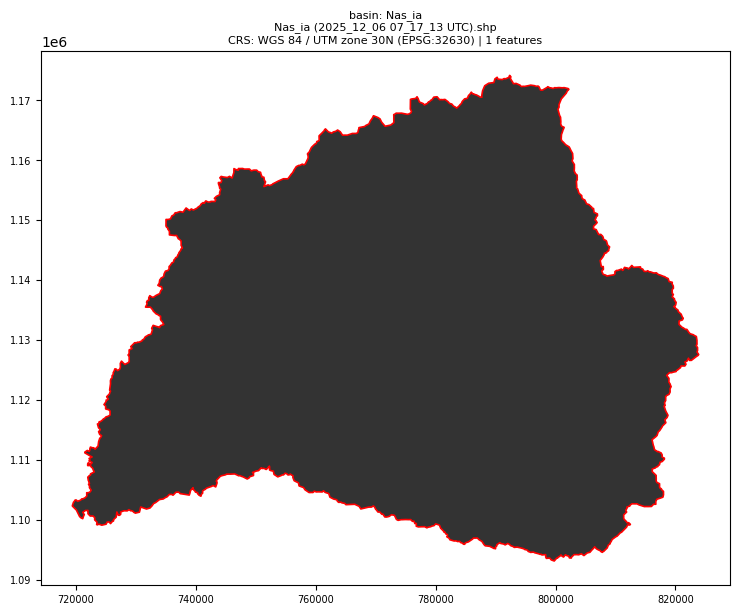

  [ OK ]   basin: Nas_ia: extent covers the basin (100%).
  --- dem: Nasia_DEM


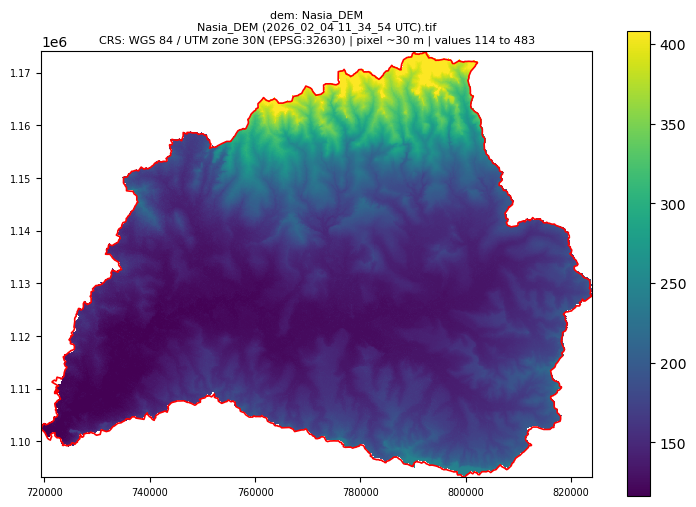

  [ OK ]   dem: Nasia_DEM: extent covers the basin (100%).
  --- dem: NasiaDEM_1


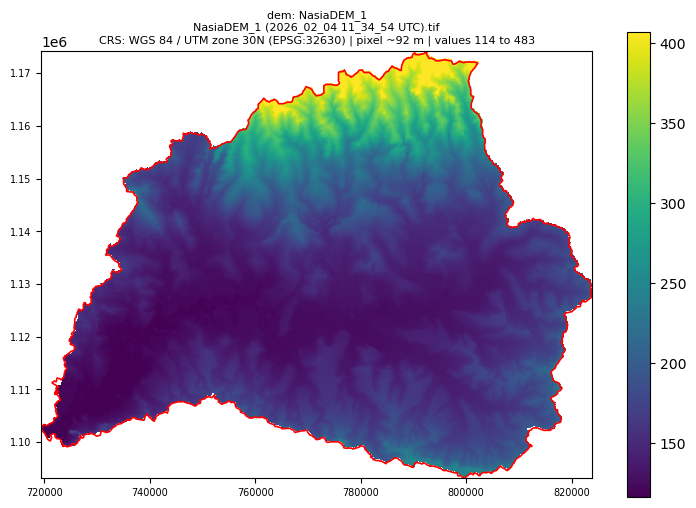

  [ OK ]   dem: NasiaDEM_1: extent covers the basin (100%).
  --- lineaments: Nasia_Lineaments


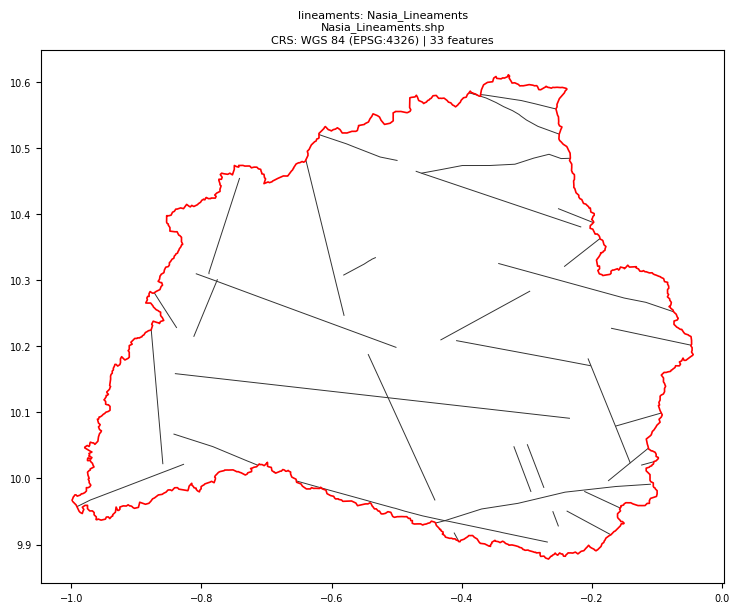

  [ OK ]   lineaments: Nasia_Lineaments: extent covers the basin (99%).
  --- streams: Nasia_rivers


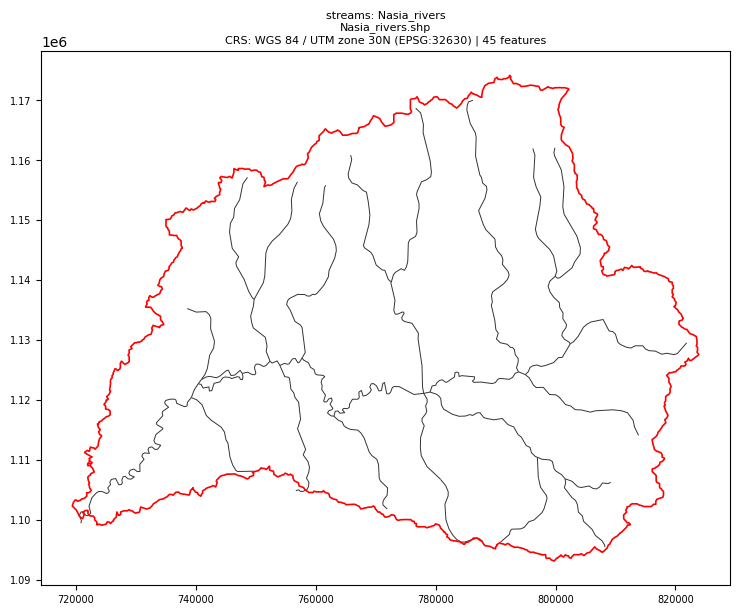

  [ OK ]   streams: Nasia_rivers: extent covers the basin (96%).
  --- geology: Nasia_Geology


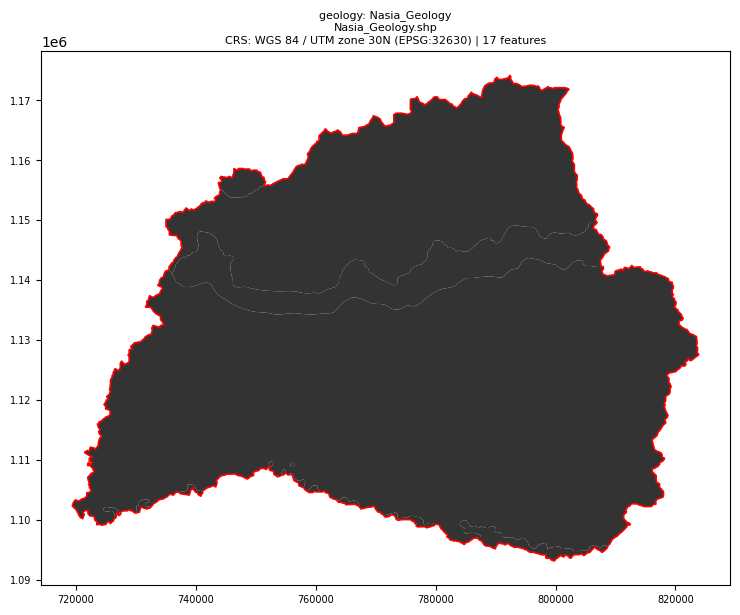

  [ OK ]   geology: Nasia_Geology: extent covers the basin (100%).
  --- geology: Nasia_Geology


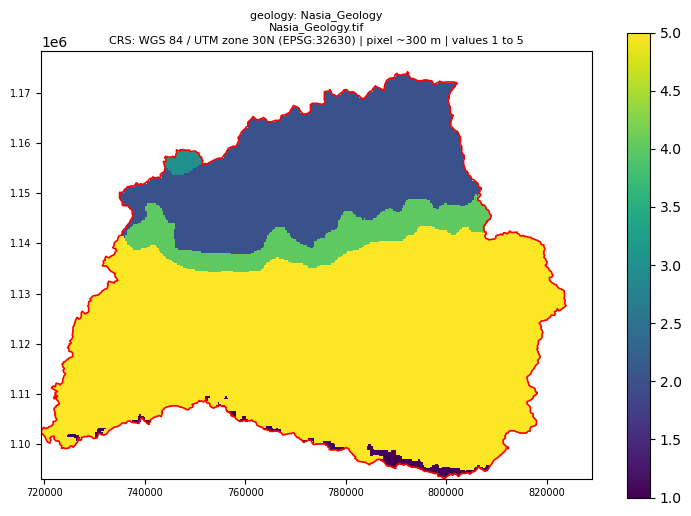

  [ OK ]   geology: Nasia_Geology: extent covers the basin (100%).
  --- soil: Soil


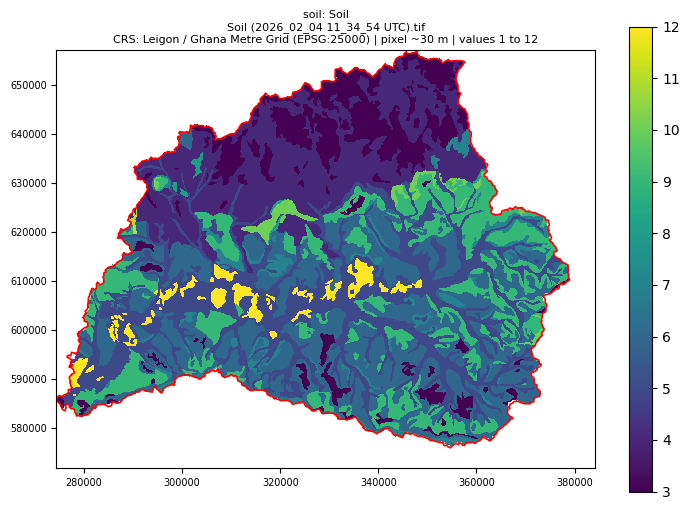

  [ OK ]   soil: Soil: extent covers the basin (100%).
  --- soil: Nasia_soils_PolygonToRaster


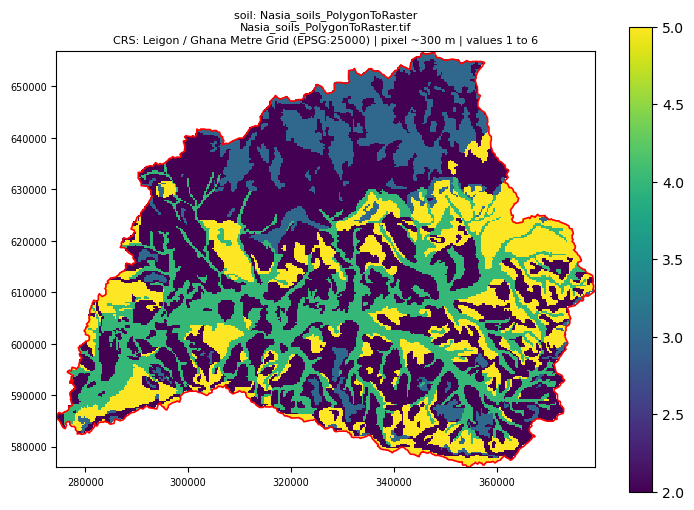

  [ OK ]   soil: Nasia_soils_PolygonToRaster: extent covers the basin
  (100%).
  --- lulc: landuse


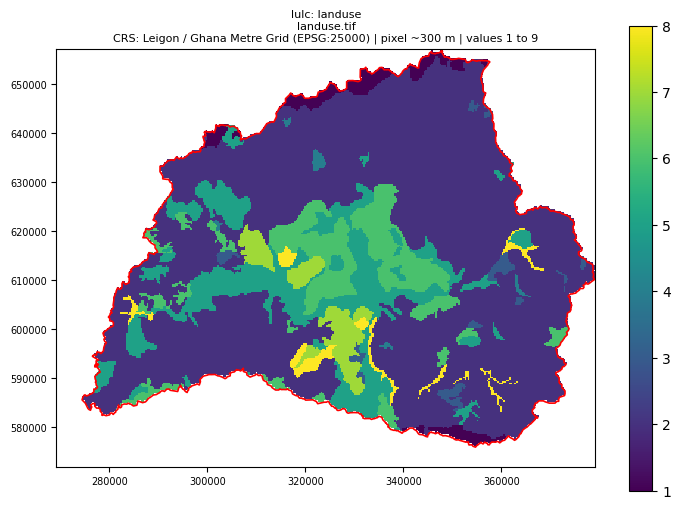

  [ OK ]   lulc: landuse: extent covers the basin (100%).
  --- rainfall: Annual_Rainfall


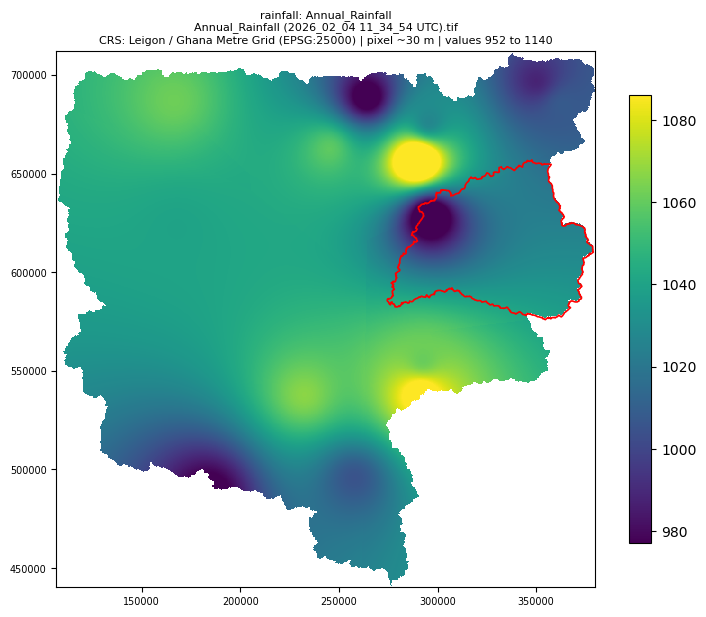

  [ OK ]   rainfall: Annual_Rainfall: extent covers the basin (100%).
  --- rainfall: Nasia_annual_precipitation


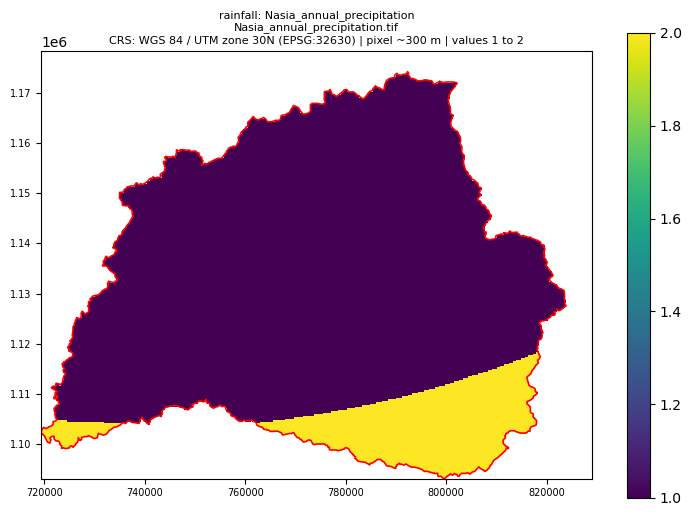

  [ OK ]   rainfall: Nasia_annual_precipitation: extent covers the basin
  (100%).
  --- rainfall: Rainfall


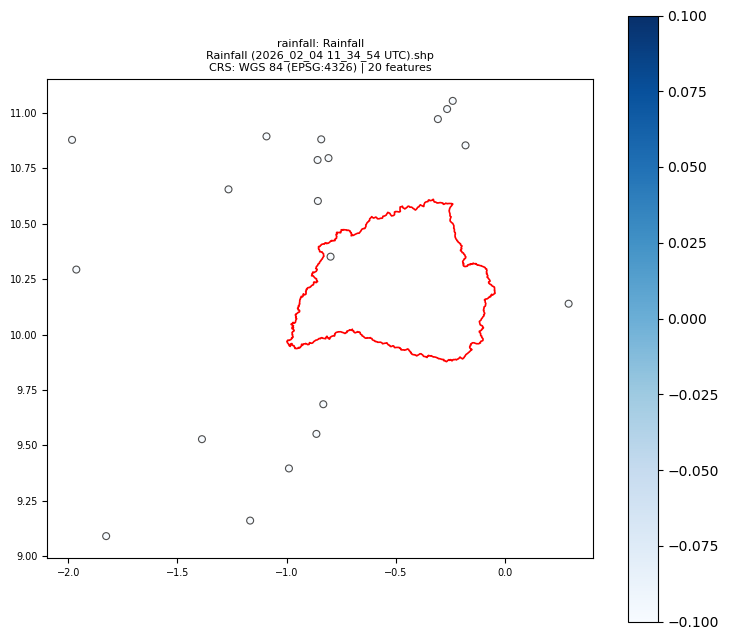

  [ OK ]   rainfall: Rainfall: extent covers the basin (100%).
  --- rainfall: Meteo_Stations


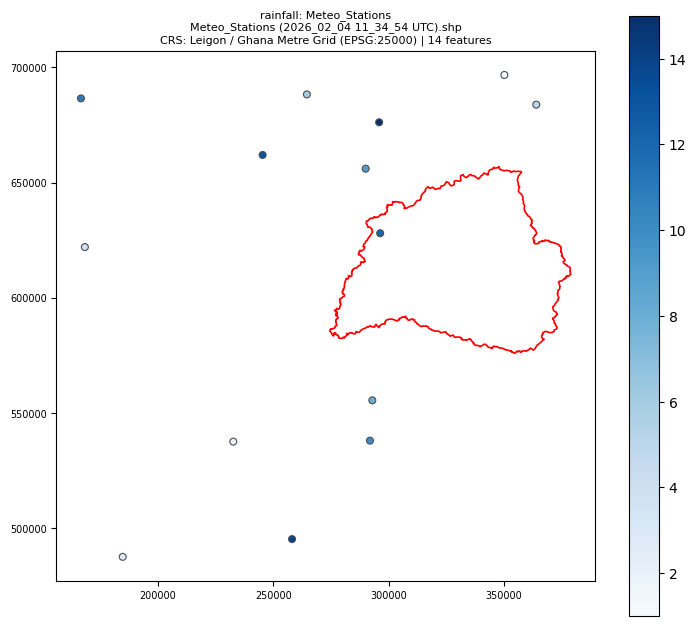

  [WARN]   rainfall: Meteo_Stations: its extent covers only 53% of the
  basin.
  --- rainfall: Nasia_annual_precipitation


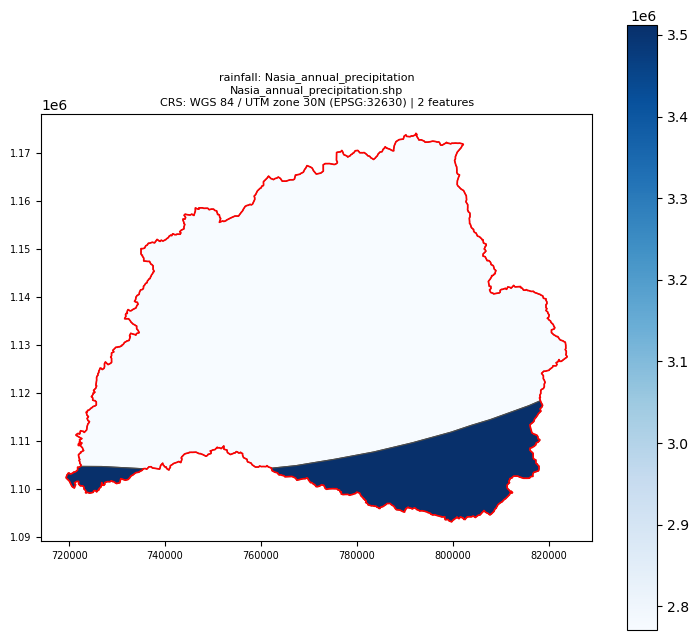

  [ OK ]   rainfall: Nasia_annual_precipitation: extent covers the basin
  (100%).
  --- old_slope: Nasia_Slope


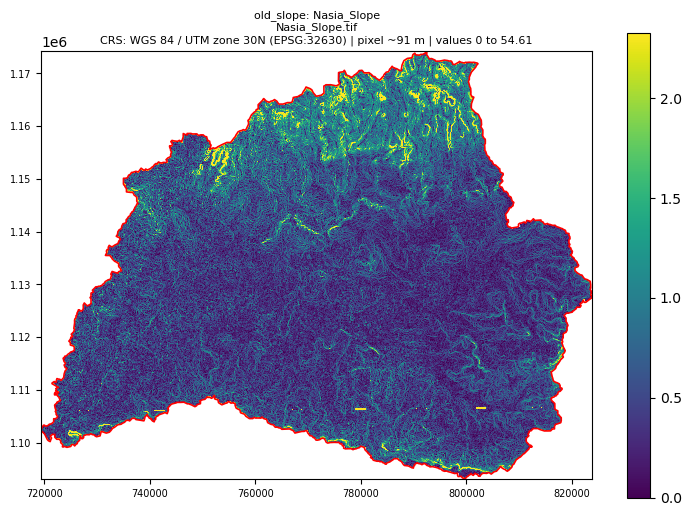

  [ OK ]   old_slope: Nasia_Slope: extent covers the basin (100%).
  --- old_drainage_density: Drainage_Density


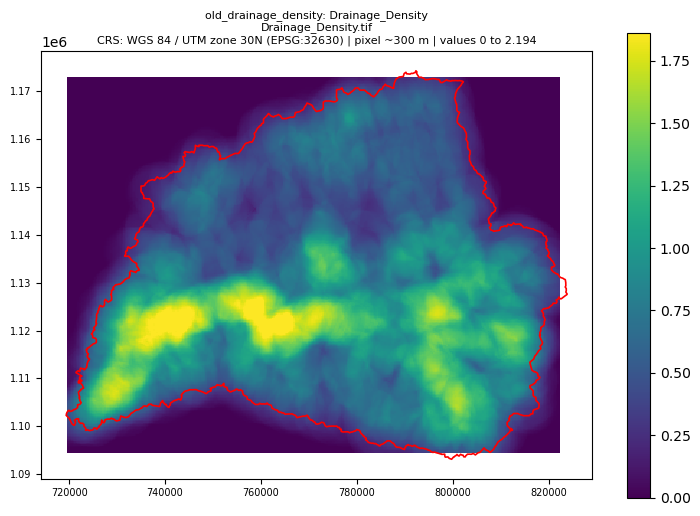

  [ OK ]   old_drainage_density: Drainage_Density: extent covers the basin
  (100%).

               Input                                          File   Kind                                    CRS  Features                   Geometry  Basin_covered_pct      Size  Pixel_m
               basin          Nas_ia (2025_12_06 07_17_13 UTC).shp vector     WGS 84 / UTM zone 30N (EPSG:32630)       1.0                    Polygon              100.0       NaN      NaN
                 dem       Nasia_DEM (2026_02_04 11_34_54 UTC).tif raster     WGS 84 / UTM zone 30N (EPSG:32630)       NaN                        NaN              100.0 3488x2701     30.0
                 dem      NasiaDEM_1 (2026_02_04 11_34_54 UTC).tif raster     WGS 84 / UTM zone 30N (EPSG:32630)       NaN                        NaN              100.0  1134x879     92.2
          lineaments                          Nasia_Lineaments.shp vector                     WGS 84 (EPSG:4326)      33.0 LineString,MultiLineString             

In [7]:
banner("A3", "a picture and a check of every raw input")
io_note(["every input file found in BLOCK A1"],
        ["final_maps/01_inputs/*.png",
         "tables/table_S0b_input_crs_and_relevance.csv"])


def picture_raster(path, label, out_png):
    with rasterio.open(path) as src:
        crs = src.crs or guess_crs(tuple(src.bounds))
        f = max(1, int(np.ceil(max(src.width, src.height) / 1200)))
        a = src.read(1, out_shape=(max(1, src.height // f), max(1, src.width // f)),
                     resampling=Resampling.nearest).astype("float64")
        if src.nodata is not None:
            a[a == src.nodata] = np.nan
        a[np.isin(a, _SENTINELS) | (np.abs(a) > 1e30)] = np.nan
        ext = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
        res = native_res_m(src.transform, crs) if crs else np.nan
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    v = a[np.isfinite(a)]
    if v.size:
        vmin, vmax = np.percentile(v, [1, 99])
        im = ax.imshow(a, extent=ext, cmap="viridis", vmin=vmin,
                       vmax=vmax if vmax > vmin else vmin + 1,
                       interpolation="nearest")
        fig.colorbar(im, ax=ax, shrink=0.75)
    if crs is not None:
        BASIN_UTM.to_crs(crs).boundary.plot(ax=ax, color="red", lw=1.2)
    ax.set_title(f"{label}\n{Path(path).name}\nCRS: {crs_label(crs)} | "
                 f"pixel ~{res:,.0f} m | "
                 f"values {np.nanmin(a) if v.size else np.nan:.4g} to "
                 f"{np.nanmax(a) if v.size else np.nan:.4g}", fontsize=8)
    ax.tick_params(labelsize=7)
    fig.tight_layout()
    fig.savefig(out_png, dpi=200)
    show_fig(fig)


def picture_vector(g_native, label, path, out_png, column=None):
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    if column and column in g_native.columns:
        txt_ = _is_text(g_native[column])
        g_native.plot(ax=ax, column=column, legend=True,
                      cmap="tab20" if txt_ else "Blues", markersize=25,
                      linewidth=0.8, edgecolor="0.3",
                      legend_kwds=dict(fontsize=6) if txt_ else None)
    else:
        g_native.plot(ax=ax, color="0.2", markersize=20, linewidth=0.7)
    if g_native.crs is not None:
        BASIN_UTM.to_crs(g_native.crs).boundary.plot(ax=ax, color="red", lw=1.2)
    ax.set_title(f"{label}\n{Path(path).name}\nCRS: {crs_label(g_native.crs)} | "
                 f"{len(g_native)} features", fontsize=8)
    ax.tick_params(labelsize=7)
    fig.tight_layout()
    fig.savefig(out_png, dpi=200)
    show_fig(fig)


rel_rows = []
_basin_lonlat = BASIN_UTM.to_crs(4326).geometry.iloc[0]
for key, paths in FOUND.items():
    for p in paths:
        suf = p.suffix.lower()
        if suf not in (".tif", ".tiff", ".shp"):
            continue
        label = f"{key}: {re.sub(_UTC, '', p.stem).strip()}"
        png = DIR_MAP_IN / (re.sub(r"[^\w]+", "_", label).strip("_")
                            + f"_{suf.strip('.')}.png")
        print(f"  --- {label}")
        try:
            if suf == ".shp":
                g = gpd.read_file(p)
                g = g[g.geometry.notna() & ~g.geometry.is_empty]
                if g.crs is None:
                    gc = guess_crs(g.total_bounds) if len(g) else None
                    if gc is not None:
                        g = g.set_crs(gc)
                cover = np.nan
                if g.crs is not None and len(g):
                    hull = g.to_crs(4326).union_all().convex_hull.buffer(0.02)
                    cover = 100 * hull.intersection(_basin_lonlat).area / _basin_lonlat.area
                num = [c for c in g.columns if c != "geometry"
                       and pd.api.types.is_numeric_dtype(g[c])]
                picture_vector(g, label, p, png,
                               column=(num[0] if key == "rainfall" and num else None))
                rel_rows.append(dict(Input=key, File=p.name, Kind="vector",
                                     CRS=crs_label(g.crs), Features=len(g),
                                     Geometry=",".join(sorted(g.geom_type.unique())),
                                     Basin_covered_pct=round(cover, 1)))
            else:
                with rasterio.open(p) as src:
                    crs = src.crs or guess_crs(tuple(src.bounds))
                    info = dict(Input=key, File=p.name, Kind="raster",
                                CRS=crs_label(src.crs) + ("" if src.crs else
                                    f" -> inferred {crs_label(crs)}"),
                                Size=f"{src.width}x{src.height}",
                                Pixel_m=round(native_res_m(src.transform, crs), 1)
                                if crs else None,
                                DType=src.dtypes[0], NoData=src.nodata)
                    cover = np.nan
                    if crs is not None:
                        rb = transform_bounds(crs, 4326, *src.bounds)
                        rbox = shapely.box(*rb)
                        cover = 100 * rbox.intersection(_basin_lonlat).area / _basin_lonlat.area
                info["Basin_covered_pct"] = round(cover, 1)
                rel_rows.append(info)
                picture_raster(p, label, png)
            if np.isfinite(cover) and cover < 95:
                (bad if cover < 50 else warn)(
                    "A3", f"{label}: its extent covers only {cover:.0f}% of "
                          f"the basin.")
            elif np.isfinite(cover):
                ok(f"{label}: extent covers the basin ({cover:.0f}%).")
        except Exception as e:
            bad("A3", f"{label}: could not be opened ({type(e).__name__}: {e}).")

rel_df = pd.DataFrame(rel_rows)
rel_df.to_csv(DIR_TAB / "table_S0b_input_crs_and_relevance.csv", index=False)
print()
print(rel_df.drop(columns=[c for c in ("DType", "NoData") if c in rel_df]).to_string(index=False))
crs_set = sorted(set(rel_df.CRS))
print()
if len(crs_set) > 1:
    note(f"The inputs come in {len(crs_set)} different coordinate systems: "
         f"{'; '.join(crs_set)}. All are reprojected to "
         f"{crs_label(TARGET_CRS)} in the blocks that follow.")
verdict("A3")
done(f"{len(rel_df)} inputs pictured in final_maps/01_inputs.")

## BLOCK A4  |  CHOOSING THE DEM: ELEVATION AND SLOPE

 INPUTS   : the DEM candidates (Nasia_DEM.tif, NasiaDEM_1.tif)  
            the 2022 slope raster, for comparison only (Nasia_Slope.tif)  
 OUTPUTS  : Elevation and Slope on the master grid (written in BLOCK A10)  
            final_maps/02_factors/Elevation.png, Slope.png  
            tables/table_S0c_dem_candidates.csv  
 RUNTIME  : under a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Your folder holds two DEMs, about 20 MB and 2 MB. They are almost certainly  
 the same terrain at different resolutions, or one clipped tighter than the  
 other. Each is reprojected to the master grid and judged on:  
    - how much of the basin it covers (it must be essentially all);  
    - its native pixel size (closest to 30 m wins - a 90 m DEM resampled to  
      30 m only looks sharper);  
    - whether its heights are plausible for northern Ghana (roughly 100 to  
      550 m, the Gambaga scarp being the high ground).  
  
 Slope is then computed in DEGREES from the chosen DEM. Your 2022 slope  
 raster is compared with it: if the old one runs several times higher it  
 was probably in percent rise, which matters because the manuscript tables  
 must state the unit.  
  
 SANITY CHECKS: coverage, plausible heights, no negative or spike values,  
 median slope in the gentle range expected for the Voltaian plains.  


  BLOCK A4  |  CHOOSING THE DEM: ELEVATION AND SLOPE
  READS :
      Nasia_DEM (2026_02_04 11_34_54 UTC).tif
      NasiaDEM_1 (2026_02_04 11_34_54 UTC).tif
      Nasia_Slope.tif (comparison only)
  WRITES:
      Elevation and Slope (in memory)
      final_maps/02_factors/Elevation.png
      final_maps/02_factors/Slope.png
      tables/table_S0c_dem_candidates.csv

                                    file                                crs  native_m        size  Coverage_pct   Min   Max  Mean  Plausible   modified
 Nasia_DEM (2026_02_04 11_34_54 UTC).tif WGS 84 / UTM zone 30N (EPSG:32630)      30.0 3488 x 2701         99.55 114.0 483.0 178.4       True 2025-11-10
NasiaDEM_1 (2026_02_04 11_34_54 UTC).tif WGS 84 / UTM zone 30N (EPSG:32630)      92.2  1134 x 879         99.64 114.0 482.7 178.5       True 2025-11-17

  Chosen DEM: Nasia_DEM (2026_02_04 11_34_54 UTC).tif - it covers 99.5% of the basin at a native pixel of 30 m, the closest to the 30 m grid.

  [note]   26,446 DEM void pixel

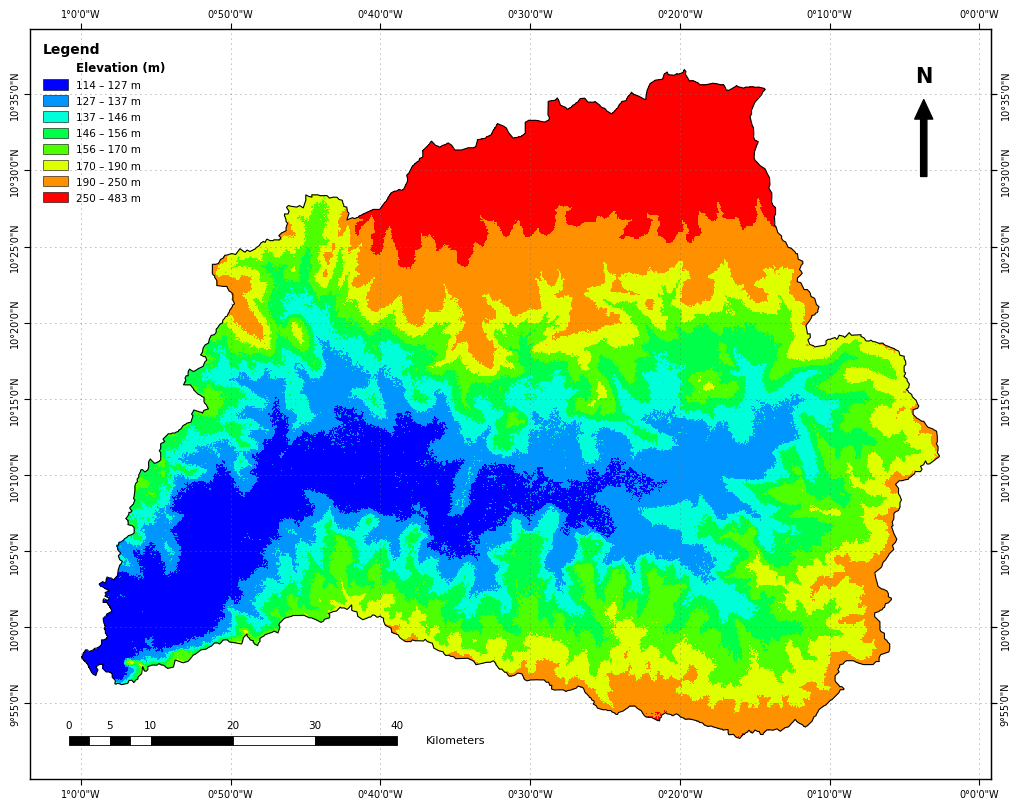

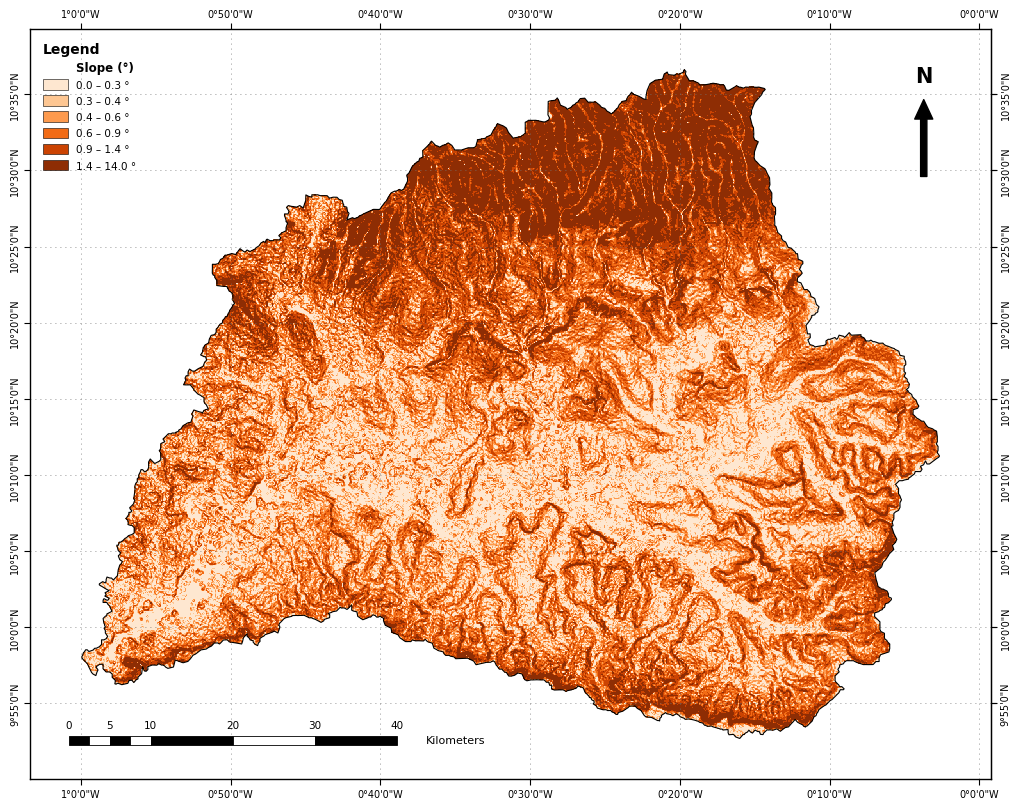


  SANITY VERDICT, BLOCK A4: all checks passed.
  --------------------------------------------------------------------------
  DONE. Elevation and slope built from Nasia_DEM (2026_02_04 11_34_54
  UTC).tif.
  --------------------------------------------------------------------------


In [8]:
banner("A4", "choosing the DEM: elevation and slope")
io_note([p.name for p in FOUND.get("dem", [])] +
        [p.name + " (comparison only)" for p in FOUND.get("old_slope", [])],
        ["Elevation and Slope (in memory)", "final_maps/02_factors/Elevation.png",
         "final_maps/02_factors/Slope.png", "tables/table_S0c_dem_candidates.csv"])

dem_rows, dem_arrays = [], {}
for p in FOUND.get("dem", []):
    a, info = warp_to_grid("A4", p, f"DEM '{p.name}'")
    if a is None:
        continue
    v = basin_values(a)
    cov = 100 * v.size / BASIN_MASK.sum()
    row = dict(info, Coverage_pct=round(cov, 2),
               Min=round(float(v.min()), 1) if v.size else None,
               Max=round(float(v.max()), 1) if v.size else None,
               Mean=round(float(v.mean()), 1) if v.size else None)
    lo, hi = EXPECT["Elevation"]
    row["Plausible"] = bool(v.size and v.min() >= lo - 50 and v.max() <= hi + 200)
    dem_rows.append(row)
    dem_arrays[p.name] = a

dem_tab = pd.DataFrame(dem_rows)
if dem_tab.empty:
    missing_note("A4", "a readable DEM", str(RAW["dem"]),
                 "None of the DEM candidates could be read onto the grid. Check "
                 "the files open in QGIS and cover the Nasia basin.")
    stop()
print(dem_tab[["file", "crs", "native_m", "size", "Coverage_pct", "Min", "Max",
               "Mean", "Plausible", "modified"]].to_string(index=False))
print()

if DEM_CHOICE != "auto":
    chosen_dem = next((n for n in dem_arrays if n.startswith(Path(DEM_CHOICE).stem)), None)
    reason = "chosen by you in BLOCK 1 (DEM_CHOICE)"
else:
    t = dem_tab.copy()
    t["full"] = t.Coverage_pct >= 99
    t["res_gap"] = (t.native_m - PIXEL_M).abs()
    t = t.sort_values(["Plausible", "full", "res_gap", "modified"],
                      ascending=[False, False, True, False])
    chosen_dem = t.file.iloc[0]
    r = t.iloc[0]
    reason = (f"it covers {r.Coverage_pct:.1f}% of the basin at a native "
              f"pixel of {r.native_m:.0f} m, the closest to the 30 m grid")
if chosen_dem is None:
    missing_note("A4", f"DEM named in DEM_CHOICE ('{DEM_CHOICE}')", str(DATA_DIR),
                 "Set DEM_CHOICE to 'auto' or to one of the files listed above.")
    stop()
print(f"  Chosen DEM: {chosen_dem} - {reason}.")
print()
dem = dem_arrays[chosen_dem].astype("float64")
BUILD_INFO["Elevation"] = dict(source=chosen_dem, method=f"DEM reprojected "
                               f"bilinear to {PIXEL_M} m UTM 30N; {reason}")

# fill small voids so derivatives do not punch holes in the basin
_near_basin = ndimage.distance_transform_edt(~BASIN_MASK) * PIXEL_M <= GRID_BUFFER_M / 2
holes = np.isnan(dem) & _near_basin
if holes.any() and np.isfinite(dem).any():
    n_h = int((holes & BASIN_MASK).sum())
    if n_h:
        idx = ndimage.distance_transform_edt(np.isnan(dem), return_distances=False,
                                             return_indices=True)
        dem = np.where(holes, dem[tuple(idx)], dem)
        pct = 100 * n_h / BASIN_MASK.sum()
        msg = (f"{n_h:,} DEM void pixels ({pct:.2f}% of the basin) were filled "
               f"from their nearest neighbours.")
        if pct > 1:
            warn("A4", msg)
        else:
            note(msg)

v = basin_values(dem)
if (v < 0).any():
    bad("A4", f"{int((v < 0).sum()):,} DEM pixels in the basin are below sea "
              f"level - voids coded as negative values.")
spikes = v > np.percentile(v, 99.9) + 150
if spikes.any():
    warn("A4", f"{int(spikes.sum())} DEM pixels sit >150 m above the 99.9th "
               f"percentile - possible spikes or artefacts.")
STATS_A = {}
STATS_A["Elevation"] = check_layer("A4", "Elevation", dem, "m a.s.l.",
                                   EXPECT["Elevation"])

# --- smoothing for the derivatives (slope, TPI, TWI, streams) ---------------
# Whole-metre heights make 1 m steps that read as false slopes on gentle
# ground, and this DEM also carries a ~1.25 km grid (rows/columns duplicated
# when it was resampled to 30 m before it reached us). A light Gaussian
# smoothing suppresses both; BLOCK D measures how well.
with rasterio.open(next(p_ for p_ in FOUND["dem"] if p_.name == chosen_dem)) as _s:
    _wv = _s.read(1, window=Window(_s.width // 2, _s.height // 2,
                                   min(500, _s.width // 2), min(500, _s.height // 2))).astype(float)
    if _s.nodata is not None:
        _wv = _wv[_wv != _s.nodata]
    _wv = _wv[np.isfinite(_wv)]
_int_frac = float(np.mean(np.abs(_wv - np.round(_wv)) < 1e-6)) if _wv.size else 0.0
if DEM_SMOOTH_SIGMA_PX == "auto":
    DEM_SIGMA = 2.5 if _int_frac > 0.95 else 0.0
else:
    DEM_SIGMA = float(DEM_SMOOTH_SIGMA_PX)
if DEM_SIGMA > 0:
    _w = np.isfinite(dem).astype("float64")
    _num = ndimage.gaussian_filter(np.where(np.isfinite(dem), dem, 0.0), DEM_SIGMA)
    _den = ndimage.gaussian_filter(_w, DEM_SIGMA)
    dem_d = np.where(np.isfinite(dem), _num / np.maximum(_den, 1e-9), np.nan)
    note(f"{100*_int_frac:.0f}% of DEM heights are whole metres. The DEM is "
         f"smoothed with a Gaussian of {DEM_SIGMA:g} pixels ({DEM_SIGMA*PIXEL_M:.0f} m) "
         f"before slope, TPI, TWI and streams. State this in the methods. A "
         f"float DEM (Copernicus GLO-30 or FABDEM) would make it unnecessary.")
    del _num, _den, _w
else:
    dem_d = dem
BUILD_INFO["Elevation"]["smoothing_for_derivatives_px"] = DEM_SIGMA

gy, gx = np.gradient(dem_d, PIXEL_M)
slope = np.degrees(np.arctan(np.hypot(gx, gy)))
STATS_A["Slope"] = check_layer("A4", "Slope", slope, "degrees", EXPECT["Slope"])
med_sl = STATS_A["Slope"].get("Median", np.nan)
if np.isfinite(med_sl) and med_sl > 8:
    warn("A4", f"Median slope {med_sl:.1f} deg is steep for the Voltaian "
               f"plains - check the DEM's vertical units (feet?).")

if FOUND.get("old_slope"):
    old, _ = warp_to_grid("A4", FOUND["old_slope"][0], "2022 slope raster")
    if old is not None:
        m = BASIN_MASK & np.isfinite(old) & np.isfinite(slope)
        if m.sum() > 1000:
            r = np.corrcoef(old[m], slope[m])[0, 1]
            ratio = np.median(old[m]) / max(np.median(slope[m]), 1e-6)
            print(f"\n  Comparison with the 2022 slope raster: r = {r:.2f}, "
                  f"median ratio old/new = {ratio:.2f}")
            if ratio > 1.4:
                note("The 2022 slope runs higher than the new one - it was "
                     "probably percent rise, or from a different DEM. The new "
                     "slope (degrees) is used.")

BUILT["Elevation"], BUILT["Slope"] = dem.astype("float32"), slope.astype("float32")
BUILD_INFO["Slope"] = dict(source=chosen_dem, method="central-difference "
                           "gradient on the 30 m DEM, degrees"
                           + (f"; DEM Gaussian-smoothed {DEM_SIGMA:g} px" if DEM_SIGMA else ""))
dem_tab.to_csv(DIR_TAB / "table_S0c_dem_candidates.csv", index=False)
save_map(dem, "Elevation", DIR_MAP_FAC / "Elevation.png", "m",
         MAP_STYLE["Elevation"], n_classes=8)
save_map(slope, "Slope", DIR_MAP_FAC / "Slope.png", "degrees", MAP_STYLE["Slope"])
verdict("A4")
done(f"Elevation and slope built from {chosen_dem}.")

## BLOCK A5  |  WATER ON THE DEM: STREAMS, TWI, DRAINAGE DENSITY, DISTANCE

 INPUTS   : the DEM chosen in BLOCK A4  
            optionally a digitised stream network (RAW["streams"])  
            the 2022 drainage density raster, for comparison only  
 OUTPUTS  : TWI, DrainageDens, DistStream on the master grid  
            vectors/Nasia_streams_from_DEM.shp  (open it in QGIS to check)  
            final_maps/02_factors/TWI.png, DrainageDens.png, DistStream.png  
 RUNTIME  : one to three minutes  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 There is no stream-network file in your folder, so the streams are  
 extracted from the DEM - the standard approach, and easy to describe:  
  
  1. FILL: small pits in the DEM (mostly noise) are filled so water can  
     flow out of them.  
  2. FLOW DIRECTION: every cell drains to its steepest downhill neighbour  
     (the D8 method).  
  3. FLOW ACCUMULATION: count how many cells drain through each cell.  
  4. STREAMS: any cell draining more than STREAM_THRESHOLD_KM2 (1 km2 by  
     default) is a channel.  
  
 From that come three factors:  
    TWI = ln(a / tan B), where a is the upslope area per unit contour width  
          and B the slope. High TWI = where water collects.  
    DRAINAGE DENSITY = length of channel per km2, in a moving window of  
          radius DRAINAGE_RADIUS_M.  
    DISTANCE TO STREAM = straight-line distance to the nearest channel, in  
          metres. Computed on the buffered grid, so a stream just outside  
          the basin still counts.  
  
 SANITY CHECKS: drainage density in the 0.2-3 km/km2 range typical of  
 savannah basins; distances that never exceed a few km; TWI in its usual  
 range; and the stream network written out so you can lay it over imagery  
 in QGIS and confirm it follows the real rivers - the Nasia itself should be  
 the trunk channel. Compare against the 2022 drainage-density raster.  


  BLOCK A5  |  WATER ON THE DEM: STREAMS, TWI, DRAINAGE DENSITY, DISTANCE
  READS :
      the DEM chosen in BLOCK A4 (Nasia_DEM (2026_02_04 11_34_54 UTC).tif)
      digitised streams: Nasia_rivers.shp
  WRITES:
      TWI, DrainageDens, DistStream (in memory)
      vectors/Nasia_streams_from_DEM.shp
      final_maps/02_factors/TWI.png, DrainageDens.png, DistStream.png

  Flow routing done in 17 s.
  Depression filling raised 53.2% of basin cells (max 12.2 m).
  [WARN]   Depression filling raised 27% of the basin by more than 0.5 m -
  the DEM has large closed hollows (dams, quarries or artefacts). Check the
  extracted streams in QGIS.
  [ OK ]   Stream network written: vectors/Nasia_streams_from_DEM.shp (3,601
  reaches). Open it in QGIS over imagery to check.
  [ OK ]   TWI: covers 100.0% of the basin.
  [ OK ]   TWI: 7.885 to 13.29 dimensionless (5th-95th percentile), within
  the plausible 0 to 30.


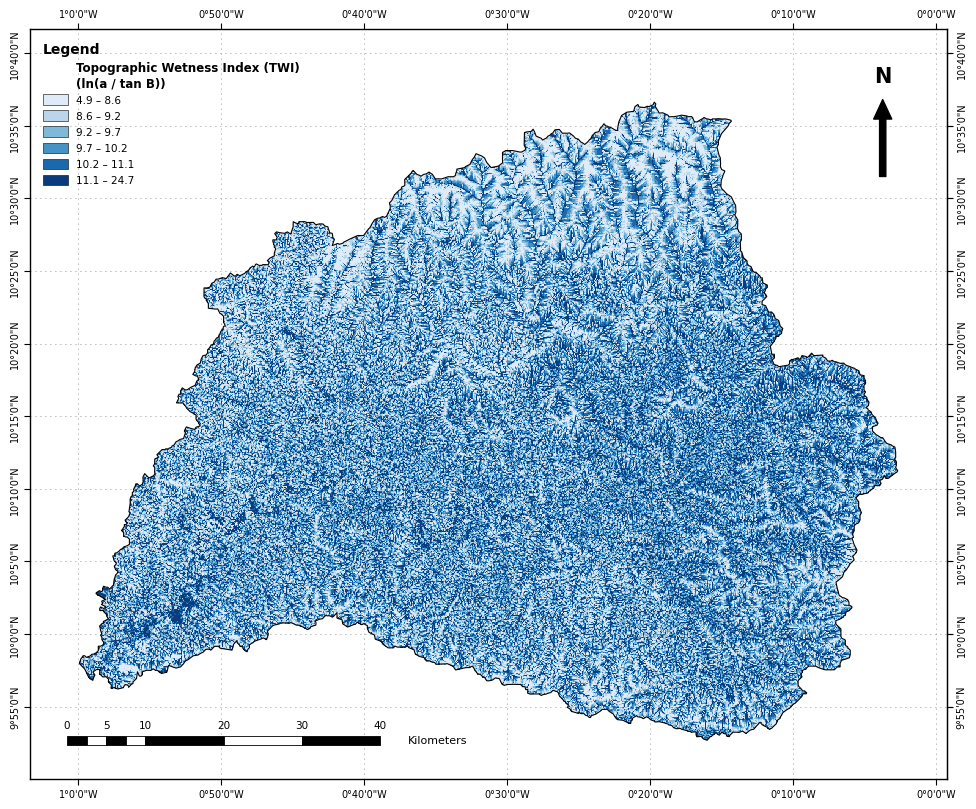

  [ OK ]   Mapped rivers: already in WGS 84 / UTM zone 30N (EPSG:32630).
  Mapped rivers: 45 segments, 669 km inside the basin -> drainage density 0.13 km/km2
  29% of mapped-river pixels lie within 150 m of a DEM channel (DEM network: 1.7% of basin cells are channel).
  [WARN]   Only 29% of mapped rivers lie within 150 m of a DEM channel.
  Check the DEM network in QGIS; if the mapped rivers are more reliable, set
  STREAMS_SOURCE = 'shapefile'.
  [note]   Drainage density and distance to stream use the DEM channels
  (mapped rivers used as a check).

  Channel length inside basin: 3,650 km  -> basin-wide drainage density 0.68 km/km2
  [ OK ]   Basin-wide drainage density 0.68 km/km2 is in the expected range.
  [ OK ]   DrainageDens: covers 100.0% of the basin.
  [ OK ]   DrainageDens: 0 to 1.562 km/km2 (5th-95th percentile), within the
  plausible 0 to 6.
  [ OK ]   DistStream: covers 100.0% of the basin.
  [ OK ]   DistStream: 30 to 1230 m (5th-95th percentile), within the
  plausib

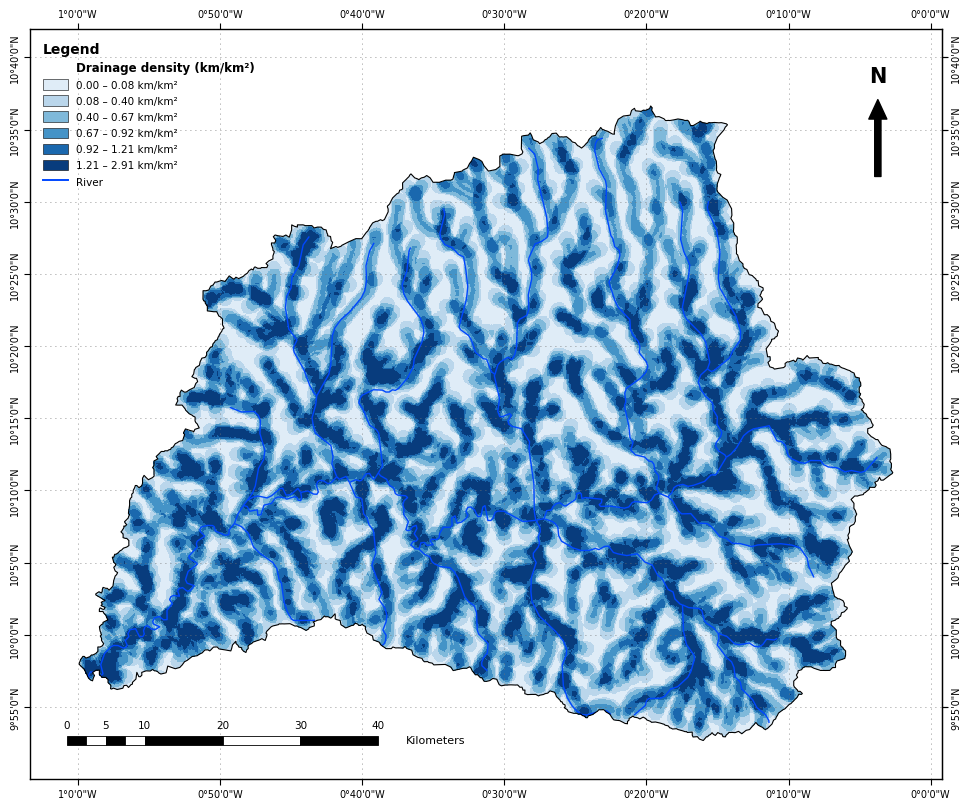

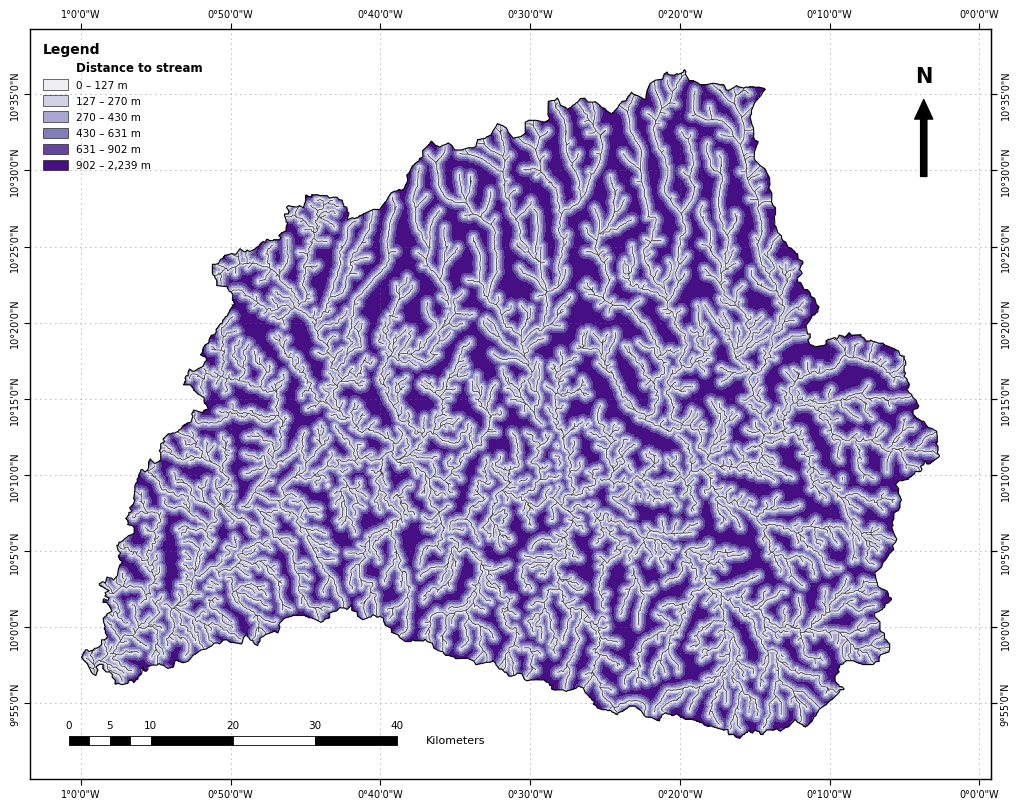


  SANITY VERDICT, BLOCK A5: usable, with 2 warning(s) to read.
  --------------------------------------------------------------------------
  DONE. Hydrological factors built: TWI, DrainageDens, DistStream
  --------------------------------------------------------------------------


In [9]:
banner("A5", "water on the DEM: streams, TWI, drainage density, distance")
io_note([f"the DEM chosen in BLOCK A4 ({chosen_dem})",
         f"digitised streams: {RAW['streams'] or '(none - extracted from the DEM)'}"],
        ["TWI, DrainageDens, DistStream (in memory)",
         "vectors/Nasia_streams_from_DEM.shp",
         "final_maps/02_factors/TWI.png, DrainageDens.png, DistStream.png"])

stream_cells, stream_len_m, acc, fdir = None, None, None, None
DIRMAP = (64, 128, 1, 2, 4, 8, 16, 32)     # N NE E SE S SW W NW

if HAVE_PYSHEDS:
    work = OUTPUT_DIR / "work"
    work.mkdir(exist_ok=True)
    dem_tmp = work / "_dem_for_flow_routing.tif"
    with rasterio.open(dem_tmp, "w", driver="GTiff", height=GRID_H, width=GRID_W,
                       count=1, dtype="float32", crs=TARGET_CRS, transform=GRID_T,
                       nodata=-9999.0) as dst:
        dst.write(np.where(np.isfinite(dem_d), dem_d, -9999.0).astype("float32"), 1)
    t0 = time.time()
    pg = _PyshedsGrid.from_raster(str(dem_tmp))
    praw = pg.read_raster(str(dem_tmp))
    pfill = pg.resolve_flats(pg.fill_depressions(pg.fill_pits(praw)))
    fdir_r = pg.flowdir(pfill, dirmap=DIRMAP)
    acc_r = pg.accumulation(fdir_r, dirmap=DIRMAP)
    fdir = np.asarray(fdir_r)
    acc = np.asarray(acc_r).astype("float64")
    acc[~np.isfinite(dem)] = np.nan
    filled_depth = np.asarray(pfill) - np.where(np.isfinite(dem), dem, np.nan)
    print(f"  Flow routing done in {time.time() - t0:.0f} s.")
    fd = filled_depth[BASIN_MASK & np.isfinite(filled_depth)]
    if fd.size:
        print(f"  Depression filling raised {100*np.mean(fd > 0.01):.1f}% of basin "
              f"cells (max {np.nanmax(fd):.1f} m).")
        if np.mean(fd > 0.5) > 0.05:
            warn("A5", f"Depression filling raised {100*np.mean(fd > 0.5):.0f}% "
                       f"of the basin by more than 0.5 m - the DEM has large "
                       f"closed hollows (dams, quarries or artefacts). Check "
                       f"the extracted streams in QGIS.")
    thr_cells = STREAM_THRESHOLD_KM2 / PIX_KM2
    stream_cells = np.nan_to_num(acc) >= thr_cells
    diag = np.isin(fdir, (2, 8, 32, 128))
    stream_len_m = np.where(stream_cells, np.where(diag, PIXEL_M * np.sqrt(2),
                                                   PIXEL_M), 0.0)
    try:
        fc = pg.extract_river_network(fdir_r, acc_r > thr_cells, dirmap=DIRMAP)
        sgdf = gpd.GeoDataFrame.from_features(fc["features"], crs=TARGET_CRS)
        sgdf.to_file(DIR_VEC / "Nasia_streams_from_DEM.shp")
        STREAMS_UTM = sgdf
        ok(f"Stream network written: vectors/Nasia_streams_from_DEM.shp "
           f"({len(sgdf):,} reaches). Open it in QGIS over imagery to check.")
    except Exception as e:
        STREAMS_UTM = None
        note(f"Stream vectors could not be written ({type(e).__name__}); the "
             f"raster streams are still used.")

    # TWI
    tanb = np.maximum(np.tan(np.radians(slope)), 0.001)
    twi = np.log(np.maximum(acc, 1.0) * PIXEL_M / tanb)
    twi[~np.isfinite(dem)] = np.nan
    BUILT["TWI"] = twi.astype("float32")
    BUILD_INFO["TWI"] = dict(source=chosen_dem, method="ln(a/tanB); D8 flow "
                             "accumulation on the depression-filled DEM "
                             "(pysheds); tanB floored at 0.001")
    STATS_A["TWI"] = check_layer("A5", "TWI", twi, "dimensionless", EXPECT["TWI"])
    save_map(twi, "Topographic Wetness Index (TWI)", DIR_MAP_FAC / "TWI.png",
             "ln(a / tan B)", MAP_STYLE["TWI"])
else:
    STREAMS_UTM = None
    bad("A5", "pysheds is not installed: TWI cannot be computed, and streams "
              "cannot be extracted from the DEM.")

# the mapped river network (Nasia_rivers.shp): checked, compared with the DEM
# channels, and used when STREAMS_SOURCE says so
_dem_cells = stream_cells
sv = None
if FOUND.get("streams"):
    sv, sinfo = read_vector("A5", FOUND["streams"][0], "Mapped rivers")
if sv is not None:
    _lines = sv.geom_type.isin(["LineString", "MultiLineString"])
    if not _lines.all():
        warn("A5", f"Mapped rivers: {int((~_lines).sum())} features are not lines "
                   f"({sorted(set(sv.geom_type[~_lines]))}) and are ignored.")
    sv = sv[_lines].explode(index_parts=False)
    _in_km = sv.clip(BASIN_UTM).length.sum() / 1000
    _dd_map = _in_km / (BASIN_MASK.sum() * PIX_KM2)
    print(f"  Mapped rivers: {len(sv):,} segments, {_in_km:,.0f} km inside the basin "
          f"-> drainage density {_dd_map:.2f} km/km2")
    if _in_km == 0:
        bad("A5", "No mapped river lies inside the basin - a CRS problem with "
                  "Nasia_rivers.shp.")
        sv = None
if sv is not None and _dem_cells is not None:
    # how well do the DEM channels follow the mapped rivers?
    _r = rasterize(((g, 1) for g in sv.geometry), out_shape=GRID_SHAPE,
                   transform=GRID_T, all_touched=True, dtype="uint8").astype(bool) & BASIN_MASK
    _d_to_dem = ndimage.distance_transform_edt(~_dem_cells) * PIXEL_M
    _share = float(np.mean(_d_to_dem[_r] <= 150)) if _r.any() else np.nan
    print(f"  {100*_share:.0f}% of mapped-river pixels lie within 150 m of a DEM "
          f"channel (DEM network: {100*_dem_cells[BASIN_MASK].mean():.1f}% of basin "
          f"cells are channel).")
    if _share >= 0.7:
        ok(f"The DEM channels follow the mapped rivers ({100*_share:.0f}% within "
           f"150 m) - the extracted network is credible.")
    else:
        warn("A5", f"Only {100*_share:.0f}% of mapped rivers lie within 150 m of a "
                   f"DEM channel. Check the DEM network in QGIS; if the mapped "
                   f"rivers are more reliable, set STREAMS_SOURCE = 'shapefile'.")
    BUILD_INFO["stream_check"] = dict(share_within_150m=round(_share, 3))
RIVERS_LL = sv.clip(BASIN_UTM).to_crs(4326) if sv is not None else None
_use_map = sv is not None and (STREAMS_SOURCE == "shapefile" or
                               (STREAMS_SOURCE == "auto" and _dem_cells is None))
if STREAMS_SOURCE == "dem" and _dem_cells is None:
    bad("A5", "STREAMS_SOURCE = 'dem' but the DEM channels could not be made "
              "(pysheds). Install pysheds or set STREAMS_SOURCE = 'auto'.")
if _use_map:
    if True:
        STREAMS_UTM = sv
        stream_cells = rasterize(((g, 1) for g in sv.geometry), out_shape=GRID_SHAPE,
                                 transform=GRID_T, all_touched=True,
                                 dtype="uint8").astype(bool)
        stream_len_m = None
        L = np.zeros(GRID_SHAPE)
        for geom in sv.explode(index_parts=False).geometry:
            c = np.asarray(shapely.segmentize(geom, PIXEL_M / 2).coords)[:, :2]
            mid, ln = (c[1:] + c[:-1]) / 2, np.hypot(*(c[1:] - c[:-1]).T)
            cc = ((mid[:, 0] - GRID_T.c) // PIXEL_M).astype(int)
            rr = ((GRID_T.f - mid[:, 1]) // PIXEL_M).astype(int)
            k = (rr >= 0) & (rr < GRID_H) & (cc >= 0) & (cc < GRID_W)
            np.add.at(L, (rr[k], cc[k]), ln[k])
        stream_len_m = L
        note("Drainage density and distance to stream use the MAPPED rivers "
             "(Nasia_rivers.shp). Their density reflects the scale at which the "
             "rivers were mapped - state that scale in the methods.")
elif _dem_cells is not None:
    note("Drainage density and distance to stream use the DEM channels"
         + (" (mapped rivers used as a check)." if sv is not None else "."))

if stream_cells is not None and stream_cells[BASIN_MASK].any():
    dsum, kcells = focal_sum(stream_len_m, DRAINAGE_RADIUS_M)
    dd = dsum / (kcells * PIXEL_M ** 2) * 1000.0          # km per km2
    dd[~np.isfinite(dem)] = np.nan
    dist_s = ndimage.distance_transform_edt(~stream_cells) * PIXEL_M
    dist_s = dist_s.astype("float64")
    dist_s[~np.isfinite(dem)] = np.nan
    BUILT["DrainageDens"] = dd.astype("float32")
    BUILT["DistStream"] = dist_s.astype("float32")
    src_s = (f"mapped rivers ({FOUND['streams'][0].name})" if _use_map else
             f"streams extracted from the DEM at {STREAM_THRESHOLD_KM2} km2 "
             f"upstream area (D8, pysheds)")
    BUILD_INFO["DrainageDens"] = dict(source=src_s, method=f"channel length per "
                                      f"km2 in a {DRAINAGE_RADIUS_M} m radius window")
    BUILD_INFO["DistStream"] = dict(source=src_s, method="Euclidean distance "
                                    "to nearest channel cell, buffered grid")
    total_km = stream_len_m[BASIN_MASK].sum() / 1000
    basin_dd = total_km / (BASIN_MASK.sum() * PIX_KM2)
    print(f"\n  Channel length inside basin: {total_km:,.0f} km  -> basin-wide "
          f"drainage density {basin_dd:.2f} km/km2")
    if not 0.2 <= basin_dd <= 3.0:
        warn("A5", f"Basin-wide drainage density {basin_dd:.2f} km/km2 is "
                   f"outside the 0.2-3 range typical of savannah basins - "
                   f"adjust STREAM_THRESHOLD_KM2 and re-run.")
    else:
        ok(f"Basin-wide drainage density {basin_dd:.2f} km/km2 is in the "
           f"expected range.")
    STATS_A["DrainageDens"] = check_layer("A5", "DrainageDens", dd, "km/km2",
                                          EXPECT["DrainageDens"])
    STATS_A["DistStream"] = check_layer("A5", "DistStream", dist_s, "m",
                                        EXPECT["DistStream"])
    if FOUND.get("old_drainage_density"):
        old, _ = warp_to_grid("A5", FOUND["old_drainage_density"][0],
                              "2022 drainage density")
        if old is not None:
            m = BASIN_MASK & np.isfinite(old) & np.isfinite(dd)
            if m.sum() > 1000:
                r = np.corrcoef(old[m], dd[m])[0, 1]
                print(f"\n  Comparison with the 2022 drainage density: r = {r:.2f}; "
                      f"medians old {np.median(old[m]):.3g} vs new "
                      f"{np.median(dd[m]):.3g}")
                if r < 0.3:
                    note("Weak agreement with the 2022 layer - the old one used a "
                         "different network or window. The new one is "
                         "documented, so use it.")
    lines_basin = (STREAMS_UTM.clip(BASIN_UTM) if STREAMS_UTM is not None
                   and len(STREAMS_UTM) < 60000 else None)
    save_map(dd, "Drainage density", DIR_MAP_FAC / "DrainageDens.png",
             "km/km²", MAP_STYLE["DrainageDens"], rivers=True)
    save_map(dist_s, "Distance to stream", DIR_MAP_FAC / "DistStream.png", "m",
             MAP_STYLE["DistStream"], lines=lines_basin)
elif FOUND.get("old_drainage_density"):
    old, oinfo = warp_to_grid("A5", FOUND["old_drainage_density"][0],
                              "2022 drainage density")
    if old is not None:
        BUILT["DrainageDens"] = old
        BUILD_INFO["DrainageDens"] = dict(source=oinfo["file"],
                                          method="2022 layer reused; method "
                                                 "undocumented")
        warn("A5", "Drainage density falls back on the 2022 raster, whose "
                   "stream source and window are undocumented. Install "
                   "pysheds and re-run to rebuild it.")
        STATS_A["DrainageDens"] = check_layer("A5", "DrainageDens", old, "km/km2",
                                              EXPECT["DrainageDens"])
verdict("A5")
done("Hydrological factors built: " +
     ", ".join(k for k in ("TWI", "DrainageDens", "DistStream") if k in BUILT))

## BLOCK A6  |  TOPOGRAPHIC POSITION INDEX (TPI)

 INPUTS   : the DEM chosen in BLOCK A4  
 OUTPUTS  : TPI on the master grid; final_maps/02_factors/TPI.png  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 TPI = a cell's elevation minus the mean elevation of the cells around it  
 (within TPI_RADIUS_M, 300 m by default). Positive = ridge or crest,  
 negative = valley or hollow, near zero = flat ground or mid-slope. Valleys  
 gather water and weathered material, so negative TPI is usually favourable.  
  
 The radius changes what TPI "sees": 300 m picks out local valleys; 1-2 km  
 picks out whole landscape units. State the radius in Table 1.  
  
 SANITY CHECKS: the median should be close to zero (TPI is a local  
 anomaly), and values beyond +/-100 m would be implausible on these plains.  


  BLOCK A6  |  TOPOGRAPHIC POSITION INDEX (TPI)
  READS :
      the DEM chosen in BLOCK A4 (Nasia_DEM (2026_02_04 11_34_54 UTC).tif)
  WRITES:
      TPI (in memory)
      final_maps/02_factors/TPI.png

  [ OK ]   TPI: covers 100.0% of the basin.
  [ OK ]   TPI: -1.183 to 1.234 m (5th-95th percentile), within the
  plausible -150 to 150.
  [ OK ]   Median TPI -0.04 m - centred on zero as it should be.


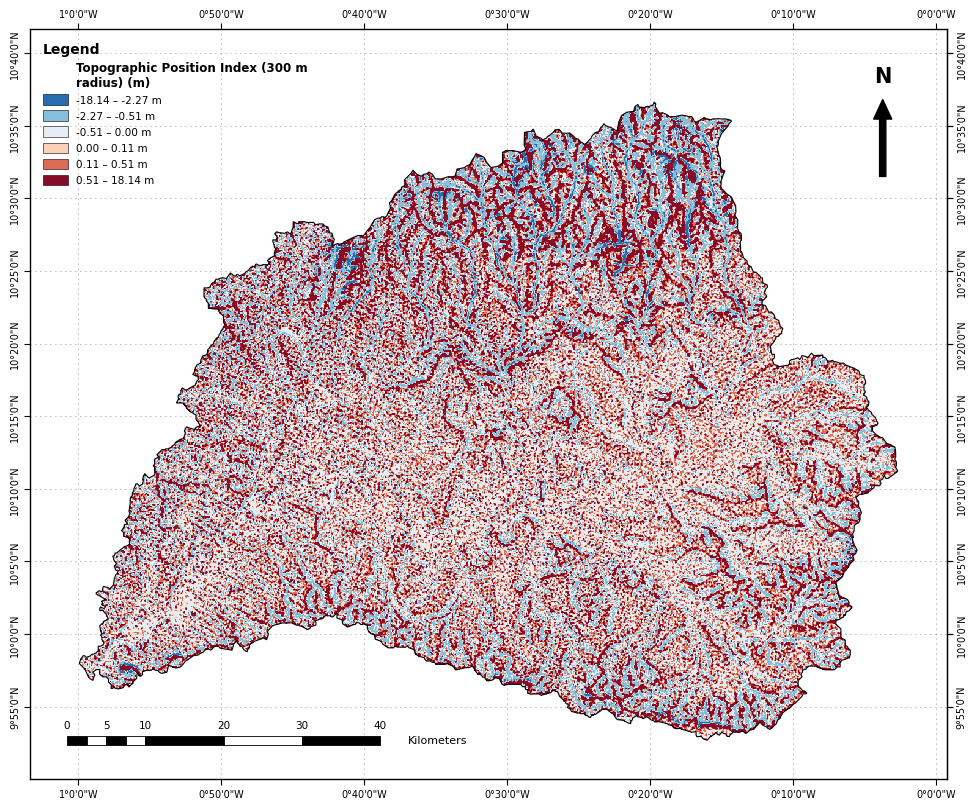


  SANITY VERDICT, BLOCK A6: all checks passed.
  --------------------------------------------------------------------------
  DONE. TPI built.
  --------------------------------------------------------------------------


In [10]:
banner("A6", "topographic position index (TPI)")
io_note([f"the DEM chosen in BLOCK A4 ({chosen_dem})"],
        ["TPI (in memory)", "final_maps/02_factors/TPI.png"])

tpi = dem_d - focal_mean(dem_d, TPI_RADIUS_M, exclude_centre=True)
BUILT["TPI"] = tpi.astype("float32")
BUILD_INFO["TPI"] = dict(source=chosen_dem, method=f"elevation minus mean of a "
                         f"{TPI_RADIUS_M} m radius circular neighbourhood")
STATS_A["TPI"] = check_layer("A6", "TPI", tpi, "m", EXPECT["TPI"])
med = STATS_A["TPI"].get("Median", 0)
if abs(med) > 3:
    warn("A6", f"Median TPI is {med:.1f} m; it should be near zero. Check the "
               f"DEM for systematic artefacts.")
else:
    ok(f"Median TPI {med:.2f} m - centred on zero as it should be.")
save_map(tpi, f"Topographic Position Index ({TPI_RADIUS_M} m radius)",
         DIR_MAP_FAC / "TPI.png", "m (negative = valley, positive = ridge)",
         MAP_STYLE["TPI"], diverging=True)
verdict("A6")
done("TPI built.")

## BLOCK A7  |  LINEAMENTS: DENSITY AND DISTANCE

 INPUTS   : Nasia_Lineaments.shp  
 OUTPUTS  : LineamentDens and DistLineament on the master grid  
            final_maps/02_factors/LineamentDens.png, DistLineament.png  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Lineament density is now computed here, from the line file, rather than  
 being supplied ready-made. That way the method is fixed and stated:  
  
    LINEAMENT DENSITY: every line is cut into short pieces, each piece's  
    length is added to the pixel it lies in, and a circular moving window of  
    radius LINEAMENT_RADIUS_M sums that length and divides by the window  
    area. Units: km of lineament per km2 - the same quantity as ArcGIS  
    "Line Density" or the QGIS equivalent.  
  
    DISTANCE TO LINEAMENT: straight-line distance from every pixel to the  
    nearest lineament, in metres. There is NO search radius - this fixes the  
    "50 km radius" problem in the draft, because every pixel simply gets its  
    true distance.  
  
 SANITY CHECKS: the file holds lines (not polygons or points); they fall in  
 the basin; how many there are and how long; and whether the density  
 window is so small that most of the basin reads zero. If it is, the block  
 suggests a radius from the data itself (the distance within which 70% of  
 the basin lies from a lineament).  


  BLOCK A7  |  LINEAMENTS: DENSITY AND DISTANCE
  READS :
      Nasia_Lineaments.shp
  WRITES:
      LineamentDens, DistLineament (in memory)
      final_maps/02_factors/LineamentDens.png, DistLineament.png

  [ OK ]   Lineaments: in WGS 84 (EPSG:4326) (geographic). It will be
  projected to UTM 30N.
  Lineaments          : 38 line segments
  Total length        : 606.5 km (606.5 km inside the basin)
  Segment length      : median 13,359 m, range 511 - 66,993 m
  Basin-wide density  : 0.114 km/km2

  [ OK ]   38 lineament segments, 607 km within the basin.
  [ OK ]   Lineament density window set automatically to 3750 m: 70% of the
  basin lies within that distance of a mapped lineament.
  [ OK ]   29% of the basin has zero density with a 3750 m window -
  acceptable.
  [ OK ]   LineamentDens: covers 100.0% of the basin.
  [ OK ]   LineamentDens: 0 to 0.2698 km/km2 (5th-95th percentile), within
  the plausible 0 to 10.
  [ OK ]   DistLineament: covers 100.0% of the basin.
  [ OK ]   Di

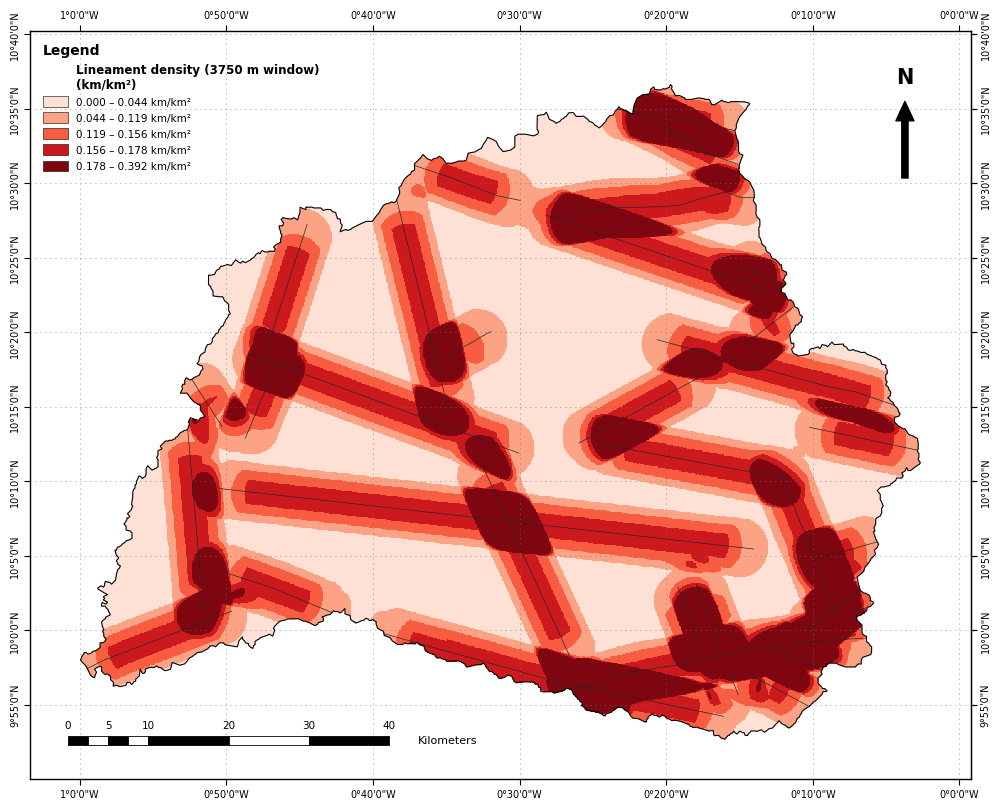

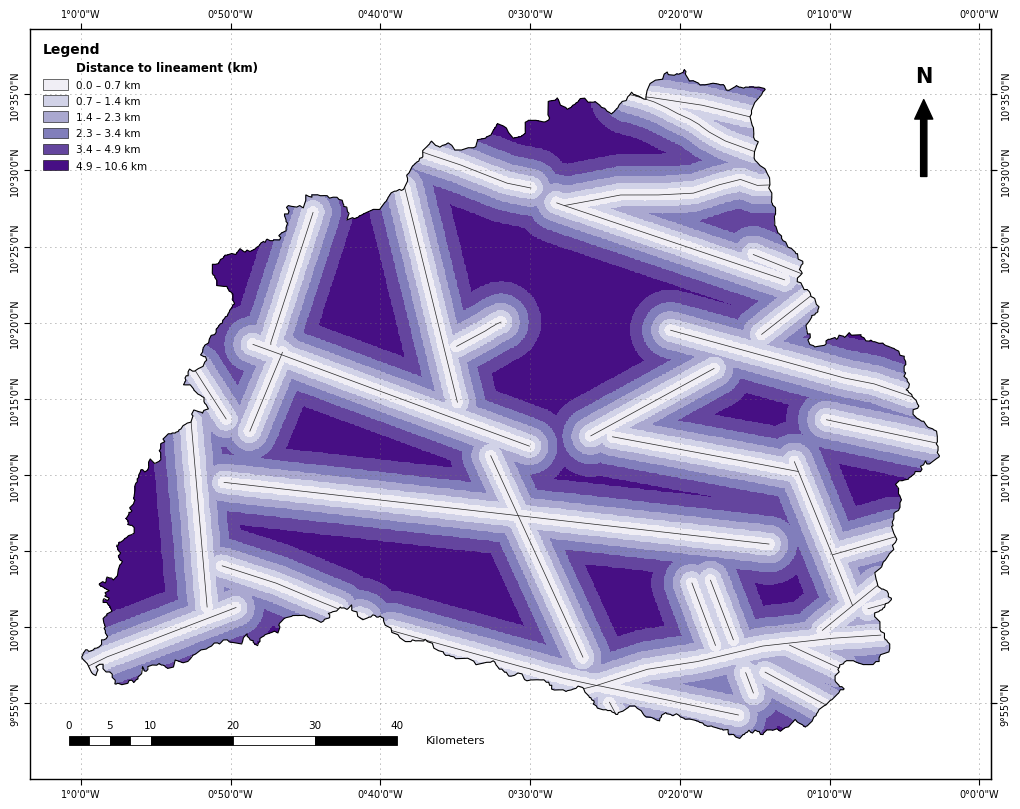


  SANITY VERDICT, BLOCK A7: all checks passed.
  --------------------------------------------------------------------------
  DONE. Lineament factors built.
  --------------------------------------------------------------------------


In [11]:
banner("A7", "lineaments: density and distance")
io_note([FOUND["lineaments"][0].name if FOUND.get("lineaments") else "(not found)"],
        ["LineamentDens, DistLineament (in memory)",
         "final_maps/02_factors/LineamentDens.png, DistLineament.png"])

LINEAMENTS_UTM = None
if not FOUND.get("lineaments"):
    missing_note("A7", "lineament shapefile", RAW["lineaments"],
                 "Lineament density and distance to lineament cannot be built "
                 "and will be dropped from the model.")
else:
    lg, linfo = read_vector("A7", FOUND["lineaments"][0], "Lineaments")
    if lg is not None:
        line_like = lg.geom_type.isin(["LineString", "MultiLineString"])
        if not line_like.all():
            bad("A7", f"{int((~line_like).sum())} lineament features are "
                      f"{sorted(set(lg.geom_type[~line_like]))}, not lines; "
                      f"they are ignored.")
        lg = lg[line_like].explode(index_parts=False)
        lg = lg[lg.length > 0]
        LINEAMENTS_UTM = lg
        lens = lg.length.values
        inside_km = lg.clip(BASIN_UTM).length.sum() / 1000
        print(f"  Lineaments          : {len(lg):,} line segments")
        print(f"  Total length        : {lens.sum()/1000:,.1f} km "
              f"({inside_km:,.1f} km inside the basin)")
        print(f"  Segment length      : median {np.median(lens):,.0f} m, "
              f"range {lens.min():,.0f} - {lens.max():,.0f} m")
        print(f"  Basin-wide density  : {inside_km / (BASIN_MASK.sum()*PIX_KM2):.3f} km/km2")
        print()
        if inside_km == 0:
            bad("A7", "No lineament lies inside the basin - a CRS problem with "
                      "Nasia_Lineaments.shp.")
        elif len(lg) < 30:
            warn("A7", f"Only {len(lg)} lineament segments. The density surface "
                       f"will be dominated by a few lines; state in the methods "
                       f"how lineaments were mapped (imagery? aeromagnetics?) "
                       f"and at what scale.")
        else:
            ok(f"{len(lg):,} lineament segments, {inside_km:,.0f} km within "
               f"the basin.")
        if np.median(lens) < 2 * PIXEL_M:
            warn("A7", "Many lineaments are shorter than two pixels - check for "
                       "digitising fragments.")

        # density
        L = np.zeros(GRID_SHAPE)
        for geom in lg.geometry:
            c = np.asarray(shapely.segmentize(geom, PIXEL_M / 2).coords)[:, :2]
            if len(c) < 2:
                continue
            mid, ln = (c[1:] + c[:-1]) / 2, np.hypot(*(c[1:] - c[:-1]).T)
            cc = ((mid[:, 0] - GRID_T.c) // PIXEL_M).astype(int)
            rr = ((GRID_T.f - mid[:, 1]) // PIXEL_M).astype(int)
            k = (rr >= 0) & (rr < GRID_H) & (cc >= 0) & (cc < GRID_W)
            np.add.at(L, (rr[k], cc[k]), ln[k])
        # distance (first: it sets the automatic density window)
        lr = rasterize(((g, 1) for g in lg.geometry), out_shape=GRID_SHAPE,
                       transform=GRID_T, all_touched=True, dtype="uint8").astype(bool)
        ldist = ndimage.distance_transform_edt(~lr) * PIXEL_M
        if str(LINEAMENT_RADIUS_M).lower() == "auto":
            LINEAMENT_RADIUS_M = int(np.ceil(np.percentile(ldist[BASIN_MASK], 70)
                                             / 250) * 250)
            ok(f"Lineament density window set automatically to "
               f"{LINEAMENT_RADIUS_M} m: 70% of the basin lies within that "
               f"distance of a mapped lineament.")
        lsum, kcells = focal_sum(L, LINEAMENT_RADIUS_M)
        ldens = lsum / (kcells * PIXEL_M ** 2) * 1000.0     # km per km2

        zero_pct = 100 * np.mean(ldens[BASIN_MASK] < 1e-6)
        suggest = float(np.ceil(np.percentile(ldist[BASIN_MASK], 70) / 250) * 250)
        if zero_pct > 50:
            warn("A7", f"With a {LINEAMENT_RADIUS_M} m window, {zero_pct:.0f}% "
                       f"of the basin has zero lineament density, so the factor "
                       f"is mostly one class. Consider LINEAMENT_RADIUS_M = "
                       f"{suggest:.0f} (70% of the basin lies within that "
                       f"distance of a lineament) and re-run from BLOCK A7.")
        else:
            ok(f"{zero_pct:.0f}% of the basin has zero density with a "
               f"{LINEAMENT_RADIUS_M} m window - acceptable.")
        BUILT["LineamentDens"] = ldens.astype("float32")
        BUILT["DistLineament"] = ldist.astype("float32")
        BUILD_INFO["LineamentDens"] = dict(source=FOUND["lineaments"][0].name,
                                           method=f"line density, {LINEAMENT_RADIUS_M} "
                                                  f"m radius circular window, km/km2")
        BUILD_INFO["DistLineament"] = dict(source=FOUND["lineaments"][0].name,
                                           method="Euclidean distance to nearest "
                                                  "lineament, no search radius")
        STATS_A["LineamentDens"] = check_layer("A7", "LineamentDens", ldens,
                                               "km/km2", EXPECT["LineamentDens"])
        STATS_A["DistLineament"] = check_layer("A7", "DistLineament", ldist, "m",
                                               EXPECT["DistLineament"])
        mx = STATS_A["DistLineament"].get("Max", 0)
        if mx > 15000:
            warn("A7", f"Some of the basin lies {mx/1000:.0f} km from any "
                       f"lineament - parts of the basin may simply not have "
                       f"been mapped. Check the lineament map's coverage.")
        lin_in = lg.clip(BASIN_UTM)
        save_map(ldens, f"Lineament density ({LINEAMENT_RADIUS_M} m window)",
                 DIR_MAP_FAC / "LineamentDens.png", "km / km2",
                 MAP_STYLE["LineamentDens"], lines=lin_in)
        save_map(ldist, "Distance to lineament", DIR_MAP_FAC / "DistLineament.png",
                 "m", MAP_STYLE["DistLineament"], lines=lin_in)
verdict("A7")
done("Lineament factors built." if "LineamentDens" in BUILT else
     "Lineament factors could not be built - see above.")

## BLOCK A8  |  RAINFALL: TESTING EVERY SOURCE AND CHOOSING THE BEST

 INPUTS   : every rainfall candidate in RAW["rainfall"]:  
              Annual_Rainfall.tif (2025), Nasia_annual_precipitation.tif  
              (2022), Rainfall.shp and Meteo_Stations.shp (station points),  
              Nasia_annual_precipitation.shp (2022)  
 OUTPUTS  : Rainfall on the master grid; final_maps/02_factors/Rainfall.png  
            tables/table_S0d_rainfall_candidates.csv  
 RUNTIME  : under a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 You have five possible rainfall sources. Each is turned into a surface on  
 the master grid - rasters are reprojected; station points are interpolated  
 by inverse-distance weighting; polygons are rasterised - and all are  
 judged by the same rules:  
  
   1. COVERAGE: does it cover at least 95% of the basin?  
   2. UNITS: is the basin median plausible for ANNUAL rainfall in the  
      Guinea Savannah (500-2000 mm)? A median of 3 suggests mm/day; 90  
      suggests mm/month. Those are rejected, not guessed at.  
   3. NOT FLAT: does it vary by at least RAIN_MIN_RANGE_MM across the  
      basin? A surface that barely changes cannot discriminate between  
      boreholes and only dilutes the Frequency Ratio.  
   4. DETAIL: among the surfaces passing 1-3, prefer the one with real  
      spatial detail (many distinct values, finest native resolution),  
      then the most recent.  
  
 The reasons are printed, so the choice can be stated in the methods. If  
 even the best surface is flat, Rainfall is dropped from the model - as the  
 conditioning-factor recommendation advises - and the reason recorded. Set  
 RAIN_MIN_RANGE_MM = 0 in BLOCK 1 to keep it regardless.  


  BLOCK A8  |  RAINFALL: TESTING EVERY SOURCE AND CHOOSING THE BEST
  READS :
      Annual_Rainfall (2026_02_04 11_34_54 UTC).tif
      Nasia_annual_precipitation.tif
      Rainfall (2026_02_04 11_34_54 UTC).shp
      Meteo_Stations (2026_02_04 11_34_54 UTC).shp
      Nasia_annual_precipitation.shp
  WRITES:
      Rainfall (in memory)
      final_maps/02_factors/Rainfall.png
      tables/table_S0d_rainfall_candidates.csv

  [note]   'Annual_Rainfall.tif': 20,591 empty pixels inside the basin
  (empty rows/columns in the source) filled by inverse-distance
  interpolation from neighbouring pixels.
  [note]   'Nasia_annual_precipitation.tif': 16,083 empty pixels inside the
  basin (empty rows/columns in the source) filled by inverse-distance
  interpolation from neighbouring pixels.
  [ OK ]   Rainfall 'Rainfall.shp': in WGS 84 (EPSG:4326) (geographic). It
  will be projected to UTM 30N.
  [WARN]   'Rainfall.shp': no attribute looks like annual rainfall (numeric
  columns: ['OID_', 'Near

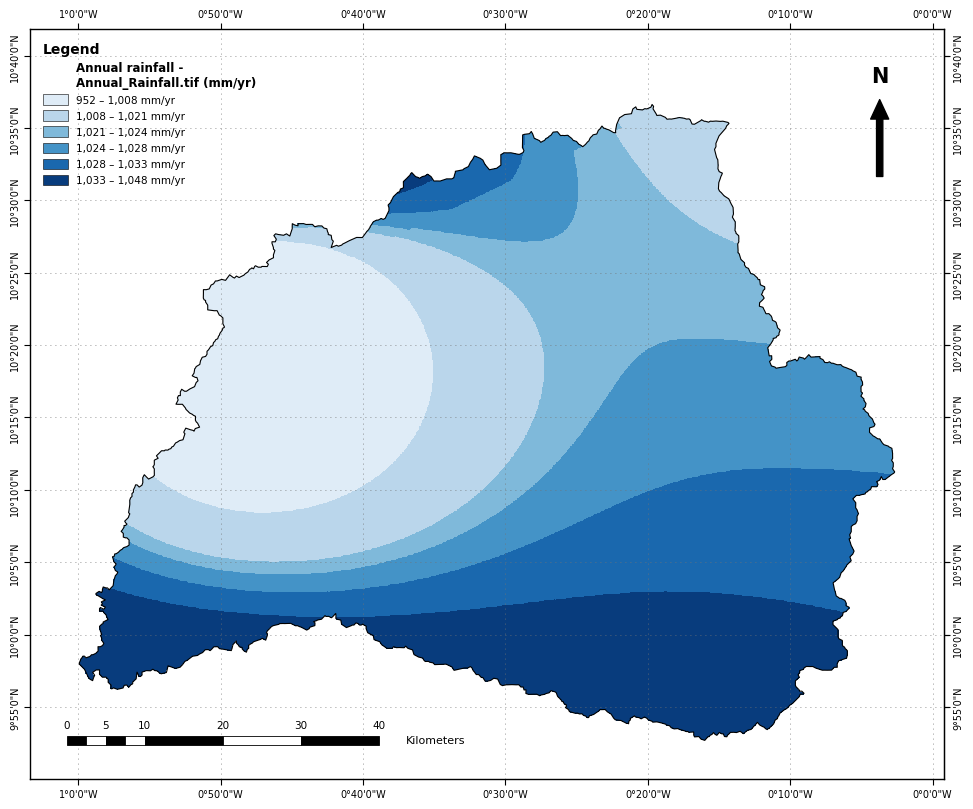


  SANITY VERDICT, BLOCK A8: usable, with 3 warning(s) to read.
  --------------------------------------------------------------------------
  DONE. Rainfall source chosen.
  --------------------------------------------------------------------------


In [12]:
banner("A8", "rainfall: testing every source and choosing the best")
io_note([p.name for p in FOUND.get("rainfall", [])] or ["(no rainfall file found)"],
        ["Rainfall (in memory)", "final_maps/02_factors/Rainfall.png",
         "tables/table_S0d_rainfall_candidates.csv"])

_RAIN_HINT = ("rain", "precip", "annual", "ann", "mm", "mean", "total", "map")
_NOT_RAIN = ("id", "fid", "objectid", "x", "y", "lat", "lon", "long", "east",
             "north", "elev", "alt", "height", "code", "year", "yr", "z",
             "shape_len", "shape_area", "area", "perimeter")


def pick_rain_field(g):
    num = [c for c in g.columns if c != "geometry"
           and pd.api.types.is_numeric_dtype(g[c])
           and c.lower() not in _NOT_RAIN]
    good = []
    for c in num:
        v = pd.to_numeric(g[c], errors="coerce").dropna()
        if len(v) and 300 <= v.median() <= 3000:
            good.append((any(h in c.lower() for h in _RAIN_HINT), v.std(), c))
    if good:
        return sorted(good, reverse=True)[0][2], num
    return None, num


def idw_to_grid(x, y, val, power=2.0):
    gx = GRID_T.c + (np.arange(GRID_W) + 0.5) * PIXEL_M
    out = np.empty(GRID_SHAPE, dtype="float32")
    for r0 in range(0, GRID_H, 150):
        r1 = min(r0 + 150, GRID_H)
        gy = GRID_T.f - (np.arange(r0, r1) + 0.5) * PIXEL_M
        XX, YY = np.meshgrid(gx, gy)
        d = np.hypot(XX[..., None] - x, YY[..., None] - y)
        w = 1.0 / np.maximum(d, 1.0) ** power
        out[r0:r1] = (w * val).sum(-1) / w.sum(-1)
    return out


rain_rows, rain_arrays, rain_points = [], {}, {}
for p in FOUND.get("rainfall", []):
    label = re.sub(_UTC, "", p.name).strip()
    mtime = datetime.datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d")
    row = dict(Candidate=label, File=p.name, Modified=mtime)
    if p.suffix.lower() in (".tif", ".tiff"):
        a, info = warp_to_grid("A8", p, f"Rainfall '{label}'")
        if a is None:
            continue
        _gap = BASIN_MASK & ~np.isfinite(a)
        if _gap.any() and _gap.sum() < 0.2 * BASIN_MASK.sum():
            from rasterio.fill import fillnodata
            _ok = np.isfinite(a)
            _f = fillnodata(np.where(_ok, a, 0).astype("float32"),
                            mask=_ok.astype("uint8"), max_search_distance=200,
                            smoothing_iterations=0)
            a = np.where(_ok, a, np.where(BASIN_MASK, _f, np.nan)).astype("float32")
            row["Gaps_filled_px"] = int(_gap.sum() - (BASIN_MASK & ~np.isfinite(a)).sum())
            note(f"'{label}': {row['Gaps_filled_px']:,} empty pixels inside the basin "
                 f"(empty rows/columns in the source) filled by inverse-distance "
                 f"interpolation from neighbouring pixels.")
        row.update(Type="raster", CRS=info["crs"], Native_m=info["native_m"],
                   Field="band 1")
    else:
        g, ginfo = read_vector("A8", p, f"Rainfall '{label}'")
        if g is None:
            continue
        fld, numcols = pick_rain_field(g)
        if fld is None:
            warn("A8", f"'{label}': no attribute looks like annual rainfall "
                       f"(numeric columns: {numcols or 'none'}). Skipped.")
            continue
        vals = pd.to_numeric(g[fld], errors="coerce")
        g = g[vals.notna()]
        vals = vals[vals.notna()].values.astype(float)
        types = set(g.geom_type)
        if types <= {"Point", "MultiPoint"}:
            pts = g.geometry.centroid
            near = pts.distance(BASIN_UTM.geometry.iloc[0]) < 50_000
            n_in = int(pts.within(BASIN_UTM.geometry.iloc[0]).sum())
            if len(g) < 3:
                warn("A8", f"'{label}': only {len(g)} stations - too few to "
                           f"interpolate. Skipped.")
                continue
            a = idw_to_grid(pts.x.values, pts.y.values, vals)
            spacing = np.sqrt(g.union_all().convex_hull.area / max(len(g), 1))
            row.update(Type=f"{len(g)} stations -> IDW", CRS=ginfo["crs"],
                       Native_m=round(spacing, 0), Field=fld,
                       Stations_in_basin=n_in,
                       Stations_within_50km=int(near.sum()))
            rain_points[label] = (pts.x.values, pts.y.values)
            if near.sum() < 5:
                warn("A8", f"'{label}': only {int(near.sum())} stations within "
                           f"50 km of the basin; the interpolated surface rests "
                           f"on very few points.")
        else:
            a = rasterize(((geom, float(v)) for geom, v in zip(g.geometry, vals)),
                          out_shape=GRID_SHAPE, transform=GRID_T, fill=np.nan,
                          dtype="float32")
            mean_area = g.area.mean()
            row.update(Type=f"{len(g)} polygons", CRS=ginfo["crs"],
                       Native_m=round(np.sqrt(mean_area), 0), Field=fld)
    v = basin_values(a)
    cov = 100 * v.size / BASIN_MASK.sum()
    row.update(Coverage_pct=round(cov, 1))
    if v.size:
        med = float(np.median(v))
        rng = float(np.percentile(v, 99) - np.percentile(v, 1))
        row.update(Min=round(float(v.min()), 1), Max=round(float(v.max()), 1),
                   Median=round(med, 1), Range_mm=round(rng, 1),
                   CV_pct=round(100 * float(v.std() / max(abs(v.mean()), 1e-9)), 2),
                   Distinct=int(np.unique(np.round(v[:2_000_000], 1)).size))
        lo, hi = EXPECT["Rainfall"]
        if lo <= med <= hi:
            unit_note = "annual mm - plausible"
        elif 1 <= med <= 10:
            unit_note = "looks like mm/DAY"
        elif 25 <= med <= 250:
            unit_note = "looks like mm/MONTH"
        else:
            unit_note = "implausible for annual rainfall"
        row["Units_check"] = unit_note
        row["Plausible"] = lo <= med <= hi
        row["Flat"] = rng < RAIN_MIN_RANGE_MM
    else:
        row.update(Plausible=False, Flat=True, Units_check="no values in basin")
    rain_rows.append(row)
    rain_arrays[label] = a

rain_tab = pd.DataFrame(rain_rows)
if rain_tab.empty:
    missing_note("A8", "a usable rainfall source", str(RAW["rainfall"]),
                 "Rainfall will be dropped from the model.")
else:
    cols = [c for c in ("Candidate", "Type", "Native_m", "Coverage_pct", "Median",
                        "Range_mm", "CV_pct", "Distinct", "Units_check", "Modified")
            if c in rain_tab]
    print(rain_tab[cols].to_string(index=False))
    print()
    if RAINFALL_CHOICE != "auto":
        pick = next((c for c in rain_tab.Candidate
                     if c.lower().startswith(Path(RAINFALL_CHOICE).stem.lower())), None)
        why = "chosen by you in BLOCK 1 (RAINFALL_CHOICE)"
    else:
        t = rain_tab.copy()
        t["eligible"] = (t.Coverage_pct >= 95) & t.Plausible
        t["notflat"] = ~t.Flat.astype(bool)
        t["detailed"] = t.get("Distinct", 0) >= 50
        t = t.sort_values(["eligible", "notflat", "detailed", "Native_m", "Modified"],
                          ascending=[False, False, False, True, False])
        r0 = t.iloc[0]
        pick = r0.Candidate if r0.eligible else None
        why = (f"it covers {r0.Coverage_pct:.0f}% of the basin, its median of "
               f"{r0.get('Median', np.nan):.0f} mm is plausible annual rainfall, it "
               f"varies by {r0.get('Range_mm', np.nan):.0f} mm across the basin, "
               f"and it has the most spatial detail of the eligible sources"
               if r0.eligible else "")
        for _, rr in t.iloc[1:].iterrows():
            reasons = []
            if rr.Coverage_pct < 95:
                reasons.append(f"covers {rr.Coverage_pct:.0f}% of the basin")
            if not rr.Plausible:
                reasons.append(rr.get("Units_check", "implausible values"))
            if rr.Flat:
                reasons.append(f"nearly flat ({rr.get('Range_mm', 0):.0f} mm range)")
            if not reasons:
                reasons.append("less spatial detail or older than the chosen one")
            print(f"  Not chosen: {rr.Candidate:<35s} - {'; '.join(reasons)}")
    if pick is None:
        bad("A8", "No rainfall candidate passed the coverage and unit checks. "
                  "Rainfall is dropped from the model.")
    else:
        print(f"\n  CHOSEN: {pick} - {why}.\n")
        rain = rain_arrays[pick].astype("float32")
        rrow = rain_tab[rain_tab.Candidate == pick].iloc[0]
        STATS_A["Rainfall"] = check_layer("A8", "Rainfall", rain, "mm/yr",
                                          EXPECT["Rainfall"])
        if rrow.Flat:
            bad("A8", f"Rainfall varies by only {rrow.Range_mm:.0f} mm across "
                      f"the basin (threshold {RAIN_MIN_RANGE_MM} mm). It is "
                      f"dropped from the model as a flat factor. Methods "
                      f"sentence: 'Rainfall was excluded because its range "
                      f"across the sub-basin ({rrow.Range_mm:.0f} mm) was too "
                      f"small to discriminate between borehole sites.'")
        else:
            BUILT["Rainfall"] = rain
            BUILD_INFO["Rainfall"] = dict(source=rrow.File, method=f"{rrow.Type}; "
                                          f"{why}")
        pts = []
        if pick in rain_points:
            px, py = rain_points[pick]
            pts = [(px, py, dict(s=22, c="k", marker="^", label="Station"))]
        save_map(rain, f"Annual rainfall - {pick}", DIR_MAP_FAC / "Rainfall.png",
                 "mm / year", MAP_STYLE["Rainfall"], points=pts)
    rain_tab.to_csv(DIR_TAB / "table_S0d_rainfall_candidates.csv", index=False)
verdict("A8")
done("Rainfall source chosen." if "Rainfall" in BUILT else
     "Rainfall not carried into the model - see above.")

## BLOCK A9  |  LITHOLOGY, SOIL AND LAND USE (CATEGORICAL MAPS)

 INPUTS   : Nasia_Geology.shp (or Nasia_Geology.tif)  
            Soil.tif / Nasia_soils_PolygonToRaster.tif (+ their .vat.dbf)  
            landuse.tif (+ landuse.tif.vat.dbf)  
 OUTPUTS  : Lithology, SoilType, LULC on the master grid  
            tables/table_S0e_class_legends.csv  (code -> class name)  
            final_maps/02_factors/Lithology.png, SoilType.png, LULC.png  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 These three maps hold CLASSES, not quantities, so two rules apply:  
 resampling is always nearest-neighbour (averaging a "luvisol" code with a  
 "lixisol" code produces nonsense), and each class keeps its name, so the  
 Frequency Ratio table can say "Luvisols, FR = 1.8" rather than "class 3".  
  
 LITHOLOGY comes from the geology shapefile, rasterised by the attribute  
 that names the formation. The block lists every text attribute with its  
 values so you can confirm the right one was used (or set GEOLOGY_FIELD).  
 The recommendation is FORMATION level (Kwahu-Bombouaka vs Oti-Pendjari  
 members); with only two classes the factor discriminates very little.  
  
 SOIL: of the two soil rasters, the one covering more of the basin wins,  
 then the newer. The class names live in a separate .vat.dbf file. Google  
 Drive renamed it ("Soil.tif.vat (2026_02_04 ... UTC).dbf"), so GIS software  
 will no longer find it automatically - this block reads it directly.  
  
 LAND USE: landuse.tif is only 10 KB, which means it is coarse. Its native  
 pixel size and date are reported; a reviewer will ask for both, and for  
 the classification accuracy.  
  
 SANITY CHECKS: whole-number codes only (a smoothed categorical map is  
 caught), a sensible number of classes, coverage, and classes smaller than  
 1% of the basin (which give unstable Frequency Ratios).  


  BLOCK A9  |  LITHOLOGY, SOIL AND LAND USE (CATEGORICAL MAPS)
  READS :
      Nasia_Geology.shp
      Nasia_Geology.tif
      Soil (2026_02_04 11_34_54 UTC).tif
      Nasia_soils_PolygonToRaster.tif
      landuse.tif
  WRITES:
      Lithology, SoilType, LULC (in memory)
      tables/table_S0e_class_legends.csv
      final_maps/02_factors/Lithology.png, SoilType.png, LULC.png

  ---- Lithology
  [ OK ]   Geology: already in WGS 84 / UTM zone 30N (EPSG:32630).
  Text attributes in the geology file:
      GEO_SYMBOL       5 values: vby, vpn, vdg, vdb, vba
      Stratigrap       2 values: Voltaian Supergroup, Oti-Pendjari Group, Voltaian Supergroup, Kwahu-'Morago' Group
      Strati_For       5 values: Bunya Formation, Panabako Sandstone Formation, Damongo Formation, Kodjari Formation, Bimbila Formation
      TECTONIC_D       0 values: 
      SUB_DOMAIN       0 values: 
      Metamorpho       0 values: 
      Legend_Tex       5 values: Sandstone, medium grained, arkosic, lithic, weakly m

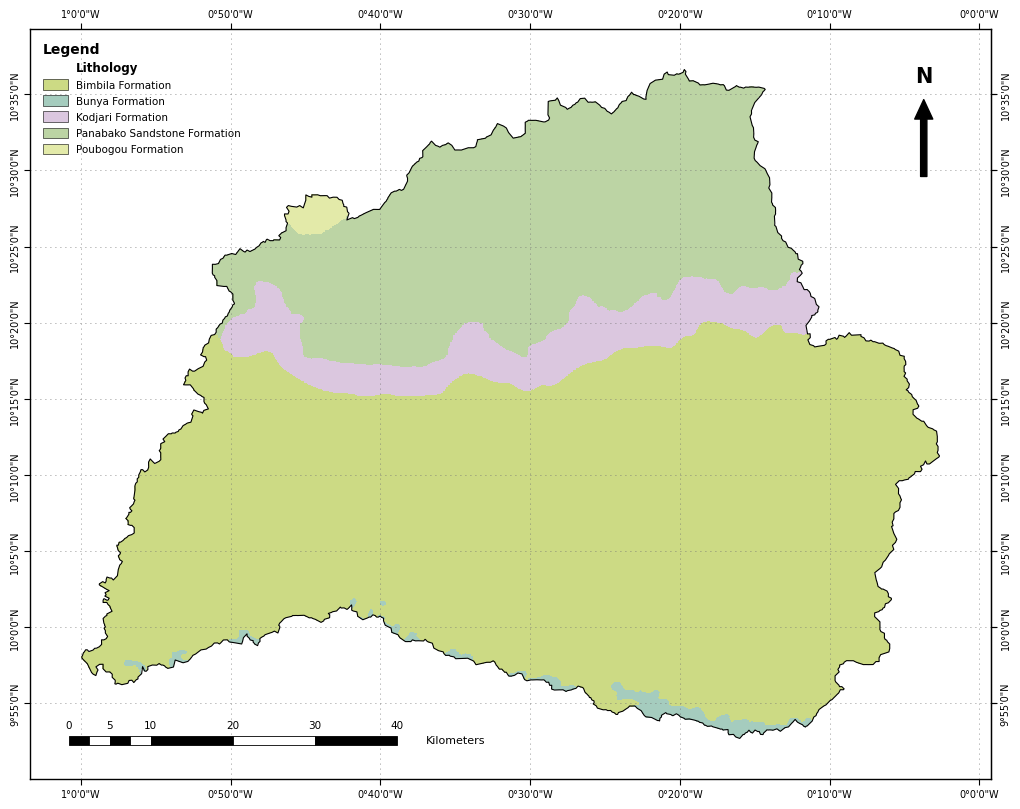


  ---- Soil
                              file                                    crs  native_m  Coverage_pct  Classes  NonInteger_pct   modified
Soil (2026_02_04 11_34_54 UTC).tif Leigon / Ghana Metre Grid (EPSG:25000)      30.0          99.4       12             0.0 2026-01-03
   Nasia_soils_PolygonToRaster.tif Leigon / Ghana Metre Grid (EPSG:25000)     300.0          99.7        6             0.0 2022-06-15

  Chosen: Soil (2026_02_04 11_34_54 UTC).tif (classes valid: True, coverage 99.4%, modified 2026-01-03).
  [ OK ]   Soil: class names read from 'Soil.tif.vat (2026_02_04 11_34_54
  UTC).dbf' (renamed by Google Drive, so GIS will not link it automatically
  - read directly here).
  [ OK ]   SoilType: every class has a name.
  [ OK ]   SoilType: covers 99.4% of the basin.
  [ OK ]   SoilType: 10 classes inside the basin.
  [WARN]   SoilType: 4 class(es) cover less than 1% of the basin (Eutric
  fluvisols 0.05%, Lithic Leptosols 0.00%, Gleyic Lixisols 0.34%, Eutric
  Gleysols 0.07

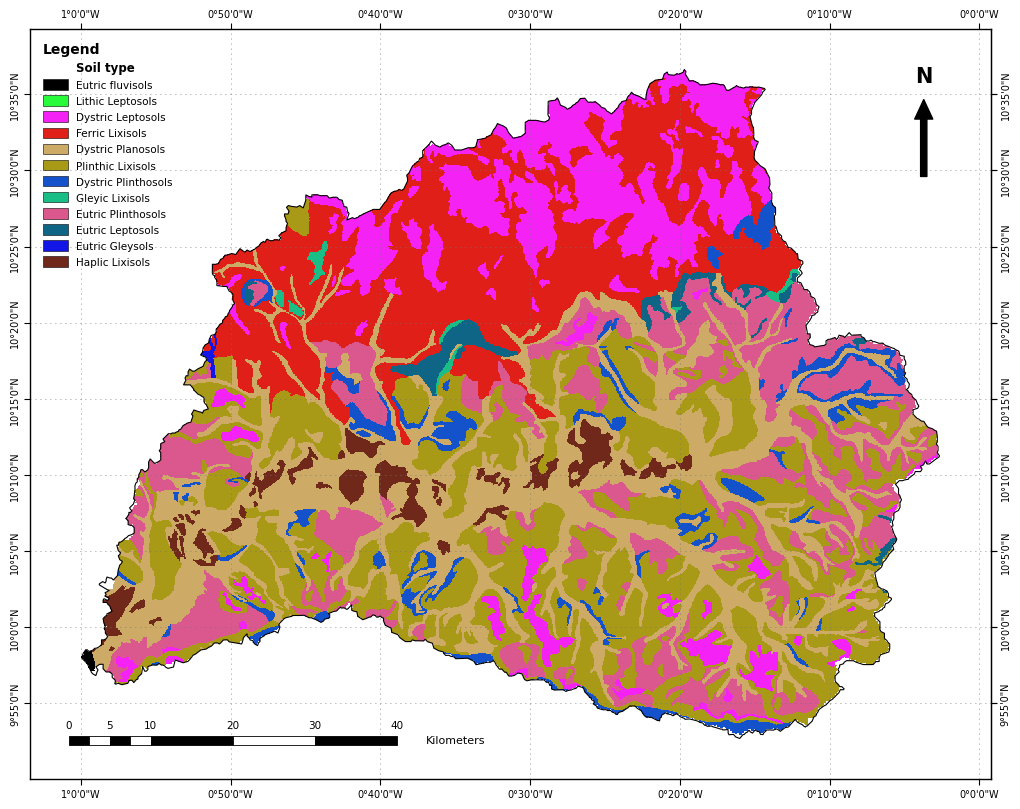


  ---- Land use
       file                                    crs  native_m  Coverage_pct  Classes  NonInteger_pct   modified
landuse.tif Leigon / Ghana Metre Grid (EPSG:25000)     300.0          99.3        9             0.0 2022-06-15
  [ OK ]   Land use: class names read from 'landuse.tif.vat.dbf'.
  [ OK ]   LULC: every class has a name.
  [ OK ]   LULC: covers 99.3% of the basin.
  [ OK ]   LULC: 6 classes inside the basin.
  [WARN]   Land use: native pixel ~300 m, much coarser than the 30 m grid.
  State this in Table 1; a 10 m product such as ESA WorldCover would be a
  stronger LULC layer.
  [WARN]   LULC: 3 class(es) cover less than 1% of the basin (Grass/herb
  with/without scattered trees (0-5 trees/ha) 0.36%, Riverine savanna
  vegetation 0.93%, Closed savanna woodland (>25 trees/ha) 0.79%). Their
  Frequency Ratios will be unstable - consider merging.

  LULC - share of basin by class:
         2   68.12%  Open cultivated savanna woodland (11-20 trees/ha)
         5   13

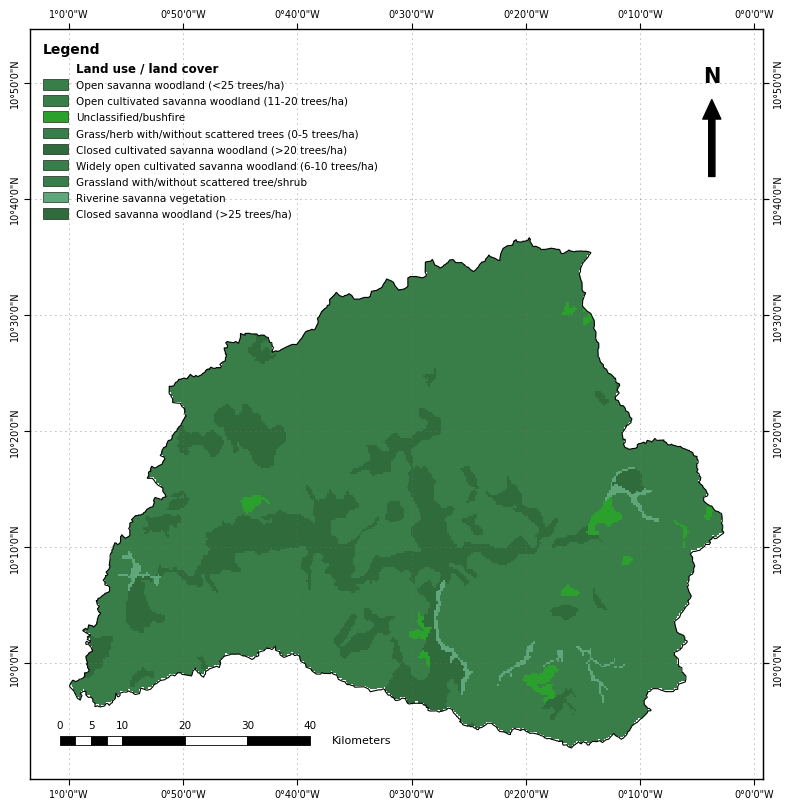


  SANITY VERDICT, BLOCK A9: usable, but 1 item(s) are missing (listed again in BLOCK 19); 4 warning(s).
  --------------------------------------------------------------------------
  DONE. Categorical factors built: Lithology, SoilType, LULC
  --------------------------------------------------------------------------


In [44]:
banner("A9", "lithology, soil and land use (categorical maps)")
io_note([p.name for k in ("geology", "soil", "lulc") for p in FOUND.get(k, [])],
        ["Lithology, SoilType, LULC (in memory)",
         "tables/table_S0e_class_legends.csv",
         "final_maps/02_factors/Lithology.png, SoilType.png, LULC.png"])

_GEO_HINT = ("form", "lith", "unit", "geol", "rock", "group", "member", "name",
             "desc", "label", "type")


def small_classes(block, name, arr, legend):
    v = basin_values(arr)
    if not v.size:
        return
    codes, counts = np.unique(v, return_counts=True)
    pct = 100 * counts / v.size
    tiny = [(legend.get(int(c), int(c)) if legend else int(c), p)
            for c, p in zip(codes, pct) if p < 1.0]
    if tiny:
        warn(block, f"{name}: {len(tiny)} class(es) cover less than 1% of the "
                    f"basin ({', '.join(f'{n} {p:.2f}%' for n, p in tiny[:6])}). "
                    f"Their Frequency Ratios will be unstable - consider merging.")
    print(f"\n  {name} - share of basin by class:")
    for c, p in sorted(zip(codes, pct), key=lambda t: -t[1]):
        lbl = legend.get(int(c), "") if legend else ""
        print(f"      {int(c):>4d}  {p:6.2f}%  {lbl}")


legend_rows = []

# ---- LITHOLOGY --------------------------------------------------------------
print("  ---- Lithology")
geo_vec = [p for p in FOUND.get("geology", []) if p.suffix.lower() == ".shp"]
geo_ras = [p for p in FOUND.get("geology", []) if p.suffix.lower() in (".tif", ".tiff")]
lith = None
if geo_vec:
    gg, ginfo = read_vector("A9", geo_vec[0], "Geology")
    if gg is not None:
        txt = [c for c in gg.columns if c != "geometry" and _is_text(gg[c])]
        print("  Text attributes in the geology file:")
        for c in txt:
            u = gg[c].dropna().unique()
            print(f"      {c:<14s} {len(u):>3d} values: "
                  f"{', '.join(map(str, u[:6]))}{' ...' if len(u) > 6 else ''}")
        if GEOLOGY_FIELD != "auto" and GEOLOGY_FIELD in gg.columns:
            fld = GEOLOGY_FIELD
        else:
            scored = sorted(((2 <= gg[c].nunique() <= 30,
                              any(h in c.lower() for h in _GEO_HINT),
                              gg[c].nunique(), c) for c in txt), reverse=True)
            fld = scored[0][3] if scored and scored[0][0] else None
        if fld is None:
            bad("A9", "No text attribute in the geology file names the units. "
                      "Set GEOLOGY_FIELD in BLOCK 1.")
        else:
            if GEOLOGY_RENAME:
                for old_, new_ in GEOLOGY_RENAME.items():
                    n_ = int((gg[fld].astype(str) == old_).sum())
                    if n_:
                        print(f"  Renamed '{old_}' -> '{new_}' ({n_} polygon(s)), "
                              f"as set in GEOLOGY_RENAME (BLOCK 1).")
                gg[fld] = gg[fld].replace(GEOLOGY_RENAME)
            names = sorted(gg[fld].dropna().astype(str).unique())
            code = {n: i + 1 for i, n in enumerate(names)}
            lith = rasterize(((geom, code[str(v)]) for geom, v in
                              zip(gg.geometry, gg[fld]) if pd.notna(v)),
                             out_shape=GRID_SHAPE, transform=GRID_T, fill=0,
                             dtype="int32").astype("float32")
            lith[lith == 0] = np.nan
            LEGENDS["Lithology"] = {i: n for n, i in code.items()}
            BUILD_INFO["Lithology"] = dict(source=geo_vec[0].name,
                                           method=f"polygons rasterised by "
                                                  f"attribute '{fld}' at 30 m")
            print(f"\n  Using attribute '{fld}' ({len(names)} units). Set "
                  f"GEOLOGY_FIELD in BLOCK 1 if this is the wrong one.")
if lith is None and geo_ras:
    lith, _ = warp_to_grid("A9", geo_ras[0], "Geology raster", categorical=True)
    lg_, vat = legend_from_vat(geo_ras[0])
    LEGENDS["Lithology"] = lg_ or {}
    BUILD_INFO["Lithology"] = dict(source=geo_ras[0].name,
                                   method="raster, nearest-neighbour resampling")
if lith is not None:
    LEGENDS["Lithology"] = apply_names("A9", "Lithology", LEGENDS.get("Lithology"),
                                       np.unique(basin_values(lith)))
    STATS_A["Lithology"] = check_layer("A9", "Lithology", lith, "class",
                                       kind="categorical")
    k_in = STATS_A["Lithology"].get("Distinct", 0)
    if k_in <= 2:
        warn("A9", f"Lithology has only {k_in} class(es) in the basin - that is "
                   f"GROUP level. Rasterise at FORMATION level (Kwahu-Bombouaka "
                   f"vs Oti-Pendjari members) for a factor that discriminates.")
    small_classes("A9", "Lithology", lith, LEGENDS.get("Lithology"))
    BUILT["Lithology"] = lith
    save_map(lith, "Lithology", DIR_MAP_FAC / "Lithology.png", "Formation",
             legend=LEGENDS.get("Lithology") or {int(c): str(int(c)) for c in
                                                 np.unique(basin_values(lith))})
else:
    missing_note("A9", "geology map", str(RAW["geology"]),
                 "Lithology cannot be built and is dropped from the model.")


def best_categorical(block, key, label):
    rows, arrs = [], {}
    for p in FOUND.get(key, []):
        a, info = warp_to_grid(block, p, f"{label} '{p.name}'", categorical=True)
        if a is None:
            continue
        v = basin_values(a)
        nonint = float(np.mean(np.abs(v - np.round(v)) > 1e-6)) if v.size else 1
        rows.append(dict(info, Coverage_pct=round(100 * v.size / BASIN_MASK.sum(), 1),
                         Classes=int(np.unique(v).size) if v.size else 0,
                         NonInteger_pct=round(100 * nonint, 2)))
        arrs[p.name] = (a, p)
    if not rows:
        return None, None, None
    t = pd.DataFrame(rows)
    print(t[["file", "crs", "native_m", "Coverage_pct", "Classes",
             "NonInteger_pct", "modified"]].to_string(index=False))
    t["ok_classes"] = t.Classes.between(2, 40) & (t.NonInteger_pct < 0.1)
    t["full"] = t.Coverage_pct >= 99
    t["named"] = [legend_from_vat(arrs[f_][1])[0] is not None for f_ in t.file]
    t = t.sort_values(["ok_classes", "full", "named", "modified"],
                      ascending=[False, False, False, False])
    _want = CATEGORICAL_CHOICE.get(key, "auto")
    if _want != "auto":
        _hit = t[t.file.str.lower().str.startswith(Path(_want).stem.lower())]
        if len(_hit):
            t = pd.concat([_hit, t.drop(_hit.index)])
        else:
            warn(block, f"{label}: CATEGORICAL_CHOICE asks for '{_want}', which was "
                        f"not found among {list(t.file)}; using the automatic choice.")
    best = t.iloc[0]
    if len(t) > 1:
        print(f"\n  Chosen: {best.file} (classes valid: {bool(best.ok_classes)}, "
              f"coverage {best.Coverage_pct}%, modified {best.modified}).")
    a, p = arrs[best.file]
    return a, p, best


for key, fname, label, unit in (("soil", "SoilType", "Soil", "Soil class"),
                                ("lulc", "LULC", "Land use", "Land use / cover")):
    print(f"\n  ---- {label}")
    a, p, info = best_categorical("A9", key, label)
    if a is None:
        missing_note("A9", f"{label} raster", str(RAW[key]),
                     f"{fname} cannot be built and is dropped from the model.")
        continue
    lg_, vat = legend_from_vat(p)
    if lg_:
        ok(f"{label}: class names read from '{vat.name}'"
           + (" (renamed by Google Drive, so GIS will not link it "
              "automatically - read directly here)." if "UTC" in vat.name else "."))
    elif vat is not None:
        note(f"{label}: the attribute table '{vat.name}' holds only "
             f"{VAT_COLUMNS.get(str(vat), [])} - codes, no class names. This is "
             f"normal for a raster made with Polygon to Raster: the names stayed "
             f"in the source shapefile.")
        lg_ = {}
    else:
        note(f"{label}: no attribute table (.vat.dbf) was found for '{p.name}'.")
        lg_ = {}
    _codes_here = {int(c) for c in np.unique(basin_values(a))}
    if fname == "LULC" and not lg_ and _codes_here and _codes_here <= set(ESRI_LULC_CODES):
        lg_ = {c: ESRI_LULC_CODES[c] for c in _codes_here}
        note("LULC: the class codes match the Esri 10 m Land Cover scheme "
             "(1 water, 2 trees, 4 flooded vegetation, 5 crops, 7 built area, "
             "8 bare ground, 11 rangeland); those names are used.")
    lg_ = apply_names("A9", fname, lg_, np.unique(basin_values(a)))
    LEGENDS[fname] = lg_
    STATS_A[fname] = check_layer("A9", fname, a, "class", kind="categorical")
    if info.native_m > 100:
        warn("A9", f"{label}: native pixel ~{info.native_m:.0f} m, much coarser "
                   f"than the 30 m grid. State this in Table 1"
                   + ("; a 10 m product such as ESA WorldCover would be a "
                      "stronger LULC layer." if key == "lulc" else "."))
    if key == "lulc":
        flag("A9", f"LULC: '{p.name}' dates from {info.modified}. The manuscript "
                   f"needs its source imagery, acquisition date, classification "
                   f"method and overall accuracy / kappa.", "MISSING")
    small_classes("A9", fname, a, lg_)
    BUILT[fname] = a
    BUILD_INFO[fname] = dict(source=p.name, method=f"nearest-neighbour "
                             f"resampling from ~{info.native_m:.0f} m")
    save_map(a, label, DIR_MAP_FAC / f"{fname}.png", unit,
             legend={**{int(c): f"class {int(c)}" for c in np.unique(basin_values(a))},
                     **{int(k): str(v) for k, v in lg_.items()}},
             layer="Soil type" if fname == "SoilType" else "Land use / land cover")

for fac, lg_ in LEGENDS.items():
    for c, n in (lg_ or {}).items():
        legend_rows.append(dict(Factor=fac, Code=c, Class=n))
pd.DataFrame(legend_rows).to_csv(DIR_TAB / "table_S0e_class_legends.csv", index=False)
verdict("A9")
done("Categorical factors built: " +
     ", ".join(k for k in ("Lithology", "SoilType", "LULC") if k in BUILT))

## BLOCK A10  |  WRITING THE FACTOR GEOTIFFS AND THE FACTOR SUMMARY

 INPUTS   : every factor built in BLOCKS A4-A9 (in memory)  
 OUTPUTS  : factors/<name>.tif   (one GeoTIFF per factor: UTM 30N, 30 m,  
                                  float32, nodata -9999, clipped to basin)  
            tables/table_S0f_factor_build_summary.csv  (source, method,  
            statistics and sanity status of each factor - the basis for  
            Table 1 of the manuscript)  
            final_maps/02_factors/00_all_factors_panel.png  
 RUNTIME  : under a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Writes each factor to disk under the names from BLOCK 1, so they can be  
 opened in QGIS and are the files BLOCK 2 onward use. Factors that could not  
 be built are switched off, with a note, rather than stopping the run.  
  
 It also makes a cross-check across factors: every layer must have data on  
 the same pixels. If one layer has a hole the others do not, those pixels  
 silently drop out of the model, so the size of the shared area is reported.  


  BLOCK A10  |  WRITING THE FACTOR GEOTIFFS AND THE FACTOR SUMMARY
  READS :
      factors built in BLOCKS A4-A9 (in memory)
  WRITES:
      factors/*.tif
      tables/table_S0f_factor_build_summary.csv
      final_maps/02_factors/00_all_factors_panel.png

    Lithology       written -> factors/lithology.tif
    LineamentDens   NOT BUILT - switched off
    DistLineament   NOT BUILT - switched off
    Elevation       NOT BUILT - switched off
    Slope           NOT BUILT - switched off
    TWI             NOT BUILT - switched off
    TPI             NOT BUILT - switched off
    DistStream      NOT BUILT - switched off
    Rainfall        NOT BUILT - switched off
    SoilType        written -> factors/soil_type.tif
    LULC            written -> factors/lulc.tif

  [ OK ]   99.1% of the basin has data in every factor.

   Factor               Units  Coverage_pct  Min  Median  Max       Sanity
Lithology integer class codes        100.00  1.0     1.0  5.0 see warnings
 SoilType integer cl

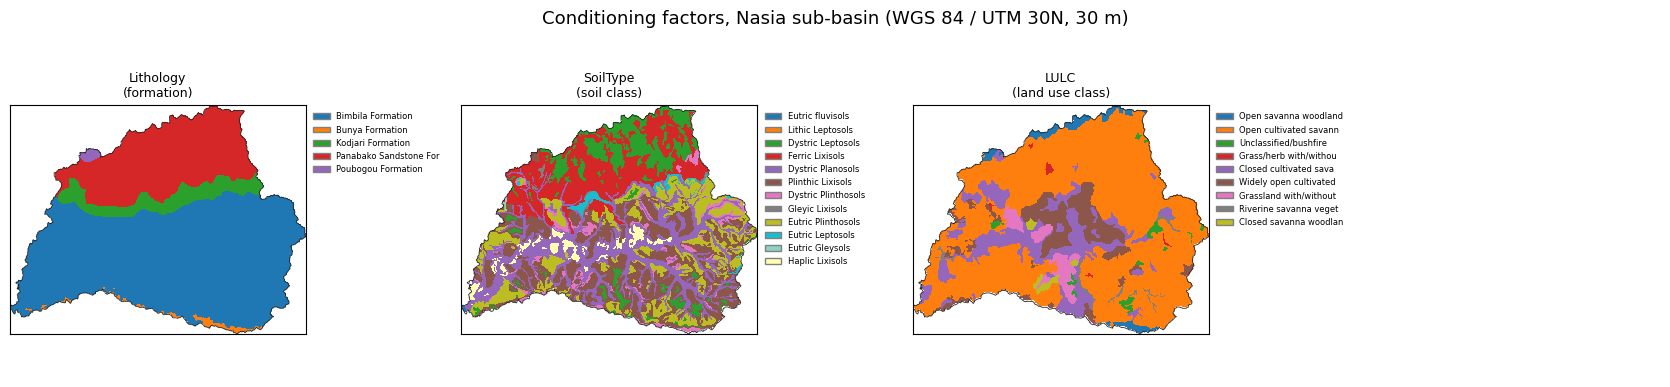


  SANITY VERDICT, BLOCK A10: usable, but 8 item(s) are missing (listed again in BLOCK 19); 0 warning(s).
  --------------------------------------------------------------------------
  DONE. 3 factor GeoTIFFs written to
  D:\Nasia_Manuscript\November_2026\Nasia_outputs_v4\factors. The modelling
  workflow (BLOCK 2 onward) now runs on them.
  --------------------------------------------------------------------------


In [45]:
banner("A10", "writing the factor geotiffs and the factor summary")
io_note(["factors built in BLOCKS A4-A9 (in memory)"],
        ["factors/*.tif", "tables/table_S0f_factor_build_summary.csv",
         "final_maps/02_factors/00_all_factors_panel.png"])


def write_factor(arr, path):
    prof = dict(driver="GTiff", height=GRID_H, width=GRID_W, count=1,
                dtype="float32", crs=TARGET_CRS, transform=GRID_T, nodata=-9999.0,
                compress="lzw", predictor=2, tiled=True, blockxsize=256,
                blockysize=256)
    out = np.where(BASIN_MASK & np.isfinite(arr), arr, -9999.0).astype("float32")
    with rasterio.open(path, "w", **prof) as dst:
        dst.write(out, 1)


summary = []
shared = BASIN_MASK.copy()
for name in list(FACTOR_NAMES):
    if name not in BUILT:
        FACTORS[name]["file"] = None
        flag("A10", f"{name} could not be built (see the earlier blocks) and is "
                    f"switched OFF for the model.", "MISSING")
        print(f"    {name:<15s} NOT BUILT - switched off")
        continue
    write_factor(BUILT[name], FACTORS[name]["path"])
    shared &= np.isfinite(BUILT[name])
    s = STATS_A.get(name, {})
    mine = [f for f in FLAGS if name in f["Message"]
            and f["Severity"] in ("PROBLEM", "WARNING")]
    summary.append(dict(Factor=name, Kind=FACTORS[name]["kind"],
                        Units=FACTORS[name]["units"],
                        File=f"factors/{FACTORS[name]['file']}",
                        Source=BUILD_INFO.get(name, {}).get("source", ""),
                        Method=BUILD_INFO.get(name, {}).get("method", ""),
                        Coverage_pct=s.get("Coverage_pct"),
                        Min=s.get("Min"), Median=s.get("Median"), Max=s.get("Max"),
                        Sanity="see warnings" if mine else "ok"))
    print(f"    {name:<15s} written -> factors/{FACTORS[name]['file']}")

resolve_factor_paths()
FACTORS = {k: v for k, v in FACTORS.items() if v.get("file")}
FACTOR_NAMES = list(FACTORS.keys())
build_tab = pd.DataFrame(summary)
build_tab.to_csv(DIR_TAB / "table_S0f_factor_build_summary.csv", index=False)
STATE["build_summary"] = build_tab

shared_pct = 100 * shared.sum() / BASIN_MASK.sum()
print()
if shared_pct < 98:
    warn("A10", f"Only {shared_pct:.1f}% of the basin has data in EVERY factor; "
                f"the rest will be excluded from the model. The per-factor "
                f"coverage in the table above shows which layer is short.")
else:
    ok(f"{shared_pct:.1f}% of the basin has data in every factor.")
print()
print(build_tab[["Factor", "Units", "Coverage_pct", "Min", "Median", "Max",
                 "Sanity"]].to_string(index=False))
print()

# panel of all factors
SHORT_UNITS = dict(Lithology="formation", SoilType="soil class", LULC="land use class",
                   LineamentDens="km/km2", DrainageDens="km/km2",
                   DistLineament="m", DistStream="m", Elevation="m a.s.l.",
                   Slope="degrees", TWI="ln(a/tan B)", TPI="m", Rainfall="mm/yr")
n = len(FACTOR_NAMES)
ncol = 4
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.9 * nrow), squeeze=False)
ext = [GRID_T.c, GRID_T.c + GRID_W * PIXEL_M, GRID_T.f - GRID_H * PIXEL_M, GRID_T.f]
bx0, by0, bx1, by1 = BASIN_UTM.total_bounds
for i, name in enumerate(FACTOR_NAMES):
    ax = axes.ravel()[i]
    a = np.where(BASIN_MASK, BUILT[name], np.nan)
    if FACTORS[name]["kind"] == "categorical":
        codes = np.unique(a[np.isfinite(a)])
        idx = np.searchsorted(codes, np.nan_to_num(a, nan=codes[0])).astype(float)
        idx[~np.isfinite(a)] = np.nan
        im = ax.imshow(for_display(idx, 900), extent=ext, interpolation="nearest",
                       cmap=ListedColormap(_QUAL[:max(len(codes), 1)]),
                       vmin=-0.5, vmax=max(len(codes), 1) - 0.5)
        _lg = LEGENDS.get(name, {})
        ax.legend(handles=[Patch(facecolor=_QUAL[j], edgecolor="0.5",
                                 label=str(_lg.get(int(c), f"class {int(c)}"))[:22])
                           for j, c in enumerate(codes[:12])],
                  loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=6,
                  frameon=False)
    else:
        v = a[np.isfinite(a)]
        lo, hi = np.percentile(v, [1, 99]) if v.size else (0, 1)
        if name == "TPI":
            hi = max(abs(lo), abs(hi)); lo = -hi
        im = ax.imshow(for_display(a, 900), extent=ext, cmap=MAP_STYLE.get(name, "viridis"),
                       vmin=lo, vmax=hi if hi > lo else lo + 1,
                       interpolation="nearest")
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02).ax.tick_params(labelsize=7)
    BASIN_UTM.boundary.plot(ax=ax, color="0.15", lw=0.6)
    ax.set_xlim(bx0, bx1); ax.set_ylim(by0, by1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_title(f"{name}\n({SHORT_UNITS.get(name, FACTORS[name]['units'])})",
                 fontsize=9)
for j in range(n, nrow * ncol):
    axes.ravel()[j].axis("off")
fig.suptitle("Conditioning factors, Nasia sub-basin (WGS 84 / UTM 30N, 30 m)",
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(DIR_MAP_FAC / "00_all_factors_panel.png", dpi=300)
show_fig(fig)

# free the memory held by the build blocks before the modelling starts
BUILT.clear()
for _v in ("dem", "slope", "acc", "fdir", "twi", "tpi", "dd", "dist_s", "ldens",
           "ldist", "L", "lr", "rain", "lith", "a", "old", "gx", "gy", "tanb",
           "holes", "_near_basin", "filled_depth", "stream_len_m", "stream_cells",
           "dem_arrays", "rain_arrays", "pfill", "praw", "acc_r", "fdir_r", "pg",
           "dsum", "lsum", "idx", "shared"):
    globals().pop(_v, None)
import gc
gc.collect()
verdict("A10")
log_step("factor_build", factors=FACTOR_NAMES, crs=TARGET_CRS, pixel=PIXEL_M,
         dem=chosen_dem, stream_threshold_km2=STREAM_THRESHOLD_KM2,
         drainage_radius_m=DRAINAGE_RADIUS_M, lineament_radius_m=LINEAMENT_RADIUS_M,
         tpi_radius_m=TPI_RADIUS_M,
         rainfall=BUILD_INFO.get("Rainfall", {}).get("source"))
done(f"{len(FACTOR_NAMES)} factor GeoTIFFs written to {DIR_FAC}. The modelling "
     f"workflow (BLOCK 2 onward) now runs on them.")

## BLOCK D  |  DIAGNOSTICS - WHY DID SOMETHING FAIL OR LOOK WRONG?

 INPUTS   : whatever the earlier blocks left in memory, plus the files in  
            DATA_DIR. Run it any time after BLOCK A2; it never stops the run.  
 OUTPUTS  : logs/DIAGNOSTICS.txt  (upload this file when asking for help)  
 RUNTIME  : one to three minutes (it re-reads the DEM and rainfall rasters)  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Collects the facts needed to fix a failure, without changing anything:  
  
  D1  PYTHON ENVIRONMENT - which Python JupyterLab is really using, and the  
      exact error when pysheds (flow routing) is imported. A library  
      installed into a different Anaconda environment is the usual reason  
      "it is installed but still missing".  
  D2  BASIN OUTLINE - every copy of Nas_ia and which of its parts (.shp,  
      .shx, .dbf, .prj) exist. A copy without its .dbf cannot be read.  
  D3  DEM AND THE GRID PATTERN IN SLOPE - the DEM's data type, whether its  
      heights are whole metres, its pixel size in x and y, and the size of  
      the repeating pattern a regridding to 30 m would create. It then  
      MEASURES the repeat in the slope map and tests two remedies: lightly  
      smoothing the DEM, and computing slope on the DEM's own grid before  
      reprojecting.  
  D4  RAINFALL GAPS - where the empty pixels in the rainfall map are, and  
      whether they are already empty in the source file.  
  D5  STREAMS - whether any stream / river shapefile exists in the folder.  
  D6  FACTORS - which factors were built and which were switched off.  
  D7  STALE MESSAGES - re-running cells in JupyterLab keeps old warnings;  
      this counts how many in BLOCK 19's list are repeats.  


  BLOCK D  |  DIAGNOSTICS - WHY DID SOMETHING FAIL OR LOOK WRONG?
  READS :
      memory from earlier blocks
      files in D:\Nasia_Manuscript\November_2026
  WRITES:
      logs/DIAGNOSTICS.txt


------------------------------------------------------------------------------
  D1  PYTHON ENVIRONMENT
------------------------------------------------------------------------------
  Python executable : C:\Users\USER\anaconda3\python.exe
  Python version    : 3.13.5  (Windows-11-10.0.26300-SP0)
  Conda environment : base
  numpy 2.3.5 | rasterio 1.4.3 (GDAL 3.9.3) | geopandas 1.1.1
  pysheds : version 0.5
  numba   : version 0.68.1
  scipy   : version 1.15.3
  skimage : version 0.25.0
  pysheds.grid imports correctly.

------------------------------------------------------------------------------
  D2  BASIN OUTLINE FILES
------------------------------------------------------------------------------
  Nas_ia (2025_12_06 07_17_13 UTC).shp             18,476 B  2018-03-07  .shp:yes  .shx:yes

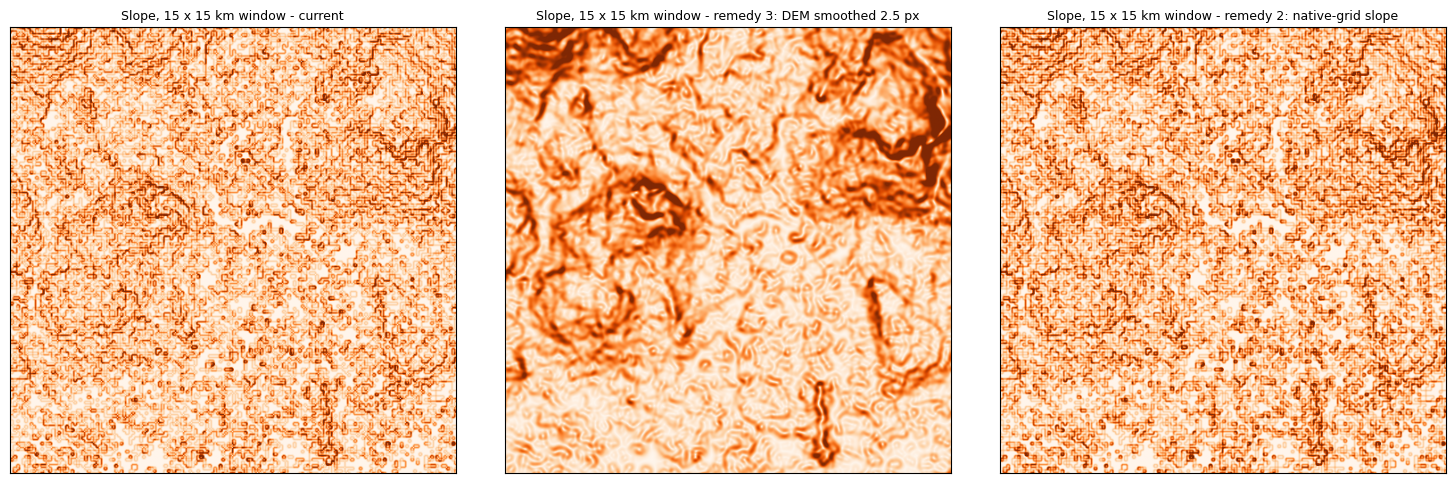


------------------------------------------------------------------------------
  D4  RAINFALL GAPS
------------------------------------------------------------------------------
  Annual_Rainfall (2026_02_04 11_34_54 UTC).tif: CRS Leigon / Ghana Metre Grid (EPSG:25000) | dtype float32 | nodata -3.4028230607370965e+38 | 9106 x 9064 px | pixel 30 x 30
  In the source, over the basin's extent: 1,137,526 empty pixels; 554 row(s) and 697 column(s) more than 20% empty.
      empty source row at y = 657432 (Leigon / Ghana Metre Grid (EPSG:25000))
      empty source row at y = 657402 (Leigon / Ghana Metre Grid (EPSG:25000))
      empty source row at y = 657372 (Leigon / Ghana Metre Grid (EPSG:25000))
      empty source row at y = 657342 (Leigon / Ghana Metre Grid (EPSG:25000))
      empty source row at y = 657312 (Leigon / Ghana Metre Grid (EPSG:25000))
      empty source row at y = 657282 (Leigon / Ghana Metre Grid (EPSG:25000))
      empty source row at y = 657252 (Leigon / Ghana Metre Grid

In [46]:
banner("D", "diagnostics - why did something fail or look wrong?")
io_note(["memory from earlier blocks", f"files in {DATA_DIR}"],
        ["logs/DIAGNOSTICS.txt"])
import io as _io
import platform as _platform
import traceback as _tb
import contextlib as _cl

_DIAG = _io.StringIO()


def dprint(*a):
    print(*a)
    print(*a, file=_DIAG)


def _section(t):
    dprint("\n" + "-" * 78)
    dprint("  " + t)
    dprint("-" * 78)


def _periodicity(arr, mask, axis, px_km=None):
    """Strongest repeat (km) in the mean profile of arr along one axis."""
    px_km = PIXEL_M / 1000.0 if px_km is None else px_km
    a = np.where(mask & np.isfinite(arr), arr, np.nan) if mask is not None else arr
    prof = np.nanmean(a, axis=axis)
    prof = prof[np.isfinite(prof)]
    if prof.size < 200:
        return np.nan, np.nan
    k = 51
    trend = np.convolve(prof, np.ones(k) / k, mode="same")
    d = (prof - trend)[k:-k]
    spec = np.abs(np.fft.rfft(d - d.mean())) ** 2
    freq = np.fft.rfftfreq(d.size, d=px_km)                     # cycles per km
    sel = (freq > 1 / 10.0) & (freq < 1 / 0.3)                 # 0.3 - 10 km
    if not sel.any():
        return np.nan, np.nan
    i = np.argmax(spec[sel])
    peak = spec[sel][i] / np.median(spec[sel])
    return 1.0 / freq[sel][i], peak


# ---- D1 --------------------------------------------------------------------
_section("D1  PYTHON ENVIRONMENT")
dprint(f"  Python executable : {sys.executable}")
dprint(f"  Python version    : {sys.version.split()[0]}  ({_platform.platform()})")
dprint(f"  Conda environment : {os.environ.get('CONDA_DEFAULT_ENV', '(not reported)')}")
dprint(f"  numpy {np.__version__} | rasterio {rasterio.__version__} "
       f"(GDAL {rasterio.__gdal_version__}) | geopandas {gpd.__version__}")
for _mod in ("pysheds", "numba", "scipy", "skimage"):
    try:
        _m = __import__(_mod)
        dprint(f"  {_mod:<8s}: version {getattr(_m, '__version__', '?')}")
    except Exception as _e:
        dprint(f"  {_mod:<8s}: NOT importable - {type(_e).__name__}: {_e}")
try:
    from pysheds.grid import Grid as _G      # noqa: F401
    dprint("  pysheds.grid imports correctly.")
except Exception:
    dprint("  pysheds.grid import error (full):")
    for _l in _tb.format_exc().strip().splitlines()[-6:]:
        dprint("      " + _l)
    dprint("  To install into THIS environment, run in a notebook cell:")
    dprint("      %pip install -U numba llvmlite pysheds")
    dprint("  or in the Anaconda Prompt:")
    dprint(f"      \"{sys.executable}\" -m pip install pysheds")
    dprint("  then Kernel > Restart Kernel and run from BLOCK 0.")

# ---- D2 --------------------------------------------------------------------
_section("D2  BASIN OUTLINE FILES")
for _p in find_copies(RAW["basin"]):
    _b = _p.with_suffix("")
    _parts = {s_: Path(str(_b) + s_).exists() for s_ in (".shp", ".shx", ".dbf", ".prj")}
    dprint(f"  {_p.name:<45s} {_p.stat().st_size:>9,d} B  "
           f"{datetime.datetime.fromtimestamp(_p.stat().st_mtime):%Y-%m-%d}  "
           + "  ".join(f"{k_}:{'yes' if v_ else 'NO'}" for k_, v_ in _parts.items()))
dprint(f"  Outline actually used: {FOUND['basin'][0].name if FOUND.get('basin') else 'none'}")

# ---- D3 --------------------------------------------------------------------
_section("D3  DEM AND THE GRID PATTERN IN SLOPE")
_lat0 = float(BASIN_UTM.to_crs(4326).geometry.iloc[0].centroid.y)
for _p in FOUND.get("dem", []):
    with rasterio.open(_p) as _s:
        _crs = _s.crs or guess_crs(tuple(_s.bounds))
        _c = CRS.from_user_input(_crs)
        if _c.is_geographic:
            _px = abs(_s.transform.a) * 111320 * np.cos(np.radians(_lat0))
            _py = abs(_s.transform.e) * 110574
        else:
            _px, _py = abs(_s.transform.a), abs(_s.transform.e)
        _w = _s.read(1, window=Window(_s.width // 2, _s.height // 2,
                                      min(500, _s.width // 2), min(500, _s.height // 2)))
        _w = _w[np.isfinite(_w)].astype(float)
        if _s.nodata is not None:
            _w = _w[_w != _s.nodata]
        _int = float(np.mean(np.abs(_w - np.round(_w)) < 1e-6)) if _w.size else np.nan
        dprint(f"  {_p.name}")
        dprint(f"      CRS {crs_label(_crs)} | dtype {_s.dtypes[0]} | nodata {_s.nodata} | "
               f"{_s.width} x {_s.height} px")
        dprint(f"      pixel {abs(_s.transform.a):.7g} x {abs(_s.transform.e):.7g} "
               f"(native units) = {_px:.2f} m (x) by {_py:.2f} m (y)")
        dprint(f"      heights stored as whole metres: {100*_int:.0f}% of a sample")
        for _lab, _pp in (("x", _px), ("y", _py)):
            _beat = 30 * _pp / abs(_pp - PIXEL_M) if abs(_pp - PIXEL_M) > 0.01 else np.inf
            dprint(f"      predicted repeat when regridded to {PIXEL_M} m, {_lab}: "
                   f"{_beat/1000:.2f} km")

if "chosen_dem" in globals():
    _dem_p = next(p for p in FOUND["dem"] if p.name == chosen_dem)
    _dem_g, _ = warp_to_grid("D", _dem_p, "DEM (diagnostic re-read)")
    _gy, _gx = np.gradient(_dem_g.astype("float64"), PIXEL_M)
    _sl_now = np.degrees(np.arctan(np.hypot(_gx, _gy)))
    # remedy 1: light smoothing of the regridded DEM
    _dz = np.where(np.isfinite(_dem_g), _dem_g, np.nanmean(_dem_g))
    _dsm = ndimage.gaussian_filter(_dz, 1.0)
    _gy, _gx = np.gradient(_dsm, PIXEL_M)
    _sl_smooth = np.degrees(np.arctan(np.hypot(_gx, _gy)))
    _gy, _gx = np.gradient(ndimage.gaussian_filter(_dz, 2.5), PIXEL_M)
    _sl_smooth3 = np.degrees(np.arctan(np.hypot(_gx, _gy)))
    # remedy 2: slope on the DEM's own grid, then reproject the slope
    with rasterio.open(_dem_p) as _s:
        _crs = _s.crs or guess_crs(tuple(_s.bounds))
        _gb = transform_bounds(TARGET_CRS, _crs, *GRID_BOUNDS, densify_pts=21)
        _win = window_from_bounds(*_gb, transform=_s.transform).round_offsets().round_lengths()
        _win = _win.intersection(Window(0, 0, _s.width, _s.height))
        _a = _s.read(1, window=_win).astype("float64")
        if _s.nodata is not None:
            _a[_a == _s.nodata] = np.nan
        _tr = _s.window_transform(_win)
        _c = CRS.from_user_input(_crs)
        if _c.is_geographic:
            _dx = abs(_tr.a) * 111320 * np.cos(np.radians(_lat0))
            _dy = abs(_tr.e) * 110574
        else:
            _dx, _dy = abs(_tr.a), abs(_tr.e)
        _gy, _gx = np.gradient(_a, _dy, _dx)
        _sl_nat = np.degrees(np.arctan(np.hypot(_gx, _gy))).astype("float32")
    _sl_native = np.full(GRID_SHAPE, np.nan, dtype="float32")
    reproject(_sl_nat, _sl_native, src_transform=_tr, src_crs=_crs, dst_transform=GRID_T,
              dst_crs=TARGET_CRS, src_nodata=np.nan, dst_nodata=np.nan,
              resampling=Resampling.bilinear)
    dprint("\n  Measured repeating pattern in slope (period in km; strength = peak "
           "power / median power, >10 means a clear grid):")
    dprint(f"      {'version':<44s} {'x period':>9s} {'x strength':>11s} "
           f"{'y period':>9s} {'y strength':>11s}")
    _res = {}
    _cn = (slice(_sl_nat.shape[0] // 4, 3 * _sl_nat.shape[0] // 4),
           slice(_sl_nat.shape[1] // 4, 3 * _sl_nat.shape[1] // 4))
    _nx, _sx0 = _periodicity(_sl_nat[_cn], None, 0, _dx / 1000)
    _ny, _sy0 = _periodicity(_sl_nat[_cn], None, 1, _dy / 1000)
    dprint(f"      {'slope on the DEM own grid (no regridding)':<44s} {_nx:>9.2f} "
           f"{_sx0:>11.1f} {_ny:>9.2f} {_sy0:>11.1f}")
    for _nm, _sl in (("current (DEM regridded, then slope)", _sl_now),
                     ("remedy 1: DEM smoothed 1 pixel, then slope", _sl_smooth),
                     ("remedy 2: slope on native DEM, then regrid", _sl_native),
                     ("remedy 3: DEM smoothed 2.5 pixels", _sl_smooth3)):
        _pxk, _sx = _periodicity(_sl, BASIN_MASK, 0)
        _pyk, _sy = _periodicity(_sl, BASIN_MASK, 1)
        _res[_nm] = (_sx, _sy)
        dprint(f"      {_nm:<44s} {_pxk:>9.2f} {_sx:>11.1f} {_pyk:>9.2f} {_sy:>11.1f}")
    dprint("      median slope (deg): current {:.2f} | remedy 1 {:.2f} | remedy 2 {:.2f}"
           " | remedy 3 {:.2f}"
           .format(*(np.nanmedian(np.where(BASIN_MASK, s_, np.nan))
                     for s_ in (_sl_now, _sl_smooth, _sl_native, _sl_smooth3))))
    _cur = max(_res["current (DEM regridded, then slope)"])
    if max(_sx0, _sy0) > 10:
        _s3 = max(_res["remedy 3: DEM smoothed 2.5 pixels"])
        dprint("  READING: the pattern is already in the DEM itself (it shows on the "
               "DEM's own grid), so it belongs to the DEM product - e.g. terracing "
               "from whole-metre heights, or SRTM striping - not to the regridding.")
        if _s3 < 10:
            dprint("  Smoothing the DEM by 2.5 pixels removes it: that is the cheap cure.")
        else:
            dprint(f"  Smoothing by 2.5 pixels does NOT remove it (strength {_s3:.0f}); "
                   f"the pattern is too broad. Use a different DEM product "
                   f"(Copernicus GLO-30 or FABDEM, both 1 arc-second, float heights).")
    elif _cur > 10:
        dprint("  READING: the DEM's own grid is clean but the regridded slope is not, "
               "so the pattern comes from regridding (a moire between the DEM's "
               "pixels and the 30 m grid). Computing slope on the native DEM fixes it.")
    else:
        dprint("  READING: no strong repeating pattern measured.")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    _r0, _c0 = [int(v_) for v_ in np.argwhere(BASIN_MASK).mean(axis=0)]
    _cut = (slice(_r0 - 250, _r0 + 250), slice(_c0 - 250, _c0 + 250))
    for _ax, (_nm, _sl) in zip(axes, (("current", _sl_now), ("remedy 3: DEM smoothed 2.5 px", _sl_smooth3),
                                      ("remedy 2: native-grid slope", _sl_native))):
        _v = _sl[_cut]
        _ax.imshow(_v, cmap="Oranges", vmin=0, vmax=np.nanpercentile(_v, 98))
        _ax.set_title(f"Slope, 15 x 15 km window - {_nm}", fontsize=9)
        _ax.set_xticks([]); _ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(DIR_LOG / "DIAGNOSTICS_slope_pattern.png", dpi=150)
    show_fig(fig)
    del _dem_g, _dz, _dsm, _sl_now, _sl_smooth, _sl_smooth3, _sl_native, _a, _sl_nat, _gx, _gy
else:
    dprint("  BLOCK A4 has not run in this session - the slope test was skipped.")

# ---- D4 --------------------------------------------------------------------
_section("D4  RAINFALL GAPS")
_rsrc = BUILD_INFO.get("Rainfall", {}).get("source")
_rp = next((p for p in FOUND.get("rainfall", []) if p.name == _rsrc), None)
if _rp is None:
    dprint(f"  No rainfall raster in use (source: {_rsrc}).")
elif _rp.suffix.lower() in (".tif", ".tiff"):
    with rasterio.open(_rp) as _s:
        dprint(f"  {_rp.name}: CRS {crs_label(_s.crs)} | dtype {_s.dtypes[0]} | "
               f"nodata {_s.nodata} | {_s.width} x {_s.height} px | pixel "
               f"{abs(_s.transform.a):.6g} x {abs(_s.transform.e):.6g}")
        _crs = _s.crs or guess_crs(tuple(_s.bounds))
        _gb = transform_bounds(TARGET_CRS, _crs, *BASIN_UTM.total_bounds, densify_pts=21)
        _win = window_from_bounds(*_gb, transform=_s.transform).round_offsets().round_lengths()
        _win = _win.intersection(Window(0, 0, _s.width, _s.height))
        _a = _s.read(1, window=_win).astype("float64")
        _bad = ~np.isfinite(_a) | ((_a == _s.nodata) if _s.nodata is not None else False) \
               | (np.abs(_a) > 1e30)
        _rows = np.flatnonzero(_bad.mean(axis=1) > 0.2)
        _cols = np.flatnonzero(_bad.mean(axis=0) > 0.2)
        dprint(f"  In the source, over the basin's extent: {int(_bad.sum()):,} empty pixels; "
               f"{len(_rows)} row(s) and {len(_cols)} column(s) more than 20% empty.")
        _tr = _s.window_transform(_win)
        for _r in _rows[:10]:
            _y = _tr.f + (_r + 0.5) * _tr.e
            dprint(f"      empty source row at y = {_y:.6g} ({crs_label(_crs)})")
    _rg, _ = warp_to_grid("D", _rp, "rainfall (diagnostic re-read)")
    _holes = BASIN_MASK & ~np.isfinite(_rg)
    dprint(f"  After regridding: {int(_holes.sum()):,} empty pixels inside the basin "
           f"({100*_holes.mean()/max(BASIN_MASK.mean(),1e-9):.3f}% of it).")
    if _holes.any():
        _rr = np.flatnonzero(_holes.any(axis=1))
        _north = GRID_T.f - (_rr + 0.5) * PIXEL_M
        dprint(f"      on {len(_rr)} grid row(s), northing {_north.min()/1000:.2f}-"
               f"{_north.max()/1000:.2f} km")
    del _rg
else:
    dprint(f"  Rainfall comes from a vector file ({_rp.name}); no raster gaps to test.")

# ---- D5 --------------------------------------------------------------------
_section("D5  STREAM FILES")
_cands = sorted(p.name for p in DATA_DIR.iterdir() if p.suffix.lower() in (".shp", ".gpkg")
                and re.search(r"stream|river|drain|channel|hydro", p.name, re.I))
dprint(f"  RAW['streams'] in BLOCK 1: {RAW.get('streams')!r}")
dprint(f"  Stream-like vector files in the folder: {_cands or 'none'}")
dprint("  Note: a stream shapefile would let distance to stream be built without "
       "pysheds, but TWI always needs flow routing (pysheds).")

# ---- D6 --------------------------------------------------------------------
_section("D6  FACTORS")
for _k, _v in ALL_FACTORS.items():
    _path = DIR_FAC / _v["file"] if _v.get("file") else None
    dprint(f"  {_k:<15s} file setting: {_v.get('file')!s:<28s} "
           f"on disk: {'yes' if _path and _path.exists() else 'no'}  "
           f"source: {BUILD_INFO.get(_k, {}).get('source', '-')}")

# ---- D7 --------------------------------------------------------------------
_section("D7  STALE MESSAGES FROM RE-RUN CELLS")
_fl = pd.DataFrame(FLAGS) if FLAGS else pd.DataFrame(columns=["Block", "Severity", "Message"])
_dup = int(_fl.duplicated().sum())
dprint(f"  {len(_fl)} messages collected; {_dup} are exact repeats from re-running cells.")
dprint("  Messages from a failed earlier attempt stay in the list until the kernel is "
       "restarted. For a clean BLOCK 19, use Kernel > Restart Kernel and Run All.")

(DIR_LOG / "DIAGNOSTICS.txt").write_text(_DIAG.getvalue(), encoding="utf-8")
done(f"Diagnostics written to {DIR_LOG / 'DIAGNOSTICS.txt'}. Upload that file (and "
     f"logs/DIAGNOSTICS_slope_pattern.png) so the fixes can be targeted.")

## BLOCK 2  |  INPUT ROLL CALL AND SANITY CHECK

 INPUTS   : every GeoTIFF named in BLOCK 1 (single-band GeoTIFF)  
            the borehole inventory (CSV / XLSX / SHP / GPKG)  
            the basin boundary, if one was given (polygon vector)  
            the hydraulic point file, if one was given  
 OUTPUTS  : tables/table_S1_input_inventory.csv  (CSV: one row per raster,  
            with size, pixel size, CRS, dtype, nodata, min, max, mean)  
 RUNTIME  : seconds to a minute, depending on raster size  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Before anything expensive runs, this block looks for each file you named,  
 opens it, and reads its statistics. It then does something version 1 did not:  
 it checks the VALUES against the plausible range declared for that factor in  
 BLOCK 1.  
  
 That catches the mistakes that are otherwise invisible until the results look  
 strange - a slope layer in percent rather than degrees, an NDVI layer still  
 scaled 0-10000, a rainfall surface that turns out to be almost flat, a  
 categorical layer that was accidentally resampled and now has thousands of  
 distinct values.  
  
 If a required file is missing you get a note naming that exact file and the  
 script stops here. Warnings about value ranges do not stop the run; they are  
 printed for your judgement.  

In [47]:
banner(2, "input roll call and sanity check")
io_note([f"{len(FACTORS)} conditioning-factor GeoTIFFs in {DATA_DIR}",
         f"borehole inventory: {BOREHOLE_FILE}",
         f"hydraulic points: {HYDRAULIC_POINTS or '(none configured)'}"],
        ["tables/table_S1_input_inventory.csv"])
say("""
Opening each file you listed and reading its statistics, then checking those
values look like what the factor is supposed to be. Nothing is loaded into
memory for analysis yet - this is a roll call with a sanity check attached.
""")

_all_present = True
for name, meta in FACTORS.items():
    if not need_file(
            2, f"conditioning-factor GeoTIFF for '{name}'", meta["path"],
            f"Save the final '{name}' GeoTIFF into {DATA_DIR} under the name "
            f"'{meta['file']}', or correct that name in BLOCK 1. Expected "
            f"units: {meta['units']}. If you have decided not to use this "
            f"factor, set its file entry to None in BLOCK 1."):
        _all_present = False

_bh_path = DATA_DIR / BOREHOLE_FILE
if not need_file(
        2, "borehole inventory", _bh_path,
        f"Place the borehole file in {DATA_DIR}. It needs at minimum an X "
        f"column ('{COL_X}'), a Y column ('{COL_Y}') and a yield column "
        f"('{COL_YIELD}') in cubic metres per hour. CSV, XLSX, SHP and GPKG "
        f"are all accepted."):
    _all_present = False

if BASIN_BOUNDARY is not None:
    if not need_file(2, "sub-basin boundary polygon", DATA_DIR / BASIN_BOUNDARY,
                     "Provide the boundary vector file, or set BASIN_BOUNDARY = "
                     "None in BLOCK 1 if your rasters are already clipped."):
        _all_present = False

if not _all_present:
    print("  One or more required inputs are missing. Fix the items above and "
          "re-run.")
    stop()

# ---- Read properties and check value ranges ---------------------------------
rows, warnings_found = [], []
for name, meta in FACTORS.items():
    with rasterio.open(meta["path"]) as src:
        arr = src.read(1, masked=True)
        vals = arr.compressed().astype("float64")
        if src.nodata is not None and np.isfinite(src.nodata):
            vals = vals[vals != src.nodata]
        vals = vals[np.isfinite(vals)]
        lo, hi = meta["valid"]
        vmin = float(vals.min()) if vals.size else np.nan
        vmax = float(vals.max()) if vals.size else np.nan
        n_uni = int(np.unique(vals).size) if vals.size else 0

        chk = ""
        if vals.size == 0:
            chk = "EMPTY - no valid pixels"
        elif vmin < lo or vmax > hi:
            chk = f"OUT OF RANGE (expected {lo} to {hi})"
        elif meta["kind"] == "categorical" and n_uni > 60:
            chk = f"{n_uni} distinct values - is this really categorical?"
        elif meta["kind"] == "continuous" and n_uni < 5:
            chk = f"only {n_uni} distinct values - effectively constant"
        elif meta["kind"] == "continuous" and (vmax - vmin) < 1e-9:
            chk = "constant surface - carries no information"
        if chk:
            warnings_found.append((name, chk, vmin, vmax))
            flag(2, f"{name}: {chk} (range {vmin:.4g} to {vmax:.4g})")

        rows.append(dict(
            Factor=name, Type=meta["kind"], File=meta["file"],
            Units=meta["units"], Width=src.width, Height=src.height,
            PixelX=round(abs(src.transform.a), 3),
            PixelY=round(abs(src.transform.e), 3),
            CRS=str(src.crs), DType=src.dtypes[0], NoData=src.nodata,
            Min=round(vmin, 4) if np.isfinite(vmin) else None,
            Max=round(vmax, 4) if np.isfinite(vmax) else None,
            Distinct=n_uni, Check=chk or "ok"))

inventory = pd.DataFrame(rows)
STATE["inventory"] = inventory
pd.set_option("display.width", 250, "display.max_columns", 40)
print(inventory[["Factor", "Type", "PixelX", "CRS", "Min", "Max",
                 "Distinct", "Check"]].to_string(index=False))
print()

if warnings_found:
    say("VALUE CHECKS THAT NEED YOUR ATTENTION:")
    for name, chk, vmin, vmax in warnings_found:
        print(f"    {name:<15s} range {vmin:.4g} to {vmax:.4g}  ->  {chk}")
    print()
    say("""
These are warnings, not errors, and the script will carry on. But fix them
before you believe the results. The usual causes are a slope raster in percent
or radians rather than degrees, an NDVI layer still scaled by 10000, a
categorical layer that was bilinearly resampled somewhere upstream, or a
climate surface so coarse it is effectively flat over this basin.
""")
else:
    say("All rasters passed their value checks.")

ref_row = inventory[inventory.Factor == REFERENCE_FACTOR]
if ref_row.empty:
    missing_note(2, f"reference factor '{REFERENCE_FACTOR}'",
                 "one of the factors switched on in BLOCK 1",
                 f"REFERENCE_FACTOR is set to '{REFERENCE_FACTOR}', which is "
                 f"not among the factors supplied. Set it to one of: "
                 f"{', '.join(FACTOR_NAMES)}.")
    stop()

_mis = inventory[(inventory.CRS != ref_row.CRS.iloc[0]) |
                 (inventory.Width != ref_row.Width.iloc[0]) |
                 (inventory.Height != ref_row.Height.iloc[0])]
if len(_mis):
    say(f"""
{len(_mis)} raster(s) do not currently share the grid of '{REFERENCE_FACTOR}'.
This is normal and not a problem - BLOCK 3 reprojects and resamples them onto a
single common grid. Affected: {', '.join(_mis.Factor.tolist())}.
""")
else:
    say(f"All rasters already share the grid of '{REFERENCE_FACTOR}'.")

inventory.to_csv(DIR_TAB / "table_S1_input_inventory.csv", index=False)
log_step("input_check", n_ok=len(inventory), warnings=len(warnings_found))
done(f"All {len(FACTORS)} conditioning-factor GeoTIFFs and the borehole file "
     f"were found and opened. Inventory saved to "
     f"tables/table_S1_input_inventory.csv. "
     f"{len(warnings_found)} value warning(s) raised.")


  BLOCK 2  |  INPUT ROLL CALL AND SANITY CHECK
  READS :
      3 conditioning-factor GeoTIFFs in D:\Nasia_Manuscript\November_2026
      borehole inventory: Nasia_borehole_inventory_clean.csv
      hydraulic points: Nasia_borehole_inventory_clean.csv
  WRITES:
      tables/table_S1_input_inventory.csv

  Opening each file you listed and reading its statistics, then checking
  those values look like what the factor is supposed to be. Nothing is
  loaded into memory for analysis yet - this is a roll call with a sanity
  check attached.

   Factor        Type  PixelX        CRS  Min  Max  Distinct Check
Lithology categorical    30.0 EPSG:32630  1.0  5.0         5    ok
 SoilType categorical    30.0 EPSG:32630  1.0 12.0        12    ok
     LULC categorical    30.0 EPSG:32630  1.0  9.0         9    ok

  All rasters passed their value checks.


******************************************************************************
*  BLOCK 2 CANNOT RUN - A REQUIRED PRODUCT IS MISSING
*------------

## BLOCK 3  |  PUTTING EVERY FACTOR ON ONE COMMON GRID

 INPUTS   : the conditioning-factor GeoTIFFs (any CRS, any pixel size)  
            the basin boundary polygon, if supplied  
 OUTPUTS  : an in-memory raster stack on one grid, plus a shared valid-data  
            mask. Nothing is written to disk in this block.  
 RUNTIME  : usually the slowest step before BLOCK 13 - a few minutes for a  
            basin of this size. It only has to be done once per run.  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 A Frequency Ratio compares, pixel by pixel, how much of the area falls in  
 each factor class against how many boreholes fall in it. That comparison is  
 only meaningful if every factor sits on exactly the same grid of pixels. So  
 this block takes the grid of the reference layer - the DEM by default - and  
 forces every other layer onto it.  
  
 Continuous surfaces are resampled bilinearly, which keeps them smooth.  
 Categorical maps such as lithology are resampled by nearest neighbour, which  
 preserves their class codes; averaging class codes would be meaningless and  
 would invent units that do not exist.  
  
 It then builds one shared valid-data mask: a pixel is used only where EVERY  
 factor has a real value. Pixels where any layer is no-data are excluded from  
 the whole analysis, so all three models see identical geography and their  
 AUCs are comparable.  

In [ ]:
banner(3, "putting every factor on one common grid")
io_note(["the conditioning-factor GeoTIFFs listed in BLOCK 1",
         f"basin boundary: {BASIN_BOUNDARY or '(none - rasters used as supplied)'}"],
        ["in-memory raster stack and shared valid-data mask (nothing to disk)"])
say("""
Reading the reference grid, then reprojecting and resampling every other layer
onto it.
""")

if not need_state(3, ["inventory"], 2):
    stop()

with rasterio.open(FACTORS[REFERENCE_FACTOR]["path"]) as ref:
    REF_PROFILE   = ref.profile.copy()
    REF_TRANSFORM = ref.transform
    REF_CRS       = ref.crs
    REF_W, REF_H  = ref.width, ref.height
    REF_SHAPE     = (REF_H, REF_W)

pixel_area_km2 = abs(REF_TRANSFORM.a * REF_TRANSFORM.e) / 1e6
print(f"  Master grid : {REF_W} x {REF_H} pixels")
print(f"  Pixel size  : {abs(REF_TRANSFORM.a):.2f} x {abs(REF_TRANSFORM.e):.2f} map units")
print(f"  CRS         : {REF_CRS}")
print()

stack = np.full((len(FACTOR_NAMES), REF_H, REF_W), np.nan, dtype="float32")
valid = np.ones(REF_SHAPE, dtype=bool)

for i, name in enumerate(FACTOR_NAMES):
    meta = FACTORS[name]
    method = Resampling.nearest if meta["kind"] == "categorical" else Resampling.bilinear
    with rasterio.open(meta["path"]) as src:
        arr = np.full(REF_SHAPE, np.nan, dtype="float32")
        reproject(source=rasterio.band(src, 1), destination=arr,
                  src_transform=src.transform, src_crs=src.crs,
                  dst_transform=REF_TRANSFORM, dst_crs=REF_CRS,
                  resampling=method, src_nodata=src.nodata, dst_nodata=np.nan)
    stack[i] = arr
    layer_valid = np.isfinite(arr)
    valid &= layer_valid
    print(f"    {name:<15s} aligned  ({meta['kind']:<11s} "
          f"{'nearest' if meta['kind']=='categorical' else 'bilinear'})  "
          f"valid: {100.0*layer_valid.mean():5.1f}%")

if BASIN_BOUNDARY is not None:
    from rasterio.features import geometry_mask
    bnd = gpd.read_file(DATA_DIR / BASIN_BOUNDARY).to_crs(REF_CRS)
    inside = ~geometry_mask(bnd.geometry, out_shape=REF_SHAPE,
                            transform=REF_TRANSFORM, invert=False)
    valid &= inside
    print(f"\n  Clipped to sub-basin outline: {BASIN_BOUNDARY}")

n_valid = int(valid.sum())
print()
print(f"  Pixels usable by every factor at once : {n_valid:,}")
print(f"  Equivalent mapped area                : {n_valid * pixel_area_km2:,.1f} km2")
print()

if n_valid == 0:
    missing_note(3, "overlapping valid data",
                 "the intersection of all conditioning-factor rasters",
                 "Your factor rasters do not overlap anywhere. Check they all "
                 "cover the Nasia sub-basin, share a sensible CRS, and have "
                 "no-data values set correctly in their headers.")
    stop()

area_km2 = n_valid * pixel_area_km2
if not (3000 < area_km2 < 9000):
    say(f"""
Note: the mapped area comes to {area_km2:,.0f} km2, while the Nasia sub-basin
is described as roughly 5,400 km2. If that gap is large, one of your layers is
probably clipping the others - look at the per-layer valid percentages above
and find the one with the smallest coverage.
""")

STATE.update(stack=stack, valid=valid, ref_profile=REF_PROFILE,
             ref_transform=REF_TRANSFORM, ref_crs=REF_CRS,
             ref_shape=REF_SHAPE, pixel_area_km2=pixel_area_km2,
             n_valid=n_valid)


def write_geotiff(array2d, filename, dtype="float32", nodata=-9999.0):
    """Save a 2-D array onto the master grid as a compressed GeoTIFF."""
    prof = REF_PROFILE.copy()
    for k in ("blockxsize", "blockysize", "tiled", "interleave", "photometric"):
        prof.pop(k, None)
    prof.update(driver="GTiff", dtype=dtype, count=1, nodata=nodata,
                compress="lzw", predictor=2 if dtype != "uint8" else 1)
    if REF_W >= 256 and REF_H >= 256:
        prof.update(tiled=True, blockxsize=256, blockysize=256)
    else:
        prof.update(tiled=False)
    out = np.where(valid, array2d, nodata).astype(dtype)
    path = DIR_RAS / filename
    with rasterio.open(path, "w", **prof) as dst:
        dst.write(out, 1)
    return path


STATE["write_geotiff"] = write_geotiff
log_step("harmonise", n_valid=n_valid, shape=list(REF_SHAPE))
done(f"All {len(FACTOR_NAMES)} factors now sit on one grid of {REF_W} x {REF_H} "
     f"pixels, with {n_valid:,} pixels usable by every layer.")

## BLOCK 4  |  BOREHOLES - READING, LABELLING AND SAMPLING

 INPUTS   : the borehole inventory file  
            FORMAT: CSV / XLSX / SHP / GPKG  
            REQUIRED COLUMNS: X, Y, yield  
            YIELD UNITS: cubic metres per hour (or litres/minute if  
                         YIELD_IS_LPM is set True in BLOCK 1)  
 OUTPUTS  : tables/table_S2_borehole_extraction.csv  
            (CSV: one row per usable borehole, carrying its coordinates,  
             yield, productive/non-productive label, grid row and column,  
             and the value of every conditioning factor at that pixel)  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Loads the inventory, puts the points into the rasters' coordinate system,  
 finds which pixel each borehole sits in, and reads the value of every  
 conditioning factor at that pixel.  
  
 It then applies the yield threshold: boreholes at or above 0.6 cubic metres  
 per hour are labelled 1 (productive), everything below - including dry holes  
 - is labelled 0.  
  
 Boreholes falling outside the mapped area, or on a pixel where some factor  
 has no data, cannot be used. The block reports exactly how many were dropped  
 and why, so the number you quote in the manuscript is traceable.  

In [ ]:
banner(4, "boreholes - reading, labelling and sampling")
io_note([f"{BOREHOLE_FILE}  (X={COL_X}, Y={COL_Y}, yield={COL_YIELD}, "
         f"CRS={BOREHOLE_CRS})"],
        ["tables/table_S2_borehole_extraction.csv"])
say(f"""
Loading the borehole inventory and extracting the value of each conditioning
factor at each borehole. A borehole is labelled productive (1) if its yield is
{'above' if YIELD_STRICT else 'at least'} {YIELD_THRESHOLD} cubic metres per hour
({YIELD_THRESHOLD * 1000 / 60:.0f} L/min).
""")

if not need_state(4, ["stack", "valid"], 3):
    stop()


_X_HINTS = ("easting", "east", "utm_e", "utme", "x_utm", "x", "xcoord", "x_coord",
            "longitude", "long", "lon", "lng")
_Y_HINTS = ("northing", "north", "utm_n", "utmn", "y_utm", "y", "ycoord", "y_coord",
            "latitude", "lat")
_YIELD_HINTS = ("yield_m3h", "yield (m3/h)", "yield(m3/h)", "yield_m3_h", "yield",
                "yld", "q_m3h", "discharge", "q")
_ID_HINTS = ("bh_id", "id", "borehole_id", "well_id", "borehole", "well", "name",
             "code", "community", "site")
_SUBSET_HINTS = ("subset", "split", "set", "dataset", "use", "purpose", "group")


def find_col(df, wanted, hints):
    """Return the column the user named, or recognise one from common names."""
    if wanted not in (None, "auto"):
        return wanted if wanted in df.columns else None
    low = {str(c).lower().strip(): c for c in df.columns}
    for h in hints:
        if h in low:
            return low[h]
    for h in hints:
        if len(h) > 2:
            for lc, c in low.items():
                if lc.startswith(h) or h in lc:
                    return c
    return None


def read_table(path):
    suf = Path(path).suffix.lower()
    if suf in (".xlsx", ".xls"):
        return pd.read_excel(path)
    for enc in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, sep=None, engine="python", encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, encoding="latin-1")


def infer_xy_crs(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    x, y = x[np.isfinite(x)], y[np.isfinite(y)]
    if not len(x):
        return None
    if np.all(np.abs(x) <= 180) and np.all(np.abs(y) <= 90):
        return "EPSG:4326"
    if np.all((x > 100_000) & (x < 900_000)) and np.all((y > 0) & (y < 2_000_000)):
        return "EPSG:32630"
    return None


def load_points(path, crs_hint, xcol, ycol, label):
    """
    Read a point dataset from CSV, XLSX, SHP or GPKG into a GeoDataFrame.
    Column names and the CRS are recognised automatically when set to "auto".
    """
    suf = Path(path).suffix.lower()
    if suf in (".shp", ".gpkg", ".geojson", ".json"):
        g = gpd.read_file(path)
        if g.crs is None:
            gc = infer_xy_crs(g.geometry.x, g.geometry.y) if crs_hint == "auto" else crs_hint
            g = g.set_crs(gc)
        print(f"  {label}: vector point file, CRS {crs_label(g.crs)}, {len(g)} records")
        return g
    if suf not in (".csv", ".txt", ".xlsx", ".xls"):
        return None
    df = read_table(path)
    xc, yc = find_col(df, xcol, _X_HINTS), find_col(df, ycol, _Y_HINTS)
    print(f"  {label}: {len(df)} rows; columns: {', '.join(map(str, df.columns))}")
    if xc is None or yc is None:
        return None
    xs = pd.to_numeric(df[xc], errors="coerce")
    ys = pd.to_numeric(df[yc], errors="coerce")
    crs_use = crs_hint
    if crs_hint in (None, "auto"):
        crs_use = infer_xy_crs(xs, ys)
        if crs_use is None:
            print(f"  {label}: coordinates in '{xc}'/'{yc}' are neither lon/lat "
                  f"nor UTM-like ({xs.min():.1f}..{xs.max():.1f}, "
                  f"{ys.min():.1f}..{ys.max():.1f}). Set BOREHOLE_CRS in BLOCK 1.")
            return None
        print(f"  {label}: X = '{xc}', Y = '{yc}', coordinates recognised as "
              f"{crs_label(crs_use)} from their values.")
    bad_xy = xs.isna() | ys.isna()
    if bad_xy.any():
        print(f"  {label}: {int(bad_xy.sum())} row(s) without usable coordinates "
              f"dropped.")
    df = df[~bad_xy].copy()
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(xs[~bad_xy], ys[~bad_xy]),
                         crs=crs_use)
    g.attrs["xcol"], g.attrs["ycol"], g.attrs["crs_used"] = xc, yc, crs_use
    return g


bh = load_points(_bh_path, BOREHOLE_CRS, COL_X, COL_Y, "Borehole inventory")
if bh is None:
    missing_note(4, "readable borehole inventory", str(_bh_path),
                 "The file must be .csv, .xlsx, .shp or .gpkg with an X and a Y "
                 "column. Name them in COL_X / COL_Y in BLOCK 1 if they were not "
                 "recognised (the column list is printed above).")
    stop()

COL_YIELD = find_col(bh, COL_YIELD, _YIELD_HINTS)
COL_ID = find_col(bh, COL_ID, _ID_HINTS) if COL_ID is not None else None
SUBSET_COL = find_col(bh, COL_SUBSET, _SUBSET_HINTS) if COL_SUBSET is not None else None
if COL_YIELD is None:
    missing_note(4, "a yield column", str(_bh_path),
                 f"Columns found: {', '.join(map(str, bh.columns))}. Set "
                 f"COL_YIELD in BLOCK 1 to whichever holds borehole yield.")
    stop()
print(f"  Yield column: '{COL_YIELD}'   ID column: '{COL_ID}'   "
      f"split column: '{SUBSET_COL}'")
print()

# ---- sanity checks on the inventory itself ----------------------------------
_yv = pd.to_numeric(bh[COL_YIELD], errors="coerce")
_n_rows = len(bh)
if _n_rows != EXPECT["borehole_count"]:
    warn(4, f"The file holds {_n_rows} boreholes with coordinates; the "
            f"manuscript says {EXPECT['borehole_count']}.")
else:
    ok(f"{_n_rows} boreholes, as stated in the manuscript.")
_dups = bh.geometry.apply(lambda p: (round(p.x, 5), round(p.y, 5))).duplicated(keep=False)
if _dups.any():
    warn(4, f"{int(_dups.sum())} boreholes share identical coordinates with "
            f"another - duplicates, or a borehole field re-drilled. They would "
            f"double-count one pixel.")
if (_yv < 0).any():
    bad(4, f"{int((_yv < 0).sum())} negative yields - data-entry errors.")
_ymed = float(_yv.median())
if not YIELD_IS_LPM and _ymed > 30:
    warn(4, f"Median yield is {_ymed:.1f}. In m3/h that is very high for the "
            f"Voltaian; the column may be litres/minute (set YIELD_IS_LPM = "
            f"True) or litres/hour.")
else:
    ok(f"Yield median {_ymed:.2f}, range {_yv.min():.2f}-{_yv.max():.2f} "
       f"{'L/min' if YIELD_IS_LPM else 'm3/h'} - plausible.")
_n_dry = int((_yv == 0).sum())
if _n_dry:
    note(f"{_n_dry} dry boreholes (yield 0) - labelled non-productive.")
_inside = bh.to_crs(TARGET_CRS).within(BASIN_UTM.geometry.iloc[0])
if (~_inside).any():
    warn(4, f"{int((~_inside).sum())} boreholes lie OUTSIDE the Nasia outline. "
            f"They cannot be modelled and should be explained (or removed) in "
            f"the borehole table.")
else:
    ok("All boreholes lie inside the basin outline.")
print()
bh = bh.to_crs(REF_CRS)
n_loaded = len(bh)

bh["_yield"] = pd.to_numeric(bh[COL_YIELD], errors="coerce")
if YIELD_IS_LPM:
    bh["_yield"] = bh["_yield"] * 60.0 / 1000.0
    print("  Yield converted from litres/minute to cubic metres/hour.")
n_noyield = int(bh["_yield"].isna().sum())
bh = bh[bh["_yield"].notna()].copy()
bh["label"] = ((bh["_yield"] > YIELD_THRESHOLD + 1e-9) if YIELD_STRICT
               else (bh["_yield"] >= YIELD_THRESHOLD - 1e-9)).astype(int)

rr, cc = rowcol(REF_TRANSFORM, bh.geometry.x.values, bh.geometry.y.values)
rr, cc = np.asarray(rr), np.asarray(cc)
on_grid = (rr >= 0) & (rr < REF_H) & (cc >= 0) & (cc < REF_W)
n_offgrid = int((~on_grid).sum())
bh, rr, cc = bh[on_grid].copy(), rr[on_grid], cc[on_grid]
on_valid = valid[rr, cc]
n_nodata = int((~on_valid).sum())
bh, rr, cc = bh[on_valid].copy(), rr[on_valid], cc[on_valid]
bh["row"], bh["col"] = rr, cc
n_outside = n_dupl = 0
if DROP_OUTSIDE_BASIN:
    _in = np.asarray(bh.within(BASIN_UTM.to_crs(REF_CRS).union_all()).values,
                     dtype=bool)
    n_outside = int((~_in).sum())
    if n_outside:
        print(f"  Outside the basin outline (not modelled): "
              f"{', '.join(bh.loc[~_in, COL_ID].astype(str))}")
    bh, rr, cc = bh[_in].copy(), rr[_in], cc[_in]
if DEDUP_SAME_PIXEL:
    _pix = pd.Series(rr * REF_W + cc, index=bh.index)
    _d = _pix.duplicated(keep="first").values
    n_dupl = int(_d.sum())
    if n_dupl:
        print(f"  Sharing a pixel with an earlier well (counted once): "
              f"{', '.join(bh.loc[_d, COL_ID].astype(str))}")
    bh, rr, cc = bh[~_d].copy(), rr[~_d], cc[~_d]
bh["row"], bh["col"] = rr, cc
STATE["bh_drops"] = dict(outside=n_outside, same_pixel=n_dupl)

X_points = np.column_stack([stack[i][rr, cc] for i in range(len(FACTOR_NAMES))])
y_points = bh["label"].values.astype(int)
for i, name in enumerate(FACTOR_NAMES):
    bh[name] = X_points[:, i]

print()
print(f"  Boreholes read from file          : {n_loaded}")
if n_noyield:
    print(f"  Dropped - no usable yield value   : {n_noyield}")
if n_offgrid:
    print(f"  Dropped - outside the mapped grid : {n_offgrid}")
if n_nodata:
    print(f"  Dropped - on a no-data pixel      : {n_nodata}")
if n_outside:
    print(f"  Dropped - outside the basin       : {n_outside}")
if n_dupl:
    print(f"  Dropped - same pixel as another   : {n_dupl}")
print(f"  Usable for modelling              : {len(bh)}")
print()
print(f"  Productive     ({'>' if YIELD_STRICT else '>='} {YIELD_THRESHOLD} m3/h) : {int(y_points.sum())}")
print(f"  Non-productive ({'<=' if YIELD_STRICT else '<'} {YIELD_THRESHOLD} m3/h) : {int((1 - y_points).sum())}")
print()

if len(bh) < 20:
    missing_note(4, "a usable borehole inventory",
                 f"{_bh_path.name} - only {len(bh)} records survived",
                 "Too few boreholes remain to fit and validate a model. Check "
                 "BOREHOLE_CRS in BLOCK 1 first: a wrong CRS is the usual "
                 "reason points land outside the raster grid.")
    stop()

if n_offgrid > 0.2 * n_loaded:
    say(f"""
Warning: {n_offgrid} of {n_loaded} boreholes fell outside the raster grid. That
is a large fraction and almost always means BOREHOLE_CRS in BLOCK 1 does not
match the actual coordinates. The rasters are in {REF_CRS}.
""")

if len(bh) != (N_TRAIN + N_VALID):
    say(f"""
Heads-up: the manuscript describes {N_TRAIN + N_VALID} usable boreholes but
{len(bh)} survived the checks above. BLOCK 5 will keep the same proportion.
If the difference is unexpected, look at the drop counts before going on.
""")

if min(y_points.sum(), (1 - y_points).sum()) < 5:
    say("""
Warning: one borehole class has fewer than five members. The models will still
fit, but the validation statistics will be very unstable. Report the result as
indicative and say so explicitly.
""")

# ---- the inventory may already carry factor values: do they agree? ----------
_FAC_HINTS = dict(
    DistStream=("distance_to_stream", "dist_stream", "dist_str", "stream_dist", "dts"),
    DistLineament=("distance_to_lineament", "dist_lineament", "dist_lin",
                   "lineament_dist", "dtl"),
    LineamentDens=("lineament_density", "lin_dens", "lineament_d", "ld"),
    DrainageDens=("drainage_density", "drain_dens", "drainage", "dd"),
    Elevation=("elevation", "elev", "altitude", "dem"),
    Slope=("slope",), TWI=("twi",), TPI=("tpi",),
    Rainfall=("rainfall", "rain", "precip"))
_cmp = []
for fac, hints in _FAC_HINTS.items():
    if fac not in FACTOR_NAMES:
        continue
    col = None
    for c in bh.columns:
        lc = str(c).lower().strip()
        if c in ("geometry", fac) or c in (COL_YIELD,):
            continue
        if any(lc == h or (len(h) >= 4 and lc.startswith(h)) for h in hints):
            col = c
            break
    if col is None:
        continue
    given = pd.to_numeric(bh[col], errors="coerce").values
    m = np.isfinite(given) & np.isfinite(bh[fac].values)
    if m.sum() < 8:
        continue
    rho = stats.spearmanr(given[m], bh[fac].values[m])[0]
    ratio = np.median(bh[fac].values[m]) / max(np.median(np.abs(given[m])), 1e-9)
    _cmp.append(dict(Factor=fac, Column_in_file=col, n=int(m.sum()),
                     Spearman_rho=round(float(rho), 3),
                     Median_in_file=round(float(np.median(given[m])), 3),
                     Median_extracted=round(float(np.median(bh[fac].values[m])), 3)))
    msg = (f"{fac}: column '{col}' in the borehole file vs the value extracted "
           f"from the new layer - Spearman rho {rho:.2f}")
    if rho >= 0.7:
        ok(msg + " (consistent).")
    else:
        warn(4, msg + ". The old values were made differently (other stream "
                      "network, search radius or DEM); the new layer is the "
                      "documented one, so report it.")
    if 500 < ratio < 2000:
        note(f"{fac}: the file's values look like km; the new layer is in m.")
if _cmp:
    pd.DataFrame(_cmp).to_csv(DIR_TAB / "table_S2b_borehole_factor_check.csv",
                              index=False)
    print()

# ---- map of the boreholes ---------------------------------------------------
_xy = np.column_stack([bh.geometry.x.values, bh.geometry.y.values])
_pts = [(_xy[y_points == 1, 0], _xy[y_points == 1, 1],
         dict(**WELL_STYLE["valid_pos"],
              label=f"Productive (> {YIELD_THRESHOLD} m3/h), n={int(y_points.sum())}")),
        (_xy[y_points == 0, 0], _xy[y_points == 0, 1],
         dict(**WELL_STYLE["train_neg"],
              label=f"Non-productive, n={int((1 - y_points).sum())}"))]
if "Elevation" in FACTOR_NAMES:
    save_map(stack[FACTOR_NAMES.index("Elevation")], "Boreholes used in the model",
             DIR_MAP_IN / "Boreholes_on_elevation.png", "Elevation (m a.s.l.)",
             "Greys", points=_pts)
verdict(4)

summ = bh.groupby("label")["_yield"].describe()[["count", "mean", "min", "50%", "max"]]
summ.index = ["Non-productive (0)", "Productive (1)"]
print(summ.round(3).to_string())
print()

bh.drop(columns=["geometry"]).to_csv(
    DIR_TAB / "table_S2_borehole_extraction.csv", index=False)
STATE.update(bh=bh, X_points=X_points, y_points=y_points)
log_step("boreholes", n_used=len(bh), n_pos=int(y_points.sum()))
done(f"{len(bh)} boreholes are ready, each carrying the value of all "
     f"{len(FACTOR_NAMES)} conditioning factors.")

## BLOCK 5  |  TRAINING / VALIDATION SPLIT

 INPUTS   : the labelled boreholes from BLOCK 4 (in memory)  
 OUTPUTS  : tables/table_S3_train_validation_split.csv  
            (CSV: the borehole table with a 'subset' column = train/validation)  
 RUNTIME  : instant  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Divides the boreholes into a set used to build the models and a set held back  
 to test them: 42 for training, 19 for validation.  
  
 The split is STRATIFIED, meaning the proportion of productive to  
 non-productive boreholes is held the same in both sets. With only 61 records  
 that matters a great deal; an unlucky unstratified draw could leave the  
 validation set with almost no productive holes and make the AUC meaningless.  
  
 The split is also SEEDED, so re-running reproduces it exactly. That is what  
 makes the AUC values in the paper repeatable by a reviewer.  

In [ ]:
banner(5, "training / validation split")
io_note(["labelled boreholes held in memory from BLOCK 4"],
        ["tables/table_S3_train_validation_split.csv"])
say(f"""
Dividing the {len(STATE['bh'])} usable boreholes, keeping the
productive/non-productive proportion the same in each set. Random seed
{RANDOM_SEED} fixes the split.
""")

if not need_state(5, ["X_points", "y_points"], 4):
    stop()

n_total = len(y_points)
test_size = (N_VALID if n_total == N_TRAIN + N_VALID
             else max(5, int(round(n_total * N_VALID / (N_TRAIN + N_VALID)))))
idx_tr = idx_va = None
FILE_SPLIT = False
if SUBSET_COL is not None and SUBSET_COL in STATE["bh"].columns:
    _s = STATE["bh"][SUBSET_COL].astype(str).str.lower().str.strip()
    _is_tr = _s.str.contains("train|calib|model")
    _is_va = _s.str.contains("valid|test|verif")
    if (_is_tr | _is_va).all() and _is_tr.any() and _is_va.any():
        idx_tr = np.flatnonzero(_is_tr.values)
        idx_va = np.flatnonzero(_is_va.values)
        FILE_SPLIT = True
        ok(f"Using the split stored in column '{SUBSET_COL}' of the borehole "
           f"file - the manuscript's own split.")
    else:
        note(f"Column '{SUBSET_COL}' does not hold train/validation labels; a "
             f"seeded stratified split is drawn instead.")
if idx_tr is None:
    idx_tr, idx_va = train_test_split(np.arange(n_total), test_size=test_size,
                                      random_state=RANDOM_SEED, stratify=y_points)
for _nm, _ix in (("Training", idx_tr), ("Validation", idx_va)):
    if min(y_points[_ix].sum(), (1 - y_points[_ix]).sum()) < 3:
        warn(5, f"{_nm} set has fewer than 3 boreholes in one class - its AUC "
                f"will be very unstable.")

print(f"  Training   : {len(idx_tr)} boreholes "
      f"({int(y_points[idx_tr].sum())} productive, "
      f"{int((1-y_points[idx_tr]).sum())} non-productive)")
print(f"  Validation : {len(idx_va)} boreholes "
      f"({int(y_points[idx_va].sum())} productive, "
      f"{int((1-y_points[idx_va]).sum())} non-productive)")
print()

bh_flag = STATE["bh"].copy()
bh_flag["subset"] = "train"
bh_flag.iloc[idx_va, bh_flag.columns.get_loc("subset")] = "validation"
bh_flag.drop(columns=["geometry"]).to_csv(
    DIR_TAB / "table_S3_train_validation_split.csv", index=False)

STATE.update(idx_tr=idx_tr, idx_va=idx_va)
log_step("split", n_train=len(idx_tr), n_valid_pts=len(idx_va))
done("Split fixed and saved. Every model from here is trained on the training "
     "set only; the validation boreholes are not seen by any model until "
     "BLOCK 11.")

## BLOCK 6  |  FACTOR SCREENING - ARE THEY SAYING THE SAME THING TWICE?

 INPUTS   : factor values at the borehole locations (BLOCK 4, in memory)  
 OUTPUTS  : tables/table_2_multicollinearity.csv  (CSV: tolerance and VIF  
            per factor, with a keep/drop recommendation)  
            tables/table_S4_correlation_matrix.csv  (CSV: Pearson r matrix)  
            figures/fig_S1_correlation_matrix.png   (PNG, 300 dpi)  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Some conditioning factors inevitably overlap. Slope, ruggedness and stream  
 power all come from the same DEM; NDVI and land cover describe much the same  
 thing. If two factors carry essentially identical information, the model's  
 importance ranking becomes unreliable, and reviewers of groundwater-potential  
 papers routinely ask for this test.  
  
 Two standard diagnostics are computed at the borehole locations: tolerance  
 and its reciprocal the Variance Inflation Factor, where VIF above 5 is the  
 usual warning line and above 10 a serious problem; and a Pearson correlation  
 matrix for every pair.  
  
 Nothing is removed automatically - that stays your decision - but the block  
 prints a concrete recommendation, because with 42 training boreholes the cost  
 of carrying redundant factors is real.  

In [ ]:
banner(6, "factor screening - are they saying the same thing twice?")
io_note(["factor values at borehole locations (in memory from BLOCK 4)"],
        ["tables/table_2_multicollinearity.csv",
         "tables/table_S4_correlation_matrix.csv",
         "figures/fig_S1_correlation_matrix.png"])
say(f"""
Computing tolerance and Variance Inflation Factor for every factor, plus a full
correlation matrix. Anything above VIF {VIF_WARNING_LEVEL} is flagged.
""")

if not need_state(6, ["X_points"], 4):
    stop()

Xdf = pd.DataFrame(X_points, columns=FACTOR_NAMES)
Xz = ((Xdf - Xdf.mean()) / Xdf.std(ddof=1).replace(0, np.nan)).fillna(0.0)

vif_rows = []
for name in FACTOR_NAMES:
    y_j = Xz[name].values
    A = np.column_stack([np.ones(len(Xz)), Xz.drop(columns=[name]).values])
    coef, *_ = np.linalg.lstsq(A, y_j, rcond=None)
    ss_res = float(np.sum((y_j - A @ coef) ** 2))
    ss_tot = float(np.sum((y_j - y_j.mean()) ** 2))
    r2 = min(max(1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0, 0.0), 0.9999)
    tol = 1.0 - r2
    vif = 1.0 / tol
    vif_rows.append(dict(
        Factor=name, Tolerance=round(tol, 4), VIF=round(vif, 3),
        Flag=("SEVERE" if vif > 10 else "COLLINEAR" if vif > VIF_WARNING_LEVEL else "")))

vif_tab = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)
print(vif_tab.to_string(index=False))
print()

corr = Xdf.corr(method="pearson")
corr.to_csv(DIR_TAB / "table_S4_correlation_matrix.csv")
vif_tab.to_csv(DIR_TAB / "table_2_multicollinearity.csv", index=False)

severe = vif_tab[vif_tab.Flag == "SEVERE"].Factor.tolist()
flagged = vif_tab[vif_tab.Flag == "COLLINEAR"].Factor.tolist()

# Highest-correlation pairs, which is what actually tells you what to drop
cpairs = (corr.where(~np.eye(len(corr), dtype=bool)).abs().stack()
          .sort_values(ascending=False))
seen, top_pairs = set(), []
for (a, b), r in cpairs.items():
    if (b, a) in seen:
        continue
    seen.add((a, b))
    top_pairs.append((a, b, r))
    if len(top_pairs) >= 6:
        break

print("  Most strongly correlated factor pairs:")
for a, b, r in top_pairs:
    mark = "  <- consider dropping one" if r > 0.8 else ""
    print(f"    {a:<15s} {b:<15s} r = {r:+.3f}{mark}")
print()

ratio = len(idx_tr) / max(len(FACTOR_NAMES), 1)
say(f"""
You are training on {len(idx_tr)} boreholes with {len(FACTOR_NAMES)} factors -
about {ratio:.1f} training points per factor.
""")

if severe:
    flag(6, f"Severe collinearity (VIF > 10): {', '.join(severe)}")
    say(f"""
SEVERE collinearity (VIF above 10): {', '.join(severe)}. These should be
dropped or the pair reduced to one representative, and the decision reported.
Keeping a VIF above 10 will draw a reviewer comment.
""")
if flagged:
    flag(6, f"Moderate collinearity (VIF 5-10): {', '.join(flagged)} - justify or run without them")
    say(f"""
Moderate collinearity (VIF {VIF_WARNING_LEVEL} to 10): {', '.join(flagged)}.
Common among terrain derivatives and not fatal - Random Forest tolerates
correlated inputs - but state in the manuscript that these were retained
deliberately, or drop them in BLOCK 1 and re-run to show the result is stable
either way.
""")
if not severe and not flagged:
    say("No factor exceeded the collinearity warning level. The factor set can "
        "be reported as independent enough for the importance ranking to be "
        "interpreted at face value.")

if ratio < 3:
    say(f"""
Recommendation: with fewer than three training boreholes per factor, reduce the
factor set. The defensible way to do it, and the way to describe it in the
methods, is: start from the full candidate list, drop anything with VIF above
{VIF_WARNING_LEVEL}, drop one of each pair correlated above 0.8, and report the
screening table. A screened set of ten to twelve that you can justify beats an
unscreened eighteen that you cannot.
""")

fig, ax = plt.subplots(figsize=(1.0 + 0.6 * len(FACTOR_NAMES),
                                0.9 + 0.55 * len(FACTOR_NAMES)))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FACTOR_NAMES)))
ax.set_xticklabels(FACTOR_NAMES, rotation=90, fontsize=8)
ax.set_yticks(range(len(FACTOR_NAMES)))
ax.set_yticklabels(FACTOR_NAMES, fontsize=8)
for i in range(len(FACTOR_NAMES)):
    for j in range(len(FACTOR_NAMES)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                fontsize=6, color="k")
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title("Correlation between conditioning factors at borehole sites")
fig.tight_layout()
fig.savefig(DIR_FIG / "fig_S1_correlation_matrix.png", dpi=300)
show_fig(fig)

STATE.update(vif=vif_tab, corr=corr)
log_step("collinearity", severe=severe, flagged=flagged)
done("Screening diagnostics saved to tables/table_2_multicollinearity.csv and "
     "figures/fig_S1_correlation_matrix.png.")

## BLOCK 7  |  CUTTING EACH FACTOR INTO CLASSES

 INPUTS   : the aligned raster stack and valid mask (BLOCK 3, in memory)  
 OUTPUTS  : tables/table_S5_factor_class_definitions.csv  
            (CSV: factor, class code, range or label, lower and upper bound -  
             this is the column that becomes the "Class" column of the  
             Frequency Ratio table in the manuscript)  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 The Frequency Ratio works on classes, not raw numbers. It asks: of all the  
 productive boreholes, what share fall in the gentlest slope class, and how  
 does that compare with the share of the basin that is gentle?  
  
 So each continuous factor is cut into classes. Two rules are offered.  
 Equal-count (quantile) classes guarantee every class holds enough area to  
 give a stable ratio, which is the safer default with 61 boreholes. Natural  
 breaks (Jenks) follow the shape of the data and are more common in the  
 literature, but can leave a class with almost no area, and a class with  
 almost no area produces a wild Frequency Ratio.  
  
 Categorical factors - lithology, soil type, land cover - keep their existing  
 classes untouched; their codes are simply renumbered internally from zero.  
  
 The class boundaries are written out, because they are what goes into the  
 manuscript's Frequency Ratio table.  

In [ ]:
banner(7, "cutting each factor into classes")
io_note(["aligned raster stack (in memory from BLOCK 3)"],
        ["tables/table_S5_factor_class_definitions.csv"])
say(f"""
Cutting every continuous factor into classes by the '{CLASSIFY_METHOD}' rule,
and reading existing classes straight off the categorical layers.
""")

if not need_state(7, ["stack", "valid"], 3):
    stop()

if CLASSIFY_METHOD == "jenks" and not HAVE_JENKS:
    say("'jenks' was requested but jenkspy is not installed, so equal-count "
        "(quantile) classes are being used instead. Install it with "
        "'pip install jenkspy' if you want natural breaks.")
    CLASSIFY_METHOD = "quantile"

class_codes = np.full((len(FACTOR_NAMES), REF_H, REF_W), -1, dtype="int16")
class_defs = {}

for i, name in enumerate(FACTOR_NAMES):
    meta, layer = FACTORS[name], stack[i]
    vals = layer[valid]

    if meta["kind"] == "categorical":
        fin = vals[np.isfinite(vals)]
        uniq, cnt = np.unique(fin, return_counts=True)
        _nm = {**(LEGENDS.get(name, {}) if "LEGENDS" in globals() else {}),
               **{int(a_): str(b_) for a_, b_ in CLASS_NAMES.get(name, {}).items()}}
        pct = 100 * cnt / max(fin.size, 1)
        big = uniq[pct >= MIN_CLASS_AREA_PCT]
        small = uniq[pct < MIN_CLASS_AREA_PCT]
        coded = np.full(REF_SHAPE, -1, dtype="int16")
        class_defs[name] = []
        for k, u in enumerate(big):
            coded[valid & (layer == u)] = k
            class_defs[name].append(dict(code=k, label=_nm.get(int(u), f"class {int(u)}"),
                                         lower=float(u), upper=float(u)))
        if small.size:
            k = len(big)
            coded[valid & np.isin(layer, small)] = k
            _sn = [_nm.get(int(u), f"class {int(u)}") for u in small]
            class_defs[name].append(dict(code=k, label="Other (each <"
                                         f"{MIN_CLASS_AREA_PCT:g}% of basin)",
                                         lower=float(small.min()), upper=float(small.max()),
                                         merged=", ".join(_sn)))
            note(f"{name}: {small.size} class(es) under {MIN_CLASS_AREA_PCT:g}% of the "
                 f"basin merged into 'Other': {', '.join(_sn)}.")
        class_codes[i] = coded
        print(f"    {name:<15s} categorical  -> {len(uniq)} native classes, "
              f"{len(class_defs[name])} after merging small ones")
    else:
        k = int(meta.get("n_classes") or 5)
        if CLASSIFY_METHOD == "jenks":
            samp = np.random.choice(vals, size=min(len(vals), 20000), replace=False)
            breaks = np.array(jenkspy.jenks_breaks(samp, n_classes=k), dtype=float)
        else:
            breaks = np.percentile(vals, np.linspace(0, 100, k + 1))
        breaks = np.unique(breaks)
        if len(breaks) < 3:
            print(f"    {name:<15s} SKIPPED - layer is effectively constant")
            class_defs[name] = [dict(code=0, label="single value",
                                     lower=float(vals.min()), upper=float(vals.max()))]
            class_codes[i][valid] = 0
            continue
        breaks[0] -= 1e-6
        breaks[-1] += 1e-6
        coded = np.full(REF_SHAPE, -1, dtype="int16")
        coded[valid] = np.digitize(layer[valid], breaks[1:-1], right=False).astype("int16")
        class_codes[i] = coded
        class_defs[name] = [
            dict(code=c, label=f"{breaks[c]:.4g} to {breaks[c+1]:.4g}",
                 lower=float(breaks[c]), upper=float(breaks[c + 1]))
            for c in range(len(breaks) - 1)]
        print(f"    {name:<15s} continuous   -> {len(breaks)-1} classes "
              f"({CLASSIFY_METHOD}; {meta['units']})")

print()
cd_rows = [dict(Factor=n, Class=d["code"], Range=d["label"],
                Lower=d["lower"], Upper=d["upper"], Units=FACTORS[n]["units"],
                Merged=d.get("merged", ""))
           for n, defs in class_defs.items() for d in defs]
class_def_tab = pd.DataFrame(cd_rows)
class_def_tab.to_csv(DIR_TAB / "table_S5_factor_class_definitions.csv", index=False)

STATE.update(class_codes=class_codes, class_defs=class_defs)
log_step("classify", method=CLASSIFY_METHOD, n_classes=int(len(class_def_tab)))
done(f"Every factor is now class codes on the common grid - {len(class_def_tab)} "
     f"classes in total. Boundaries saved to "
     f"tables/table_S5_factor_class_definitions.csv.")

## BLOCK 8  |  THE FREQUENCY RATIO MODEL

 INPUTS   : factor class codes (BLOCK 7, in memory)  
            training borehole indices (BLOCK 5, in memory)  
 OUTPUTS  : tables/table_3_frequency_ratio.csv  
            (CSV, the manuscript's core table: one row per factor class with  
             pixel count, % area, well count, % wells and FR)  
            tables/table_4_fr_prediction_rate.csv  
            (CSV: FR range and Prediction Rate weight per factor)  
            rasters/GPI_FR_model.tif  
            (GeoTIFF, float32, normalised 0-1, nodata -9999)  
 RUNTIME  : seconds to a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 For every class of every factor it computes one number, the Frequency Ratio:  
  
      FR = (share of productive boreholes in that class)  
           (share of the basin covered by that class)  
  
 Above 1 means productive boreholes are over-represented there, so the class  
 is favourable. Below 1 means under-represented. Exactly 1 means the class  
 tells you nothing.  
  
 Two details matter.  
  
 First, ONLY THE TRAINING BOREHOLES ARE USED. If the validation boreholes were  
 included, the model would be marked against data it had already seen and the  
 AUC would be inflated. This is the single most common fatal flaw reviewers  
 find in Frequency Ratio papers, and it is what the earlier notebook did.  
  
 Second, a small smoothing is applied: every class starts with a fraction of  
 one "virtual" well in proportion to its area (FR_PRIOR_WELLS). A class with  
 no training well then gets a small FR rather than zero, and a tiny class  
 holding one well cannot reach an absurd value. Categorical classes under  
 MIN_CLASS_AREA_PCT of the basin were already merged in BLOCK 7.  
  
 The FR map is then the sum, across factors, of the FR of the class each pixel  
 belongs to.  

In [ ]:
banner(8, "the frequency ratio model")
io_note(["factor class codes and training boreholes (in memory)"],
        ["tables/table_3_frequency_ratio.csv",
         "tables/table_4_fr_prediction_rate.csv",
         "rasters/GPI_FR_model.tif"])
say("""
Computing a Frequency Ratio for every class of every factor, from the training
boreholes only, then summing across factors to give the first groundwater
potential surface.
""")

if not need_state(8, ["class_codes", "idx_tr"], 7):
    stop()

flat_idx = np.flatnonzero(valid.ravel())
n_pix, n_fac = flat_idx.size, len(FACTOR_NAMES)

F_flat = np.empty((n_pix, n_fac), dtype="float32")
C_flat = np.empty((n_pix, n_fac), dtype="int16")
for i in range(n_fac):
    F_flat[:, i] = stack[i].ravel()[flat_idx]
    C_flat[:, i] = class_codes[i].ravel()[flat_idx]

n_classes_per_factor = [len(class_defs[nm]) for nm in FACTOR_NAMES]
pix_counts = [np.bincount(C_flat[:, i], minlength=n_classes_per_factor[i])
              for i in range(n_fac)]

del stack, class_codes
STATE.pop("stack", None)
STATE.pop("class_codes", None)

bh_flat_pos = np.searchsorted(flat_idx, bh["row"].values * REF_W + bh["col"].values)
bh_codes = np.column_stack([C_flat[:, i][bh_flat_pos] for i in range(n_fac)])
STATE.update(F_flat=F_flat, C_flat=C_flat, flat_idx=flat_idx, n_pix=n_pix,
             bh_codes=bh_codes, bh_flat_pos=bh_flat_pos)


def compute_fr(train_index):
    """Frequency Ratio weights from one set of training boreholes."""
    pos = train_index[y_points[train_index] == 1]
    n_pos = max(len(pos), 1)
    lookups, rows = [], []
    for i, name in enumerate(FACTOR_NAMES):
        k = n_classes_per_factor[i]
        w_counts = np.bincount(bh_codes[pos, i], minlength=k).astype(float)
        p_counts = pix_counts[i].astype(float)
        p_share = np.where(p_counts > 0, p_counts / n_pix, np.nan)
        # smoothing: FR_PRIOR_WELLS virtual wells spread in proportion to area.
        # An empty class gets FR = a/(n+a) (small, not zero); a tiny class with
        # one well cannot reach thousands, as a flat +0.5 per class allowed.
        _prior = FR_PRIOR_WELLS * np.nan_to_num(p_share)
        w_share = (w_counts + _prior) / (n_pos + FR_PRIOR_WELLS)
        fr = np.where(np.isfinite(p_share) & (p_share > 0), w_share / p_share, 0.0)
        lookups.append(fr.astype("float32"))
        for c in range(k):
            rows.append(dict(
                Factor=name, Class=c, Range=class_defs[name][c]["label"],
                Units=FACTORS[name]["units"],
                Pixels=int(p_counts[c]),
                Area_pct=round(100 * p_counts[c] / n_pix, 3),
                Wells=int(w_counts[c]),
                Wells_pct=round(100 * w_counts[c] / n_pos, 2),
                FR=round(float(fr[c]), 4)))
    return lookups, pd.DataFrame(rows)


fr_lookup, fr_table = compute_fr(idx_tr)

pr_rows, ranges = [], []
for i, name in enumerate(FACTOR_NAMES):
    fr = fr_lookup[i]
    fr = fr[np.isfinite(fr) & (fr > 0)]
    rng_i = float(fr.max() - fr.min()) if fr.size else 0.0
    ranges.append(rng_i)
    pr_rows.append(dict(Factor=name, FR_min=round(float(fr.min()), 3),
                        FR_max=round(float(fr.max()), 3),
                        FR_range=round(rng_i, 3)))
_rmin = max(min([r for r in ranges if r > 0], default=1.0), 1e-6)
for row, r in zip(pr_rows, ranges):
    row["PR"] = round(r / _rmin, 3)
pr_table = pd.DataFrame(pr_rows).sort_values("PR", ascending=False)

print(f"  Frequency Ratios computed from {int(y_points[idx_tr].sum())} productive "
      f"training boreholes across {len(fr_table)} factor classes.")
print()
print("  Most discriminating factors under the Frequency Ratio model:")
print(pr_table.head(8).to_string(index=False))
print()

thin = fr_table[fr_table.Area_pct < 1.0]
if len(thin):
    say(f"""
Note: {len(thin)} class(es) cover less than 1 per cent of the basin. Very small
classes give unstable Frequency Ratios because one borehole landing there
swings the value enormously. If any of these appear among your highest FR
values, say so in the manuscript or merge the class.
""")

fr_table.to_csv(DIR_TAB / "table_3_frequency_ratio.csv", index=False)
pr_table.to_csv(DIR_TAB / "table_4_fr_prediction_rate.csv", index=False)


def fr_transform(codes, lut=None):
    lut = fr_lookup if lut is None else lut
    out = np.empty(codes.shape, dtype="float32")
    for i in range(n_fac):
        out[:, i] = lut[i][codes[:, i]]
    return out


FR_grid_features = fr_transform(C_flat)
gpi_fr_flat = FR_grid_features.sum(axis=1)


def to_grid(flat_values, fill=np.nan):
    img = np.full(REF_H * REF_W, fill, dtype="float32")
    img[flat_idx] = flat_values
    return img.reshape(REF_SHAPE)


def normalise01(v):
    lo, hi = np.nanpercentile(v, 0.5), np.nanpercentile(v, 99.5)
    if hi <= lo:
        lo, hi = np.nanmin(v), np.nanmax(v)
    return np.clip((v - lo) / (hi - lo + 1e-12), 0, 1)


STATE.update(fr_lookup=fr_lookup, fr_table=fr_table, pr_table=pr_table,
             FR_grid_features=FR_grid_features, gpi_fr_flat=gpi_fr_flat,
             compute_fr=compute_fr, fr_transform=fr_transform,
             to_grid=to_grid, normalise01=normalise01,
             n_classes_per_factor=n_classes_per_factor, pix_counts=pix_counts)

p = write_geotiff(to_grid(normalise01(gpi_fr_flat)), "GPI_FR_model.tif")
log_step("frequency_ratio", n_classes=len(fr_table))
done(f"Frequency Ratio table written to tables/table_3_frequency_ratio.csv and "
     f"the FR-only surface to rasters/{p.name}.")

## BLOCK 9  |  RANDOM FOREST ON RAW FACTORS

 INPUTS   : raw factor values at boreholes and across the grid (in memory)  
 OUTPUTS  : rasters/GPI_RF_model.tif  
            (GeoTIFF, float32, probability of groundwater occurrence 0-1)  
 RUNTIME  : a minute or two - the cost is predicting every pixel, not fitting  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 The Frequency Ratio treats every factor separately and adds them up. A Random  
 Forest instead grows hundreds of decision trees, each splitting the borehole  
 data on whichever factor best separates productive from non-productive at  
 that point, and each tree seeing a different random subset of the data and  
 the factors. Averaging their votes gives a probability for every pixel and  
 captures interactions between factors that a simple sum cannot.  
  
 With only 42 training boreholes the forest's settings are chosen by  
 cross-validation INSIDE the training set - never using the validation  
 boreholes - and kept deliberately conservative, so the model cannot simply  
 memorise the training points.  

In [ ]:
banner(9, "random forest on raw factors")
io_note(["raw factor values at boreholes and across the grid (in memory)"],
        ["rasters/GPI_RF_model.tif"])
say(f"""
Fitting a Random Forest of {RF_N_TREES} trees to the raw factor values at the
{len(idx_tr)} training boreholes, then predicting a probability of groundwater
occurrence for all {n_pix:,} pixels.
""")

if not need_state(9, ["F_flat", "idx_tr"], 8):
    stop()


def tune_rf(Xtr, ytr, label):
    if not RF_TUNE:
        return dict(max_depth=6, min_samples_leaf=2, min_samples_split=4,
                    max_features="sqrt")
    grid = dict(max_depth=[3, 4, 5, 6, 8, None],
                min_samples_leaf=[1, 2, 3, 4],
                min_samples_split=[2, 4, 6],
                max_features=["sqrt", "log2", 0.5])
    base = RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED,
                                  n_jobs=-1, class_weight="balanced_subsample")
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    s = RandomizedSearchCV(base, grid, n_iter=RF_TUNE_ITER, scoring="roc_auc",
                           cv=cv, random_state=RANDOM_SEED, n_jobs=-1)
    s.fit(Xtr, ytr)
    print(f"  Best cross-validated settings for {label}: {s.best_params_}")
    print(f"  Cross-validated AUC inside the training set: {s.best_score_:.3f}")
    return s.best_params_


def fit_rf(Xtr, ytr, params, seed=RANDOM_SEED):
    m = RandomForestClassifier(n_estimators=RF_N_TREES, random_state=seed,
                               n_jobs=-1, oob_score=True,
                               class_weight="balanced_subsample", **params)
    m.fit(Xtr, ytr)
    return m


def predict_grid(model, X, chunk=400_000):
    out = np.empty(X.shape[0], dtype="float32")
    for s in range(0, X.shape[0], chunk):
        out[s:s + chunk] = model.predict_proba(X[s:s + chunk])[:, 1]
    return out


STATE.update(tune_rf=tune_rf, fit_rf=fit_rf, predict_grid=predict_grid)

ytr = y_points[idx_tr]
params_rf = tune_rf(X_points[idx_tr], ytr, "Random Forest (raw factors)")
rf_model = fit_rf(X_points[idx_tr], ytr, params_rf)
rf_oob_auc = roc_auc_score(ytr, rf_model.oob_decision_function_[:, 1])
print(f"  Out-of-bag accuracy on the training boreholes: {rf_model.oob_score_:.3f}")
print(f"  Out-of-bag AUC (each well scored only by trees that never saw it): "
      f"{rf_oob_auc:.3f}")
STATE["oob_auc"] = {"RF": float(rf_oob_auc)}
print()

t0 = time.time()
gpi_rf_flat = predict_grid(rf_model, F_flat)
print(f"  Predicted {n_pix:,} pixels in {time.time()-t0:.1f} s")
print()

p = write_geotiff(to_grid(gpi_rf_flat), "GPI_RF_model.tif")
STATE.update(rf_model=rf_model, params_rf=params_rf, gpi_rf_flat=gpi_rf_flat)
log_step("random_forest", oob=float(rf_model.oob_score_), params=params_rf)
done(f"Random Forest fitted; surface saved to rasters/{p.name}. "
     f"Out-of-bag accuracy {rf_model.oob_score_:.3f}.")

## BLOCK 10  |  THE HYBRID FR-RF MODEL

 INPUTS   : FR-weighted factor values at boreholes and across the grid  
 OUTPUTS  : rasters/GPI_FR_RF_model.tif  (GeoTIFF, float32, 0-1)  
 RUNTIME  : a minute or two  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 This is the model the manuscript is about. It is the same kind of Random  
 Forest as BLOCK 9, but the numbers it is fed are different.  
  
 Instead of a raw slope of 3.4 degrees, the forest sees the Frequency Ratio of  
 the slope class that 3.4 degrees falls into - a number that already encodes  
 how favourable that class is for groundwater, learned from the training  
 boreholes.  
  
 Two things are gained. Categorical factors such as lithology and soil type  
 become genuinely meaningful numbers rather than arbitrary codes - a forest  
 splitting on "lithology code 3" is splitting on nothing in particular,  
 whereas splitting on "lithology favourability 1.8" is splitting on  
 hydrogeology. And every factor arrives on the same favourability scale, which  
 helps a tree-based model that has only 42 records to learn from.  
  
 The FR weights used here come from BLOCK 8 and were computed from the  
 TRAINING boreholes only, so the validation boreholes remain genuinely unseen.  

In [ ]:
banner(10, "the hybrid fr-rf model")
io_note(["FR-weighted factor values (in memory from BLOCK 8)"],
        ["rasters/GPI_FR_RF_model.tif"])
say("""
Fitting the same kind of Random Forest, but on Frequency-Ratio-weighted inputs
rather than raw values. This is the hybrid FR-RF model.
""")

if not need_state(10, ["FR_grid_features", "fr_lookup"], 8):
    stop()

X_points_fr = fr_transform(bh_codes)
params_frrf = tune_rf(X_points_fr[idx_tr], ytr, "hybrid FR-RF")
frrf_model = fit_rf(X_points_fr[idx_tr], ytr, params_frrf)
frrf_oob_auc = roc_auc_score(ytr, frrf_model.oob_decision_function_[:, 1])
print(f"  Out-of-bag accuracy on the training boreholes: {frrf_model.oob_score_:.3f}")
print(f"  Out-of-bag AUC: {frrf_oob_auc:.3f} (optimistic: the FR weights it uses "
      f"were computed from these same wells)")
STATE.setdefault("oob_auc", {})["FR-RF"] = float(frrf_oob_auc)
pd.DataFrame([dict(Model=k, OOB_AUC=round(v, 3)) for k, v in STATE["oob_auc"].items()]
             ).to_csv(DIR_TAB / "table_5b_out_of_bag_auc.csv", index=False)
print()

t0 = time.time()
gpi_frrf_flat = predict_grid(frrf_model, FR_grid_features)
print(f"  Predicted {n_pix:,} pixels in {time.time()-t0:.1f} s")
print()

p = write_geotiff(to_grid(gpi_frrf_flat), "GPI_FR_RF_model.tif")
STATE.update(frrf_model=frrf_model, params_frrf=params_frrf,
             gpi_frrf_flat=gpi_frrf_flat, X_points_fr=X_points_fr)
log_step("hybrid_fr_rf", oob=float(frrf_model.oob_score_), params=params_frrf)
done(f"Hybrid FR-RF fitted; surface saved to rasters/{p.name}. "
     f"Out-of-bag accuracy {frrf_model.oob_score_:.3f}.")

## BLOCK 11  |  VALIDATION AGAINST BOREHOLE YIELD

 INPUTS   : the three model surfaces and the borehole labels (in memory)  
 OUTPUTS  : tables/table_5_model_performance.csv  
            (CSV: AUC with 95% confidence interval, accuracy, sensitivity,  
             specificity, kappa and TSS, for each model, on training and  
             validation separately)  
            tables/table_6_delong_comparison.csv  
            (CSV: pairwise DeLong test between models)  
            figures/fig_5_roc_and_prediction_rate.png  (PNG, 300 dpi)  
 RUNTIME  : under a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Three different things are measured here and they answer different questions.  
  
 SUCCESS RATE: how well each model fits the 42 boreholes it was trained on.  
 This describes the data. It is always optimistic and is not evidence of  
 predictive skill.  
  
 PREDICTION RATE: how well each model ranks the 19 validation boreholes it has  
 never seen. This is the number to quote as "the" AUC in the manuscript.  
  
 A CONFIDENCE INTERVAL ON EACH AUC: with 19 validation boreholes a single AUC  
 is close to meaningless on its own - it could shift by 0.1 if one borehole  
 moved. So the block resamples the validation boreholes with replacement a few  
 thousand times and reports the 2.5th and 97.5th percentiles. It also runs the  
 DeLong test, which asks whether the gap between two models' AUCs on the SAME  
 boreholes is larger than sampling noise.  
  
 Alongside AUC it reports accuracy, sensitivity, specificity, Cohen's kappa  
 and the True Skill Statistic at the optimal (Youden) cut-off, and the  
 area-based prediction rate curve familiar from this literature: rank every  
 pixel from most to least favourable, then plot the cumulative share of  
 validation boreholes captured against the cumulative share of the basin.  

In [ ]:
banner(11, "validation against borehole yield")
io_note(["model surfaces and borehole labels (in memory)"],
        ["tables/table_5_model_performance.csv",
         "tables/table_6_delong_comparison.csv",
         "figures/fig_5_roc_and_prediction_rate.png"])
say(f"""
Scoring all three models on the {len(idx_tr)} training boreholes (success rate)
and the {len(idx_va)} held-back validation boreholes (prediction rate), with
{N_AUC_BOOTSTRAP} bootstrap resamples behind every confidence interval.
""")

if not need_state(11, ["gpi_fr_flat", "gpi_rf_flat", "gpi_frrf_flat"], 10):
    stop()

scores = {"FR": gpi_fr_flat[bh_flat_pos],
          "RF": gpi_rf_flat[bh_flat_pos],
          "FR-RF": gpi_frrf_flat[bh_flat_pos]}
gpi_by_model = {"FR": gpi_fr_flat, "RF": gpi_rf_flat, "FR-RF": gpi_frrf_flat}


def auc_ci(y_true, y_score, n_boot=N_AUC_BOOTSTRAP, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y_true, y_score)
    n, boots = len(y_true), []
    for _ in range(n_boot):
        s = rng.integers(0, n, n)
        if len(np.unique(y_true[s])) < 2:
            continue
        boots.append(roc_auc_score(y_true[s], y_score[s]))
    if not boots:
        return base, np.nan, np.nan
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return base, lo, hi


def delong_test(y_true, s1, s2):
    """DeLong's test for two AUCs on the same samples. Returns (a1, a2, z, p)."""
    y_true = np.asarray(y_true)
    order = (-y_true).argsort(kind="mergesort")
    lbl = y_true[order]
    m, n = int(lbl.sum()), len(lbl) - int(lbl.sum())
    if m == 0 or n == 0:
        return np.nan, np.nan, np.nan, np.nan
    preds = np.vstack([np.asarray(s1)[order], np.asarray(s2)[order]])

    def midrank(x):
        J = np.argsort(x)
        Z, N = x[J], len(x)
        T = np.zeros(N)
        i = 0
        while i < N:
            j = i
            while j < N and Z[j] == Z[i]:
                j += 1
            T[i:j] = 0.5 * (i + j - 1) + 1
            i = j
        out = np.empty(N)
        out[J] = T
        return out

    k = preds.shape[0]
    tx, ty, tz = np.empty([k, m]), np.empty([k, n]), np.empty([k, m + n])
    for r in range(k):
        tx[r], ty[r], tz[r] = midrank(preds[r, :m]), midrank(preds[r, m:]), midrank(preds[r])
    aucs = (tz[:, :m].sum(axis=1) / m - (m + 1.0) / 2.0) / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    S = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    if S.shape != (2, 2):
        return aucs[0], aucs[1], np.nan, np.nan
    L = np.array([[1.0, -1.0]])
    var = np.asarray(L @ S @ L.T).ravel()[0]
    if not np.isfinite(var) or var <= 0:
        return aucs[0], aucs[1], np.nan, np.nan
    z = float((aucs[0] - aucs[1]) / np.sqrt(var))
    return aucs[0], aucs[1], z, 2 * (1 - stats.norm.cdf(abs(z)))


def threshold_metrics(y_true, y_score):
    fpr, tpr, thr = roc_curve(y_true, y_score)
    cut = thr[np.argmax(tpr - fpr)]
    pred = (y_score >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    return dict(Cutoff=round(float(cut), 4),
                Accuracy=round(accuracy_score(y_true, pred), 3),
                Sensitivity=round(float(sens), 3),
                Specificity=round(float(spec), 3),
                Kappa=round(cohen_kappa_score(y_true, pred), 3),
                TSS=round(float(sens + spec - 1), 3))


rows = []
for label, sc in scores.items():
    for subset, idx in (("Success rate (training)", idx_tr),
                        ("Prediction rate (validation)", idx_va)):
        a, lo, hi = auc_ci(y_points[idx], sc[idx])
        r = dict(Model=label, Subset=subset, n=len(idx), AUC=round(a, 3),
                 CI_low=round(lo, 3), CI_high=round(hi, 3))
        r.update(threshold_metrics(y_points[idx], sc[idx]))
        rows.append(r)
perf = pd.DataFrame(rows)
print(perf.to_string(index=False))
print()

dl_rows = []
for a, b in [("FR-RF", "RF"), ("FR-RF", "FR"), ("RF", "FR")]:
    A, B, z, pv = delong_test(y_points[idx_va], scores[a][idx_va], scores[b][idx_va])
    dl_rows.append(dict(Comparison=f"{a} vs {b}", AUC_1=round(A, 3),
                        AUC_2=round(B, 3), Difference=round(A - B, 3),
                        Z=round(z, 3) if np.isfinite(z) else np.nan,
                        p_value=round(pv, 4) if np.isfinite(pv) else np.nan,
                        Significant="yes" if (np.isfinite(pv) and pv < 0.05) else "no"))
delong_tab = pd.DataFrame(dl_rows)
print("  DeLong test on the validation boreholes - is the AUC gap real?")
print(delong_tab.to_string(index=False))
print()

say("""
Read the DeLong column carefully before writing the results. With 19 validation
boreholes it is entirely normal for the hybrid to post the highest AUC while the
difference is NOT statistically significant. The defensible sentence is that the
hybrid performed best and the ranking was consistent, not that it was
significantly better - unless a p-value below 0.05 says so.
""")


def area_rate_curve(gpi_flat, point_scores, y_true):
    order = np.argsort(-gpi_flat)
    sorted_gpi = gpi_flat[order]
    area_frac = np.linspace(0, 1, 101)
    cuts = sorted_gpi[np.clip((area_frac * (len(sorted_gpi) - 1)).astype(int),
                              0, len(sorted_gpi) - 1)]
    pos = point_scores[y_true == 1]
    captured = [float(np.mean(pos >= c)) if pos.size else 0.0 for c in cuts]
    captured[0] = 0.0
    return area_frac, np.array(captured), float(_TRAPZ(captured, area_frac))


arc = {lbl: area_rate_curve(gpi_by_model[lbl], sc[idx_va], y_points[idx_va])
       for lbl, sc in scores.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
colours = {"FR": "#1b7837", "RF": "#2166ac", "FR-RF": "#b2182b"}
for ax, (idx, title) in zip(axes[:2], [
        (idx_tr, f"Success rate curve (training fit, n={len(idx_tr)})"),
        (idx_va, f"Prediction rate curve (validation, n={len(idx_va)})")]):
    for label, sc in scores.items():
        fpr, tpr, _ = roc_curve(y_points[idx], sc[idx])
        ax.plot(fpr, tpr, color=colours[label], lw=2,
                label=f"{label}  AUC = {roc_auc_score(y_points[idx], sc[idx]):.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="No skill")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax = axes[2]
for label in scores:
    af, cap, a = arc[label]
    ax.plot(100 * af, 100 * cap, color=colours[label], lw=2,
            label=f"{label}  AUC = {a:.3f}")
ax.plot([0, 100], [0, 100], "k--", lw=1, label="Random")
ax.set_xlabel("Cumulative % of basin, most favourable first")
ax.set_ylabel("Cumulative % of productive validation boreholes")
ax.set_title("Area-based prediction rate curve")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(DIR_FIG / "fig_5_roc_and_prediction_rate.png", dpi=300)
show_fig(fig)

perf.to_csv(DIR_TAB / "table_5_model_performance.csv", index=False)
delong_tab.to_csv(DIR_TAB / "table_6_delong_comparison.csv", index=False)

val = perf[perf.Subset.str.startswith("Prediction")]
best_model = val.loc[val.AUC.idxmax(), "Model"]
print(f"  Best model on the independent validation boreholes: {best_model} "
      f"(AUC = {val.AUC.max():.3f})")
print()

STATE.update(perf=perf, delong=delong_tab, scores=scores, best_model=best_model,
             area_rate=arc, gpi_by_model=gpi_by_model)
log_step("validation_yield", best=best_model, auc=float(val.AUC.max()))
done(f"Performance tables and ROC figure saved. Best model: {best_model}.")

## BLOCK 11B  |  HOW ROBUST IS THE VALIDATION? DISTANCE AND THRESHOLD

 INPUTS   : the models and the split from BLOCKS 5-11 (in memory)  
 OUTPUTS  : tables/table_6b_spatially_separated_validation.csv  
            tables/table_6c_threshold_sensitivity.csv  
 RUNTIME  : about a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Two questions a reviewer will ask about the validation in BLOCK 11.  
  
 1. "Are the validation wells really independent of the training wells?"  
    Boreholes are drilled in clusters (Karaga, Walewale, Kukobila...). A  
    validation well 300 m from a training well sits on almost the same  
    pixels and the same fracture zone, so predicting it is easy and the AUC  
    is flattered (Roberts et al. 2017 call this spatial dependence). The  
    block measures each validation well's distance to the nearest training  
    well and recomputes the AUC using only those farther than  
    SPATIAL_BUFFER_M (1 km by default). That number is the honest one.  
  
 2. "Does the result depend on the 0.6 m3/h (10 L/min) threshold?"  
    The threshold decides which wells count as productive. The block refits  
    the Frequency Ratio weights and the hybrid model at each threshold in  
    THRESHOLD_SENSITIVITY_LPM (13 L/min, the usual hand-pump minimum; 22  
    L/min, the inventory median) and reports the validation AUC for each.  
    If the ranking of models and the AUC hold, the conclusion does not  
    hinge on one arbitrary cut.  
  
 SANITY CHECKS: each subset must still hold both productive and  
 non-productive wells; a subset that does not is reported, not computed.  

In [ ]:
banner("11B", "how robust is the validation? distance and threshold")
io_note(["models, split and scores from BLOCKS 5-11 (in memory)"],
        ["tables/table_6b_spatially_separated_validation.csv",
         "tables/table_6c_threshold_sensitivity.csv"])
if not need_state("11B", ["best_model", "gpi_by_model"], 11):
    stop()

# ---- 1. spatial separation ---------------------------------------------------
from scipy.spatial import cKDTree
_xy = np.column_stack([bh.geometry.x.values, bh.geometry.y.values])
_tree = cKDTree(_xy[idx_tr])
d_va, _ = _tree.query(_xy[idx_va])
print(f"  Distance from each validation well to the nearest training well:")
print(f"      median {np.median(d_va):,.0f} m; {int((d_va < 500).sum())} within 500 m; "
      f"{int((d_va < SPATIAL_BUFFER_M).sum())} within {SPATIAL_BUFFER_M:,} m "
      f"(of {len(idx_va)})")
far = idx_va[d_va >= SPATIAL_BUFFER_M]
rows = []
for label, sc in scores.items():
    for sub_name, idx in (("All validation wells", idx_va),
                          (f"Validation wells >= {SPATIAL_BUFFER_M} m from training", far)):
        yv = y_points[idx]
        if len(idx) < 8 or len(np.unique(yv)) < 2:
            rows.append(dict(Model=label, Subset=sub_name, n=len(idx),
                             n_productive=int(yv.sum()), AUC=np.nan,
                             CI_low=np.nan, CI_high=np.nan))
            continue
        a, lo, hi = auc_ci(yv, sc[idx])
        rows.append(dict(Model=label, Subset=sub_name, n=len(idx),
                         n_productive=int(yv.sum()), AUC=round(a, 3),
                         CI_low=round(lo, 3), CI_high=round(hi, 3)))
sep_tab = pd.DataFrame(rows)
print()
print(sep_tab.to_string(index=False))
sep_tab.to_csv(DIR_TAB / "table_6b_spatially_separated_validation.csv", index=False)
_far_best = sep_tab[(sep_tab.Model == best_model) & sep_tab.Subset.str.startswith("Validation wells >=")]
_all_best = sep_tab[(sep_tab.Model == best_model) & (sep_tab.Subset == "All validation wells")]
if len(_far_best) and np.isfinite(_far_best.AUC.iloc[0]):
    drop = _all_best.AUC.iloc[0] - _far_best.AUC.iloc[0]
    if drop > 0.05:
        warn("11B", f"{best_model} AUC falls by {drop:.2f} when validation wells "
                    f"within {SPATIAL_BUFFER_M} m of a training well are removed - "
                    f"part of the headline AUC comes from spatial clustering. "
                    f"Report both numbers.")
    else:
        ok(f"{best_model} AUC holds ({_far_best.AUC.iloc[0]:.3f}) on validation "
           f"wells at least {SPATIAL_BUFFER_M} m from any training well.")
else:
    warn("11B", f"Too few validation wells lie {SPATIAL_BUFFER_M} m or more from a "
                f"training well to compute a separated AUC.")
print()

# ---- 2. threshold sensitivity ---------------------------------------------
lpm = bh["_yield"].values * 1000.0 / 60.0          # m3/h back to L/min
_y_base = y_points.copy()
trows = []
for thr in [YIELD_THRESHOLD * 1000 / 60] + list(THRESHOLD_SENSITIVITY_LPM):
    y_alt = (lpm > thr + 1e-9).astype(int) if YIELD_STRICT else (lpm >= thr - 1e-9).astype(int)
    ytr_a, yva_a = y_alt[idx_tr], y_alt[idx_va]
    rec = dict(Threshold_Lmin=round(thr, 1), Threshold_m3h=round(thr * 60 / 1000, 2),
               Train_productive=int(ytr_a.sum()), Train_nonproductive=int((1 - ytr_a).sum()),
               Valid_productive=int(yva_a.sum()), Valid_nonproductive=int((1 - yva_a).sum()))
    if min(ytr_a.sum(), (1 - ytr_a).sum(), yva_a.sum(), (1 - yva_a).sum()) < 3:
        rec.update(AUC_FR=np.nan, AUC_FR_RF=np.nan, Note="too few wells in one class")
        trows.append(rec)
        continue
    y_points = y_alt                               # compute_fr reads y_points
    lut_a, _ = compute_fr(idx_tr)
    y_points = _y_base
    fr_pts = fr_transform(bh_codes, lut_a)
    m_a = fit_rf(fr_pts[idx_tr], ytr_a, params_frrf)
    p_va = m_a.predict_proba(fr_pts[idx_va])[:, 1]
    a_frrf, lo2, hi2 = auc_ci(yva_a, p_va, n_boot=500)
    a_fr = roc_auc_score(yva_a, fr_pts[idx_va].sum(axis=1))
    rec.update(AUC_FR=round(a_fr, 3), AUC_FR_RF=round(a_frrf, 3),
               FR_RF_CI=f"{lo2:.2f}-{hi2:.2f}", Note="")
    trows.append(rec)
y_points = _y_base
thr_tab = pd.DataFrame(trows)
print(thr_tab.to_string(index=False))
thr_tab.to_csv(DIR_TAB / "table_6c_threshold_sensitivity.csv", index=False)
_v = thr_tab.AUC_FR_RF.dropna()
if len(_v) >= 2 and (_v.max() - _v.min()) > 0.1:
    warn("11B", f"The hybrid model's validation AUC ranges {_v.min():.2f}-"
                f"{_v.max():.2f} across yield thresholds - state which threshold "
                f"the conclusions rest on and why.")
elif len(_v) >= 2:
    ok(f"Validation AUC is stable across thresholds ({_v.min():.2f}-{_v.max():.2f}).")
STATE.update(sep_tab=sep_tab, thr_tab=thr_tab)
verdict("11B")
done("Spatially separated and threshold-sensitivity validation written.")

## BLOCK 12  |  INDEPENDENT VALIDATION AGAINST AQUIFER HYDRAULICS

 INPUTS   : hydraulic point file named in BLOCK 1 section (d)  
            FORMAT: CSV / XLSX / SHP / GPKG  
            COLUMNS: X, Y, and one or more of  
                transmissivity        m2/day   (Cooper-Jacob)  
                specific capacity     m2/day  
                hydraulic conductivity m/day   (grain-size)  
            OPTIONAL: kriged/cokriged GeoTIFF surfaces of the same  
 OUTPUTS  : tables/table_7_hydraulic_validation.csv  
            (CSV: per hydraulic variable - n, Spearman rho with p and CI,  
             Kruskal-Wallis across zones, and an independent ROC AUC)  
            tables/table_8_hydraulic_by_zone.csv  
            (CSV: per GPI zone - n, median, geometric mean of each variable)  
            figures/fig_6_hydraulic_validation.png  (PNG, 300 dpi)  
 RUNTIME  : seconds  
 OPTIONAL : if no hydraulic data is configured, this block is skipped with a  
            note and the rest of the workflow carries on.  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE, AND WHY IT MATTERS MOST:  
 Every other validation in this workflow uses borehole yield - the same  
 quantity the model was trained on. That is standard practice in this  
 literature, and it is also its standard weakness: the model is marked against  
 a relabelled version of its own training signal.  
  
 This block does something different. It takes aquifer properties that the  
 model has never seen in any form - transmissivity from pumping tests,  
 specific capacity, hydraulic conductivity from grain-size analysis - and asks  
 whether the groundwater potential map actually predicts them.  
  
 Four tests are run on each available property:  
  
   1. RANK CORRELATION. Spearman's rho between the potential index at each  
      site and the log of the measured property. Rank-based because these  
      properties span orders of magnitude and are strongly skewed.  
   2. DIFFERENCE ACROSS ZONES. Kruskal-Wallis asks whether the property  
      differs between the five potential zones at all, and a trend test asks  
      whether it increases monotonically from Very low to Very high. The trend  
      is the result that matters; a difference without a trend is not useful.  
   3. AN INDEPENDENT ROC. The property is split at its median into high and  
      low, and the potential map is scored against that split. This produces  
      an AUC computed with NO yield data whatsoever - the strongest single  
      number in the paper.  
   4. ZONE SUMMARY. Median and geometric mean per zone, which is the table a  
      drilling programme would actually read.  
  
 TWO HONEST CAVEATS, both printed at run time and both worth stating in the  
 manuscript:  
   - If the hydraulic sites are the same boreholes used for training, the test  
     is only partly independent. The block measures the overlap and also  
     reports results for the non-overlapping subset.  
   - An interpolated surface is spatially smoothed, so correlations computed  
     pixel-wise against a kriged raster have inflated significance. Point  
     measurements are therefore the primary result; any raster result is  
     reported as secondary and labelled as such.  

In [ ]:
banner(12, "independent validation against aquifer hydraulics")
io_note([f"hydraulic points: {HYDRAULIC_POINTS or '(none configured)'}",
         f"kriged transmissivity raster: {HYD_RASTER_T or '(none)'}",
         f"kriged specific-capacity raster: {HYD_RASTER_SC or '(none)'}",
         "the best model's potential surface (in memory from BLOCK 11)"],
        ["tables/table_7_hydraulic_validation.csv",
         "tables/table_8_hydraulic_by_zone.csv",
         "figures/fig_6_hydraulic_validation.png"])

if not need_state(12, ["best_model", "gpi_by_model"], 11):
    stop()

HYD_AVAILABLE = False
hyd = None
_hyd_path = (DATA_DIR / HYDRAULIC_POINTS) if HYDRAULIC_POINTS else None

if _hyd_path is None:
    skip_note(12, "hydraulic validation dataset", f"RAW['hydraulics'] = {RAW['hydraulics']!r} in {DATA_DIR}",
              "No independent validation of the map against aquifer properties "
              "will be performed. The workflow continues, but the paper loses "
              "the result that most distinguishes it from other FR-RF studies. "
              "Supply the pumping-test dataset (transmissivity, specific "
              "capacity, hydraulic conductivity) as a point file if you have it.")
elif not _hyd_path.exists():
    skip_note(12, "hydraulic validation dataset", str(_hyd_path),
              f"The file named in HYDRAULIC_POINTS was not found in {DATA_DIR}. "
              f"Place it there, or set HYDRAULIC_POINTS = None in BLOCK 1 to "
              f"skip this block deliberately rather than by accident.")
else:
    hyd = load_points(_hyd_path, BOREHOLE_CRS, HYD_COL_X, HYD_COL_Y,
                      "Hydraulic dataset")
    if hyd is None:
        skip_note(12, "readable hydraulic point file", str(_hyd_path),
                  f"The file must contain columns '{HYD_COL_X}' and "
                  f"'{HYD_COL_Y}'. Correct the names in BLOCK 1 section (d).")
    else:
        HYD_AVAILABLE = True
        if HYD_ROLE and "Role" in hyd.columns:
            hyd = hyd[hyd["Role"].astype(str).str.lower() == HYD_ROLE].copy()
            print(f"  Using the {len(hyd)} '{HYD_ROLE}' wells of the file.")
        _q = pd.to_numeric(hyd.get(COL_YIELD), errors="coerce") if COL_YIELD in hyd.columns else None
        for _c in (HYD_COL_SC, HYD_COL_T):
            if _q is not None and _c and _c in hyd.columns:
                _v = pd.to_numeric(hyd[_c], errors="coerce")
                _m = _q.notna() & _v.notna()
                if _m.sum() >= 8:
                    _r = stats.spearmanr(_q[_m], _v[_m])[0]
                    print(f"  '{_c}' vs yield at these wells: Spearman rho = {_r:.2f}")
                    if _r > 0.6:
                        warn(12, f"'{_c}' is strongly tied to yield (rho = {_r:.2f}): "
                                 f"specific capacity is yield / drawdown, and the "
                                 f"transmissivities were calculated from specific "
                                 f"capacity. Report this test as a CONSISTENCY "
                                 f"check, not as independent validation.")

hyd_vars = {}
if HYD_AVAILABLE:
    hyd = hyd.to_crs(REF_CRS)
    for key, col, unit in (("Transmissivity", HYD_COL_T, "m2/day"),
                           ("SpecificCapacity", HYD_COL_SC, "m2/day"),
                           ("HydraulicConductivity", HYD_COL_K, "m/day")):
        if col and col in hyd.columns:
            v = pd.to_numeric(hyd[col], errors="coerce")
            if v.notna().sum() >= 8:
                hyd_vars[key] = dict(col=col, unit=unit, n=int(v.notna().sum()))
            else:
                print(f"  '{col}' has only {int(v.notna().sum())} usable values "
                      f"- too few to test, skipping.")
    if not hyd_vars:
        say(f"""
The hydraulic file was read, but none of the columns named in BLOCK 1 were
found with at least eight usable values. Columns present:
{', '.join(map(str, hyd.columns))}. Set HYD_COL_T, HYD_COL_SC and HYD_COL_K to
match, or to None for properties you do not have.
""")
        HYD_AVAILABLE = False

if HYD_AVAILABLE:
    say(f"""
Consistency check of the {best_model} potential surface against aquifer
properties at the validation wells (derived from yield - see the warnings). Available: {', '.join(f"{k} (n={v['n']})" for k, v in hyd_vars.items())}.
""")

    # ---- place hydraulic sites on the grid ---------------------------------
    hr, hc = rowcol(REF_TRANSFORM, hyd.geometry.x.values, hyd.geometry.y.values)
    hr, hc = np.asarray(hr), np.asarray(hc)
    _on = (hr >= 0) & (hr < REF_H) & (hc >= 0) & (hc < REF_W)
    n_off = int((~_on).sum())
    hyd, hr, hc = hyd[_on].copy(), hr[_on], hc[_on]
    ok2 = valid[hr, hc]
    n_nod = int((~ok2).sum())
    hyd, hr, hc = hyd[ok2].copy(), hr[ok2], hc[ok2]
    hyd_pos = np.searchsorted(flat_idx, hr * REF_W + hc)

    if n_off or n_nod:
        print(f"  Dropped {n_off} site(s) outside the grid and {n_nod} on "
              f"no-data pixels; {len(hyd)} remain.")

    # ---- how independent is this really? -----------------------------------
    train_cells = set(zip(bh["row"].values[idx_tr], bh["col"].values[idx_tr]))
    same_cell = np.array([(r, c) in train_cells for r, c in zip(hr, hc)])
    n_overlap = int(same_cell.sum())
    pct_overlap = 100.0 * n_overlap / max(len(hyd), 1)
    print(f"  Hydraulic sites coinciding with a TRAINING borehole pixel: "
          f"{n_overlap} of {len(hyd)} ({pct_overlap:.0f}%)")
    print()
    if pct_overlap > 50:
        say(f"""
Caveat to state in the manuscript: {pct_overlap:.0f} per cent of the hydraulic
sites fall on the same pixels as training boreholes, so this test is only
partly independent of the model. Results for the non-overlapping subset are
reported alongside, and that subset is the one to lead with.
""")
    elif n_overlap:
        say(f"""
{n_overlap} hydraulic site(s) coincide with training borehole pixels. The
non-overlapping subset is reported as well; with an overlap this small the two
should agree closely.
""")

    def hydraulic_validation(gpi_flat, surface_label, make_figure=True):
        """
        Test one potential surface against every available hydraulic property.
        Returns (summary DataFrame, zone DataFrame).
        """
        gpi_norm = normalise01(gpi_flat)
        gpi_at = gpi_norm[hyd_pos]

        # five equal-area zones of this surface, for the zone tables
        zb = np.percentile(gpi_norm, np.linspace(0, 100, GPI_CLASSES + 1))
        zb = np.unique(zb)
        zb[0], zb[-1] = -1e-9, 1 + 1e-9
        znames = ["Very low", "Low", "Moderate", "High", "Very high"][:len(zb) - 1]
        zone_at = np.digitize(gpi_at, zb[1:-1], right=False)

        srows, zrows = [], []
        for key, meta in hyd_vars.items():
            raw = pd.to_numeric(hyd[meta["col"]], errors="coerce").values
            m = np.isfinite(raw) & (raw > 0 if HYD_LOG_TRANSFORM else np.isfinite(raw))
            if m.sum() < 8:
                continue
            val = np.log10(raw[m]) if HYD_LOG_TRANSFORM else raw[m]
            g, z = gpi_at[m], zone_at[m]

            rho, p_rho = stats.spearmanr(g, val)

            # bootstrap CI on rho
            rng = np.random.default_rng(RANDOM_SEED)
            bs = []
            for _ in range(1000):
                s = rng.integers(0, len(g), len(g))
                if np.std(g[s]) == 0 or np.std(val[s]) == 0:
                    continue
                bs.append(stats.spearmanr(g[s], val[s])[0])
            rlo, rhi = (np.percentile(bs, [2.5, 97.5]) if bs else (np.nan, np.nan))

            # difference across zones, and trend across zones
            groups = [val[z == k] for k in range(len(znames)) if (z == k).sum() >= 3]
            if len(groups) >= 2:
                h_stat, h_p = stats.kruskal(*groups)
            else:
                h_stat, h_p = np.nan, np.nan
            trend_rho, trend_p = stats.spearmanr(z, val)

            # independent ROC: property split at its median
            hi_lo = (val >= np.median(val)).astype(int)
            if len(np.unique(hi_lo)) == 2:
                auc_ind = roc_auc_score(hi_lo, g)
                _, alo, ahi = auc_ci(hi_lo, g, n_boot=1000)
            else:
                auc_ind = alo = ahi = np.nan

            # non-overlapping subset
            sub = ~same_cell[m]
            if sub.sum() >= 8 and len(np.unique(hi_lo[sub])) == 2:
                rho_ind = stats.spearmanr(g[sub], val[sub])[0]
                auc_sub = roc_auc_score(hi_lo[sub], g[sub])
            else:
                rho_ind = auc_sub = np.nan

            srows.append(dict(
                Surface=surface_label, Property=key, Units=meta["unit"],
                n=int(m.sum()),
                Spearman_rho=round(float(rho), 3),
                rho_p=round(float(p_rho), 4),
                rho_CI_low=round(float(rlo), 3) if np.isfinite(rlo) else np.nan,
                rho_CI_high=round(float(rhi), 3) if np.isfinite(rhi) else np.nan,
                KruskalWallis_H=round(float(h_stat), 2) if np.isfinite(h_stat) else np.nan,
                KW_p=round(float(h_p), 4) if np.isfinite(h_p) else np.nan,
                Zone_trend_rho=round(float(trend_rho), 3),
                Zone_trend_p=round(float(trend_p), 4),
                Independent_AUC=round(float(auc_ind), 3) if np.isfinite(auc_ind) else np.nan,
                AUC_CI_low=round(float(alo), 3) if np.isfinite(alo) else np.nan,
                AUC_CI_high=round(float(ahi), 3) if np.isfinite(ahi) else np.nan,
                n_excl_training=int(sub.sum()),
                rho_excl_training=round(float(rho_ind), 3) if np.isfinite(rho_ind) else np.nan,
                AUC_excl_training=round(float(auc_sub), 3) if np.isfinite(auc_sub) else np.nan))

            for k in range(len(znames)):
                sel = z == k
                if sel.sum() == 0:
                    zrows.append(dict(Surface=surface_label, Property=key,
                                      Zone=znames[k], n=0, Median=np.nan,
                                      GeometricMean=np.nan))
                    continue
                raw_k = raw[m][sel]
                zrows.append(dict(
                    Surface=surface_label, Property=key, Zone=znames[k],
                    n=int(sel.sum()),
                    Median=round(float(np.median(raw_k)), 4),
                    GeometricMean=round(float(np.exp(np.mean(np.log(raw_k)))), 4)
                    if (raw_k > 0).all() else np.nan))

        sdf, zdf = pd.DataFrame(srows), pd.DataFrame(zrows)

        if make_figure and len(sdf):
            nv = len(hyd_vars)
            fig, axes = plt.subplots(2, nv, figsize=(5.2 * nv, 9), squeeze=False)
            for j, (key, meta) in enumerate(hyd_vars.items()):
                raw = pd.to_numeric(hyd[meta["col"]], errors="coerce").values
                m = np.isfinite(raw) & (raw > 0)
                if m.sum() < 8:
                    axes[0, j].axis("off"); axes[1, j].axis("off"); continue
                val = np.log10(raw[m])
                g, z = gpi_at[m], zone_at[m]

                ax = axes[0, j]
                ax.scatter(g, val, s=26, c="#2166ac", edgecolor="w", linewidth=0.5)
                if len(g) > 2:
                    sl, ic = np.polyfit(g, val, 1)
                    xs = np.linspace(g.min(), g.max(), 20)
                    ax.plot(xs, sl * xs + ic, "k--", lw=1.4)
                r = sdf[(sdf.Property == key)].Spearman_rho.iloc[0]
                pv = sdf[(sdf.Property == key)].rho_p.iloc[0]
                ax.set_title(f"{key}\nSpearman rho = {r:.3f}, p = {pv:.4f}", fontsize=10)
                ax.set_xlabel("Groundwater Potential Index")
                ax.set_ylabel(f"log10 {key} ({meta['unit']})")

                ax = axes[1, j]
                data = [val[z == k] for k in range(len(znames))]
                keep = [i for i, d in enumerate(data) if len(d)]
                bp = ax.boxplot([data[i] for i in keep], showmeans=True)
                ax.set_xticks(range(1, len(keep) + 1))
                ax.set_xticklabels([znames[i] for i in keep])
                for i, idx_k in enumerate(keep):
                    ax.scatter(np.full(len(data[idx_k]), i + 1)
                               + np.random.uniform(-0.08, 0.08, len(data[idx_k])),
                               data[idx_k], s=14, c="#b2182b", alpha=0.6, zorder=3)
                tp = sdf[(sdf.Property == key)].Zone_trend_p.iloc[0]
                tr = sdf[(sdf.Property == key)].Zone_trend_rho.iloc[0]
                ax.set_title(f"By potential zone - trend rho = {tr:.3f}, p = {tp:.4f}",
                             fontsize=10)
                ax.set_ylabel(f"log10 {key}")
                ax.tick_params(axis="x", rotation=30)
            fig.suptitle(f"Independent validation against aquifer hydraulics "
                         f"({surface_label} surface)", fontsize=13)
            fig.tight_layout(rect=[0, 0, 1, 0.97])
            fig.savefig(DIR_FIG / "fig_6_hydraulic_validation.png", dpi=300)
            show_fig(fig)

        return sdf, zdf

    STATE["hydraulic_validation"] = hydraulic_validation

    hyd_summary, hyd_zone = hydraulic_validation(
        gpi_by_model[best_model], f"{best_model} (single run)")

    show = ["Property", "n", "Spearman_rho", "rho_p", "Zone_trend_rho",
            "Zone_trend_p", "Independent_AUC", "AUC_CI_low", "AUC_CI_high",
            "n_excl_training", "AUC_excl_training"]
    print(hyd_summary[show].to_string(index=False))
    print()
    print("  Aquifer properties by potential zone:")
    print(hyd_zone.to_string(index=False))
    print()

    best_auc = hyd_summary.Independent_AUC.max()
    any_sig = (hyd_summary.Zone_trend_p < 0.05).any()
    if np.isfinite(best_auc) and best_auc > 0.7 and any_sig:
        say(f"""
This is the headline result. The potential map separates high from low aquifer
transmissivity with an AUC of {best_auc:.3f}, computed without using borehole
yield at any point, and the property increases significantly across the
potential zones. That is evidence the map predicts aquifer behaviour rather
than merely reproducing the yield data it was trained on - which is exactly the
claim most FR-RF papers cannot make.
""")
    elif np.isfinite(best_auc):
        say(f"""
The independent AUC is {best_auc:.3f} and the zone trend is
{'significant' if any_sig else 'not significant'}. Report this honestly either
way: a weak independent result is still a more informative finding than an
inflated yield-based AUC, and the discussion can attribute it to the small
hydraulic sample, to borehole-construction effects on measured transmissivity,
or to genuine limits of the conditioning factors.
""")

    hyd_summary.to_csv(DIR_TAB / "table_7_hydraulic_validation.csv", index=False)
    hyd_zone.to_csv(DIR_TAB / "table_8_hydraulic_by_zone.csv", index=False)
    STATE.update(hyd=hyd, hyd_pos=hyd_pos, hyd_vars=hyd_vars,
                 hyd_summary=hyd_summary, hyd_zone=hyd_zone,
                 same_cell=same_cell)
    log_step("validation_hydraulic", n_sites=len(hyd),
             best_independent_auc=float(best_auc) if np.isfinite(best_auc) else None)
    done("Independent hydraulic validation complete; tables 7 and 8 and "
         "figure 6 saved.")
else:
    STATE["hyd_summary"] = None
    log_step("validation_hydraulic", skipped=True)
    done("BLOCK 12 skipped - no hydraulic validation data. Everything else "
         "continues normally.")

## BLOCK 13  |  UNCERTAINTY - HOW MUCH WOULD THE MAP CHANGE?

 INPUTS   : the full modelling chain (in memory)  
 OUTPUTS  : rasters/UNCERTAINTY_mean_potential.tif          (GeoTIFF float32)  
            rasters/UNCERTAINTY_standard_deviation.tif      (GeoTIFF float32)  
            rasters/UNCERTAINTY_coefficient_of_variation.tif(GeoTIFF float32)  
            rasters/UNCERTAINTY_high_potential_stability.tif(GeoTIFF float32,  
              0-1: share of repetitions in which the pixel was high potential)  
            tables/table_9_bootstrap_auc.csv   (CSV: AUC per repetition)  
            tables/table_10_uncertainty_summary.csv (CSV: one-row summary)  
 RUNTIME  : THE SLOW BLOCK. Roughly (seconds per repetition) x N_BOOTSTRAP.  
            An estimate prints after the first repetition. Set FAST_MODE=True  
            in BLOCK 1 for a quick look.  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 The whole map rests on 61 boreholes. The most important question a reviewer  
 can ask is: if you had drilled a slightly different set of 61 holes, how  
 different would this map be?  
  
 This answers exactly that, in the simplest defensible way. It repeats the  
 entire chain many times. Each repetition draws a fresh stratified split,  
 recomputes the Frequency Ratio weights from THAT repetition's training  
 boreholes, refits the model, predicts the basin again, and scores itself on  
 that repetition's held-out boreholes.  
  
 Nothing exotic, and one sentence covers it in the methods: the borehole  
 inventory was resampled and the model refitted. That is ordinary bootstrap  
 resampling, which is what statistical reviewers expect to see.  
  
 Four products come out:  
    MEAN              a more stable map than any single run - the final map  
                      is built from this, not from one lucky split  
    STANDARD DEVIATION how much the value at each pixel wobbles  
    COEFFICIENT OF VARIATION  that wobble relative to the value itself  
    STABILITY         the share of repetitions in which a pixel came out as  
                      high potential. A pixel that is high potential in 95  
                      runs out of 100 is a very different drilling  
                      proposition from one that manages it in 55.  
  
 Plus the spread of AUC across repetitions, which is a far more honest  
 performance statement than a single AUC from a single split.  

In [ ]:
banner(13, "uncertainty - how much would the map change?")
io_note(["the full modelling chain (in memory)"],
        ["rasters/UNCERTAINTY_mean_potential.tif",
         "rasters/UNCERTAINTY_standard_deviation.tif",
         "rasters/UNCERTAINTY_coefficient_of_variation.tif",
         "rasters/UNCERTAINTY_high_potential_stability.tif",
         "tables/table_9_bootstrap_auc.csv",
         "tables/table_10_uncertainty_summary.csv"])
say(f"""
Repeating the whole modelling chain {N_BOOTSTRAP} times on resampled
training/validation splits, recording how much the prediction moves at every
pixel. Model family: {STATE.get('best_model', 'unknown')}.
{'FAST_MODE is on - these numbers are indicative, not final.' if FAST_MODE else ''}
""")

if not need_state(13, ["best_model", "FR_grid_features"], 11):
    stop()

model_kind = best_model
run_n = 0
run_mean = np.zeros(n_pix, dtype="float64")
run_m2 = np.zeros(n_pix, dtype="float64")
high_count = np.zeros(n_pix, dtype="int32")
HIGH_AREA_FRACTION = 0.30          # top 30% of the basin = "high potential"
auc_records, imp_records = [], []

t_start = time.time()
for b in range(N_BOOTSTRAP):
    seed_b = RANDOM_SEED + 1000 + b
    if FILE_SPLIT:                  # resample training wells, class by class
        _rb = np.random.default_rng(seed_b)
        tr_b = np.concatenate([_rb.choice(idx_tr[y_points[idx_tr] == c_],
                                          size=int((y_points[idx_tr] == c_).sum()),
                                          replace=True) for c_ in (0, 1)])
        va_b = idx_va
    else:
        tr_b, va_b = train_test_split(np.arange(n_total), test_size=test_size,
                                      random_state=seed_b, stratify=y_points)
    fr_lut_b, _ = compute_fr(tr_b)

    if model_kind == "FR":
        grid_pred = fr_transform(C_flat, fr_lut_b).sum(axis=1)
        pt_pred = fr_transform(bh_codes, fr_lut_b).sum(axis=1)
        importances = None
    else:
        if model_kind == "RF":
            Xp, Xg, prm = X_points, F_flat, params_rf
        else:
            Xp = fr_transform(bh_codes, fr_lut_b)
            Xg = fr_transform(C_flat, fr_lut_b)
            prm = params_frrf
        m_b = fit_rf(Xp[tr_b], y_points[tr_b], prm, seed=seed_b)
        grid_pred = predict_grid(m_b, Xg)
        pt_pred = predict_grid(m_b, Xp)
        importances = m_b.feature_importances_

    run_n += 1
    delta = grid_pred - run_mean
    run_mean += delta / run_n
    run_m2 += delta * (grid_pred - run_mean)
    high_count += (grid_pred >= np.quantile(grid_pred, 1 - HIGH_AREA_FRACTION)).astype("int32")

    if len(np.unique(y_points[va_b])) == 2:
        auc_records.append(dict(
            replicate=b,
            AUC_validation=roc_auc_score(y_points[va_b], pt_pred[va_b]),
            AUC_training=roc_auc_score(y_points[tr_b], pt_pred[tr_b])))
    if importances is not None:
        imp_records.append(importances)

    if b == 0:
        per = time.time() - t_start
        print(f"  Repetition 1 took {per:.1f} s. Estimated total: "
              f"{per * N_BOOTSTRAP / 60:.1f} minutes.")
    if (b + 1) % max(1, N_BOOTSTRAP // 10) == 0:
        print(f"    ... {b + 1}/{N_BOOTSTRAP} done ({time.time()-t_start:.0f} s)")

print()
ens_mean = run_mean.astype("float32")
ens_sd = np.sqrt(run_m2 / max(run_n - 1, 1)).astype("float32")
ens_cv = (ens_sd / np.maximum(np.abs(ens_mean), 1e-6)).astype("float32")
stability = (high_count / run_n).astype("float32")
auc_df = pd.DataFrame(auc_records)

print("  Spread of AUC across repetitions - this is the number to quote:")
print(f"    Validation AUC : mean {auc_df.AUC_validation.mean():.3f}, "
      f"sd {auc_df.AUC_validation.std(ddof=1):.3f}, "
      f"5th-95th percentile {np.percentile(auc_df.AUC_validation, 5):.3f} to "
      f"{np.percentile(auc_df.AUC_validation, 95):.3f}")
print(f"    Training AUC   : mean {auc_df.AUC_training.mean():.3f}, "
      f"sd {auc_df.AUC_training.std(ddof=1):.3f}")
print()
print("  Map-wide uncertainty:")
print(f"    Median pixel standard deviation : {np.median(ens_sd):.4f}")
print(f"    Median coefficient of variation : {np.median(ens_cv):.3f}")
print(f"    High potential in >80% of runs  : {100*np.mean(stability>0.8):.1f}% of basin")
print(f"    Unstable (20-80% of runs)       : "
      f"{100*np.mean((stability>0.2)&(stability<0.8)):.1f}% of basin")
print()

write_geotiff(to_grid(ens_mean), "UNCERTAINTY_mean_potential.tif")
write_geotiff(to_grid(ens_sd), "UNCERTAINTY_standard_deviation.tif")
write_geotiff(to_grid(ens_cv), "UNCERTAINTY_coefficient_of_variation.tif")
write_geotiff(to_grid(stability), "UNCERTAINTY_high_potential_stability.tif")
auc_df.to_csv(DIR_TAB / "table_9_bootstrap_auc.csv", index=False)

unc_summary = pd.DataFrame([dict(
    Model=model_kind, Repetitions=run_n,
    AUC_mean=round(auc_df.AUC_validation.mean(), 3),
    AUC_sd=round(auc_df.AUC_validation.std(ddof=1), 3),
    AUC_p5=round(float(np.percentile(auc_df.AUC_validation, 5)), 3),
    AUC_p95=round(float(np.percentile(auc_df.AUC_validation, 95)), 3),
    Median_pixel_SD=round(float(np.median(ens_sd)), 4),
    Median_pixel_CV=round(float(np.median(ens_cv)), 3),
    Pct_area_stable_high=round(float(100*np.mean(stability > 0.8)), 2),
    Pct_area_unstable=round(float(100*np.mean((stability > 0.2) & (stability < 0.8))), 2))])
unc_summary.to_csv(DIR_TAB / "table_10_uncertainty_summary.csv", index=False)

say("""
One sentence for the methods: "Uncertainty was assessed by bootstrap
resampling: the training/validation split of the borehole inventory was drawn N
times, the Frequency Ratio weights and the model were refitted on each draw, and
the mean, standard deviation and coefficient of variation of the predicted
groundwater potential were mapped, together with the proportion of realisations
in which each pixel was classified as high potential."

How to read the maps: the standard-deviation map shows where the model is
unsure. The stability map is the one to hand to a drilling programme - a site
should be recommended only where potential is high AND stability is high.
""")

STATE.update(ens_mean=ens_mean, ens_sd=ens_sd, ens_cv=ens_cv,
             stability=stability, auc_df=auc_df, imp_records=imp_records,
             unc_summary=unc_summary, run_n=run_n)
log_step("uncertainty", reps=run_n, model=model_kind,
         auc_mean=float(auc_df.AUC_validation.mean()))
done(f"{run_n} repetitions complete; four uncertainty GeoTIFFs and tables 9 "
     f"and 10 written.")

## BLOCK 14  |  THE FINAL GROUNDWATER POTENTIAL MAP

 INPUTS   : the ensemble mean surface and stability layer (BLOCK 13)  
            the hydraulic dataset, if supplied (BLOCK 12)  
 OUTPUTS  : rasters/GPI_final_continuous.tif  (GeoTIFF float32, 0-1)  
            rasters/GPI_final_classified.tif  (GeoTIFF float32, class 0-4)  
            rasters/GPI_final_confident_only.tif (GeoTIFF float32: the same  
              classified map with unstable high-potential pixels set to -1)  
            tables/table_11_gpi_zones.csv (CSV: zone, GPI range, area km2 and  
              %, boreholes, productive count and density, mean stability)  
            tables/table_7_hydraulic_validation.csv  (APPENDED: the same  
              independent tests re-run against this final map)  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 This produces the map that goes in the paper. It takes the best model's  
 ensemble-mean surface from BLOCK 13 - more stable than any single run -  
 rescales it 0 to 1, and cuts it into five zones from Very low to Very high.  
  
 It then does the check that makes the map credible: it counts how many  
 productive boreholes fall in each zone. If the map works, productive  
 boreholes pile up in the Very high and High zones and are scarce in Very low,  
 and the borehole density per zone rises monotonically. That single line of  
 evidence is the clearest thing you can show a reader.  
  
 It also re-runs the independent hydraulic tests from BLOCK 12 against this  
 final surface, so the numbers reported in the paper belong to the map that is  
 actually published rather than to an intermediate.  
  
 Finally it writes a version in which high-potential pixels the ensemble could  
 not agree on are flagged, so the map cannot be read as more certain than it  
 is.  

In [ ]:
banner(14, "the final groundwater potential map")
io_note(["ensemble mean and stability layers (in memory from BLOCK 13)",
         "hydraulic dataset, if supplied"],
        ["rasters/GPI_final_continuous.tif",
         "rasters/GPI_final_classified.tif",
         "rasters/GPI_final_confident_only.tif",
         "tables/table_11_gpi_zones.csv",
         "tables/table_7_hydraulic_validation.csv (appended)"])
say(f"""
Building the final Groundwater Potential Index from the {best_model} ensemble
mean, cutting it into {GPI_CLASSES} zones, and checking how boreholes and
aquifer properties distribute across those zones.
""")

if not need_state(14, ["ens_mean", "stability"], 13):
    stop()

gpi = normalise01(ens_mean)
method = GPI_CLASS_METHOD if (GPI_CLASS_METHOD != "jenks" or HAVE_JENKS) else "quantile"
if method == "jenks":
    samp = np.random.choice(gpi, size=min(len(gpi), 20000), replace=False)
    breaks = np.array(jenkspy.jenks_breaks(samp, n_classes=GPI_CLASSES), dtype=float)
else:
    breaks = np.percentile(gpi, np.linspace(0, 100, GPI_CLASSES + 1))
breaks = np.unique(breaks)
breaks[0], breaks[-1] = -1e-6, 1 + 1e-6

zone_names = ["Very low", "Low", "Moderate", "High", "Very high"][:len(breaks) - 1]
gpi_class = np.digitize(gpi, breaks[1:-1], right=False)
pt_gpi = gpi[bh_flat_pos]
pt_zone = np.digitize(pt_gpi, breaks[1:-1], right=False)

rows = []
for z in range(len(zone_names)):
    in_zone = gpi_class == z
    area = in_zone.sum() * pixel_area_km2
    tot = int(np.sum(pt_zone == z))
    prod = int(np.sum((pt_zone == z) & (y_points == 1)))
    vprod = int(np.sum((pt_zone[idx_va] == z) & (y_points[idx_va] == 1)))
    rows.append(dict(
        Zone=zone_names[z], GPI_range=f"{breaks[z]:.3f} - {breaks[z+1]:.3f}",
        Area_km2=round(area, 1), Area_pct=round(100 * in_zone.sum() / n_pix, 2),
        Boreholes_all=tot, Productive=prod,
        Productive_pct=round(100 * prod / max(tot, 1), 1),
        Productive_validation=vprod,
        Density_per_100km2=round(100 * prod / max(area, 1e-9), 2),
        Mean_stability=round(float(stability[in_zone].mean()) if in_zone.any() else np.nan, 3)))
zone_tab = pd.DataFrame(rows)
print(zone_tab.to_string(index=False))
print()

dens = zone_tab.Density_per_100km2.values
monotone = all(dens[i] <= dens[i + 1] + 1e-9 for i in range(len(dens) - 1))
if monotone:
    say("Productive-borehole density increases monotonically from Very low to "
        "Very high. That is the clearest evidence the map carries real "
        "information, and it belongs in the first paragraph of the results.")
elif dens[-1] > dens[0]:
    say("Productive-borehole density is higher in the top zone than the bottom "
        "but does not rise monotonically. Report the trend honestly and note "
        "the reversal; with 61 boreholes some zones hold very few points.")
else:
    flag(14, "Productive-borehole density does NOT rise from Very low to Very high potential", "PROBLEM")
    say("WARNING: productive-borehole density does NOT increase from low to "
        "high potential. Before writing this up, check the yield threshold, "
        "the borehole CRS, and whether one factor dominates the model.")

write_geotiff(to_grid(gpi), "GPI_final_continuous.tif")
write_geotiff(to_grid(gpi_class.astype("float32")), "GPI_final_classified.tif")
masked = np.where((stability > 0.2) & (stability < 0.8) & (gpi_class >= 3),
                  -1.0, gpi_class.astype("float32"))
write_geotiff(to_grid(masked), "GPI_final_confident_only.tif")
zone_tab.to_csv(DIR_TAB / "table_11_gpi_zones.csv", index=False)

# ---- re-run the independent hydraulic tests on the FINAL surface -----------
if STATE.get("hydraulic_validation") is not None:
    say("Re-running the independent hydraulic tests against this final "
        "ensemble-mean map, so the numbers in the paper belong to the map that "
        "is actually published.")
    fin_sum, fin_zone = STATE["hydraulic_validation"](
        ens_mean, "FINAL ensemble mean", make_figure=True)
    show = ["Property", "n", "Spearman_rho", "rho_p", "Zone_trend_rho",
            "Zone_trend_p", "Independent_AUC", "AUC_CI_low", "AUC_CI_high"]
    print(fin_sum[show].to_string(index=False))
    print()
    combined = pd.concat([STATE["hyd_summary"], fin_sum], ignore_index=True)
    combined.to_csv(DIR_TAB / "table_7_hydraulic_validation.csv", index=False)
    pd.concat([STATE["hyd_zone"], fin_zone], ignore_index=True).to_csv(
        DIR_TAB / "table_8_hydraulic_by_zone.csv", index=False)
    STATE["hyd_summary"] = combined
    STATE["hyd_final"] = fin_sum

STATE.update(gpi=gpi, gpi_class=gpi_class, zone_names=zone_names,
             zone_tab=zone_tab, gpi_breaks=breaks, pt_zone=pt_zone)
log_step("final_map", zones=len(zone_names), method=method, monotone=bool(monotone))
done("Final maps and zone statistics written.")

## BLOCK 14B  |  CHECKS AGAINST DATA THE MODEL NEVER USED

 INPUTS   : the final potential map (BLOCK 14)  
            the borehole inventory's drilling records (regolith thickness,  
            static water level, depth, first water strike)  
            the chloride-mass-balance recharge points (RAW["recharge"])  
 OUTPUTS  : tables/table_13_independent_checks.csv  
            tables/table_14_independent_by_zone.csv  
            tables/table_15_formation_vs_lithology.csv  
            figures/fig_10_independent_checks.png  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Every number used so far to judge the map - yield, specific capacity,  
 transmissivity - comes from the same pumping of the same boreholes.  
 Specific capacity is yield divided by drawdown, and the transmissivities in  
 the inventory were calculated from specific capacity, so they cannot  
 independently confirm a yield-trained map.  
  
 This block uses data with NO yield in them:  
   RECHARGE from the chloride mass balance (Appendix 8). If high-potential  
     zones are where water gets in, recharge should rise with potential.  
     Note: rainfall and rain chloride were held constant in that dataset,  
     so recharge here is a transform of groundwater chloride alone.  
   REGOLITH THICKNESS, STATIC WATER LEVEL, DEPTH and FIRST WATER STRIKE from  
     the drilling logs. These describe where and how deep water sits; they  
     test whether the map's zones mean something physically.  
 For each: Spearman correlation with the potential index, Kruskal-Wallis  
 across zones, and the median per zone.  
  
 It also compares the formation recorded in the inventory with the  
 lithology class the map assigns at each well, as a check on the geology  
 layer (and on the 13 wells the inventory assigned to two formations).  
  
 SANITY CHECKS: at least 8 values per variable; recharge points outside the  
 basin are dropped and counted; recharge estimates above 50% of rainfall  
 (implausible) are reported.  

In [ ]:
banner("14B", "checks against data the model never used")
io_note(["final potential map (BLOCK 14)", "drilling records in the inventory",
         f"recharge points: {RAW.get('recharge')}"],
        ["tables/table_13_independent_checks.csv",
         "tables/table_14_independent_by_zone.csv",
         "tables/table_15_formation_vs_lithology.csv",
         "figures/fig_10_independent_checks.png"])
if not need_state("14B", ["gpi", "gpi_breaks"], 14):
    stop()
gpi_breaks = STATE["gpi_breaks"]
zone_names = STATE["zone_names"]


def gpi_at_points(x, y):
    r_, c_ = rowcol(REF_TRANSFORM, np.asarray(x), np.asarray(y))
    r_, c_ = np.asarray(r_), np.asarray(c_)
    inside = (r_ >= 0) & (r_ < REF_H) & (c_ >= 0) & (c_ < REF_W)
    out = np.full(len(r_), np.nan)
    ok_ = inside.copy()
    ok_[inside] = valid[r_[inside], c_[inside]]
    pos = np.searchsorted(flat_idx, r_[ok_] * REF_W + c_[ok_])
    out[ok_] = gpi[pos]
    return out


def check_variable(name, unit, g, v, subset, log_it=False, expect=""):
    m = np.isfinite(g) & np.isfinite(v) & ((v > 0) if log_it else True)
    if m.sum() < 8:
        print(f"  {name} ({subset}): only {int(m.sum())} values - skipped.")
        return None, []
    vv = np.log10(v[m]) if log_it else v[m]
    gg = g[m]
    rho, p = stats.spearmanr(gg, vv)
    z = np.digitize(gg, gpi_breaks[1:-1], right=False)
    groups = [vv[z == k] for k in range(len(zone_names)) if (z == k).sum() >= 3]
    kw_p = stats.kruskal(*groups).pvalue if len(groups) >= 2 else np.nan
    zrows = [dict(Variable=name, Subset=subset, Zone=zone_names[k],
                  n=int((z == k).sum()),
                  Median=round(float(np.median(v[m][z == k])), 2) if (z == k).any() else np.nan)
             for k in range(len(zone_names))]
    return dict(Variable=name, Units=unit, Subset=subset, n=int(m.sum()),
                Spearman_rho=round(float(rho), 3), p=round(float(p), 4),
                KW_p=round(float(kw_p), 4) if np.isfinite(kw_p) else np.nan,
                Expected_if_map_is_physical=expect), zrows


ind_rows, ind_zone = [], []
g_bh = gpi[bh_flat_pos]
for col, unit, expect in (
        ("Thickness of Regolith", "m", "thicker regolith in higher zones (weak expectation)"),
        ("SWL (m)", "m below ground", "shallower water (lower SWL) in higher zones"),
        ("Depth (m)", "m", "shallower completed depth in higher zones"),
        ("First water strike (m)", "m", "shallower first strike in higher zones")):
    if col not in bh.columns:
        continue
    vals = pd.to_numeric(bh[col], errors="coerce").values
    for subset, idx in (("all wells", np.arange(len(bh))), ("validation wells", idx_va)):
        r_, z_ = check_variable(col, unit, g_bh[idx], vals[idx], subset, expect=expect)
        if r_:
            ind_rows.append(r_); ind_zone += z_

rech = None
_rp = locate("14B", RAW["recharge"]) if RAW.get("recharge") else None
if _rp is None:
    skip_note("14B", "chloride-mass-balance recharge points", str(RAW.get("recharge")),
              "The recharge check is skipped. Supply Nasia_CMB_recharge.csv "
              "(Easting, Northing, Recharge_mm_yr) to run it.")
else:
    rech = pd.read_csv(_rp)
    gr = gpi_at_points(rech["Easting"], rech["Northing"])
    n_out = int(np.isnan(gr).sum())
    if n_out:
        note(f"{n_out} of {len(rech)} recharge points fall outside the mapped basin "
             f"and are not used.")
    _pct = (rech["Recharge_pct"] if "Recharge_pct" in rech
            else 100 * rech["Recharge_mm_yr"] / 1100.0)
    hi = int((_pct > RECHARGE_MAX_PCT).sum())
    if hi:
        note(f"{hi} recharge estimate(s) above {RECHARGE_MAX_PCT}% of annual "
             f"rainfall (very low groundwater chloride) are excluded as "
             f"implausible: {', '.join(rech.loc[_pct > RECHARGE_MAX_PCT, 'ID'].astype(str)) if 'ID' in rech else ''}")
        _keep = (_pct <= RECHARGE_MAX_PCT).values
        rech, gr = rech[_keep].reset_index(drop=True), gr[_keep]
    r_, z_ = check_variable("CMB recharge", "mm/yr", gr, rech["Recharge_mm_yr"].values,
                            "recharge points", log_it=True,
                            expect="higher recharge in higher zones")
    if r_:
        ind_rows.append(r_); ind_zone += z_
        _m = np.isfinite(gr)
        _lr = np.log10(rech["Recharge_mm_yr"].values[_m])
        _hi = (_lr >= np.median(_lr)).astype(int)
        r_["Independent_AUC"] = round(roc_auc_score(_hi, gr[_m]), 3) if len(np.unique(_hi)) == 2 else np.nan

ind_tab = pd.DataFrame(ind_rows)
if len(ind_tab):
    print(ind_tab.to_string(index=False))
    print()
    for r in ind_tab.itertuples():
        if r.p < 0.05:
            ok(f"{r.Variable} ({r.Subset}): rho = {r.Spearman_rho:+.2f}, p = {r.p:.3f}. "
               f"Expected if the map is physical: {r.Expected_if_map_is_physical}.")
        else:
            note(f"{r.Variable} ({r.Subset}): no significant relation (rho = "
                 f"{r.Spearman_rho:+.2f}, p = {r.p:.2f}).")
ind_tab.to_csv(DIR_TAB / "table_13_independent_checks.csv", index=False)
pd.DataFrame(ind_zone).to_csv(DIR_TAB / "table_14_independent_by_zone.csv", index=False)

# ---- formation in the inventory vs lithology on the map --------------------
if "Formation" in bh.columns and "Lithology" in FACTOR_NAMES:
    lg_ = LEGENDS.get("Lithology") if "LEGENDS" in globals() else None
    code_at = bh["Lithology"].values
    map_name = [str(lg_.get(int(c), int(c))) if (lg_ and np.isfinite(c)) else str(c)
                for c in code_at]
    ft = pd.crosstab(bh["Formation"].astype(str).str.strip(), pd.Series(map_name, name="Map lithology"))
    print("  Formation recorded at the well (rows) vs lithology on the map (columns):")
    print(ft.to_string())
    ft.to_csv(DIR_TAB / "table_15_formation_vs_lithology.csv")
    agree = np.mean([str(a).lower()[:5] in str(b).lower() for a, b in
                     zip(bh["Formation"].astype(str), map_name)])
    print(f"\n  Name agreement: {100*agree:.0f}% of wells")
    if agree < 0.6:
        warn("14B", f"Only {100*agree:.0f}% of wells carry the same formation in the "
                    f"inventory as on the lithology map. Check the map's attribute "
                    f"and the inventory's formation column (13 wells are listed "
                    f"under two formations).")

# ---- figure ---------------------------------------------------------------
_plot = [r for r in ind_rows if r["Subset"] in ("all wells", "recharge points")]
if _plot:
    fig, axes = plt.subplots(1, len(_plot), figsize=(3.6 * len(_plot), 3.6), squeeze=False)
    zdf = pd.DataFrame(ind_zone)
    for ax, r in zip(axes.ravel(), _plot):
        z = zdf[(zdf.Variable == r["Variable"]) & (zdf.Subset == r["Subset"])]
        ax.bar(range(len(z)), z.Median, color="#9ecae1", edgecolor="#3182bd")
        ax.set_xticks(range(len(z)))
        ax.set_xticklabels([s.replace("Very ", "V.") for s in z.Zone], fontsize=8)
        ax.set_title(f"{r['Variable']}\nrho = {r['Spearman_rho']:+.2f} (p = {r['p']:.3f})",
                     fontsize=9)
        ax.set_ylabel(f"median, {r['Units']}", fontsize=8)
    fig.suptitle("Variables the model never used, by potential zone", fontsize=11)
    fig.tight_layout()
    fig.savefig(DIR_FIG / "fig_10_independent_checks.png", dpi=300)
    show_fig(fig)
STATE.update(ind_tab=ind_tab)
verdict("14B")
done("Independent checks written (tables 13-15, figure 10).")

## BLOCK 15  |  WHICH FACTORS DROVE THE RESULT

 INPUTS   : the fitted best model and the bootstrap importances (in memory)  
 OUTPUTS  : tables/table_12_factor_importance.csv  
            (CSV: impurity importance with bootstrap SD, and permutation  
             importance measured on the validation boreholes with its SD)  
            figures/fig_7_factor_importance.png  (PNG, 300 dpi)  
 RUNTIME  : under a minute  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Two measures of importance are computed, because they can disagree and  
 reviewers know it.  
  
 IMPURITY IMPORTANCE is what the forest reports internally. It is fast but  
 biased towards factors with many distinct values - which means continuous  
 layers systematically outrank categorical ones such as lithology, and that  
 is an artefact, not hydrogeology.  
  
 PERMUTATION IMPORTANCE shuffles one factor at a time and measures how far the  
 model's accuracy falls. It is slower and far more trustworthy, and here it is  
 measured on the VALIDATION boreholes, so it reflects predictive value rather  
 than fitting value.  
  
 Both carry error bars from the BLOCK 13 repetitions, so a factor is only  
 described as more important than another when their error bars do not  
 overlap.  

In [ ]:
banner(15, "which factors drove the result")
io_note(["fitted model and bootstrap importances (in memory)"],
        ["tables/table_12_factor_importance.csv",
         "figures/fig_7_factor_importance.png"])
say("""
Ranking the conditioning factors by how much the model actually relies on them,
using the forest's internal measure and a permutation test on the validation
boreholes.
""")

if not need_state(15, ["frrf_model", "imp_records"], 13):
    stop()

final_model = {"RF": STATE.get("rf_model"), "FR-RF": STATE.get("frrf_model")}.get(best_model)
if final_model is None:
    say("The Frequency Ratio model was the best performer and has no internal "
        "importance measure. Use the Prediction Rate weights in "
        "tables/table_4_fr_prediction_rate.csv for the importance discussion. "
        "The Random Forest importances below are reported for the hybrid model "
        "as a supporting comparison.")
    final_model, imp_X = STATE["frrf_model"], X_points_fr
else:
    imp_X = X_points_fr if best_model == "FR-RF" else X_points

imp_boot = np.array(imp_records) if len(imp_records) else None
perm = permutation_importance(final_model, imp_X[idx_va], y_points[idx_va],
                              n_repeats=200, random_state=RANDOM_SEED,
                              scoring="roc_auc", n_jobs=-1)

imp_tab = pd.DataFrame(dict(
    Factor=FACTOR_NAMES,
    Impurity=np.round(final_model.feature_importances_, 4),
    Impurity_sd=(np.round(imp_boot.std(axis=0, ddof=1), 4)
                 if imp_boot is not None and len(imp_boot) > 1 else np.nan),
    Permutation_AUC_drop=np.round(perm.importances_mean, 4),
    Permutation_sd=np.round(perm.importances_std, 4),
)).sort_values("Permutation_AUC_drop", ascending=False)
print(imp_tab.to_string(index=False))
print()

fig, axes = plt.subplots(1, 2, figsize=(13, max(5, 0.45 * len(FACTOR_NAMES) + 3)),
                         sharey=True)
o = imp_tab.sort_values("Impurity")
axes[0].barh(o.Factor, o.Impurity,
             xerr=o.Impurity_sd if imp_boot is not None else None,
             color="#4575b4", ecolor="0.3", capsize=2)
axes[0].set_xlabel("Impurity-based importance")
axes[0].set_title("Forest internal importance\n(error bars: bootstrap repetitions)")
o2 = imp_tab.sort_values("Permutation_AUC_drop")
axes[1].barh(o2.Factor, o2.Permutation_AUC_drop, xerr=o2.Permutation_sd,
             color="#d73027", ecolor="0.3", capsize=2)
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("Drop in validation AUC when the factor is shuffled")
axes[1].set_title("Permutation importance on validation boreholes")
fig.tight_layout()
fig.savefig(DIR_FIG / "fig_7_factor_importance.png", dpi=300)
show_fig(fig)
imp_tab.to_csv(DIR_TAB / "table_12_factor_importance.csv", index=False)

top3 = imp_tab.head(3).Factor.tolist()
useless = imp_tab[imp_tab.Permutation_AUC_drop <= 0].Factor.tolist()
say(f"""
The model leans most on {', '.join(top3)}.
""")
if useless:
    say(f"""
These contributed nothing measurable: {', '.join(useless)}. Dropping them in
BLOCK 1 and re-running is a quick robustness check that strengthens the paper,
and reporting that the result is unchanged is a stronger statement than leaving
them in unexamined.
""")

# Leave-one-factor-out: refit the chosen forest without each factor in turn.
# Out-of-bag AUC (training wells) is the fair yardstick for choosing factors;
# the validation AUC is shown but must not be used to choose them.
_lofo = []
_Xb = X_points if best_model != "FR-RF" else X_points_fr
_pb = STATE.get("params_frrf") if best_model == "FR-RF" else STATE.get("params_rf")
if best_model in ("RF", "FR-RF") and _pb is not None:
    for _j, _f in enumerate(["(none)"] + FACTOR_NAMES):
        _cols = [c for c in range(len(FACTOR_NAMES)) if c != _j - 1]
        _m = fit_rf(_Xb[idx_tr][:, _cols], y_points[idx_tr], _pb)
        _lofo.append(dict(Left_out=_f,
                          OOB_AUC=round(roc_auc_score(y_points[idx_tr],
                                                      _m.oob_decision_function_[:, 1]), 3),
                          Validation_AUC=round(roc_auc_score(
                              y_points[idx_va], _m.predict_proba(_Xb[idx_va][:, _cols])[:, 1]), 3)))
    lofo = pd.DataFrame(_lofo)
    lofo.to_csv(DIR_TAB / "table_12b_leave_one_factor_out.csv", index=False)
    print("\n  Leave-one-factor-out (a rise above the '(none)' row means the model "
          "does as well or better without that factor):")
    print(lofo.to_string(index=False))
    STATE["lofo"] = lofo

STATE["imp_tab"] = imp_tab
log_step("importance", top=top3, zero_contrib=useless)
done("Importance table and figure saved.")

## BLOCK 16  |  MANUSCRIPT FIGURES

 INPUTS   : everything produced above (in memory)  
 OUTPUTS  : final_maps/03_results/*.png  (finished maps: zones with  
            boreholes, continuous GPI, uncertainty, stability, each model)  
            figures/fig_2_conditioning_factors.png   (PNG, 300 dpi)  
            figures/fig_3_frequency_ratios.png       (PNG, 300 dpi)  
            figures/fig_8_final_map_and_uncertainty.png (PNG, 300 dpi)  
            figures/fig_9_auc_uncertainty.png        (PNG, 300 dpi)  
 RUNTIME  : a minute or two  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Draws the remaining figures at 300 dpi: the panel of conditioning factor  
 maps, the Frequency Ratio bar charts, the final map beside its uncertainty  
 layers, and the spread of AUC across repetitions.  
  
 These are laid out for legibility rather than beauty - you will probably  
 restyle the final versions in QGIS - but they are correct, consistent and  
 reproducible, which is what matters for a first submission.  

In [ ]:
banner(16, "manuscript figures")
io_note(["everything produced above (in memory)"],
        ["figures/fig_2_conditioning_factors.png",
         "figures/fig_3_frequency_ratios.png",
         "figures/fig_8_final_map_and_uncertainty.png",
         "figures/fig_9_auc_uncertainty.png"])
say("Drawing the remaining figures at 300 dpi.")

if not need_state(16, ["gpi", "F_flat"], 14):
    stop()

ncol = min(4, n_fac)
nrow = int(np.ceil(n_fac / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.4 * nrow), squeeze=False)
for i, name in enumerate(FACTOR_NAMES):
    ax = axes.ravel()[i]
    if FACTORS[name]["kind"] == "categorical":
        _u = np.arange(len(class_defs[name]))
        _g = for_display(to_grid(C_flat[:, i].astype("float32")), 900)
        ax.imshow(_g, cmap=ListedColormap(_QUAL[:max(len(_u), 1)]),
                  vmin=-0.5, vmax=max(len(_u), 1) - 0.5,
                  extent=(-0.5, REF_W - 0.5, REF_H - 0.5, -0.5), interpolation="nearest")
        ax.legend(handles=[Patch(facecolor=_QUAL[j], edgecolor="0.5",
                                 label=class_defs[name][j]["label"][:22])
                           for j in range(min(len(_u), 12))],
                  loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=6, frameon=False)
        ax.set_title(name, fontsize=9)
    else:
        im = ax.imshow(for_display(to_grid(F_flat[:, i]), 900), cmap="viridis",
                       extent=(-0.5, REF_W - 0.5, REF_H - 0.5, -0.5))
        ax.set_title(f"{name}\n({FACTORS[name]['units']})", fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    ax.set_xticks([]); ax.set_yticks([])
for j in range(n_fac, nrow * ncol):
    axes.ravel()[j].axis("off")
fig.suptitle("Groundwater conditioning factors, Nasia sub-basin", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(DIR_FIG / "fig_2_conditioning_factors.png", dpi=300)
show_fig(fig)

fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.0 * nrow), squeeze=False)
for i, name in enumerate(FACTOR_NAMES):
    ax = axes.ravel()[i]
    sub = fr_table[fr_table.Factor == name]
    ax.bar(range(len(sub)), sub.FR,
           color=["#d73027" if v < 1 else "#1a9850" for v in sub.FR])
    ax.axhline(1.0, color="k", lw=0.9, ls="--")
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub.Range, rotation=90, fontsize=6)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("FR", fontsize=8)
for j in range(n_fac, nrow * ncol):
    axes.ravel()[j].axis("off")
fig.suptitle("Frequency Ratio by factor class (dashed line = no association)",
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(DIR_FIG / "fig_3_frequency_ratios.png", dpi=300)
show_fig(fig)

zone_colours = ["#eff3ff", "#bdd7e7", "#6baed6", "#3182bd", "#08519c"][:len(zone_names)]
cmap_z = ListedColormap(zone_colours)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
ax = axes[0, 0]
im = ax.imshow(for_display(to_grid(gpi_class.astype("float32"))), cmap=cmap_z, extent=(-0.5, REF_W - 0.5, REF_H - 0.5, -0.5), 
               vmin=-0.5, vmax=len(zone_names) - 0.5)
ax.set_title(f"Groundwater Potential zones ({best_model} model)")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, shrink=0.8,
                  ticks=range(len(zone_names)))
cb.ax.set_yticklabels(zone_names)
ax.set_xticks([]); ax.set_yticks([])
bx, by = bh["col"].values, bh["row"].values
ax.scatter(bx[y_points == 1], by[y_points == 1], s=9, c="k", marker="o",
           label="Productive borehole", linewidths=0)
ax.scatter(bx[y_points == 0], by[y_points == 0], s=14, c="k", marker="x",
           label="Non-productive", linewidths=0.8)
if STATE.get("hyd") is not None:
    ax.scatter(STATE["hyd"]["geometry"].apply(
                   lambda g: rowcol(REF_TRANSFORM, g.x, g.y)[1]),
               STATE["hyd"]["geometry"].apply(
                   lambda g: rowcol(REF_TRANSFORM, g.x, g.y)[0]),
               s=26, facecolors="none", edgecolors="blue", linewidths=0.9,
               label="Hydraulic test site")
ax.legend(fontsize=8, loc="lower left")

ax = axes[0, 1]
im = ax.imshow(for_display(to_grid(gpi)), cmap="Blues", extent=(-0.5, REF_W - 0.5, REF_H - 0.5, -0.5))
ax.set_title("Groundwater Potential Index (continuous, 0-1)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, shrink=0.8)
ax.set_xticks([]); ax.set_yticks([])

ax = axes[1, 0]
im = ax.imshow(for_display(to_grid(ens_sd)), cmap="Oranges", extent=(-0.5, REF_W - 0.5, REF_H - 0.5, -0.5))
ax.set_title(f"Uncertainty: standard deviation across {run_n} repetitions")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, shrink=0.8)
ax.set_xticks([]); ax.set_yticks([])

ax = axes[1, 1]
im = ax.imshow(for_display(to_grid(stability)), cmap="Greens", vmin=0, vmax=1, extent=(-0.5, REF_W - 0.5, REF_H - 0.5, -0.5))
ax.set_title("Stability: share of repetitions classed as high potential")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, shrink=0.8)
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
fig.savefig(DIR_FIG / "fig_8_final_map_and_uncertainty.png", dpi=300)
show_fig(fig)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(auc_df.AUC_validation, bins=min(20, max(5, run_n // 2)),
        color="#4575b4", edgecolor="w")
ax.axvline(auc_df.AUC_validation.mean(), color="k", lw=2,
           label=f"mean {auc_df.AUC_validation.mean():.3f}")
ax.axvline(np.percentile(auc_df.AUC_validation, 5), color="k", ls="--", lw=1.2,
           label="5th / 95th percentile")
ax.axvline(np.percentile(auc_df.AUC_validation, 95), color="k", ls="--", lw=1.2)
ax.set_xlabel("Validation AUC"); ax.set_ylabel("Number of repetitions")
ax.set_title(f"Spread of validation AUC across {run_n} borehole resamples")
ax.legend()
fig.tight_layout()
fig.savefig(DIR_FIG / "fig_9_auc_uncertainty.png", dpi=300)
show_fig(fig)


# ---- the same results as finished maps in final_maps/03_results -------------
ZONE_BLUES = ["#eff3ff", "#bdd7e7", "#6baed6", "#3182bd", "#08519c"][:len(zone_names)]
_bxy = np.column_stack([bh.geometry.x.values, bh.geometry.y.values])
_is_tr = np.zeros(len(y_points), bool); _is_tr[idx_tr] = True
_bh_pts = []
for _k, _sel, _lab in (("train_pos", _is_tr & (y_points == 1), "Productive, training"),
                       ("train_neg", _is_tr & (y_points == 0), "Non-productive, training"),
                       ("valid_pos", ~_is_tr & (y_points == 1), "Productive, validation (pumping-tested)"),
                       ("valid_neg", ~_is_tr & (y_points == 0), "Non-productive, validation (pumping-tested)")):
    if _sel.any():
        _bh_pts.append((_bxy[_sel, 0], _bxy[_sel, 1],
                        dict(**WELL_STYLE[_k], label=f"{_lab} (n={int(_sel.sum())})")))

# The 30 m potential surface follows the drainage network closely, because
# TWI, distance to stream and drainage density vary over a few pixels. For a
# map meant to be READ, the surface is averaged over ZONE_SMOOTH_M, cut with
# the same zone breaks, and patches smaller than ZONE_MIN_AREA_KM2 are merged
# into their neighbours. The analysis keeps the 30 m surface.
from rasterio.features import sieve as _sieve
_zb = STATE["gpi_breaks"]
_g30 = to_grid(gpi)
_gs = focal_mean(_g30, ZONE_SMOOTH_M)
_z30 = to_grid(gpi_class.astype("float32"))
_zs = np.where(np.isfinite(_gs), np.digitize(_gs, _zb[1:-1]), -1).astype("int32") + 1
_npx = max(1, int(round(ZONE_MIN_AREA_KM2 * 1e6 / PIXEL_M ** 2)))
_zg = _sieve(_zs, size=_npx, connectivity=8).astype("float32") - 1
_zg[(_zg < 0) & np.isfinite(_z30)] = _z30[(_zg < 0) & np.isfinite(_z30)]
_zg[~np.isfinite(_gs)] = np.nan
_both = np.isfinite(_z30) & np.isfinite(_zg)
_agree = float(np.mean(_z30[_both] == _zg[_both]))
_area = pd.DataFrame({"Zone": zone_names,
                      "Area_km2_30m": [round(float((_z30 == k).sum() * PIX_KM2), 1)
                                       for k in range(len(zone_names))],
                      "Area_km2_generalised": [round(float((_zg == k).sum() * PIX_KM2), 1)
                                               for k in range(len(zone_names))]})
_area.to_csv(DIR_TAB / "table_11b_zone_areas_generalised.csv", index=False)
print(_area.to_string(index=False))
print(f"  Generalised zones agree with the 30 m zones on {100*_agree:.0f}% of the basin.")
with rasterio.open(DIR_RAS / "GPI_zones_generalised.tif", "w", driver="GTiff",
                   height=GRID_H, width=GRID_W, count=1, dtype="float32",
                   crs=TARGET_CRS, transform=GRID_T, nodata=-9999.0,
                   compress="lzw") as _dst:
    _dst.write(np.where(np.isfinite(_zg), _zg, -9999.0).astype("float32"), 1)
_imp = STATE.get("imp_tab")
if _imp is not None and "Permutation_AUC_drop" in _imp:
    _top = _imp.sort_values("Permutation_AUC_drop", ascending=False).Factor.head(3).tolist()
    _hyd = [f_ for f_ in _top if f_ in ("TWI", "DistStream", "DrainageDens")]
    if len(_hyd) >= 2:
        warn(16, f"Two or more of the three most important factors are drainage "
                 f"terms ({', '.join(_hyd)}), which is why the 30 m map follows "
                 f"the streams. They partly measure the same thing; consider "
                 f"keeping one of them and re-running, and say so in the methods.")
_zcols = ZONE_COLOURS.get(len(zone_names), ZONE_BLUES)
save_map(_zg, "Groundwater potential zones", DIR_MAP_RES /
         "01_GPI_zones_generalised.png", legend=dict(enumerate(zone_names)),
         legend_colors=_zcols, layer="Groundwater potential", rivers=True)
save_map(_zg, "Groundwater potential zones", DIR_MAP_RES /
         "01b_GPI_zones_generalised_with_boreholes.png",
         legend=dict(enumerate(zone_names)), legend_colors=_zcols,
         layer="Groundwater potential", points=_bh_pts, rivers=True)
save_map(_z30, "Groundwater potential zones (30 m pixels)", DIR_MAP_RES /
         "01c_GPI_zones_30m.png", legend=dict(enumerate(zone_names)),
         legend_colors=_zcols, layer="Groundwater potential (30 m)", rivers=True)
save_map(to_grid(gpi), "Groundwater Potential Index (0-1)",
         DIR_MAP_RES / "02_GPI_continuous.png", "GPI", "Blues")
_conf = to_grid(masked)
_conf[_conf == -1] = 99
save_map(_conf, "Potential zones, unstable high-potential pixels masked",
         DIR_MAP_RES / "03_GPI_zones_confident_only.png",
         legend={**dict(enumerate(zone_names)), 99: "High but unstable"},
         legend_colors=ZONE_COLOURS.get(len(zone_names), ZONE_BLUES) + ["#bdbdbd"],
         layer="Groundwater potential")
save_map(to_grid(ens_sd), f"Uncertainty: standard deviation across {run_n} runs",
         DIR_MAP_RES / "04_uncertainty_SD.png", "SD of predicted potential",
         "Oranges")
save_map(to_grid(stability), "Stability: share of runs classed high potential",
         DIR_MAP_RES / "05_high_potential_stability.png", "share of runs (0-1)",
         "Greens")
for i, (lbl, flat) in enumerate(gpi_by_model.items()):
    save_map(to_grid(normalise01(flat)), f"{lbl} model - single run, rescaled 0-1",
             DIR_MAP_RES / f"0{6 + i}_model_{lbl.replace('-', '_')}.png",
             "relative potential", "Blues")
print(f"  Finished maps written to {DIR_MAP_RES}")
log_step("figures", n=4)
done("Figures 2, 3, 8 and 9 saved, joining 5, 6 and 7 from earlier blocks.")

## BLOCK 17  |  ONE WORKBOOK WITH EVERY TABLE

 INPUTS   : the tables held in memory  
 OUTPUTS  : tables/Nasia_FR_RF_all_tables.xlsx (one sheet per table)  
 RUNTIME  : seconds  
 Gathers every table into one Excel workbook so the supplementary material is  
 a single file rather than a folder of CSVs. The individual CSVs are kept too.  

In [ ]:
banner(17, "one workbook with every table")
io_note(["the tables held in memory"], ["tables/Nasia_FR_RF_all_tables.xlsx"])

sheets = {
    "S1_inputs": STATE.get("inventory"),
    "S2_boreholes": (STATE["bh"].drop(columns=["geometry"])
                     if STATE.get("bh") is not None else None),
    "S5_class_definitions": class_def_tab,
    "T2_multicollinearity": STATE.get("vif"),
    "S4_correlation": STATE.get("corr"),
    "T3_frequency_ratio": STATE.get("fr_table"),
    "T4_fr_prediction_rate": STATE.get("pr_table"),
    "T5_performance": STATE.get("perf"),
    "T6_delong": STATE.get("delong"),
    "T7_hydraulic_validation": STATE.get("hyd_summary"),
    "T8_hydraulic_by_zone": STATE.get("hyd_zone"),
    "T9_bootstrap_auc": STATE.get("auc_df"),
    "T10_uncertainty": STATE.get("unc_summary"),
    "T11_gpi_zones": STATE.get("zone_tab"),
    "T12_importance": STATE.get("imp_tab"),
}
sheets = {k: v for k, v in sheets.items() if v is not None}

if HAVE_EXCEL:
    xlsx = DIR_TAB / "Nasia_FR_RF_all_tables.xlsx"
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        for name, df in sheets.items():
            df.to_excel(xw, sheet_name=name[:31], index=(name == "S4_correlation"))
    print(f"  Workbook written: {xlsx.name} ({len(sheets)} sheets)")
else:
    print("  openpyxl is not installed, so the combined workbook was skipped. "
          "All individual CSV tables are present. Install with "
          "'pip install openpyxl' if you want the workbook.")
print()
done(f"{len(sheets)} tables collected.")

## BLOCK 18  |  REPRODUCIBILITY RECORD

 INPUTS   : the run log accumulated by every block  
 OUTPUTS  : logs/run_manifest.json  
            (JSON: input file names and checksums, library versions, random  
             seed, grid definition, model settings chosen by cross-validation,  
             and the headline results)  
 RUNTIME  : seconds  
 Attach this to the submission. It is what lets you - or a reviewer, or you in  
 two years - reproduce the identical map, and it costs five seconds. It is  
 also what the Elsevier and Springer AI policies mean by describing  
 computational methods "in a reproducible manner".  

In [ ]:
banner(18, "reproducibility record")
io_note(["the run log accumulated by every block"], ["logs/run_manifest.json"])

hyd_result = None
if STATE.get("hyd_final") is not None and len(STATE["hyd_final"]):
    hf = STATE["hyd_final"]
    hyd_result = {r.Property: dict(n=int(r.n), spearman_rho=float(r.Spearman_rho),
                                   p=float(r.rho_p),
                                   independent_auc=float(r.Independent_AUC)
                                   if np.isfinite(r.Independent_AUC) else None)
                  for r in hf.itertuples()}

manifest = dict(
    script_version="4.0",
    file_split=bool(FILE_SPLIT),
    target_crs=TARGET_CRS,
    factor_build=(STATE["build_summary"].to_dict("records")
                  if STATE.get("build_summary") is not None else None),
    run_finished=timestamp(),
    fast_mode=FAST_MODE,
    random_seed=RANDOM_SEED,
    yield_threshold_m3h=YIELD_THRESHOLD,
    split=dict(train=int(len(idx_tr)), validation=int(len(idx_va))),
    grid=dict(width=REF_W, height=REF_H, crs=str(REF_CRS),
              pixel_area_km2=round(pixel_area_km2, 6),
              valid_pixels=int(n_pix),
              mapped_area_km2=round(n_pix * pixel_area_km2, 1)),
    classification=dict(factor_method=CLASSIFY_METHOD, gpi_method=method,
                        gpi_classes=GPI_CLASSES),
    software={k: __import__(k).__version__
              for k in ("numpy", "pandas", "sklearn", "rasterio", "geopandas")},
    python=sys.version.split()[0],
    factors={n: dict(file=FACTORS[n]["file"], kind=FACTORS[n]["kind"],
                     units=FACTORS[n]["units"], sha1=sha1_of(FACTORS[n]["path"]),
                     classes=len(class_defs[n])) for n in FACTOR_NAMES},
    factors_switched_off=_dropped,
    borehole_file=dict(name=BOREHOLE_FILE, sha1=sha1_of(_bh_path),
                       used=int(len(bh)), productive=int(y_points.sum())),
    hydraulic_file=(dict(name=HYDRAULIC_POINTS, sha1=sha1_of(_hyd_path),
                         sites=int(len(STATE["hyd"])),
                         properties=list(STATE["hyd_vars"].keys()))
                    if STATE.get("hyd") is not None else None),
    rf_params=dict(raw=params_rf, hybrid=params_frrf, n_trees=RF_N_TREES),
    results=dict(best_model=best_model,
                 validation_auc=float(val.AUC.max()),
                 bootstrap_auc_mean=float(auc_df.AUC_validation.mean()),
                 bootstrap_auc_sd=float(auc_df.AUC_validation.std(ddof=1)),
                 bootstrap_repetitions=int(run_n),
                 independent_hydraulic=hyd_result),
    steps=LOG["steps"],
)
with open(DIR_LOG / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print("  Manifest written to logs/run_manifest.json")
print()

print("=" * 78)
print("  WORKFLOW COMPLETE")
print("=" * 78)
say(f"""
The {best_model} model gave the highest AUC on the independent validation
boreholes ({val.AUC.max():.3f}). Across {run_n} bootstrap resamples its
validation AUC averaged {auc_df.AUC_validation.mean():.3f} with a standard
deviation of {auc_df.AUC_validation.std(ddof=1):.3f}, and
{100*np.mean(stability > 0.8):.1f} per cent of the basin was classified high
potential in more than four runs out of five.
""")
if hyd_result:
    say("Independent hydraulic validation of the final map:")
    for k, v in hyd_result.items():
        auc_s = f"{v['independent_auc']:.3f}" if v["independent_auc"] else "n/a"
        print(f"    {k:<24s} n = {v['n']:<4d} Spearman rho = "
              f"{v['spearman_rho']:+.3f} (p = {v['p']:.4f}), "
              f"independent AUC = {auc_s}")
    print()
else:
    say("No independent hydraulic validation was performed - see BLOCK 12.")

print(f"  Everything is in {OUTPUT_DIR}")
print("    rasters/  model surfaces, final map, uncertainty layers")
print("    figures/  manuscript figures at 300 dpi")
print("    tables/   every table as CSV plus a combined workbook")
print("    logs/     reproducibility manifest and MISSING_ITEMS_REPORT.md")
print("    factors/  the conditioning-factor GeoTIFFs (UTM 30N, 30 m)")
print("    final_maps/  pictures of every input, factor and result")
print()

## BLOCK 19  |  WHAT IS STILL MISSING - FOR THE ANALYSIS AND THE MANUSCRIPT

 INPUTS   : every warning and problem raised by the blocks above  
            the manuscript draft (Manuscript_Draft_editing.docx), if found  
 OUTPUTS  : logs/MISSING_ITEMS_REPORT.md  (readable in JupyterLab or Word)  
            tables/table_S99_all_flags.csv  
 RUNTIME  : seconds  
 WHAT THIS BLOCK DOES, IN PLAIN LANGUAGE:  
 Collects, in one place, everything the run flagged - missing files, layers  
 that failed a sanity check, choices you should confirm - grouped by how  
 serious they are.  
  
 It then reads the manuscript draft itself (no extra software needed: a  
 .docx is a zip of XML) and checks it against what a submission needs:  
 the standard sections, unfilled "???" placeholders, empty table cells, the  
 known typos and inconsistencies (factor counts, the 50 km radius, the  
 duplicated 0.6 m3/h paragraph, FR-BCT vs FR-RF), and whether the numbers  
 this run produced (factor count, borehole count, basin area) match the  
 numbers the text states.  
  
 Finally it lists the facts the Methods section must state that only you  
 can supply - each one tied to the parameter the script actually used.  

In [ ]:
banner(19, "what is still missing - for the analysis and the manuscript")
io_note(["all flags raised in this run",
         f"manuscript draft: {RAW.get('manuscript')}"],
        ["logs/MISSING_ITEMS_REPORT.md", "tables/table_S99_all_flags.csv"])

import difflib

flags_df = pd.DataFrame(FLAGS).drop_duplicates() if FLAGS else pd.DataFrame(
    columns=["Block", "Severity", "Message"])
flags_df.to_csv(DIR_TAB / "table_S99_all_flags.csv", index=False)
md = ["# Nasia FR-RF - missing items and checks",
      f"Run finished {timestamp()}  |  FAST_MODE = {FAST_MODE}", ""]

# ---- 1. what the run itself flagged -----------------------------------------
order = ["MISSING", "PROBLEM", "WARNING"]
titles = dict(MISSING="Missing inputs or products",
              PROBLEM="Failed sanity checks - fix before trusting results",
              WARNING="Warnings - read and decide")
for sev in order:
    sub = flags_df[flags_df.Severity == sev]
    print(f"\n  {titles[sev].upper()} ({len(sub)})")
    md += [f"## {titles[sev]} ({len(sub)})", ""]
    for r in sub.itertuples():
        print(_WRAP.fill(f"- [BLOCK {r.Block}] {r.Message}"))
        md.append(f"- **Block {r.Block}** - {r.Message}")
    if not len(sub):
        print("      none")
        md.append("- none")
    md.append("")

# ---- 2. the manuscript draft --------------------------------------------------
print("\n  MANUSCRIPT DRAFT CHECK")
md += ["## Manuscript draft check", ""]
ms = FOUND.get("manuscript", [])
ms_items = []
if not ms:
    ms_items.append(f"Draft '{RAW.get('manuscript')}' not found in the data "
                    f"folder - the automatic manuscript check was skipped.")
else:
    with zipfile.ZipFile(ms[0]) as z:
        xml = z.read("word/document.xml").decode("utf8", errors="ignore")
    paras = [re.sub(r"<[^>]+>", "", p) for p in re.split(r"</w:p>", xml)]
    paras = [" ".join(p.split()) for p in paras if p.strip()]
    text = "\n".join(paras)
    words = len(text.split())
    print(f"      Draft: {ms[0].name} - about {words:,} words, {len(paras)} paragraphs")
    md.append(f"Draft `{ms[0].name}`: about {words:,} words.")
    md.append("")

    sections = {"Title / Abstract": r"\babstract\b", "Keywords": r"\bkey ?words\b",
                "Introduction": r"\bintroduction\b",
                "Study area": r"\bstudy area\b",
                "Methods": r"\bmethod(s|ology)\b|\bmaterials and methods\b",
                "Results": r"^\s*(\d[\d.]*\s*)?results\b",
                "Discussion": r"^\s*(\d[\d.]*\s*)?discussion\b",
                "Conclusion": r"^\s*(\d[\d.]*\s*)?conclusions?\b",
                "References": r"^\s*references\b",
                "Data availability": r"data availability",
                "Generative-AI declaration": r"generative ai|ai-assisted",
                "Author contributions (CRediT)": r"credit|author contributions?",
                "Funding": r"\bfunding\b",
                "Competing interests": r"competing interests?|declaration of interest"}
    for sec, rx in sections.items():
        hit = any(re.search(rx, p, re.I) and len(p) < 120 for p in paras) or \
              (sec in ("Title / Abstract", "Funding", "Data availability",
                       "Generative-AI declaration", "Author contributions (CRediT)",
                       "Competing interests") and re.search(rx, text, re.I))
        if not hit:
            ms_items.append(f"Section missing: {sec}.")

    n_q = text.count("???")
    if n_q:
        ms_items.append(f"{n_q} unfilled '???' placeholder(s) (e.g. the Landsat "
                        f"resolutions).")
    cells = re.findall(r"<w:tc>.*?</w:tc>", xml, flags=re.S)
    empty = sum(1 for c in cells if not re.sub(r"<[^>]+>", "", c).strip())
    if cells and empty:
        ms_items.append(f"{empty} of {len(cells)} table cells are empty "
                        f"(Table 1 needs source, sensor, date, native resolution "
                        f"and citation for every factor - see "
                        f"tables/table_S0f_factor_build_summary.csv).")
    for rx, msg in [
            (r"frequency ration", "Typo: 'Frequency Ration'."),
            (r"(?<![A-Za-z])o develop", "Typo: 'o develop' (missing 'T')."),
            (r"50\s?km", "The draft mentions a 50 km radius for distance to "
                         "lineament - remove it: distances are now computed with "
                         "no radius cap (BLOCK A7)."),
            (r"ai-generated content may be incorrect",
             "Figure alt-text 'AI-generated content may be incorrect' is still "
             "in the draft - delete it."),
            (r"FR[\s–—-]*BCT",
             "The draft mentions FR-BCT; the model is FR-RF. Keep BCT only where "
             "it describes the separate hydraulic dataset.")]:
        if re.search(rx, text, re.I):
            ms_items.append(msg)
    numwords = dict(ten=10, eleven=11, twelve=12, thirteen=13, fourteen=14,
                    fifteen=15, sixteen=16, seventeen=17, eighteen=18)
    counts = set()
    for m in re.finditer(r"\b(\d{1,2}|" + "|".join(numwords) +
                         r")\s+(?:groundwater\s+)?(?:conditioning\s+|influencing\s+)?"
                         r"(?:factors|parameters|thematic layers)", text, re.I):
        w = m.group(1).lower()
        counts.add(int(w) if w.isdigit() else numwords[w])
    if counts and counts != {len(FACTOR_NAMES)}:
        ms_items.append(f"Factor count: the draft states {sorted(counts)}; this "
                        f"run modelled {len(FACTOR_NAMES)} "
                        f"({', '.join(FACTOR_NAMES)}). Make every mention agree.")
    p06 = [p for p in paras if re.search(r"0\.6\s?m", p) and len(p) > 80]
    if any(difflib.SequenceMatcher(None, a_, b_).ratio() > 0.8
           for i, a_ in enumerate(p06) for b_ in p06[i + 1:]):
        ms_items.append("The 0.6 m3/h threshold paragraph appears twice, nearly "
                        "verbatim - delete one.")
    n_used = int(len(STATE["bh"])) if STATE.get("bh") is not None else None
    if n_used and not re.search(rf"\b{n_used}\b", text):
        ms_items.append(f"This run used {n_used} boreholes; that number does not "
                        f"appear in the draft.")
    for wc in ("67", "222"):
        if re.search(rf"\b{wc}\b", text):
            ms_items.append("The draft cites 61, 67 and 222 well records; add one "
                            "Methods paragraph explaining how these datasets "
                            "nest.")
            break
    ref_start = next((i for i, p in enumerate(paras)
                      if re.match(r"^\s*references\s*$", p, re.I)), None)
    n_refs = len(paras) - ref_start - 1 if ref_start is not None else 0
    if n_refs < 25:
        ms_items.append(f"Reference list holds about {n_refs} entries; a paper of "
                        f"this kind typically cites 30-50.")
    figs = len(re.findall(r"<w:drawing>", xml))
    ms_items.append(f"{figs} embedded figure(s). Replace screen grabs with the "
                    f"300 dpi maps in final_maps/ (study area, factor panel, "
                    f"FR chart, ROC curves, final zones, uncertainty).")

for it in ms_items:
    print(_WRAP.fill("- " + it))
    md.append(f"- {it}")
md.append("")

# ---- 3. facts only the authors can supply -----------------------------------
print("\n  FACTS THE METHODS MUST STATE THAT THE SCRIPT CANNOT KNOW")
md += ["## Facts the Methods must state (the script cannot know these)", ""]
_dem_src = STATE.get("build_summary")
facts = [
    f"DEM product and date for '{chosen_dem}' (SRTM 1 arc-second? Copernicus "
    f"GLO-30? ALOS?) - the script measured its native pixel, not its source.",
    f"Lineaments in '{RAW['lineaments']}': how they were mapped (Landsat/Sentinel "
    f"enhancement, hillshade, aeromagnetic derivatives), at what scale, by whom. "
    f"Density radius used: {LINEAMENT_RADIUS_M} m.",
    f"Stream extraction: D8 on the depression-filled DEM, channel threshold "
    f"{STREAM_THRESHOLD_KM2} km2, drainage-density window {DRAINAGE_RADIUS_M} m "
    f"- confirm the network against the Nasia and its tributaries in QGIS "
    f"(vectors/Nasia_streams_from_DEM.shp).",
    f"Rainfall source chosen: {BUILD_INFO.get('Rainfall', {}).get('source', 'NONE - dropped')}. "
    f"State the product or stations, the period averaged, and the "
    f"interpolation method if it was interpolated.",
    "Soil map source (FAO/ISRIC/CSIR-SRI?) and scale; class names for the FR "
    "table if the legend was not found.",
    "LULC: imagery, date(s), classification method, overall accuracy and kappa.",
    "Geology: map source (e.g. Agyei-Duodu et al. 2009, 1:1,000,000?) and the "
    "attribute used for formations.",
    f"TPI radius {TPI_RADIUS_M} m; TWI = ln(a/tanB) with D8 routing.",
    f"Borehole inventory: source (DWVP / CWSA?), drilling years, how yield was "
    f"measured, and why {EXPECT['borehole_count']} of the full database were "
    f"usable.",
"Transmissivity: which of the inventory's values are measured (Appendix 9 "
    "says 26) and which are calculated from specific capacity - and the "
    "regression used. BLOCK 12 treats them as a consistency check only.",
    "Why the 61 validation wells were chosen (pumping-tested, complete records) "
    "and that the 159 training wells are the rest of the DWVP/HAP inventory.",
]
for f_ in facts:
    print(_WRAP.fill("- " + f_))
    md.append(f"- {f_}")
md.append("")
md += ["## Where the products are", "",
       f"- Factor GeoTIFFs: `{DIR_FAC}`",
       f"- Maps of inputs, factors and results: `{DIR_MAPS}`",
       f"- Tables (Table 1 basis = table_S0f_factor_build_summary.csv): `{DIR_TAB}`",
       f"- Model rasters: `{DIR_RAS}`"]

report = DIR_LOG / "MISSING_ITEMS_REPORT.md"
report.write_text("\n".join(md), encoding="utf-8")
n_crit = int(flags_df.Severity.isin(["MISSING", "PROBLEM"]).sum())
print()
done(f"Report written to logs/{report.name}: {n_crit} missing/failed item(s), "
     f"{int((flags_df.Severity == 'WARNING').sum())} warning(s), and "
     f"{len(ms_items)} manuscript item(s).")